In [4]:
#!/usr/bin/env python3

"""
Bangladeshi License Plate Character Dataset
============================================

INPUT:
Kaggle Pascal VOC dataset

/kaggle/input/datasets/syednahinhossain/
bangladeshi-license-plate-recognition-dataset/
Character Recognition/

OUTPUT:
/kaggle/working/bd_lpr_synthetic/

Creates:

bd_lpr_synthetic/
├── train/
│   ├── images/
│   ├── annotations_xml/
│   └── labels_yolo/
│
├── validation/
│   ├── images/
│   ├── annotations_xml/
│   └── labels_yolo/
│
├── test/
│   ├── images/
│   ├── annotations_xml/
│   └── labels_yolo/
│
└── data.yaml

For each original image:
    1. Keep clean image
    2. Generate faded/degraded versions
    3. Preserve Pascal VOC XML
    4. Convert XML → YOLO TXT

The character bounding boxes remain unchanged because
the degradation is applied to the image only.
"""

import os
import random
import shutil
import zipfile
import xml.etree.ElementTree as ET

import cv2
import numpy as np

from PIL import (
    Image,
    ImageFilter,
    ImageEnhance,
    ImageDraw
)

# ============================================================
# CONFIGURATION
# ============================================================

BASE_DIR = (
    "/kaggle/input/datasets/"
    "syednahinhossain/"
    "bangladeshi-license-plate-recognition-dataset/"
    "Character Recognition"
)

OUTPUT_DIR = "/kaggle/working/bd_lpr_synthetic"

# Number of degraded versions per original image
PER_IMAGE = 5

# Degradation strength
FADE_MIN = 0.80
FADE_MAX = 0.97

RUST = 0.12
NOISE = 4.0
BLUR = 1.0

# Plate is normally light with dark characters
MODE = "light"

SEED = 42

random.seed(SEED)
rng = np.random.default_rng(SEED)

# ============================================================
# CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "0", "1", "2", "3", "4",
    "5", "6", "7", "8", "9",

    "ka", "kha", "ga", "gha",
    "ca", "ja", "ta", "da",
    "na", "ba", "va", "ha",

    "metro",
    "dhaka",
    "khulna",
    "chattogram",
    "jashore"
]

CLASS_TO_ID = {
    name: i
    for i, name in enumerate(CLASS_NAMES)
}

print("Number of classes:", len(CLASS_NAMES))
print(CLASS_TO_ID)


# ============================================================
# CREATE OUTPUT DIRECTORIES
# ============================================================

SPLITS = ["train", "validation", "test"]

for split in SPLITS:

    os.makedirs(
        os.path.join(OUTPUT_DIR, split, "images"),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(OUTPUT_DIR, split, "annotations_xml"),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(OUTPUT_DIR, split, "labels_yolo"),
        exist_ok=True
    )


# ============================================================
# READ PASCAL VOC XML
# ============================================================

def read_voc_xml(xml_path):

    """
    Read Pascal VOC XML.

    Returns:
        image_width
        image_height
        objects

    objects:
        [
            {
                "name": class_name,
                "xmin": ...,
                "ymin": ...,
                "xmax": ...,
                "ymax": ...
            }
        ]
    """

    tree = ET.parse(xml_path)
    root = tree.getroot()

    size = root.find("size")

    width = int(size.find("width").text)
    height = int(size.find("height").text)

    objects = []

    for obj in root.findall("object"):

        name = obj.find("name").text.strip()

        bbox = obj.find("bndbox")

        xmin = int(float(bbox.find("xmin").text))
        ymin = int(float(bbox.find("ymin").text))
        xmax = int(float(bbox.find("xmax").text))
        ymax = int(float(bbox.find("ymax").text))

        objects.append({
            "name": name,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax
        })

    return width, height, objects


# ============================================================
# SAVE YOLO LABEL
# ============================================================

def save_yolo_label(
    xml_path,
    txt_path,
    image_width,
    image_height
):

    """
    Convert Pascal VOC bounding boxes to YOLO format.

    YOLO format:

    class_id center_x center_y width height

    All coordinates normalized 0-1.
    """

    _, _, objects = read_voc_xml(xml_path)

    with open(txt_path, "w") as f:

        for obj in objects:

            name = obj["name"]

            if name not in CLASS_TO_ID:
                print(
                    f"WARNING: Unknown class '{name}' "
                    f"in {xml_path}"
                )
                continue

            class_id = CLASS_TO_ID[name]

            xmin = obj["xmin"]
            ymin = obj["ymin"]
            xmax = obj["xmax"]
            ymax = obj["ymax"]

            # Center
            cx = (xmin + xmax) / 2
            cy = (ymin + ymax) / 2

            # Width / height
            bw = xmax - xmin
            bh = ymax - ymin

            # Normalize
            cx /= image_width
            cy /= image_height
            bw /= image_width
            bh /= image_height

            f.write(
                f"{class_id} "
                f"{cx:.6f} "
                f"{cy:.6f} "
                f"{bw:.6f} "
                f"{bh:.6f}\n"
            )


# ============================================================
# COPY XML
# ============================================================

def copy_xml(
    source_xml,
    destination_xml
):

    shutil.copy2(
        source_xml,
        destination_xml
    )


# ============================================================
# CREATE INK MASK
# ============================================================

def ink_mask(
    img_rgb,
    mode="light"
):

    gray = cv2.cvtColor(
        img_rgb,
        cv2.COLOR_RGB2GRAY
    )

    if mode == "light":

        _, threshold = cv2.threshold(
            gray,
            0,
            255,
            cv2.THRESH_BINARY_INV +
            cv2.THRESH_OTSU
        )

        threshold_value = min(
            max(_, 40),
            150
        )

        mask = (
            gray < threshold_value
        ).astype(np.uint8)

    else:

        _, threshold = cv2.threshold(
            gray,
            0,
            255,
            cv2.THRESH_BINARY +
            cv2.THRESH_OTSU
        )

        threshold_value = min(
            max(_, 105),
            215
        )

        mask = (
            gray > threshold_value
        ).astype(np.uint8)

    kernel = np.ones(
        (3, 3),
        np.uint8
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel,
        iterations=1
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1
    )

    return mask.astype(bool)


# ============================================================
# PER CHARACTER FADE
# ============================================================

def per_character_fade(
    mask,
    rng,
    fmin,
    fmax
):

    n, labels = cv2.connectedComponents(
        mask.astype(np.uint8),
        connectivity=8
    )

    fade = np.zeros(
        mask.shape,
        np.float32
    )

    for i in range(1, n):

        region = labels == i

        if region.sum() < 30:

            fade[region] = rng.uniform(
                fmin,
                1.0
            )

        else:

            fade[region] = rng.uniform(
                fmin,
                fmax
            )

    return fade


# ============================================================
# SPATIAL FIELD
# ============================================================

def spatial_field(
    shape,
    rng,
    blur=9
):

    field = rng.uniform(
        0.75,
        1.0,
        shape
    ).astype(np.float32)

    return cv2.GaussianBlur(
        field,
        (blur, blur),
        0
    )


# ============================================================
# RUST / CORROSION
# ============================================================

def add_rust(
    arr,
    rng,
    strength=0.12
):

    h, w = arr.shape[:2]

    gh = max(
        h // 16,
        1
    )

    gw = max(
        w // 16,
        1
    )

    noise = rng.uniform(
        0,
        1,
        (gh, gw)
    ).astype(np.float32)

    noise = cv2.resize(
        noise,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    noise = cv2.GaussianBlur(
        noise,
        (31, 31),
        0
    )

    yy, xx = np.mgrid[
        0:h,
        0:w
    ]

    edge = 1 - np.minimum(
        np.minimum(
            yy,
            h - yy
        ) / (h * 0.5),

        np.minimum(
            xx,
            w - xx
        ) / (w * 0.5)
    )

    gate = (
        rng.uniform(
            0,
            1,
            (
                max(h // 32, 1),
                max(w // 32, 1)
            )
        ) > 0.7
    ).astype(np.float32)

    gate = cv2.resize(
        gate,
        (w, h),
        interpolation=cv2.INTER_LINEAR
    )

    blotches = (
        noise >
        np.quantile(
            noise,
            1 - strength
        )
    ).astype(np.float32)

    blotches *= gate

    blotches = cv2.GaussianBlur(
        blotches,
        (25, 25),
        0
    )

    alpha = (
        blotches *
        (
            0.15 +
            0.85 * edge ** 1.5
        )
    )[..., None] * 0.8

    rust_color = np.array(
        [155, 100, 65],
        np.float32
    )

    return (
        arr * (1 - alpha)
        +
        rust_color * alpha
    )


# ============================================================
# SCRATCHES
# ============================================================

def add_scratches(
    img,
    rng,
    n_max=6
):

    img = img.copy()

    draw = ImageDraw.Draw(
        img,
        "RGBA"
    )

    w, h = img.size

    number = rng.integers(
        0,
        n_max
    )

    for _ in range(number):

        x0 = rng.integers(
            0,
            w
        )

        y0 = rng.integers(
            0,
            h
        )

        angle = rng.uniform(
            0,
            np.pi
        )

        length = rng.uniform(
            0.2,
            0.8
        ) * w

        x1 = (
            x0 +
            length *
            np.cos(angle)
        )

        y1 = (
            y0 +
            length *
            np.sin(angle)
        )

        shade = int(
            rng.integers(
                120,
                200
            )
        )

        alpha = int(
            rng.integers(
                30,
                90
            )
        )

        draw.line(
            [
                (x0, y0),
                (x1, y1)
            ],
            fill=(
                shade,
                shade,
                shade,
                alpha
            ),
            width=int(
                rng.integers(
                    1,
                    3
                )
            )
        )

    return img


# ============================================================
# GENERATE ONE DEGRADED IMAGE
# ============================================================

def degrade_image(
    img_rgb,
    rng
):

    arr = img_rgb.astype(
        np.float32
    )

    mask = ink_mask(
        img_rgb,
        MODE
    )

    # Determine plate background
    if MODE == "light":

        bg_pixels = arr[
            ~mask &
            (arr.mean(2) > 120)
        ]

        if len(bg_pixels):

            bg = np.median(
                bg_pixels,
                axis=0
            )

        else:

            bg = np.array(
                [200, 200, 198],
                np.float32
            )

    else:

        bg_pixels = arr[
            ~mask &
            (arr.mean(2) < 100)
        ]

        if len(bg_pixels):

            bg = np.median(
                bg_pixels,
                axis=0
            )

        else:

            bg = np.array(
                [30, 30, 30],
                np.float32
            )

    # Character fade
    fade = per_character_fade(
        mask,
        rng,
        FADE_MIN,
        FADE_MAX
    )

    # Spatial variation
    field = spatial_field(
        mask.shape,
        rng
    )

    alpha = (
        mask.astype(np.float32)
        * fade
        * field
    )[..., None]

    out = (
        arr * (1 - alpha)
        +
        bg * alpha
    )

    # Rust / corrosion
    out = add_rust(
        out,
        rng,
        RUST
    )

    # Sensor noise
    out = np.clip(
        out +
        rng.normal(
            0,
            NOISE,
            out.shape
        ),
        0,
        255
    ).astype(np.uint8)

    # PIL effects
    pil = Image.fromarray(
        out
    )

    pil = add_scratches(
        pil,
        rng
    )

    if BLUR > 0:

        pil = pil.filter(
            ImageFilter.GaussianBlur(
                rng.uniform(
                    0,
                    BLUR
                )
            )
        )

    # Brightness
    pil = ImageEnhance.Brightness(
        pil
    ).enhance(
        rng.uniform(
            0.85,
            1.15
        )
    )

    # Contrast
    pil = ImageEnhance.Contrast(
        pil
    ).enhance(
        rng.uniform(
            0.8,
            1.1
        )
    )

    return pil


# ============================================================
# PROCESS DATASET
# ============================================================

total_images = 0
total_generated = 0

for split in SPLITS:

    input_dir = os.path.join(
        BASE_DIR,
        split
    )

    output_images = os.path.join(
        OUTPUT_DIR,
        split,
        "images"
    )

    output_xml = os.path.join(
        OUTPUT_DIR,
        split,
        "annotations_xml"
    )

    output_labels = os.path.join(
        OUTPUT_DIR,
        split,
        "labels_yolo"
    )

    image_files = sorted([
        f
        for f in os.listdir(input_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    print()
    print("=" * 60)
    print(f"Processing: {split}")
    print(f"Images: {len(image_files)}")
    print("=" * 60)

    for i, filename in enumerate(
        image_files
    ):

        stem = os.path.splitext(
            filename
        )[0]

        image_path = os.path.join(
            input_dir,
            filename
        )

        xml_path = os.path.join(
            input_dir,
            stem + ".xml"
        )

        # ----------------------------------------------------
        # Skip images without XML
        # ----------------------------------------------------

        if not os.path.exists(
            xml_path
        ):

            print(
                f"WARNING: XML missing: {filename}"
            )

            continue

        # ----------------------------------------------------
        # Read image
        # ----------------------------------------------------

        image = Image.open(
            image_path
        ).convert("RGB")

        image_np = np.asarray(
            image
        )

        width, height = image.size

        # ----------------------------------------------------
        # Check annotation
        # ----------------------------------------------------

        try:

            _, _, objects = read_voc_xml(
                xml_path
            )

        except Exception as e:

            print(
                f"XML error: {xml_path}"
            )

            print(e)

            continue

        if len(objects) == 0:

            print(
                f"WARNING: No objects: {filename}"
            )

            continue

        # ====================================================
        # 1. SAVE CLEAN IMAGE
        # ====================================================

        clean_name = (
            f"{stem}_clean.jpg"
        )

        clean_image_path = os.path.join(
            output_images,
            clean_name
        )

        image.save(
            clean_image_path,
            quality=95
        )

        # XML
        clean_xml_path = os.path.join(
            output_xml,
            f"{stem}_clean.xml"
        )

        copy_xml(
            xml_path,
            clean_xml_path
        )

        # YOLO label
        clean_label_path = os.path.join(
            output_labels,
            f"{stem}_clean.txt"
        )

        save_yolo_label(
            xml_path,
            clean_label_path,
            width,
            height
        )

        total_generated += 1

        # ====================================================
        # 2. CREATE DEGRADED VERSIONS
        # ====================================================

        for k in range(
            PER_IMAGE
        ):

            degraded_name = (
                f"{stem}_faded{k:02d}.jpg"
            )

            degraded_path = os.path.join(
                output_images,
                degraded_name
            )

            degraded = degrade_image(
                image_np,
                rng
            )

            degraded.save(
                degraded_path,
                quality=95
            )

            # ------------------------------------------------
            # XML
            # ------------------------------------------------

            degraded_xml_path = os.path.join(
                output_xml,
                f"{stem}_faded{k:02d}.xml"
            )

            copy_xml(
                xml_path,
                degraded_xml_path
            )

            # ------------------------------------------------
            # YOLO label
            # ------------------------------------------------

            degraded_label_path = os.path.join(
                output_labels,
                f"{stem}_faded{k:02d}.txt"
            )

            save_yolo_label(
                xml_path,
                degraded_label_path,
                width,
                height
            )

            total_generated += 1

        total_images += 1

        if (i + 1) % 200 == 0:

            print(
                f"{i + 1}/{len(image_files)} "
                f"processed"
            )


# ============================================================
# CREATE YOLO DATA YAML
# ============================================================

yaml_path = os.path.join(
    OUTPUT_DIR,
    "data.yaml"
)

with open(
    yaml_path,
    "w"
) as f:

    f.write(
        f"path: {OUTPUT_DIR}\n"
    )

    f.write(
        "train: train/images\n"
    )

    f.write(
        "val: validation/images\n"
    )

    f.write(
        "test: test/images\n"
    )

    f.write(
        f"nc: {len(CLASS_NAMES)}\n"
    )

    f.write(
        "names:\n"
    )

    for i, name in enumerate(
        CLASS_NAMES
    ):

        f.write(
            f"  {i}: {name}\n"
        )


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("DATASET GENERATION COMPLETE")
print("=" * 60)

print(
    f"Original images processed: "
    f"{total_images}"
)

print(
    f"Total generated images: "
    f"{total_generated}"
)

print(
    f"Output directory:\n"
    f"{OUTPUT_DIR}"
)

print(
    f"YOLO YAML:\n"
    f"{yaml_path}"
)


# ============================================================
# ZIP DATASET
# ============================================================

zip_path = (
    "/kaggle/working/"
    "bd_lpr_synthetic.zip"
)

print()
print("Creating ZIP...")

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(
        OUTPUT_DIR
    ):

        for file in files:

            file_path = os.path.join(
                root,
                file
            )

            arcname = os.path.relpath(
                file_path,
                OUTPUT_DIR
            )

            zipf.write(
                file_path,
                arcname
            )

print()
print("ZIP created:")
print(zip_path)

Number of classes: 27
{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, 'ka': 10, 'kha': 11, 'ga': 12, 'gha': 13, 'ca': 14, 'ja': 15, 'ta': 16, 'da': 17, 'na': 18, 'ba': 19, 'va': 20, 'ha': 21, 'metro': 22, 'dhaka': 23, 'khulna': 24, 'chattogram': 25, 'jashore': 26}

Processing: train
Images: 3480
200/3480 processed
400/3480 processed
600/3480 processed
800/3480 processed
1000/3480 processed
1200/3480 processed
1400/3480 processed
1600/3480 processed
1800/3480 processed
2000/3480 processed
2200/3480 processed
2400/3480 processed
2600/3480 processed
2800/3480 processed
3000/3480 processed
3200/3480 processed
3400/3480 processed

Processing: validation
Images: 363
200/363 processed

Processing: test
Images: 218
200/218 processed

DATASET GENERATION COMPLETE
Original images processed: 4061
Total generated images: 24366
Output directory:
/kaggle/working/bd_lpr_synthetic
YOLO YAML:
/kaggle/working/bd_lpr_synthetic/data.yaml

Creating ZIP...

ZIP created:
/kagg

In [5]:
!pip -q install easyocr
import torch
print(torch.__version__, "cuda:", torch.cuda.is_available())

2.11.0+cu128 cuda: True


In [6]:
import easyocr
import os
import glob
import json
import unicodedata

# ============================================================
# PATH
# ============================================================

ROOT = (
    "/kaggle/input/datasets/"
    "syednahinhossain/"
    "bangladeshi-license-plate-recognition-dataset/"
    "Character Recognition"
)

# ============================================================
# EASY OCR
# ============================================================

reader = easyocr.Reader(
    ['bn', 'en'],
    gpu=True
)

# ============================================================
# FIND ALL CLEAN/ORIGINAL IMAGES
# ============================================================

image_paths = []

for split in ["train", "validation", "test"]:

    split_path = os.path.join(
        ROOT,
        split
    )

    # All JPG images
    paths = glob.glob(
        os.path.join(
            split_path,
            "*.jpg"
        )
    )

    image_paths.extend(paths)

print("Total images found:", len(image_paths))

# ============================================================
# RUN OCR
# ============================================================

labels = {}

for i, image_path in enumerate(
    sorted(image_paths)
):

    # EasyOCR
    results = reader.readtext(
        image_path,
        detail=0
    )

    # Combine detected text
    txt = " ".join(
        results
    )

    # Unicode normalization
    txt = unicodedata.normalize(
        "NFC",
        txt
    )

    # Save relative path as key
    relative_path = os.path.relpath(
        image_path,
        ROOT
    )

    labels[relative_path] = txt

    # Progress
    if i % 200 == 0:

        print(
            i,
            relative_path,
            "->",
            txt
        )

# ============================================================
# SAVE JSON
# ============================================================

output_path = (
    "/kaggle/working/"
    "easyocr_labels.json"
)

with open(
    output_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        labels,
        f,
        ensure_ascii=False,
        indent=1
    )

print()
print("=" * 60)
print("OCR COMPLETE")
print("=" * 60)

print(
    "Saved:",
    len(labels)
)

print(
    "File:",
    output_path
)

Progress: |██████████████████████████████████████████████████| 100.0% CompleteTotal images found: 4061
0 test/110_78_1_jpg.rf.d7fe68d3205b26fe2a8f82ec749245d3.jpg -> ৮41<9!4 ১৫-৮৭২৬
200 test/car-6312_208_1_jpg.rf.1fd5b26049fe53f8231a211bfc4d12a7.jpg -> ঢাকা মেট্রো $1 ১৯৪৭৬৯৮
400 train/153502366_121511479897472_4238414869225157225_n_57_1_jpg.rf.c68eb93cd233a3f783e601e86b445a8a.jpg -> ঘশোর ৩-0
600 train/Dipto_-337_584_1_jpg.rf.5d01cb0cc8507a5cbaf292a3bc567acb.jpg -> ১৬৮৫
800 train/IMG_20190412_112120_610_1_jpg.rf.e70f90488cf993a05d9f07314cf0a10f.jpg -> ঢাকাগনেৎ U৮৫৭ {14^
1000 train/IMG_20190413_122406_398_1_jpg.rf.71ced86acbc81bb2db65d6f0b2d085e0.jpg -> 
1200 train/IMG_20191220_153020_762_1_jpg.rf.9c52aeba408040c97ae3188a58a0180f.jpg -> সরদেবব 88343
1400 train/IMG_20191220_160625_185_1_jpg.rf.66248e0c9f90a5d2e30712ecd0543a50.jpg -> গ `4$. 01-0088
1600 train/car-1031_484_1_jpg.rf.411ffd65b6d6b98da44ac910264d98b1.jpg -> 
1800 train/car-2041_634_1_jpg.rf.b4b45cd631b792b6986f33dd1ce4fc17.jpg

In [9]:
import os

ROOT = "/kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset"

print("Dataset exists:", os.path.exists(ROOT))
print()

for item in os.listdir(ROOT):
    path = os.path.join(ROOT, item)
    if os.path.isdir(path):
        print("📁", item)

Dataset exists: True

📁 Character Recognition
📁 License Plate Localization


In [10]:
CHAR_ROOT = os.path.join(ROOT, "Character Recognition")

print("Character Recognition:")
for item in os.listdir(CHAR_ROOT):
    path = os.path.join(CHAR_ROOT, item)

    if os.path.isdir(path):
        print("📁", item)
    else:
        print("📄", item)

Character Recognition:
📁 validation
📁 test
📁 train


In [11]:
import glob
import os

for split in ["train", "validation", "test"]:
    split_dir = os.path.join(CHAR_ROOT, split)

    images = glob.glob(os.path.join(split_dir, "*.jpg"))
    xmls = glob.glob(os.path.join(split_dir, "*.xml"))

    print(f"\n{split}")
    print("Images:", len(images))
    print("XML:", len(xmls))
    print("Difference:", len(images) - len(xmls))


train
Images: 3480
XML: 3480
Difference: 0

validation
Images: 363
XML: 363
Difference: 0

test
Images: 218
XML: 218
Difference: 0


In [12]:
import xml.etree.ElementTree as ET
import glob
import os

xml_files = glob.glob(
    os.path.join(CHAR_ROOT, "train", "*.xml")
)

xml_file = xml_files[0]

print("XML file:")
print(xml_file)
print()

tree = ET.parse(xml_file)
root = tree.getroot()

for obj in root.findall("object"):
    name = obj.find("name").text

    bbox = obj.find("bndbox")

    xmin = int(float(bbox.find("xmin").text))
    ymin = int(float(bbox.find("ymin").text))
    xmax = int(float(bbox.find("xmax").text))
    ymax = int(float(bbox.find("ymax").text))

    print(
        f"class={name:12s} "
        f"bbox=({xmin}, {ymin}, {xmax}, {ymax})"
    )

XML file:
/kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/Character Recognition/train/car-6117_251_1_jpg.rf.35739ee4dd6f0b59b40372968d782980.xml

class=dhaka        bbox=(53, 42, 174, 92)
class=metro        bbox=(181, 37, 321, 92)
class=ga           bbox=(329, 41, 382, 91)
class=3            bbox=(57, 96, 113, 129)
class=4            bbox=(111, 95, 154, 131)
class=7            bbox=(190, 91, 234, 129)
class=5            bbox=(231, 91, 278, 130)
class=5            bbox=(278, 92, 325, 131)
class=2            bbox=(326, 88, 371, 133)


In [13]:
import xml.etree.ElementTree as ET
import glob
from collections import Counter

class_counter = Counter()

for split in ["train", "validation", "test"]:

    xml_files = glob.glob(
        os.path.join(CHAR_ROOT, split, "*.xml")
    )

    for xml_file in xml_files:

        try:
            tree = ET.parse(xml_file)
            root = tree.getroot()

            for obj in root.findall("object"):
                name = obj.find("name").text.strip()
                class_counter[name] += 1

        except Exception as e:
            print("Error:", xml_file, e)

print("Number of unique classes:", len(class_counter))
print()

for cls, count in sorted(class_counter.items()):
    print(f"{cls:15s} {count}")

Number of unique classes: 27

0               2861
1               5304
2               2598
3               2462
4               2080
5               2188
6               1577
7               1765
8               1639
9               1781
ba              354
ca              94
chattogram      130
da              57
dhaka           3239
ga              1860
gha             289
ha              112
ja              317
jashore         174
ka              53
kha             187
khulna          387
metro           3722
na              40
ta              389
va              46


XML: IMG_20190412_110428_1682_1_jpg.rf.496def9b35bfa68b80c6747d5ff205a5.xml
Image: IMG_20190412_110428_1682_1_jpg.rf.496def9b35bfa68b80c6747d5ff205a5.jpg


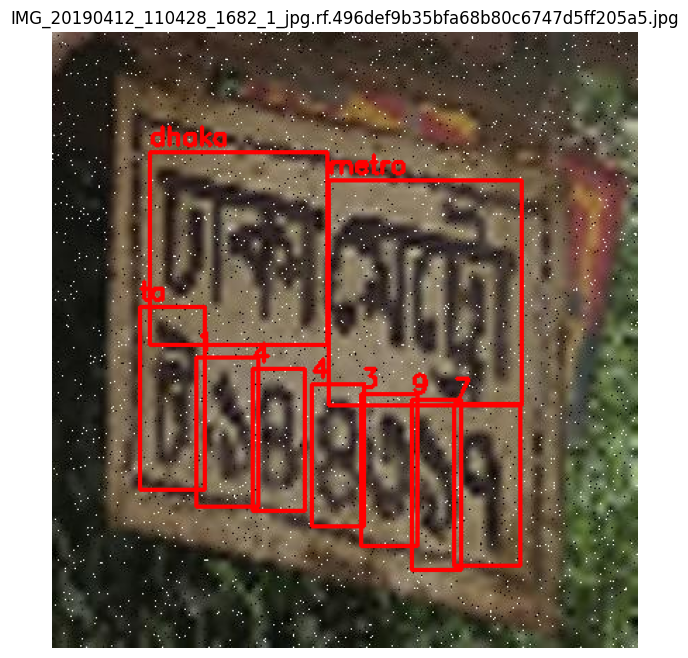

In [14]:
import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
import glob
import os
import random

# Pick a random XML
xml_file = random.choice(
    glob.glob(os.path.join(CHAR_ROOT, "train", "*.xml"))
)

# Corresponding image
image_file = os.path.splitext(xml_file)[0] + ".jpg"

print("XML:", os.path.basename(xml_file))
print("Image:", os.path.basename(image_file))

# Read image
image = cv2.imread(image_file)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Read XML
tree = ET.parse(xml_file)
root = tree.getroot()

for obj in root.findall("object"):

    name = obj.find("name").text.strip()

    bbox = obj.find("bndbox")

    xmin = int(float(bbox.find("xmin").text))
    ymin = int(float(bbox.find("ymin").text))
    xmax = int(float(bbox.find("xmax").text))
    ymax = int(float(bbox.find("ymax").text))

    cv2.rectangle(
        image,
        (xmin, ymin),
        (xmax, ymax),
        (255, 0, 0),
        2
    )

    cv2.putText(
        image,
        name,
        (xmin, max(ymin - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(16, 8))
plt.imshow(image)
plt.axis("off")
plt.title(os.path.basename(image_file))
plt.show()

In [15]:
# ============================================================
# STEP 7.1 - Define dataset and YOLO classes
# ============================================================

import os
import glob
import shutil
import xml.etree.ElementTree as ET

ROOT = "/kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset"

CHAR_ROOT = os.path.join(ROOT, "Character Recognition")

OUT_ROOT = "/kaggle/working/bd_lpr_yolo"

# IMPORTANT:
# Keep this order fixed throughout the entire project.
CLASS_NAMES = [
    "0",
    "1",
    "2",
    "3",
    "4",
    "5",
    "6",
    "7",
    "8",
    "9",
    "ka",
    "kha",
    "ga",
    "gha",
    "ca",
    "ja",
    "ta",
    "da",
    "na",
    "ba",
    "va",
    "ha",
    "metro",
    "dhaka",
    "khulna",
    "chattogram",
    "jashore"
]

CLASS_TO_ID = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

print("Number of classes:", len(CLASS_NAMES))
print()

for i, name in enumerate(CLASS_NAMES):
    print(f"{i:2d} -> {name}")

Number of classes: 27

 0 -> 0
 1 -> 1
 2 -> 2
 3 -> 3
 4 -> 4
 5 -> 5
 6 -> 6
 7 -> 7
 8 -> 8
 9 -> 9
10 -> ka
11 -> kha
12 -> ga
13 -> gha
14 -> ca
15 -> ja
16 -> ta
17 -> da
18 -> na
19 -> ba
20 -> va
21 -> ha
22 -> metro
23 -> dhaka
24 -> khulna
25 -> chattogram
26 -> jashore


In [16]:
# ============================================================
# STEP 7.2 - Create output directories
# ============================================================

for split in ["train", "validation", "test"]:
    
    os.makedirs(
        os.path.join(OUT_ROOT, split, "images"),
        exist_ok=True
    )
    
    os.makedirs(
        os.path.join(OUT_ROOT, split, "labels"),
        exist_ok=True
    )

print("YOLO folder structure created:")
print(OUT_ROOT)

YOLO folder structure created:
/kaggle/working/bd_lpr_yolo


In [17]:
# ============================================================
# STEP 7.3 - Pascal VOC XML -> YOLO format
# ============================================================

def xml_to_yolo(xml_path, image_width, image_height):
    """
    Convert Pascal VOC XML annotations to YOLO format.

    YOLO format:
    class_id center_x center_y width height

    All coordinates are normalized to 0-1.
    """

    tree = ET.parse(xml_path)
    root = tree.getroot()

    yolo_lines = []

    for obj in root.findall("object"):

        name_element = obj.find("name")

        if name_element is None:
            continue

        class_name = name_element.text.strip()

        # Skip unknown classes
        if class_name not in CLASS_TO_ID:
            print(
                f"WARNING: Unknown class '{class_name}' "
                f"in {os.path.basename(xml_path)}"
            )
            continue

        class_id = CLASS_TO_ID[class_name]

        bbox = obj.find("bndbox")

        xmin = float(bbox.find("xmin").text)
        ymin = float(bbox.find("ymin").text)
        xmax = float(bbox.find("xmax").text)
        ymax = float(bbox.find("ymax").text)

        # Prevent invalid coordinates
        xmin = max(0, min(xmin, image_width))
        xmax = max(0, min(xmax, image_width))
        ymin = max(0, min(ymin, image_height))
        ymax = max(0, min(ymax, image_height))

        # Skip invalid boxes
        if xmax <= xmin or ymax <= ymin:
            continue

        # Convert to YOLO
        box_width = xmax - xmin
        box_height = ymax - ymin

        center_x = xmin + box_width / 2
        center_y = ymin + box_height / 2

        # Normalize
        center_x /= image_width
        center_y /= image_height
        box_width /= image_width
        box_height /= image_height

        yolo_lines.append(
            f"{class_id} "
            f"{center_x:.6f} "
            f"{center_y:.6f} "
            f"{box_width:.6f} "
            f"{box_height:.6f}"
        )

    return yolo_lines

In [18]:
# ============================================================
# STEP 7.4 - Convert train / validation / test
# ============================================================

from PIL import Image

total_images = 0
total_annotations = 0

for split in ["train", "validation", "test"]:

    source_dir = os.path.join(CHAR_ROOT, split)

    image_files = glob.glob(
        os.path.join(source_dir, "*.jpg")
    )

    print(f"\nProcessing {split}: {len(image_files)} images")

    split_annotations = 0

    for image_path in image_files:

        filename = os.path.basename(image_path)
        stem = os.path.splitext(filename)[0]

        xml_path = os.path.join(
            source_dir,
            stem + ".xml"
        )

        # Check XML
        if not os.path.exists(xml_path):
            print("Missing XML:", filename)
            continue

        # Read image dimensions
        with Image.open(image_path) as img:
            width, height = img.size

        # Convert XML
        yolo_lines = xml_to_yolo(
            xml_path,
            width,
            height
        )

        # Output paths
        output_image = os.path.join(
            OUT_ROOT,
            split,
            "images",
            filename
        )

        output_label = os.path.join(
            OUT_ROOT,
            split,
            "labels",
            stem + ".txt"
        )

        # Copy image
        shutil.copy2(
            image_path,
            output_image
        )

        # Save YOLO label
        with open(output_label, "w") as f:
            f.write("\n".join(yolo_lines))

        total_images += 1
        total_annotations += len(yolo_lines)
        split_annotations += len(yolo_lines)

    print(
        f"{split}: "
        f"{len(image_files)} images processed, "
        f"{split_annotations} annotations"
    )

print("\n================================")
print("CONVERSION COMPLETE")
print("================================")
print("Total images:", total_images)
print("Total annotations:", total_annotations)


Processing train: 3480 images
train: 3480 images processed, 30604 annotations

Processing validation: 363 images
validation: 363 images processed, 3180 annotations

Processing test: 218 images
test: 218 images processed, 1921 annotations

CONVERSION COMPLETE
Total images: 4061
Total annotations: 35705


In [19]:
# ============================================================
# STEP 7.5 - Create YOLO data.yaml
# ============================================================

yaml_path = os.path.join(
    OUT_ROOT,
    "data.yaml"
)

with open(yaml_path, "w", encoding="utf-8") as f:

    f.write(f"path: {OUT_ROOT}\n")
    f.write("train: train/images\n")
    f.write("val: validation/images\n")
    f.write("test: test/images\n\n")

    f.write(f"nc: {len(CLASS_NAMES)}\n")

    f.write("names:\n")

    for i, name in enumerate(CLASS_NAMES):
        f.write(f"  {i}: '{name}'\n")

print("Created:")
print(yaml_path)

print("\nContents:\n")

with open(yaml_path, "r", encoding="utf-8") as f:
    print(f.read())

Created:
/kaggle/working/bd_lpr_yolo/data.yaml

Contents:

path: /kaggle/working/bd_lpr_yolo
train: train/images
val: validation/images
test: test/images

nc: 27
names:
  0: '0'
  1: '1'
  2: '2'
  3: '3'
  4: '4'
  5: '5'
  6: '6'
  7: '7'
  8: '8'
  9: '9'
  10: 'ka'
  11: 'kha'
  12: 'ga'
  13: 'gha'
  14: 'ca'
  15: 'ja'
  16: 'ta'
  17: 'da'
  18: 'na'
  19: 'ba'
  20: 'va'
  21: 'ha'
  22: 'metro'
  23: 'dhaka'
  24: 'khulna'
  25: 'chattogram'
  26: 'jashore'



In [20]:
# ============================================================
# STEP 7.6 - Inspect one converted label
# ============================================================

label_files = glob.glob(
    os.path.join(
        OUT_ROOT,
        "train",
        "labels",
        "*.txt"
    )
)

sample_label = label_files[0]

print("Label file:")
print(sample_label)
print()

with open(sample_label, "r") as f:
    content = f.read()

print(content)

Label file:
/kaggle/working/bd_lpr_yolo/train/labels/car-6166_192_1_jpg.rf.635aacaa8291fa874bd4e58c9d253e44.txt

23 0.250000 0.401515 0.278846 0.297980
22 0.567308 0.411616 0.331731 0.378788
12 0.840144 0.411616 0.127404 0.308081
2 0.161058 0.722222 0.129808 0.393939
3 0.283654 0.734848 0.129808 0.388889
3 0.610577 0.760101 0.129808 0.388889
3 0.735577 0.775253 0.129808 0.388889
8 0.481971 0.770202 0.132212 0.398990
1 0.861779 0.782828 0.122596 0.363636


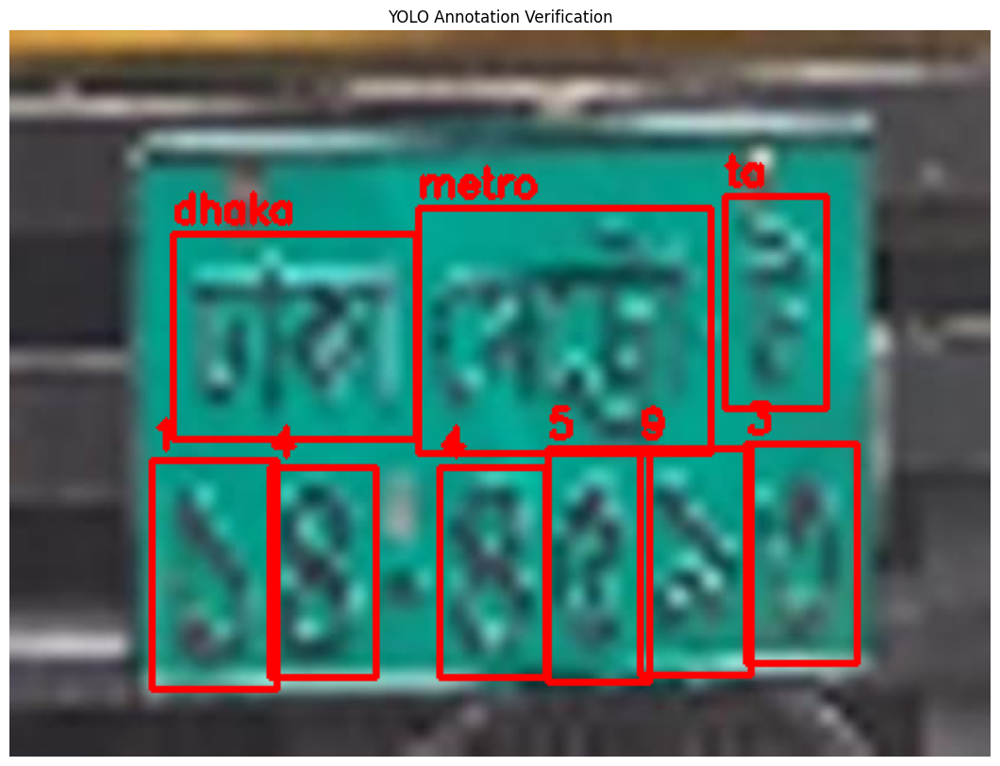

Image: IMG_20190412_110920_627_1_jpg.rf.861fb44e6e0c3ba6cf8658092885995f.jpg


In [21]:
# ============================================================
# STEP 7.7 - Visual verification of YOLO annotations
# ============================================================

import cv2
import matplotlib.pyplot as plt
import random

image_files = glob.glob(
    os.path.join(
        OUT_ROOT,
        "train",
        "images",
        "*.jpg"
    )
)

image_path = random.choice(image_files)

stem = os.path.splitext(
    os.path.basename(image_path)
)[0]

label_path = os.path.join(
    OUT_ROOT,
    "train",
    "labels",
    stem + ".txt"
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

with open(label_path, "r") as f:
    lines = f.readlines()

for line in lines:

    parts = line.strip().split()

    class_id = int(parts[0])

    cx = float(parts[1]) * width
    cy = float(parts[2]) * height
    bw = float(parts[3]) * width
    bh = float(parts[4]) * height

    xmin = int(cx - bw / 2)
    ymin = int(cy - bh / 2)
    xmax = int(cx + bw / 2)
    ymax = int(cy + bh / 2)

    class_name = CLASS_NAMES[class_id]

    cv2.rectangle(
        image,
        (xmin, ymin),
        (xmax, ymax),
        (255, 0, 0),
        2
    )

    cv2.putText(
        image,
        class_name,
        (xmin, max(ymin - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(14, 10))
plt.imshow(image)
plt.axis("off")
plt.title("YOLO Annotation Verification")
plt.show()

print("Image:", os.path.basename(image_path))

In [24]:
# ============================================================
# STEP 8.1 - Create synthetic faded dataset
# ============================================================

import os
import shutil
import glob
import random
import cv2
import numpy as np
from PIL import Image

FADED_ROOT = "/kaggle/working/bd_lpr_faded"

for split in ["train", "validation", "test"]:
    os.makedirs(
        os.path.join(FADED_ROOT, split, "images"),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(FADED_ROOT, split, "labels"),
        exist_ok=True
    )

print("Created:")
print(FADED_ROOT)

Created:
/kaggle/working/bd_lpr_faded


In [43]:
# ============================================================
# STEP 8.2C - Create the fading module WITHOUT %%writefile
# ============================================================

module_code = r'''
import random
import numpy as np
import cv2

from PIL import Image, ImageFilter, ImageEnhance, ImageDraw
import albumentations as A


FADE_MIN = 0.80
FADE_MAX = 0.97

MODE = "light"

RUST = 0.12
NOISE = 4.0
BLUR = 1.0

rng = np.random.default_rng()


def ink_mask(img_rgb, mode="light"):

    gray = cv2.cvtColor(
        img_rgb,
        cv2.COLOR_RGB2GRAY
    )

    if mode == "light":

        t, _ = cv2.threshold(
            gray,
            0,
            255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        t = min(max(t, 40), 150)

        mask = (
            gray < t
        ).astype(np.uint8)

    else:

        t, _ = cv2.threshold(
            gray,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        t = min(max(t, 105), 215)

        mask = (
            gray > t
        ).astype(np.uint8)

    k = np.ones(
        (3, 3),
        np.uint8
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        k,
        iterations=1
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        k,
        iterations=1
    )

    return mask.astype(bool)


def per_character_fade(
    mask,
    rng,
    fmin,
    fmax
):

    n, labels = cv2.connectedComponents(
        mask.astype(np.uint8),
        connectivity=8
    )

    fade = np.zeros(
        mask.shape,
        np.float32
    )

    for i in range(1, n):

        region = (
            labels == i
        )

        if region.sum() < 30:

            fade[region] = rng.uniform(
                fmin,
                1.0
            )

        else:

            fade[region] = rng.uniform(
                fmin,
                fmax
            )

    return fade


def spatial_field(
    shape,
    rng,
    blur=9
):

    f = rng.uniform(
        0.75,
        1.0,
        shape
    ).astype(np.float32)

    return cv2.GaussianBlur(
        f,
        (blur, blur),
        0
    )


def add_rust(
    arr,
    rng,
    strength=0.12
):

    h, w = arr.shape[:2]

    g = max(h // 16, 1)
    gg = max(w // 16, 1)

    noise = rng.uniform(
        0,
        1,
        (g, gg)
    ).astype(np.float32)

    noise = cv2.resize(
        noise,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    noise = cv2.GaussianBlur(
        noise,
        (31, 31),
        0
    )

    yy, xx = np.mgrid[
        0:h,
        0:w
    ]

    edge = 1 - np.minimum(
        np.minimum(
            yy,
            h - yy
        ) / (h * 0.5),

        np.minimum(
            xx,
            w - xx
        ) / (w * 0.5)
    )

    gate = (
        rng.uniform(
            0,
            1,
            (
                max(h // 32, 1),
                max(w // 32, 1)
            )
        ) > 0.7
    ).astype(np.float32)

    gate = cv2.resize(
        gate,
        (w, h),
        interpolation=cv2.INTER_LINEAR
    )

    blotches = (
        noise >
        np.quantile(
            noise,
            1 - strength
        )
    ).astype(np.float32)

    blotches *= gate

    blotches = cv2.GaussianBlur(
        blotches,
        (25, 25),
        0
    )

    alpha = (
        blotches *
        (
            0.15 +
            0.85 * edge**1.5
        )
    )[..., None] * 0.8

    return (
        arr * (1 - alpha)
        +
        np.array(
            [155, 100, 65],
            np.float32
        ) * alpha
    )


def add_scratches(
    img,
    rng,
    n_max=6
):

    img = img.copy()

    draw = ImageDraw.Draw(
        img,
        "RGBA"
    )

    w, h = img.size

    for _ in range(
        rng.integers(
            0,
            n_max
        )
    ):

        x0 = rng.integers(0, w)
        y0 = rng.integers(0, h)

        ang = rng.uniform(
            0,
            np.pi
        )

        ln = rng.uniform(
            0.2,
            0.8
        ) * w

        x1 = (
            x0 +
            ln * np.cos(ang)
        )

        y1 = (
            y0 +
            ln * np.sin(ang)
        )

        shade = int(
            rng.integers(
                120,
                200
            )
        )

        alpha = int(
            rng.integers(
                30,
                90
            )
        )

        draw.line(
            [
                (x0, y0),
                (x1, y1)
            ],
            fill=(
                shade,
                shade,
                shade,
                alpha
            ),
            width=int(
                rng.integers(
                    1,
                    3
                )
            )
        )

    return img


def fade_once(
    img_rgb,
    rng=rng
):

    arr = img_rgb.astype(
        np.float32
    )

    mask = ink_mask(
        img_rgb,
        MODE
    )

    if MODE == "light":

        bg_px = arr[
            ~mask &
            (arr.mean(2) > 120)
        ]

        if len(bg_px):

            bg = np.median(
                bg_px,
                axis=0
            )

        else:

            bg = np.array(
                [200, 200, 198],
                np.float32
            )

    else:

        bg_px = arr[
            ~mask &
            (arr.mean(2) < 100)
        ]

        if len(bg_px):

            bg = np.median(
                bg_px,
                axis=0
            )

        else:

            bg = np.array(
                [30, 30, 30],
                np.float32
            )

    fade = per_character_fade(
        mask,
        rng,
        FADE_MIN,
        FADE_MAX
    )

    alpha = (
        mask.astype(np.float32)
        *
        fade
        *
        spatial_field(
            mask.shape,
            rng
        )
    )[..., None]

    out = (
        arr * (1 - alpha)
        +
        bg * alpha
    )

    out = add_rust(
        out,
        rng,
        strength=RUST
    )

    out = np.clip(
        out +
        rng.normal(
            0,
            NOISE,
            out.shape
        ),
        0,
        255
    ).astype(np.uint8)

    pil = Image.fromarray(
        out
    )

    pil = add_scratches(
        pil,
        rng
    )

    if BLUR > 0:

        pil = pil.filter(
            ImageFilter.GaussianBlur(
                rng.uniform(
                    0,
                    BLUR
                )
            )
        )

    pil = ImageEnhance.Brightness(
        pil
    ).enhance(
        rng.uniform(
            0.85,
            1.15
        )
    )

    pil = ImageEnhance.Contrast(
        pil
    ).enhance(
        rng.uniform(
            0.8,
            1.1
        )
    )

    return np.asarray(pil)


class BanglaPlateFade(
    A.ImageOnlyTransform
):

    def __init__(
        self,
        p=0.60
    ):

        super().__init__(
            p=p
        )

    def apply(
        self,
        img,
        **params
    ):

        return fade_once(img)
'''

module_path = "/kaggle/working/bd_plate_fade.py"

with open(module_path, "w", encoding="utf-8") as f:
    f.write(module_code)

print("Module created successfully:")
print(module_path)

Module created successfully:
/kaggle/working/bd_plate_fade.py


In [44]:
# ============================================================
# STEP 8.3C - Import fading module
# ============================================================

import sys

if "/kaggle/working" not in sys.path:
    sys.path.insert(0, "/kaggle/working")

from bd_plate_fade import fade_once, BanglaPlateFade

print("Fading module imported successfully.")
print("fade_once:", fade_once)
print("BanglaPlateFade:", BanglaPlateFade)

Fading module imported successfully.
fade_once: <function fade_once at 0x7f5d2096a660>
BanglaPlateFade: <class 'bd_plate_fade.BanglaPlateFade'>


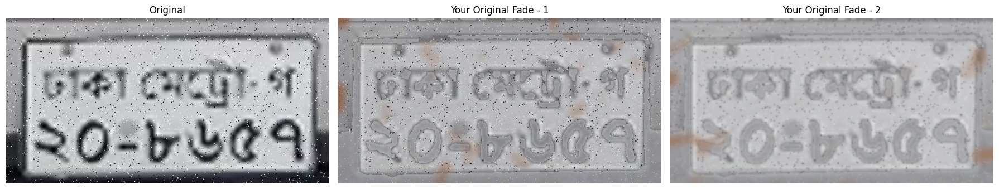

Image: car-6043_277_1_jpg.rf.9fb70701633f0f89459e33e39811dc43.jpg


In [48]:
# ============================================================
# STEP 8.4C - Preview YOUR original fading
# ============================================================

import glob
import os
import random
import cv2
import matplotlib.pyplot as plt

sample_images = glob.glob(
    "/kaggle/working/bd_lpr_yolo/train/images/*.jpg"
)

sample_path = random.choice(sample_images)

img = cv2.imread(sample_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

faded1 = fade_once(img.copy())
faded2 = fade_once(img.copy())

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(img)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(faded1)
axes[1].set_title("Your Original Fade - 1")
axes[1].axis("off")

axes[2].imshow(faded2)
axes[2].set_title("Your Original Fade - 2")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Image:", os.path.basename(sample_path))

In [49]:
# ============================================================
# STEP 8.5C - Test Ultralytics serialization
# ============================================================

import albumentations as A

fade_transform = BanglaPlateFade(p=0.60)

try:

    config = A.to_dict(fade_transform)

    print("A.to_dict() SUCCESS")

    reconstructed = A.from_dict(config)

    print("A.from_dict() SUCCESS")
    print("\nEverything is ready for YOLO training.")

except Exception as e:

    print("SERIALIZATION FAILED")
    print(type(e).__name__, ":", e)

A.to_dict() SUCCESS
A.from_dict() SUCCESS

Everything is ready for YOLO training.


In [52]:
# ============================================================
# STEP 8.6 - Fix read-only NumPy output
# ============================================================

module_path = "/kaggle/working/bd_plate_fade.py"

with open(module_path, "r", encoding="utf-8") as f:
    code = f.read()

old = "return np.asarray(pil)"

new = """return np.ascontiguousarray(
        np.asarray(pil, dtype=np.uint8)
    ).copy()"""

if old not in code:
    print("Original return statement was not found.")
else:
    code = code.replace(old, new)

    with open(module_path, "w", encoding="utf-8") as f:
        f.write(code)

    print("Module patched successfully.")

Module patched successfully.


In [53]:
# ============================================================
# STEP 8.7 - Reload patched module
# ============================================================

import sys
import importlib

if "/kaggle/working" not in sys.path:
    sys.path.insert(0, "/kaggle/working")

import bd_plate_fade

importlib.reload(bd_plate_fade)

from bd_plate_fade import (
    fade_once,
    BanglaPlateFade
)

print("Patched module reloaded.")

Patched module reloaded.


In [54]:
# ============================================================
# STEP 8.8 - Verify writable output
# ============================================================

faded_test = fade_once(
    img.copy()
)

print("Shape:", faded_test.shape)
print("Dtype:", faded_test.dtype)
print("C-contiguous:", faded_test.flags["C_CONTIGUOUS"])
print("Writable:", faded_test.flags["WRITEABLE"])

Shape: (213, 416, 3)
Dtype: uint8
C-contiguous: True
Writable: True


In [55]:
# ============================================================
# STEP 8.9 - Test transform output
# ============================================================

fade_transform = BanglaPlateFade(
    p=1.0
)

result = fade_transform(
    image=img.copy()
)

augmented = result["image"]

print("Shape:", augmented.shape)
print("Dtype:", augmented.dtype)
print("C-contiguous:", augmented.flags["C_CONTIGUOUS"])
print("Writable:", augmented.flags["WRITEABLE"])

Shape: (213, 416, 3)
Dtype: uint8
C-contiguous: True
Writable: True


In [56]:
# ============================================================
# STEP 8.10 - Serialization check
# ============================================================

import albumentations as A

fade_transform = BanglaPlateFade(
    p=0.60
)

try:

    config = A.to_dict(fade_transform)

    print("A.to_dict() SUCCESS")

    reconstructed = A.from_dict(config)

    print("A.from_dict() SUCCESS")

except Exception as e:

    print("FAILED:")
    print(type(e).__name__, ":", e)

A.to_dict() SUCCESS
A.from_dict() SUCCESS


In [57]:
# ============================================================
# STEP 8.11 - Retry 2-epoch pipeline test
# ============================================================

from ultralytics import YOLO

DATA_YAML = "/kaggle/working/bd_lpr_yolo/data.yaml"

model = YOLO(
    "/kaggle/working/yolov8n.pt"
)

fade_transform = BanglaPlateFade(
    p=0.60
)

print("Starting corrected 2-epoch test...")

Starting corrected 2-epoch test...


In [58]:
test_results = model.train(

    data=DATA_YAML,

    epochs=2,

    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    project="/kaggle/working/lpr_training",
    name="pipeline_test_fading_v2",

    seed=42,

    augmentations=[
        fade_transform
    ],

    mosaic=0.5,
    mixup=0.0,

    degrees=2.0,
    translate=0.05,
    scale=0.30,

    hsv_h=0.015,
    hsv_s=0.30,
    hsv_v=0.20,

    fliplr=0.0,

    save=True,
    plots=True
)

print("2-epoch test completed.")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'bd_plate_fade.BanglaPlateFade', 'p': 0.6}}], auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bd_lpr_yolo/data.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


        2/2      2.94G       0.91     0.7922      1.049         71        640: 100% ━━━━━━━━━━━━ 218/218 1.3it/s 2:500.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 6.1it/s 2.0s0.2s
                   all        363       3180      0.848      0.654      0.733       0.55

2 epochs completed in 0.098 hours.
Optimizer stripped from /kaggle/working/lpr_training/pipeline_test_fading_v2/weights/last.pt, 6.3MB
Optimizer stripped from /kaggle/working/lpr_training/pipeline_test_fading_v2/weights/best.pt, 6.3MB

Validating /kaggle/working/lpr_training/pipeline_test_fading_v2/weights/best.pt...
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.8it/s 4.2s0.3s
                   all        363       31

In [59]:
# ============================================================
# STEP 9 - FULL TRAINING
# YOLOv8n + YOUR ORIGINAL SYNTHETIC FADING
# ============================================================

from ultralytics import YOLO

DATA_YAML = "/kaggle/working/bd_lpr_yolo/data.yaml"

# Start from the original pretrained model
model_faded = YOLO(
    "/kaggle/working/yolov8n.pt"
)

# Your original fading transform
fade_transform = BanglaPlateFade(
    p=0.60
)

print("Starting full training...")
print("Model: YOLOv8n")
print("Augmentation: Original synthetic fading")

Starting full training...
Model: YOLOv8n
Augmentation: Original synthetic fading


In [60]:
# ============================================================
# STEP 9.1 - Train Model B
# ============================================================

results_faded = model_faded.train(

    data=DATA_YAML,

    # Main training
    epochs=50,
    imgsz=640,
    batch=16,

    # GPU
    device=0,
    workers=2,

    # Output
    project="/kaggle/working/lpr_training",
    name="model_B_synthetic_fading",

    # Reproducibility
    seed=42,

    # ========================================================
    # YOUR ORIGINAL FADING
    # ========================================================
    augmentations=[
        fade_transform
    ],

    # ========================================================
    # Other YOLO augmentation
    # ========================================================

    mosaic=0.5,
    mixup=0.0,

    degrees=2.0,
    translate=0.05,
    scale=0.30,

    hsv_h=0.015,
    hsv_s=0.30,
    hsv_v=0.20,

    # Do not horizontally flip Bengali license plates
    fliplr=0.0,

    # Save
    save=True,
    plots=True
)

print("========================================")
print("MODEL B TRAINING COMPLETE")
print("========================================")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'bd_plate_fade.BanglaPlateFade', 'p': 0.6}}], auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bd_lpr_yolo/data.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

In [62]:
# ============================================================
# STEP 10 - Verify validation dataset
# ============================================================

import glob
import os

val_images = glob.glob(
    "/kaggle/working/bd_lpr_yolo/validation/images/*.jpg"
)

val_labels = glob.glob(
    "/kaggle/working/bd_lpr_yolo/validation/labels/*.txt"
)

print("Validation images:", len(val_images))
print("Validation labels:", len(val_labels))

# Labels that actually contain at least one object
nonempty_labels = 0

for label in val_labels:
    if os.path.getsize(label) > 0:
        nonempty_labels += 1

print("Non-empty labels:", nonempty_labels)

Validation images: 363
Validation labels: 363
Non-empty labels: 363


In [63]:
# ============================================================
# STEP 10.1 - MODEL A BASELINE
# YOLOv8n WITHOUT synthetic fading
# ============================================================

from ultralytics import YOLO

DATA_YAML = "/kaggle/working/bd_lpr_yolo/data.yaml"

# Start from the SAME original pretrained model
model_baseline = YOLO(
    "/kaggle/working/yolov8n.pt"
)

print("Starting Model A baseline training...")

Starting Model A baseline training...


In [64]:
# ============================================================
# STEP 10.2 - Train Model A
# ============================================================

results_baseline = model_baseline.train(

    data=DATA_YAML,

    epochs=50,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    project="/kaggle/working/lpr_training",
    name="model_A_baseline",

    seed=42,

    # --------------------------------------------------------
    # NO CUSTOM FADING
    # --------------------------------------------------------
    augmentations=[],

    # Same settings as Model B
    mosaic=0.5,
    mixup=0.0,

    degrees=2.0,
    translate=0.05,
    scale=0.30,

    hsv_h=0.015,
    hsv_s=0.30,
    hsv_v=0.20,

    fliplr=0.0,

    save=True,
    plots=True
)

print("========================================")
print("MODEL A TRAINING COMPLETE")
print("========================================")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bd_lpr_yolo/data.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/yolov8n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=model_A_baseline,

In [65]:
# ============================================================
# STEP 10.3 - Confirm both models
# ============================================================

import os

model_A_path = (
    "/kaggle/working/lpr_training/"
    "model_A_baseline/weights/best.pt"
)

model_B_path = (
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

print("Model A exists:", os.path.exists(model_A_path))
print("Model B exists:", os.path.exists(model_B_path))

print("\nModel A:")
print(model_A_path)

print("\nModel B:")
print(model_B_path)

Model A exists: True
Model B exists: True

Model A:
/kaggle/working/lpr_training/model_A_baseline/weights/best.pt

Model B:
/kaggle/working/lpr_training/model_B_synthetic_fading/weights/best.pt


In [66]:
# ============================================================
# STEP 11.1 - Find real faded dataset
# ============================================================

import os
import glob

print("Searching /kaggle/input for image folders...\n")

candidates = []

for root, dirs, files in os.walk("/kaggle/input/datasets/mdarifulhasan37/cropped-dataset"):

    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if len(image_files) > 0:
        candidates.append(
            (root, len(image_files))
        )

for path, count in candidates:

    print(
        f"{count:5d} images  ->  {path}"
    )

Searching /kaggle/input for image folders...

   67 images  ->  /kaggle/input/datasets/mdarifulhasan37/cropped-dataset


In [67]:
# ============================================================
# STEP 11.2 - Set REAL faded dataset path
# ============================================================

REAL_FADED_ROOT = "/kaggle/input/datasets/mdarifulhasan37/cropped-dataset"

real_images = []

for ext in ("*.jpg", "*.jpeg", "*.png"):
    real_images.extend(
        glob.glob(
            os.path.join(
                REAL_FADED_ROOT,
                "**",
                ext
            ),
            recursive=True
        )
    )

real_images = sorted(real_images)

print("Real faded images found:", len(real_images))

for p in real_images[:10]:
    print(os.path.basename(p))

Real faded images found: 67
plate_0001.jpg
plate_0002.jpg
plate_0003.jpg
plate_0004.jpg
plate_0005.jpg
plate_0006.jpg
plate_0007.jpg
plate_0008.jpg
plate_0009.jpg
plate_0010.jpg


In [68]:
# ============================================================
# STEP 11.3 - Check annotation files
# ============================================================

import os

xml_count = 0
txt_count = 0

for image_path in real_images:

    stem = os.path.splitext(image_path)[0]

    if os.path.exists(stem + ".xml"):
        xml_count += 1

    if os.path.exists(stem + ".txt"):
        txt_count += 1

print("Images:", len(real_images))
print("XML annotations:", xml_count)
print("YOLO TXT annotations:", txt_count)

Images: 67
XML annotations: 0
YOLO TXT annotations: 0


In [69]:
# ============================================================
# STEP 11.4 - Load both trained models
# ============================================================

from ultralytics import YOLO
import os
import glob

model_A_path = (
    "/kaggle/working/lpr_training/"
    "model_A_baseline/weights/best.pt"
)

model_B_path = (
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

model_A = YOLO(model_A_path)
model_B = YOLO(model_B_path)

print("Model A loaded:", os.path.exists(model_A_path))
print("Model B loaded:", os.path.exists(model_B_path))

Model A loaded: True
Model B loaded: True


In [71]:
# ============================================================
# STEP 11.5 - Get the 67 real faded images
# ============================================================

# IMPORTANT:
# Replace this with your actual path from Step 11.1

REAL_FADED_ROOT = "/kaggle/input/datasets/mdarifulhasan37/cropped-dataset"

real_images = []

for ext in ("*.jpg", "*.jpeg", "*.png"):
    real_images.extend(
        glob.glob(
            os.path.join(
                REAL_FADED_ROOT,
                "**",
                ext
            ),
            recursive=True
        )
    )

real_images = sorted(real_images)

print("Real faded images:", len(real_images))

assert len(real_images) == 67, (
    f"Expected 67 images but found {len(real_images)}"
)

Real faded images: 67


In [72]:
# ============================================================
# STEP 11.6 - Generate Model B predictions
# ============================================================

PRED_ROOT = "/kaggle/working/real_faded_predictions"

os.makedirs(PRED_ROOT, exist_ok=True)

model_B.predict(
    source=real_images,
    conf=0.25,
    imgsz=640,
    device=0,
    save=True,
    save_txt=True,
    save_conf=True,
    project=PRED_ROOT,
    name="model_B_predictions",
    exist_ok=True
)

print("Model B predictions saved.")


0: 640x640 2 1s, 1 2, 1 3, 1 6, 1 8, 1 ga, 1 metro, 1 khulna, 3.4ms
1: 640x640 2 2s, 1 3, 1 metro, 1 dhaka, 3.4ms
2: 640x640 1 0, 1 2, 1 3, 1 5, 1 8, 1 9, 1 ja, 1 metro, 1 dhaka, 3.4ms
3: 640x640 1 1, 2 3s, 1 6, 1 7, 1 8, 1 ga, 1 metro, 1 dhaka, 3.4ms
4: 640x640 1 1, 1 3, 1 4, 1 5, 1 8, 1 ba, 1 metro, 1 dhaka, 3.4ms
5: 640x640 3 0s, 1 1, 1 2, 1 3, 1 metro, 1 dhaka, 3.4ms
6: 640x640 3 1s, 2 3s, 1 5, 1 ta, 1 metro, 3.4ms
7: 640x640 1 0, 1 1, 1 3, 1 4, 1 8, 1 9, 1 ba, 1 metro, 1 dhaka, 3.4ms
8: 640x640 3 1s, 2 2s, 1 4, 1 metro, 1 dhaka, 3.4ms
9: 640x640 1 0, 3 1s, 1 6, 1 8, 1 ga, 1 metro, 1 dhaka, 3.4ms
10: 640x640 1 0, 1 1, 1 3, 1 4, 1 6, 1 9, 1 ja, 1 metro, 1 dhaka, 3.4ms
11: 640x640 1 1, 1 3, 1 5, 1 7, 2 8s, 2 tas, 1 metro, 1 dhaka, 3.4ms
12: 640x640 1 1, 2 2s, 1 6, 1 8, 1 ga, 1 metro, 1 dhaka, 3.4ms
13: 640x640 2 0s, 4 1s, 1 5, 1 ca, 1 metro, 1 dhaka, 3.4ms
14: 640x640 1 0, 1 1, 1 3, 2 5s, 1 8, 1 ba, 1 metro, 1 dhaka, 3.4ms
15: 640x640 1 1, 2 5s, 2 6s, 1 8, 1 ca, 1 metro, 1 dhaka, 3.

Prediction images: 67


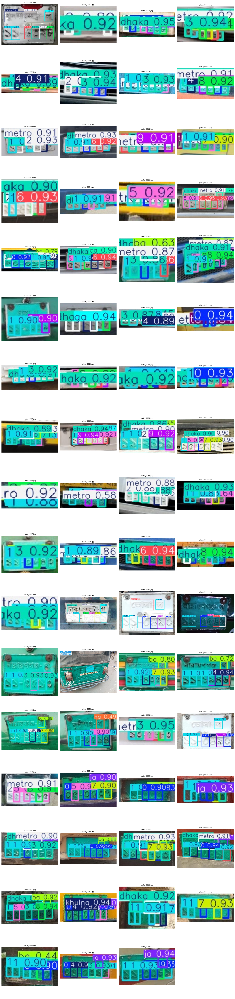

Saved: /kaggle/working/real_faded_ModelB_contact_sheet.jpg


In [73]:
# ============================================================
# STEP 11.7 - Create prediction contact sheet
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import glob
import math

pred_images = sorted(
    glob.glob(
        os.path.join(
            PRED_ROOT,
            "model_B_predictions",
            "*.jpg"
        )
    )
)

print("Prediction images:", len(pred_images))

cols = 4
rows = math.ceil(len(pred_images) / cols)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, rows * 4)
)

axes = np.array(axes).reshape(-1)

for i, path in enumerate(pred_images):

    img = Image.open(path)

    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(
        os.path.basename(path),
        fontsize=8
    )

for i in range(len(pred_images), len(axes)):
    axes[i].axis("off")

plt.tight_layout()

contact_path = (
    "/kaggle/working/"
    "real_faded_ModelB_contact_sheet.jpg"
)

plt.savefig(
    contact_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Saved:", contact_path)

In [74]:
# ============================================================
# STEP 11.8 - Create ground truth for REAL faded plates
# ============================================================

import pandas as pd
import unicodedata
import re

ground_truth = {
    "plate_0001": "খুলনা মেট্রো-ল   ১১-৬৩২৮",
    "plate_0002": "",
    "plate_0003": "ঢাকা মেট্রো-উ ২০-৫৯৩৮",
    "plate_0004": "ঢাকা মেট্রো-গ ৩১-৮৭৬৩",
    "plate_0005": "ঢাকা মেট্রো-ব ১৪-৮৩৫১",
    "plate_0006": "ঢাকা মেট্রো-গ ২০-১৩০০",
    "plate_0007": "ঢাকা মেট্রো-ন ১১-১৩৩৫",
    "plate_0008": "ঢাকা মেট্রো-হ ১৪-৯৮০৩",
    "plate_0009": "ঢাকা মেট্রো-উ ১২-১২০৫",
    "plate_0010": "ঢাকা মেট্রো-শ ১১-০৬৬১",
    "plate_0011": "ঢাকা মেট্রো-ঢ ৬৩-৫১৪৯",
    "plate_0012": "ঢাকা মেট্রো-ট ১৮-৮৫৩৭",
    "plate_0013": "ঢাকা মেট্রো-থ ২১-৪২৮৬",
    "plate_0014": "ঢাকা মেট্রো-ম ১১-০৫১১",
    "plate_0015": "ঢাকা মেট্রো-ম ১৩-০৫৫৮",
    "plate_0016": "ঢাকা মেট্রো-চ ৫১-৬৮৬৫",
    "plate_0017": "ঢাকা মেট্রো-ন ২০-০১২৪",
    "plate_0018": "ঢাকা মেট্রো-চ ৫১-৮৪২৬",
    "plate_0019": "ঢাকা মেট্রো-থ ১৩-৫০১৬",
    "plate_0020": "ঢাকা মেট্রো-ন ১৫-৮৮৪৫",
    "plate_0021": "ঢাকা থ ১১-১১১৯",
    "plate_0022": "ঢাকা মেট্রো-গ ২২-৪২১৮",
    "plate_0023": "ঢাকা মেট্রো-গ ৩১-৩১৩৪",
    "plate_0024": "ঢাকা মেট্রো-ঠ ১৫-০৯০২",
    "plate_0025": "ঢাকা মেট্রো-স ১১-০৩৩৩",
    "plate_0026": "",
    "plate_0027": "ঢাকা মেট্রো-ঝ ১১-০৮০৬",
    "plate_0028": "ঢাকা মেট্রো-স ১১-০৩৬৯",
    "plate_0029": "ঢাকা মেট্রো-ন ১৩-৬৩১৫",
    "plate_0030": "ঢাকা মেট্রো-গ ১৯-৭৫৫৬",
    "plate_0031": "ঢাকা মেট্রো-ন ১১-২৪১৯",
    "plate_0032": "ঢাকা মেট্রো-ঠ ১৫-০৭২২",
    "plate_0033": "ঢাকা মেট্রো-ন ১৪-১৩৩৬",
    "plate_0034": "",
    "plate_0035": "ঢাকা মেট্রো-গ ২৩-৩৪৪২",
    "plate_0036": "ঢাকা মেট্রো-শ ১১-৩৫৩০",
    "plate_0037": "গাজীপুর-খ ১১-০৮৪৩",
    "plate_0038": "ঢাকা মেট্রো-ন ১৬-৭৩২০",
    "plate_0039": "ঢাকা মেট্রো-ন ১৭-৬৯৬৬",
    "plate_0040": "ঢাকা মেট্রো-চ ২০-৮৫৯০",
    "plate_0041": "ঢাকা মেট্রো-চ ১১-১৭১১",
    "plate_0042": "ঢাকা মেট্রো-গ ২১-৮৫৭১",
    "plate_0043": "ভোলা-ল ১১-০৪৯০",
    "plate_0044": "নারায়নগঞ্জ-থ ১১-০৫৬২",
    "plate_0045": "নারায়নগঞ্জ-থ ১১-৩৫১৩",
    "plate_0046": "টাংগাইল-থ ১১-০০৩২",
    "plate_0047": "নারায়নগঞ্জ-থ ১১-৪৩৫৭",
    "plate_0048": "নারায়নগঞ্জ-থ ১১-১৯৪৬",
    "plate_0049": "নারায়নগঞ্জ-থ ১১-২৪৩৭",
    "plate_0050": "মুনীগঞ্জ-থ ১১-০৫১৪",
    "plate_0051": "ঢাকা মেট্রো-চ ১৩-৫৬৮৩",
    "plate_0052": "ভোলা-ল ১১-০৪৯০",
    "plate_0053": "ঢাকা মেট্রো-ল ২৫-৫৯৮৫",
    "plate_0054": "বরিশাল-জ ০৫-০০৩৭",
    "plate_0055": "সাতক্ষীরা-জ ১১-০০০৪",
    "plate_0056": "সাতক্ষীরা-জ ১২-০০৭৩",
    "plate_0057": "ঢাকা মেট্রো-জ ১১-০৩৮৩",
    "plate_0058": "টাংগাইল-ব ১১-০০০১",
    "plate_0059": "ঢাকা মেট্রো-ব ১৪-৬৭০৩",
    "plate_0060": "ঢাকা মেট্রো-জ ১৪-০৪১৬",
    "plate_0061": "ঢাকা মেট্রো-ব ১৫-৩০৮৩",
    "plate_0062": "খুলনা মেট্রো-জ ০৪-০০৫৫",
    "plate_0063": "ঢাকা মেট্রো-ট ১১-৬১২৪",
    "plate_0064": "যশোর-ট ১১-০৮৭০",
    "plate_0065": "যশোর-ট ১১-১৩৮০",
    "plate_0066": "গাজীপুর-জ ০৪-০৩১৫",
    "plate_0067": "শাতক্ষীরা-জ ১১-০০৮১",
}


def normalize_text(text):
    """
    Canonical representation for recognition evaluation.

    - Unicode NFC normalization
    - convert non-standard dash characters to '-'
    - remove all whitespace
    """
    text = unicodedata.normalize("NFC", text)

    # Normalize common dash variants
    text = re.sub(
        r"[\u2010\u2011\u2012\u2013\u2014\u2212]",
        "-",
        text
    )

    # Remove spaces/tabs/newlines
    text = re.sub(r"\s+", "", text)

    return text


rows = []

for i in range(1, 68):

    image_id = f"plate_{i:04d}"
    raw_text = ground_truth[image_id]

    rows.append({
        "image": image_id,
        "ground_truth": raw_text,
        "normalized_ground_truth": normalize_text(raw_text),
        "has_ground_truth": bool(raw_text.strip())
    })


gt_df = pd.DataFrame(rows)

GT_PATH = "/kaggle/working/real_faded_ground_truth.csv"

gt_df.to_csv(
    GT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Ground-truth file created:")
print(GT_PATH)

print("\nTotal images:", len(gt_df))
print(
    "Images with ground truth:",
    gt_df["has_ground_truth"].sum()
)
print(
    "Images without ground truth:",
    (~gt_df["has_ground_truth"]).sum()
)

print("\nMissing:")
print(
    gt_df.loc[
        ~gt_df["has_ground_truth"],
        "image"
    ].tolist()
)

display(gt_df.head(10))

Ground-truth file created:
/kaggle/working/real_faded_ground_truth.csv

Total images: 67
Images with ground truth: 64
Images without ground truth: 3

Missing:
['plate_0002', 'plate_0026', 'plate_0034']


,image,ground_truth,normalized_ground_truth,has_ground_truth
0,plate_0001,খুলনা মেট্রো-ল ১১-৬৩২৮,খুলনামেট্রো-ল১১-৬৩২৮,True
1,plate_0002,,,False
2,plate_0003,ঢাকা মেট্রো-উ ২০-৫৯৩৮,ঢাকামেট্রো-উ২০-৫৯৩৮,True
3,plate_0004,ঢাকা মেট্রো-গ ৩১-৮৭৬৩,ঢাকামেট্রো-গ৩১-৮৭৬৩,True
4,plate_0005,ঢাকা মেট্রো-ব ১৪-৮৩৫১,ঢাকামেট্রো-ব১৪-৮৩৫১,True
5,plate_0006,ঢাকা মেট্রো-গ ২০-১৩০০,ঢাকামেট্রো-গ২০-১৩০০,True
6,plate_0007,ঢাকা মেট্রো-ন ১১-১৩৩৫,ঢাকামেট্রো-ন১১-১৩৩৫,True
7,plate_0008,ঢাকা মেট্রো-হ ১৪-৯৮০৩,ঢাকামেট্রো-হ১৪-৯৮০৩,True
8,plate_0009,ঢাকা মেট্রো-উ ১২-১২০৫,ঢাকামেট্রো-উ১২-১২০৫,True
9,plate_0010,ঢাকা মেট্রো-শ ১১-০৬৬১,ঢাকামেট্রো-শ১১-০৬৬১,True


In [75]:
# ============================================================
# STEP 11.9 - Analyze Bengali character coverage
# ============================================================

from collections import Counter

all_text = "".join(
    gt_df.loc[
        gt_df["has_ground_truth"],
        "normalized_ground_truth"
    ].tolist()
)

char_counter = Counter(
    ch for ch in all_text
    if '\u0980' <= ch <= '\u09FF'
)

print("Unique Bengali Unicode characters:")
print()

for ch, count in sorted(char_counter.items()):
    print(f"{ch} : {count}")

print()
print("Total unique Bengali characters:", len(char_counter))

Unique Bengali Unicode characters:

ং : 2
ই : 2
উ : 2
ক : 47
খ : 3
গ : 17
চ : 5
জ : 16
ঝ : 1
ঞ : 6
ট : 51
ঠ : 2
ঢ : 45
ত : 3
থ : 10
ন : 21
প : 2
ব : 5
ভ : 2
ম : 48
য : 7
র : 58
ল : 11
শ : 6
ষ : 3
স : 4
হ : 1
় : 5
া : 115
ি : 1
ী : 6
ু : 5
ে : 45
ো : 49
্ : 54
০ : 57
১ : 112
২ : 28
৩ : 46
৪ : 27
৫ : 36
৬ : 25
৭ : 14
৮ : 25
৯ : 14

Total unique Bengali characters: 45


In [76]:
# ============================================================
# STEP 11.10 - Display trained model vocabulary
# ============================================================

print("Model classes:")
print()

for i, name in enumerate(CLASS_NAMES):
    print(f"{i:2d} -> {name}")

Model classes:

 0 -> 0
 1 -> 1
 2 -> 2
 3 -> 3
 4 -> 4
 5 -> 5
 6 -> 6
 7 -> 7
 8 -> 8
 9 -> 9
10 -> ka
11 -> kha
12 -> ga
13 -> gha
14 -> ca
15 -> ja
16 -> ta
17 -> da
18 -> na
19 -> ba
20 -> va
21 -> ha
22 -> metro
23 -> dhaka
24 -> khulna
25 -> chattogram
26 -> jashore


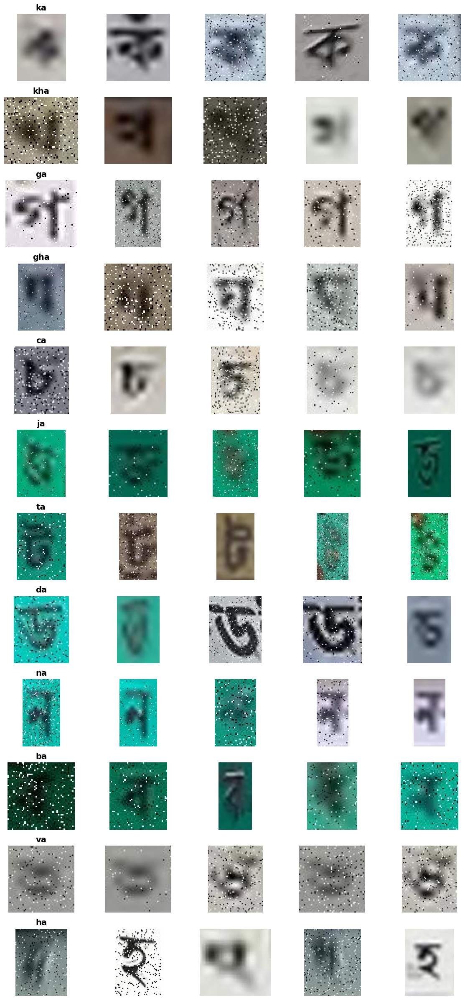

Gallery saved:
/kaggle/working/bengali_class_examples.png


In [77]:
# ============================================================
# STEP 12 - Create visual examples for each training class
# ============================================================

import os
import glob
import random
import cv2
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import numpy as np

CHAR_ROOT = "/kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/Character Recognition"

# ------------------------------------------------------------
# Collect a few examples for each class
# ------------------------------------------------------------

examples = {
    cls: []
    for cls in CLASS_NAMES
}

xml_files = glob.glob(
    os.path.join(
        CHAR_ROOT,
        "train",
        "*.xml"
    )
)

for xml_path in xml_files:

    image_path = os.path.splitext(xml_path)[0] + ".jpg"

    if not os.path.exists(image_path):
        continue

    image = cv2.imread(image_path)

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    h, w = image.shape[:2]

    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        continue

    for obj in root.findall("object"):

        name = obj.find("name").text.strip()

        if name not in examples:
            continue

        bbox = obj.find("bndbox")

        xmin = int(float(bbox.find("xmin").text))
        ymin = int(float(bbox.find("ymin").text))
        xmax = int(float(bbox.find("xmax").text))
        ymax = int(float(bbox.find("ymax").text))

        xmin = max(0, xmin)
        ymin = max(0, ymin)
        xmax = min(w, xmax)
        ymax = min(h, ymax)

        crop = image[ymin:ymax, xmin:xmax]

        if crop.size == 0:
            continue

        if len(examples[name]) < 5:
            examples[name].append(
                (crop, os.path.basename(image_path))
            )

    # Stop once enough examples are collected
    if all(
        len(examples[c]) >= 5
        for c in CLASS_NAMES
        if c in ["ka", "kha", "ga", "gha", "ca", "ja",
                 "ta", "da", "na", "ba", "va", "ha"]
    ):
        break


# ------------------------------------------------------------
# Display Bengali-character classes
# ------------------------------------------------------------

target_classes = [
    "ka", "kha", "ga", "gha",
    "ca", "ja", "ta", "da",
    "na", "ba", "va", "ha"
]

fig, axes = plt.subplots(
    len(target_classes),
    5,
    figsize=(12, 24)
)

for row, cls in enumerate(target_classes):

    for col in range(5):

        ax = axes[row, col]
        ax.axis("off")

        if col < len(examples[cls]):

            crop, filename = examples[cls][col]

            ax.imshow(crop)

            if col == 0:
                ax.set_title(
                    cls,
                    fontsize=14,
                    fontweight="bold"
                )

plt.tight_layout()

gallery_path = (
    "/kaggle/working/"
    "bengali_class_examples.png"
)

plt.savefig(
    gallery_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Gallery saved:")
print(gallery_path)

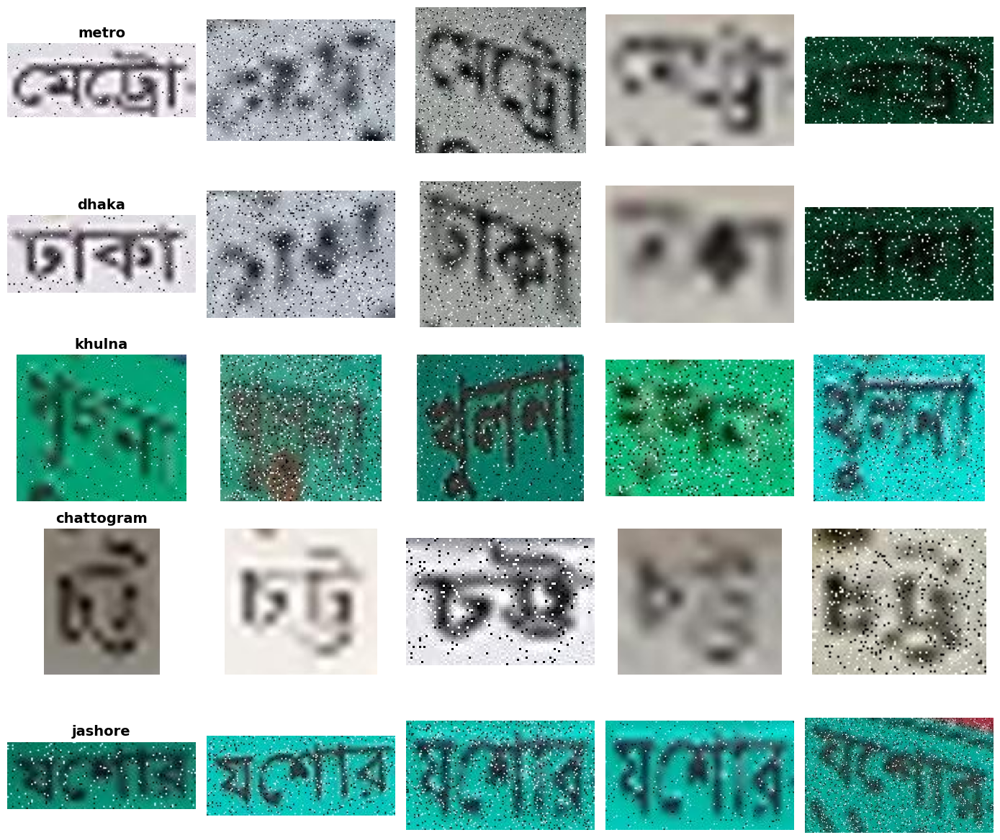

Saved:
/kaggle/working/word_class_examples.png


In [78]:
# ============================================================
# STEP 12.1 - Inspect word classes
# ============================================================

word_classes = [
    "metro",
    "dhaka",
    "khulna",
    "chattogram",
    "jashore"
]

fig, axes = plt.subplots(
    len(word_classes),
    5,
    figsize=(14, 12)
)

for row, cls in enumerate(word_classes):

    for col in range(5):

        ax = axes[row, col]
        ax.axis("off")

        if col < len(examples[cls]):

            crop, filename = examples[cls][col]

            ax.imshow(crop)

            if col == 0:
                ax.set_title(
                    cls,
                    fontsize=14,
                    fontweight="bold"
                )

plt.tight_layout()

word_gallery_path = (
    "/kaggle/working/"
    "word_class_examples.png"
)

plt.savefig(
    word_gallery_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(word_gallery_path)

In [79]:
# ============================================================
# STEP 12.2 - Count how many training instances each
# character class has, again for the Bengali classes
# ============================================================

for cls in [
    "ka", "kha", "ga", "gha",
    "ca", "ja", "ta", "da",
    "na", "ba", "va", "ha"
]:
    print(
        f"{cls:5s} -> {class_counter.get(cls, 0)} instances"
    )

ka    -> 53 instances
kha   -> 187 instances
ga    -> 1860 instances
gha   -> 289 instances
ca    -> 94 instances
ja    -> 317 instances
ta    -> 389 instances
da    -> 57 instances
na    -> 40 instances
ba    -> 354 instances
va    -> 46 instances
ha    -> 112 instances


In [80]:
# ============================================================
# STEP 12.3 - Save Roman ground truth
# ============================================================

import pandas as pd
import re
import unicodedata

roman_gt = """
plate_0001    khulna metro-la 11-6328
plate_0002
plate_0003    dhaka metro-u 20-5938
plate_0004    dhaka metro-ga 31-8763
plate_0005    dhaka metro-ba 14-8351
plate_0006    dhaka metro-ga 20-1300
plate_0007    dhaka metro-na 11-1335
plate_0008    dhaka metro-ha 14-9803
plate_0009    dhaka metro-u 12-1205
plate_0010    dhaka metro-sha 11-0361
plate_0011    dhaka metro-ca 63-5149
plate_0012    dhaka metro-ta 18-8537
plate_0013    dhaka metro-kha 21-4286
plate_0014    dhaka metro-ma 11-0511
plate_0015    dhaka metro-ma 13-0558
plate_0016    dhaka metro-ca 51-6865
plate_0017    dhaka metro-na 20-0124
plate_0018    dhaka metro-ca 51-8426
plate_0019    dhaka metro-kha 13-5016
plate_0020    dhaka metro-na 15-8845
plate_0021    dhaka kha 11-1119
plate_0022    dhaka metro-ga 22-4218
plate_0023    dhaka metro-ga 31-3134
plate_0024    dhaka metro-tha 15-0902
plate_0025    dhaka metro-sa 11-0333
plate_0026
plate_0027    dhaka metro-jha 11-0806
plate_0028    dhaka metro-sa 11-0369
plate_0029    dhaka metro-na 13-6315
plate_0030    dhaka metro-ga 19-7556
plate_0031    dhaka metro-na 11-2419
plate_0032    dhaka metro-tha 15-0722
plate_0033    dhaka metro-na 14-1336
plate_0034
plate_0035    dhaka metro-ga 23-3442
plate_0036    dhaka metro-sha 11-3530
plate_0037    gazipur-kha 11-0843
plate_0038    dhaka metro-na 16-7320
plate_0039    dhaka metro-na 17-6966
plate_0040    dhaka metro-ca 20-8590
plate_0041    dhaka metro-ca 11-1711
plate_0042    dhaka metro-ga 21-8571
plate_0043    bhola-la 11-0490
plate_0044    narayanganj-kha 11-0562
plate_0045    narayanganj-kha 11-3513
plate_0046    tangail-kha 11-0032
plate_0047    narayanganj-kha 11-4357
plate_0048    narayanganj-kha 11-1946
plate_0049    narayanganj-kha 11-2437
plate_0050    munshiganj-kha 11-0514
plate_0051    dhaka metro-ca 13-5683
plate_0052    bhola-la 11-0490
plate_0053    dhaka metro-la 25-5985
plate_0054    barishal-ja 05-0037
plate_0055    satkhira-ja 11-0004
plate_0056    satkhira-ja 12-0073
plate_0057    dhaka metro-ja 11-0383
plate_0058    tangail-ba 11-0001
plate_0059    dhaka metro-ba 18-6703
plate_0060    dhaka metro-ja 14-0816
plate_0061    dhaka metro-ba 15-3083
plate_0062    khulna metro-ja 04-0055
plate_0063    dhaka metro-ta 11-6124
plate_0064    jashore-ta 11-0870
plate_0065    jashore-ta 11-1380
plate_0066    gazipur-ja 04-0315
plate_0067    satkhira-ja 11-0081
"""

rows = []

for line in roman_gt.strip().splitlines():

    parts = line.strip().split(maxsplit=1)

    image_id = parts[0]
    text = parts[1].strip() if len(parts) > 1 else ""

    # Canonical evaluation form
    normalized = re.sub(r"\s+", "", text.lower())

    rows.append({
        "image": image_id,
        "ground_truth": text,
        "normalized_ground_truth": normalized,
        "has_ground_truth": bool(text)
    })

roman_df = pd.DataFrame(rows)

ROMAN_GT_PATH = (
    "/kaggle/working/"
    "real_faded_ground_truth_roman.csv"
)

roman_df.to_csv(
    ROMAN_GT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", ROMAN_GT_PATH)
print()
print("Total:", len(roman_df))
print(
    "With ground truth:",
    roman_df["has_ground_truth"].sum()
)
print(
    "Missing:",
    (~roman_df["has_ground_truth"]).sum()
)

display(roman_df.head(10))

Saved: /kaggle/working/real_faded_ground_truth_roman.csv

Total: 67
With ground truth: 64
Missing: 3


,image,ground_truth,normalized_ground_truth,has_ground_truth
0,plate_0001,khulna metro-la 11-6328,khulnametro-la11-6328,True
1,plate_0002,,,False
2,plate_0003,dhaka metro-u 20-5938,dhakametro-u20-5938,True
3,plate_0004,dhaka metro-ga 31-8763,dhakametro-ga31-8763,True
4,plate_0005,dhaka metro-ba 14-8351,dhakametro-ba14-8351,True
5,plate_0006,dhaka metro-ga 20-1300,dhakametro-ga20-1300,True
6,plate_0007,dhaka metro-na 11-1335,dhakametro-na11-1335,True
7,plate_0008,dhaka metro-ha 14-9803,dhakametro-ha14-9803,True
8,plate_0009,dhaka metro-u 12-1205,dhakametro-u12-1205,True
9,plate_0010,dhaka metro-sha 11-0361,dhakametro-sha11-0361,True


In [81]:
# ============================================================
# STEP 13.1 - Load Model A and Model B
# ============================================================

from ultralytics import YOLO
import os
import glob

MODEL_A_PATH = (
    "/kaggle/working/lpr_training/"
    "model_A_baseline/weights/best.pt"
)

MODEL_B_PATH = (
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

assert os.path.exists(MODEL_A_PATH), "Model A not found"
assert os.path.exists(MODEL_B_PATH), "Model B not found"

model_A = YOLO(MODEL_A_PATH)
model_B = YOLO(MODEL_B_PATH)

print("Model A loaded")
print("Model B loaded")

Model A loaded
Model B loaded


In [82]:
# ============================================================
# STEP 13.2 - Load real faded images
# ============================================================

import os
import glob

# REAL_FADED_ROOT should already contain your 67 images.
# If it was cleared/reset, replace this with the correct path.

assert os.path.exists(
    REAL_FADED_ROOT
), f"Folder not found: {REAL_FADED_ROOT}"

real_images = []

for ext in ("*.jpg", "*.jpeg", "*.png"):

    real_images.extend(
        glob.glob(
            os.path.join(
                REAL_FADED_ROOT,
                "**",
                ext
            ),
            recursive=True
        )
    )

real_images = sorted(real_images)

print("Real faded images:", len(real_images))

assert len(real_images) == 67, (
    f"Expected 67 images, found {len(real_images)}"
)

Real faded images: 67


In [83]:
# ============================================================
# STEP 13.3 - Model A predictions
# ============================================================

import pandas as pd

pred_A = []

for i, image_path in enumerate(real_images):

    results = model_A.predict(
        source=image_path,
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )

    result = results[0]

    if result.boxes is None:
        continue

    boxes = result.boxes

    for j in range(len(boxes)):

        cls_id = int(
            boxes.cls[j].item()
        )

        conf = float(
            boxes.conf[j].item()
        )

        x1, y1, x2, y2 = (
            boxes.xyxy[j]
            .cpu()
            .numpy()
        )

        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        pred_A.append({

            "image": os.path.basename(
                image_path
            ),

            "class_id": cls_id,

            "class_name": CLASS_NAMES[
                cls_id
            ],

            "confidence": conf,

            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),

            "center_x": float(cx),
            "center_y": float(cy),

            "width": float(x2 - x1),
            "height": float(y2 - y1)
        })

    if (i + 1) % 10 == 0:
        print(
            f"Model A: "
            f"{i+1}/{len(real_images)}"
        )

pred_A_df = pd.DataFrame(pred_A)

PRED_A_PATH = (
    "/kaggle/working/"
    "real_faded_predictions_Model_A.csv"
)

pred_A_df.to_csv(
    PRED_A_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nModel A detections:", len(pred_A_df))
print("Saved:", PRED_A_PATH)

Model A: 10/67
Model A: 20/67
Model A: 30/67
Model A: 40/67
Model A: 50/67
Model A: 60/67

Model A detections: 549
Saved: /kaggle/working/real_faded_predictions_Model_A.csv


In [84]:
# ============================================================
# STEP 13.4 - Model B predictions
# ============================================================

pred_B = []

for i, image_path in enumerate(real_images):

    results = model_B.predict(
        source=image_path,
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )

    result = results[0]

    if result.boxes is None:
        continue

    boxes = result.boxes

    for j in range(len(boxes)):

        cls_id = int(
            boxes.cls[j].item()
        )

        conf = float(
            boxes.conf[j].item()
        )

        x1, y1, x2, y2 = (
            boxes.xyxy[j]
            .cpu()
            .numpy()
        )

        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        pred_B.append({

            "image": os.path.basename(
                image_path
            ),

            "class_id": cls_id,

            "class_name": CLASS_NAMES[
                cls_id
            ],

            "confidence": conf,

            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),

            "center_x": float(cx),
            "center_y": float(cy),

            "width": float(x2 - x1),
            "height": float(y2 - y1)
        })

    if (i + 1) % 10 == 0:
        print(
            f"Model B: "
            f"{i+1}/{len(real_images)}"
        )

pred_B_df = pd.DataFrame(pred_B)

PRED_B_PATH = (
    "/kaggle/working/"
    "real_faded_predictions_Model_B.csv"
)

pred_B_df.to_csv(
    PRED_B_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nModel B detections:", len(pred_B_df))
print("Saved:", PRED_B_PATH)

Model B: 10/67
Model B: 20/67
Model B: 30/67
Model B: 40/67
Model B: 50/67
Model B: 60/67

Model B detections: 554
Saved: /kaggle/working/real_faded_predictions_Model_B.csv


In [85]:
# ============================================================
# STEP 13.5 - Compare detections
# ============================================================

print("========================================")
print("REAL FADED DATASET")
print("========================================")

print("\nImages:", len(real_images))

print(
    "\nModel A detections:",
    len(pred_A_df)
)

print(
    "Model B detections:",
    len(pred_B_df)
)

print(
    "\nAverage detections/image:"
)

print(
    "Model A:",
    round(
        len(pred_A_df) / len(real_images),
        2
    )
)

print(
    "Model B:",
    round(
        len(pred_B_df) / len(real_images),
        2
    )
)

REAL FADED DATASET

Images: 67

Model A detections: 549
Model B detections: 554

Average detections/image:
Model A: 8.19
Model B: 8.27


In [86]:
# ============================================================
# STEP 13.6 - Predicted class distributions
# ============================================================

print("MODEL A")
print(
    pred_A_df["class_name"]
    .value_counts()
)

print("\n========================================\n")

print("MODEL B")
print(
    pred_B_df["class_name"]
    .value_counts()
)

MODEL A
class_name
1          121
0           58
metro       50
dhaka       45
4           39
6           30
3           29
8           28
5           28
2           25
9           21
ba          17
ja          15
7           13
ga          11
ta           5
jashore      5
ha           3
khulna       2
ca           2
ka           1
na           1
Name: count, dtype: int64


MODEL B
class_name
1          113
0           58
dhaka       47
metro       47
3           46
5           33
4           32
8           31
2           31
ba          24
6           22
7           14
9           12
ja          11
ga          10
ta           7
ca           4
ha           3
khulna       2
jashore      2
na           2
kha          1
ka           1
gha          1
Name: count, dtype: int64


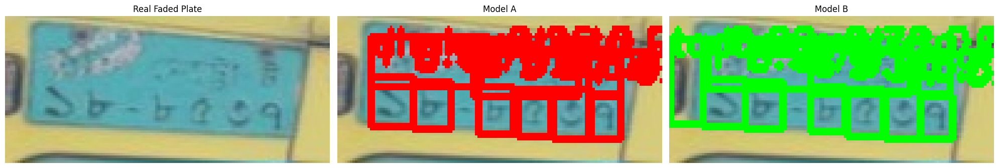

Image: plate_0012.jpg


In [87]:
# ============================================================
# STEP 13.7 - Visual comparison for one real faded plate
# ============================================================

import matplotlib.pyplot as plt
import cv2
import random

sample_path = random.choice(
    real_images
)

image_bgr = cv2.imread(
    sample_path
)

image_rgb = cv2.cvtColor(
    image_bgr,
    cv2.COLOR_BGR2RGB
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 7)
)

# ------------------------------------------------------------
# Original faded image
# ------------------------------------------------------------

axes[0].imshow(image_rgb)
axes[0].set_title(
    "Real Faded Plate"
)
axes[0].axis("off")


# ------------------------------------------------------------
# Model A
# ------------------------------------------------------------

axes[1].imshow(image_rgb.copy())

image_A = image_rgb.copy()

rows_A = pred_A_df[
    pred_A_df["image"]
    ==
    os.path.basename(sample_path)
]

for _, row in rows_A.iterrows():

    x1 = int(row["x1"])
    y1 = int(row["y1"])
    x2 = int(row["x2"])
    y2 = int(row["y2"])

    cv2.rectangle(
        image_A,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )

    label = (
        f'{row["class_name"]} '
        f'{row["confidence"]:.2f}'
    )

    cv2.putText(
        image_A,
        label,
        (x1, max(y1 - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

axes[1].cla()
axes[1].imshow(image_A)
axes[1].set_title("Model A")
axes[1].axis("off")


# ------------------------------------------------------------
# Model B
# ------------------------------------------------------------

image_B = image_rgb.copy()

rows_B = pred_B_df[
    pred_B_df["image"]
    ==
    os.path.basename(sample_path)
]

for _, row in rows_B.iterrows():

    x1 = int(row["x1"])
    y1 = int(row["y1"])
    x2 = int(row["x2"])
    y2 = int(row["y2"])

    cv2.rectangle(
        image_B,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    label = (
        f'{row["class_name"]} '
        f'{row["confidence"]:.2f}'
    )

    cv2.putText(
        image_B,
        label,
        (x1, max(y1 - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

axes[2].imshow(image_B)
axes[2].set_title("Model B")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print(
    "Image:",
    os.path.basename(sample_path)
)

In [88]:
# ============================================================
# STEP 13.8 - Diagnostic predicted sequence
# ============================================================

def predicted_sequence(
    df,
    image_name,
    confidence_threshold=0.25
):

    rows = df[
        (df["image"] == image_name)
        &
        (df["confidence"] >= confidence_threshold)
    ].copy()

    if len(rows) == 0:
        return ""

    # Sort primarily by vertical position,
    # then left-to-right.
    rows = rows.sort_values(
        ["center_y", "center_x"]
    )

    return " ".join(
        rows["class_name"].tolist()
    )


image_name = os.path.basename(
    sample_path
)

seq_A = predicted_sequence(
    pred_A_df,
    image_name
)

seq_B = predicted_sequence(
    pred_B_df,
    image_name
)

print("Image:", image_name)

print("\nModel A:")
print(seq_A)

print("\nModel B:")
print(seq_B)

Image: plate_0012.jpg

Model A:
dhaka metro ta 1 8 8 5 3 6 7

Model B:
dhaka metro ta ta 1 8 8 5 3 7


In [89]:
# ============================================================
# STEP 14.1 - Verify predictions and ground truth
# ============================================================

import os
import pandas as pd

required_variables = [
    "pred_A_df",
    "pred_B_df",
    "real_images",
    "CLASS_NAMES"
]

for variable in required_variables:
    print(f"{variable}: {variable in globals()}")

GT_PATH = "/kaggle/working/real_faded_ground_truth_roman.csv"

print("\nGround-truth CSV exists:", os.path.exists(GT_PATH))

if os.path.exists(GT_PATH):
    roman_df = pd.read_csv(GT_PATH, encoding="utf-8-sig")
    print("Ground-truth rows:", len(roman_df))
    print("Labeled images:", roman_df["has_ground_truth"].sum())

assert all(v in globals() for v in required_variables), (
    "A required variable is missing. Rerun its earlier cell."
)

assert os.path.exists(GT_PATH), "Ground-truth CSV not found."

pred_A_df: True
pred_B_df: True
real_images: True
CLASS_NAMES: True

Ground-truth CSV exists: True
Ground-truth rows: 67
Labeled images: 64


In [90]:
# ============================================================
# STEP 14.2 - Spatial line grouping
# ============================================================

import numpy as np
import cv2
import os

def order_detections_into_lines(
    detections,
    image_height,
    confidence_threshold=0.25
):
    """
    Group detections into approximate visual rows, then
    sort each row from left to right.

    This is a geometric baseline, not matra-aware OCR.
    """

    if detections is None or detections.empty:
        return []

    df = detections[
        detections["confidence"] >= confidence_threshold
    ].copy()

    if df.empty:
        return []

    # Sort top to bottom
    df = df.sort_values("center_y")

    median_box_height = max(
        1.0,
        float(df["height"].median())
    )

    # Approximate vertical separation between different rows.
    # The threshold adapts to both box height and image height.
    row_threshold = max(
        0.75 * median_box_height,
        0.12 * image_height
    )

    lines = []

    for _, det in df.iterrows():

        cy = float(det["center_y"])

        assigned = False

        # Add to the closest existing row when its vertical
        # position is sufficiently close to that row's median.
        for line in lines:

            row_center = float(
                np.median([
                    item["center_y"]
                    for item in line
                ])
            )

            if abs(cy - row_center) <= row_threshold:
                line.append(det.to_dict())
                assigned = True
                break

        if not assigned:
            lines.append([det.to_dict()])

    # Top-to-bottom order of rows
    lines.sort(
        key=lambda line: np.median(
            [item["center_y"] for item in line]
        )
    )

    # Left-to-right order inside each row
    for line in lines:
        line.sort(key=lambda item: item["center_x"])

    return lines


def lines_to_sequence(lines):
    """
    Produce a diagnostic class sequence.
    '/' separates detected visual rows.
    """

    rendered_lines = []

    for line in lines:
        tokens = [
            str(item["class_name"])
            for item in line
        ]

        rendered_lines.append(" ".join(tokens))

    return " / ".join(rendered_lines)

In [91]:
# ============================================================
# STEP 14.3 - Spatial reconstruction for all real images
# ============================================================

import pandas as pd
import os
import cv2

# Create image lookup using filename without extension
image_path_by_id = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in real_images
}

# Normalize prediction data so it joins reliably to plate IDs
A = pred_A_df.copy()
B = pred_B_df.copy()

A["image_id"] = A["image"].apply(
    lambda x: os.path.splitext(os.path.basename(x))[0]
)

B["image_id"] = B["image"].apply(
    lambda x: os.path.splitext(os.path.basename(x))[0]
)

# Index the ground truth by the identifier, e.g. plate_0001
gt_lookup = (
    roman_df.set_index("image")["ground_truth"]
    .fillna("")
    .to_dict()
)

output_rows = []

for image_id, image_path in sorted(image_path_by_id.items()):

    img = cv2.imread(image_path)

    if img is None:
        print("WARNING: Could not read:", image_path)
        continue

    image_height = img.shape[0]

    det_A = A[A["image_id"] == image_id]
    det_B = B[B["image_id"] == image_id]

    lines_A = order_detections_into_lines(
        det_A,
        image_height=image_height
    )

    lines_B = order_detections_into_lines(
        det_B,
        image_height=image_height
    )

    seq_A = lines_to_sequence(lines_A)
    seq_B = lines_to_sequence(lines_B)

    output_rows.append({
        "image": image_id,
        "ground_truth": gt_lookup.get(image_id, ""),
        "model_A_sequence": seq_A,
        "model_B_sequence": seq_B,
        "model_A_detections": len(det_A),
        "model_B_detections": len(det_B),
        "ground_truth_available": bool(
            gt_lookup.get(image_id, "").strip()
        )
    })

reconstruction_df = pd.DataFrame(output_rows)

RECON_PATH = (
    "/kaggle/working/"
    "real_faded_spatial_reconstruction.csv"
)

reconstruction_df.to_csv(
    RECON_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", RECON_PATH)
print("Images processed:", len(reconstruction_df))
print("\nFirst 15 results:")

display(reconstruction_df.head(15))

Saved: /kaggle/working/real_faded_spatial_reconstruction.csv
Images processed: 67

First 15 results:


,image,ground_truth,model_A_sequence,model_B_sequence,model_A_detections,model_B_detections,ground_truth_available
0,plate_0001,khulna metro-la 11-6328,khulna metro ga / 1 1 6 3 2 8,khulna metro ga / 1 1 6 3 2 8,9,9,True
1,plate_0002,,dhaka / 2 3 0,dhaka metro / 2 3 2,4,5,False
2,plate_0003,dhaka metro-u 20-5938,2 dhaka 0 5 metro 9 3 ja 8,2 dhaka 0 5 metro 9 3 ja 8,9,9,True
3,plate_0004,dhaka metro-ga 31-8763,3 dhaka 1 metro ga / 8 7 6 3,3 dhaka 1 metro ga / 8 7 6 3,9,9,True
4,plate_0005,dhaka metro-ba 14-8351,1 dhaka 4 metro metro 8 ba,1 dhaka 4 metro ba / 8 5 3,7,8,True
5,plate_0006,dhaka metro-ga 20-1300,2 0 dhaka 1 metro 3 0 0,2 dhaka 0 1 metro 3 0 0,8,8,True
6,plate_0007,dhaka metro-na 11-1335,1 dhaka 1 1 metro 4 3 5,1 dhaka 1 1 metro 3 3 ta 5,8,9,True
7,plate_0008,dhaka metro-ha 14-9803,1 dhaka 4 9 metro 8 0 6,1 dhaka 4 9 metro 8 0 ba 3,8,9,True
8,plate_0009,dhaka metro-u 12-1205,dhaka metro ja / 1 2 1 2 4 1 5,dhaka metro / 1 2 1 2 4,10,7,True
9,plate_0010,dhaka metro-sha 11-0361,dhaka metro ga / 1 1 0 6 2,dhaka metro ga 1 / 1 1 0 8 6,8,9,True


In [92]:
# ============================================================
# STEP 14.4 - Compare detections on the real faded images
# ============================================================

comparison = pd.DataFrame({
    "Metric": [
        "Images processed",
        "Images with ground truth",
        "Total Model A detections",
        "Total Model B detections",
        "Average Model A detections/image",
        "Average Model B detections/image"
    ],
    "Value": [
        len(reconstruction_df),
        int(reconstruction_df["ground_truth_available"].sum()),
        int(reconstruction_df["model_A_detections"].sum()),
        int(reconstruction_df["model_B_detections"].sum()),
        round(reconstruction_df["model_A_detections"].mean(), 2),
        round(reconstruction_df["model_B_detections"].mean(), 2)
    ]
})

display(comparison)

,Metric,Value
0,Images processed,67.00
1,Images with ground truth,64.00
2,Total Model A detections,549.00
3,Total Model B detections,554.00
4,Average Model A detections/image,8.19
5,Average Model B detections/image,8.27


In [93]:
# ============================================================
# STEP 14.5 - Inspect predictions beside the ground truth
# ============================================================

labeled_preview = reconstruction_df[
    reconstruction_df["ground_truth_available"]
].head(15)

display(
    labeled_preview[
        [
            "image",
            "ground_truth",
            "model_A_sequence",
            "model_B_sequence"
        ]
    ]
)

,image,ground_truth,model_A_sequence,model_B_sequence
0,plate_0001,khulna metro-la 11-6328,khulna metro ga / 1 1 6 3 2 8,khulna metro ga / 1 1 6 3 2 8
2,plate_0003,dhaka metro-u 20-5938,2 dhaka 0 5 metro 9 3 ja 8,2 dhaka 0 5 metro 9 3 ja 8
3,plate_0004,dhaka metro-ga 31-8763,3 dhaka 1 metro ga / 8 7 6 3,3 dhaka 1 metro ga / 8 7 6 3
4,plate_0005,dhaka metro-ba 14-8351,1 dhaka 4 metro metro 8 ba,1 dhaka 4 metro ba / 8 5 3
5,plate_0006,dhaka metro-ga 20-1300,2 0 dhaka 1 metro 3 0 0,2 dhaka 0 1 metro 3 0 0
6,plate_0007,dhaka metro-na 11-1335,1 dhaka 1 1 metro 4 3 5,1 dhaka 1 1 metro 3 3 ta 5
7,plate_0008,dhaka metro-ha 14-9803,1 dhaka 4 9 metro 8 0 6,1 dhaka 4 9 metro 8 0 ba 3
8,plate_0009,dhaka metro-u 12-1205,dhaka metro ja / 1 2 1 2 4 1 5,dhaka metro / 1 2 1 2 4
9,plate_0010,dhaka metro-sha 11-0361,dhaka metro ga / 1 1 0 6 2,dhaka metro ga 1 / 1 1 0 8 6
10,plate_0011,dhaka metro-ca 63-5149,dhaka metro / 6 3 0 1 4 1 9,dhaka metro ja / 6 3 0 1 4 9


In [94]:
# ============================================================
# STEP 15.1 - Plate-structure-aware decoder
# ============================================================

import os
import re
import cv2
import numpy as np
import pandas as pd

DIGIT_CLASSES = {str(i) for i in range(10)}

PLACE_CLASSES = {
    "dhaka",
    "khulna",
    "chattogram",
    "jashore"
}

METRO_CLASS = "metro"

LETTER_CLASSES = (
    set(CLASS_NAMES)
    - DIGIT_CLASSES
    - PLACE_CLASSES
    - {METRO_CLASS}
)

def prepare_prediction_df(df):
    """Create a consistent image ID from prediction filenames."""
    out = df.copy()

    out["image_id"] = out["image"].apply(
        lambda name: os.path.splitext(
            os.path.basename(str(name))
        )[0]
    )

    out["class_name"] = out["class_name"].astype(str)

    return out


pred_A_struct = prepare_prediction_df(pred_A_df)
pred_B_struct = prepare_prediction_df(pred_B_df)


def decode_plate_structure(
    detections,
    image_height,
    image_width,
    confidence_threshold=0.25
):
    """
    Initial structural decoder:
      1. Select place/category detections.
      2. Estimate the series letter from lower-region detections.
      3. Sort digit detections left-to-right.
      4. Format exactly six digits as NN-NNNN.
      5. Leave incomplete number groups explicitly incomplete.

    This is a baseline decoder, not matra-aware Unicode OCR.
    """

    if detections is None or detections.empty:
        return {
            "prefix_pred": "",
            "letter_pred": "",
            "digits_raw": "",
            "registration_pred": "",
            "candidate_text": "",
            "digit_count": 0,
            "complete_registration": False
        }

    df = detections[
        detections["confidence"] >= confidence_threshold
    ].copy()

    if df.empty:
        return {
            "prefix_pred": "",
            "letter_pred": "",
            "digits_raw": "",
            "registration_pred": "",
            "candidate_text": "",
            "digit_count": 0,
            "complete_registration": False
        }

    # --------------------------------------------------------
    # 1. Collect digit detections
    # --------------------------------------------------------
    digit_df = df[
        df["class_name"].isin(DIGIT_CLASSES)
    ].copy()

    # If there are more than six candidates, select the six
    # highest-confidence ones as a simple, explicit heuristic.
    # This can still fail if a false positive has high confidence.
    if len(digit_df) > 6:
        digit_df = (
            digit_df
            .nlargest(6, "confidence")
            .copy()
        )

    # Registration digits are ordered horizontally, regardless
    # of whether their detected box centers fall on one row.
    digit_df = digit_df.sort_values("center_x")

    digits_raw = "".join(
        digit_df["class_name"].tolist()
    )

    digit_count = len(digit_df)

    if digit_count == 6:
        registration = (
            digits_raw[:2] + "-" + digits_raw[2:]
        )
        complete_registration = True
    else:
        # Do not guess missing digits.
        registration = digits_raw
        complete_registration = False

    # --------------------------------------------------------
    # 2. Detect location/category words
    # --------------------------------------------------------
    word_df = df[
        df["class_name"].isin(
            PLACE_CLASSES | {METRO_CLASS}
        )
    ].copy()

    # A plate normally needs each detected word class at most
    # once. For duplicate detections of the same class, retain
    # the highest-confidence candidate.
    if not word_df.empty:
        word_df = (
            word_df.sort_values(
                "confidence",
                ascending=False
            )
            .drop_duplicates(
                subset=["class_name"]
            )
            .sort_values("center_x")
        )

    prefix_tokens = word_df["class_name"].tolist()

    prefix_pred = " ".join(prefix_tokens)

    # --------------------------------------------------------
    # 3. Estimate the series-letter class
    # --------------------------------------------------------
    letter_df = df[
        df["class_name"].isin(LETTER_CLASSES)
    ].copy()

    if not digit_df.empty and not letter_df.empty:

        median_digit_y = float(
            digit_df["center_y"].median()
        )

        first_digit_x = float(
            digit_df["center_x"].min()
        )

        # Favor candidates in the lower number region and
        # generally to the left of the first registration digit.
        y_tolerance = max(
            0.20 * image_height,
            1.5 * float(digit_df["height"].median())
        )

        letter_df = letter_df[
            (
                (
                    letter_df["center_y"]
                    - median_digit_y
                ).abs() <= y_tolerance
            )
            &
            (
                letter_df["center_x"]
                < first_digit_x + 0.08 * image_width
            )
        ]

    elif not letter_df.empty:
        # Fallback if no digit boxes were found.
        letter_df = letter_df[
            letter_df["center_y"]
            >= 0.30 * image_height
        ]

    if not letter_df.empty:
        chosen_letter = letter_df.loc[
            letter_df["confidence"].idxmax()
        ]
        letter_pred = str(
            chosen_letter["class_name"]
        )
    else:
        letter_pred = ""

    # --------------------------------------------------------
    # 4. Assemble the candidate string
    # --------------------------------------------------------
    if prefix_pred and letter_pred:
        head = f"{prefix_pred}-{letter_pred}"
    elif prefix_pred:
        head = prefix_pred
    elif letter_pred:
        head = letter_pred
    else:
        head = ""

    if head and registration:
        candidate = f"{head} {registration}"
    elif head:
        candidate = head
    else:
        candidate = registration

    return {
        "prefix_pred": prefix_pred,
        "letter_pred": letter_pred,
        "digits_raw": digits_raw,
        "registration_pred": registration,
        "candidate_text": candidate,
        "digit_count": digit_count,
        "complete_registration": complete_registration
    }


print("Structure-aware decoder defined.")
print("Digit classes:", sorted(DIGIT_CLASSES))
print("Location classes:", sorted(PLACE_CLASSES))
print("Series-letter classes:", sorted(LETTER_CLASSES))

Structure-aware decoder defined.
Digit classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Location classes: ['chattogram', 'dhaka', 'jashore', 'khulna']
Series-letter classes: ['ba', 'ca', 'da', 'ga', 'gha', 'ha', 'ja', 'ka', 'kha', 'na', 'ta', 'va']


In [95]:
# ============================================================
# STEP 15.2 - Apply decoder to all real faded images
# ============================================================

image_path_by_id = {
    os.path.splitext(
        os.path.basename(path)
    )[0]: path
    for path in real_images
}

gt_lookup = (
    roman_df.set_index("image")["ground_truth"]
    .fillna("")
    .to_dict()
)

decoded_rows = []

for image_id, image_path in sorted(
    image_path_by_id.items()
):

    img = cv2.imread(image_path)

    if img is None:
        print("WARNING: Cannot read", image_path)
        continue

    h, w = img.shape[:2]

    rows_A = pred_A_struct[
        pred_A_struct["image_id"] == image_id
    ]

    rows_B = pred_B_struct[
        pred_B_struct["image_id"] == image_id
    ]

    dec_A = decode_plate_structure(
        rows_A,
        image_height=h,
        image_width=w
    )

    dec_B = decode_plate_structure(
        rows_B,
        image_height=h,
        image_width=w
    )

    decoded_rows.append({
        "image": image_id,
        "ground_truth": gt_lookup.get(image_id, ""),

        "A_prefix": dec_A["prefix_pred"],
        "A_letter": dec_A["letter_pred"],
        "A_digits": dec_A["digits_raw"],
        "A_registration": dec_A["registration_pred"],
        "A_candidate": dec_A["candidate_text"],
        "A_digit_count": dec_A["digit_count"],
        "A_registration_complete":
            dec_A["complete_registration"],

        "B_prefix": dec_B["prefix_pred"],
        "B_letter": dec_B["letter_pred"],
        "B_digits": dec_B["digits_raw"],
        "B_registration": dec_B["registration_pred"],
        "B_candidate": dec_B["candidate_text"],
        "B_digit_count": dec_B["digit_count"],
        "B_registration_complete":
            dec_B["complete_registration"]
    })

decoded_df = pd.DataFrame(decoded_rows)

DECODED_PATH = (
    "/kaggle/working/"
    "real_faded_structure_aware_results.csv"
)

decoded_df.to_csv(
    DECODED_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", DECODED_PATH)
print("Images processed:", len(decoded_df))

display(
    decoded_df[
        [
            "image",
            "ground_truth",
            "A_candidate",
            "B_candidate",
            "A_registration_complete",
            "B_registration_complete"
        ]
    ].head(20)
)

Saved: /kaggle/working/real_faded_structure_aware_results.csv
Images processed: 67


,image,ground_truth,A_candidate,B_candidate,A_registration_complete,B_registration_complete
0,plate_0001,khulna metro-la 11-6328,khulna metro 11-6328,khulna metro 11-6328,True,True
1,plate_0002,,dhaka 230,dhaka metro 232,False,False
2,plate_0003,dhaka metro-u 20-5938,dhaka metro 20-5938,dhaka metro 20-5938,True,True
3,plate_0004,dhaka metro-ga 31-8763,dhaka metro 31-8763,dhaka metro 31-8763,True,True
4,plate_0005,dhaka metro-ba 14-8351,dhaka metro 148,dhaka metro 14853,False,False
5,plate_0006,dhaka metro-ga 20-1300,dhaka metro 20-1300,dhaka metro 20-1300,True,True
6,plate_0007,dhaka metro-na 11-1335,dhaka metro 11-1435,dhaka metro 11-1335,True,True
7,plate_0008,dhaka metro-ha 14-9803,dhaka metro 14-9806,dhaka metro 14-9803,True,True
8,plate_0009,dhaka metro-u 12-1205,dhaka metro 12-1215,dhaka metro 12124,True,False
9,plate_0010,dhaka metro-sha 11-0361,dhaka metro 11062,dhaka metro 11-0861,False,True


In [96]:
# ============================================================
# STEP 15.3 - Registration-number accuracy
# ============================================================

def extract_gt_registration(text):
    """
    Extract the trailing NN-NNNN pattern from the Roman
    ground-truth label. Return an empty string if unavailable.
    """
    text = str(text).strip().lower()

    match = re.search(
        r"(\d{2}-\d{4})\s*$",
        text
    )

    return match.group(1) if match else ""


evaluation_df = decoded_df[
    decoded_df["ground_truth"].astype(str).str.strip().ne("")
].copy()

evaluation_df["GT_registration"] = (
    evaluation_df["ground_truth"]
    .apply(extract_gt_registration)
)

def registration_metrics(df, model_prefix):

    pred_col = f"{model_prefix}_registration"
    complete_col = f"{model_prefix}_registration_complete"

    valid = df[
        df["GT_registration"].ne("")
        &
        df[complete_col]
    ].copy()

    if valid.empty:
        return {
            "model": model_prefix,
            "labeled_images": len(df),
            "complete_numbers": 0,
            "exact_correct": 0,
            "exact_accuracy": np.nan
        }

    correct = (
        valid[pred_col]
        == valid["GT_registration"]
    )

    return {
        "model": model_prefix,
        "labeled_images": len(df),
        "complete_numbers": len(valid),
        "exact_correct": int(correct.sum()),
        "exact_accuracy": round(
            float(correct.mean()),
            4
        )
    }


registration_comparison = pd.DataFrame([
    registration_metrics(evaluation_df, "A"),
    registration_metrics(evaluation_df, "B")
])

display(registration_comparison)

,model,labeled_images,complete_numbers,exact_correct,exact_accuracy
0,A,64,53,29,0.5472
1,B,64,54,42,0.7778


In [97]:
# ============================================================
# STEP 16.1 - Registration digit error analysis
# ============================================================

import re
import numpy as np
import pandas as pd

def extract_gt_digits(text):
    """Extract the final NN-NNNN registration group."""
    text = str(text).strip()

    match = re.search(r"(\d{2})-(\d{4})\s*$", text)

    if not match:
        return ""

    return match.group(1) + match.group(2)


def extract_pred_digits(text):
    """Remove formatting from the predicted number."""
    return re.sub(r"\D", "", str(text))


def levenshtein_distance(a, b):
    """Calculate character-level edit distance."""
    if len(a) < len(b):
        a, b = b, a

    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            insert_cost = current[j - 1] + 1
            delete_cost = previous[j] + 1
            replace_cost = previous[j - 1] + (ca != cb)

            current.append(
                min(insert_cost, delete_cost, replace_cost)
            )

        previous = current

    return previous[-1]


# Include only images with available ground truth.
error_df = decoded_df[
    decoded_df["ground_truth"].fillna("").str.strip().ne("")
].copy()

error_df["GT_digits"] = (
    error_df["ground_truth"].apply(extract_gt_digits)
)

for model_name in ["A", "B"]:

    pred_col = f"{model_name}_registration"

    error_df[f"{model_name}_pred_digits"] = (
        error_df[pred_col].apply(extract_pred_digits)
    )

    digit_col = f"{model_name}_pred_digits"

    error_df[f"{model_name}_complete"] = (
        error_df[digit_col].str.len() == 6
    )

    error_df[f"{model_name}_exact"] = (
        error_df[digit_col] == error_df["GT_digits"]
    )

    error_df[f"{model_name}_edit_distance"] = error_df.apply(
        lambda row: levenshtein_distance(
            row["GT_digits"],
            row[digit_col]
        ),
        axis=1
    )

    error_df[f"{model_name}_digit_CER"] = error_df.apply(
        lambda row: (
            row[f"{model_name}_edit_distance"]
            / len(row["GT_digits"])
            if len(row["GT_digits"]) > 0
            else np.nan
        ),
        axis=1
    )


summary_rows = []

for model_name in ["A", "B"]:

    summary_rows.append({
        "Model": model_name,
        "Labeled images": len(error_df),
        "Complete predictions": int(
            error_df[f"{model_name}_complete"].sum()
        ),
        "Exact matches": int(
            error_df[f"{model_name}_exact"].sum()
        ),
        "Strict exact accuracy (%)": round(
            100 * error_df[f"{model_name}_exact"].mean(),
            2
        ),
        "Mean digit edit distance": round(
            error_df[f"{model_name}_edit_distance"].mean(),
            3
        ),
        "Mean digit CER (%)": round(
            100 * error_df[f"{model_name}_digit_CER"].mean(),
            2
        )
    })

metrics_df = pd.DataFrame(summary_rows)

display(metrics_df)

error_df.to_csv(
    "/kaggle/working/real_faded_digit_error_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Detailed error analysis saved.")

,Model,Labeled images,Complete predictions,Exact matches,Strict exact accuracy (%),Mean digit edit distance,Mean digit CER (%)
0,A,64,53,29,45.31,1.203,20.05
1,B,64,54,42,65.62,0.578,9.64


Detailed error analysis saved.


In [98]:
# ============================================================
# STEP 16.2 - Inspect the hardest Model B cases
# ============================================================

hard_cases = error_df[
    ~error_df["B_exact"]
].sort_values(
    ["B_digit_CER", "B_edit_distance"],
    ascending=False
)

columns = [
    "image",
    "ground_truth",
    "GT_digits",
    "A_pred_digits",
    "B_pred_digits",
    "A_exact",
    "B_exact",
    "B_edit_distance",
    "B_digit_CER"
]

display(hard_cases[columns].head(20))

,image,ground_truth,GT_digits,A_pred_digits,B_pred_digits,A_exact,B_exact,B_edit_distance,B_digit_CER
45,plate_0046,tangail-kha 11-0032,110032,,821,False,False,6,1.000000
35,plate_0036,dhaka metro-sha 11-3530,113530,114,11454,False,False,3,0.500000
37,plate_0038,dhaka metro-na 16-7320,167320,147420,140720,False,False,3,0.500000
4,plate_0005,dhaka metro-ba 14-8351,148351,148,14853,False,False,2,0.333333
8,plate_0009,dhaka metro-u 12-1205,121205,121215,12124,False,False,2,0.333333
23,plate_0024,dhaka metro-tha 15-0902,150902,09012,10102,False,False,2,0.333333
54,plate_0055,satkhira-ja 11-0004,110004,10004,1000,False,False,2,0.333333
58,plate_0059,dhaka metro-ba 18-6703,186703,148703,148703,False,False,2,0.333333
62,plate_0063,dhaka metro-ta 11-6124,116124,116614,11164,False,False,2,0.333333
9,plate_0010,dhaka metro-sha 11-0361,110361,11062,110861,False,False,1,0.166667


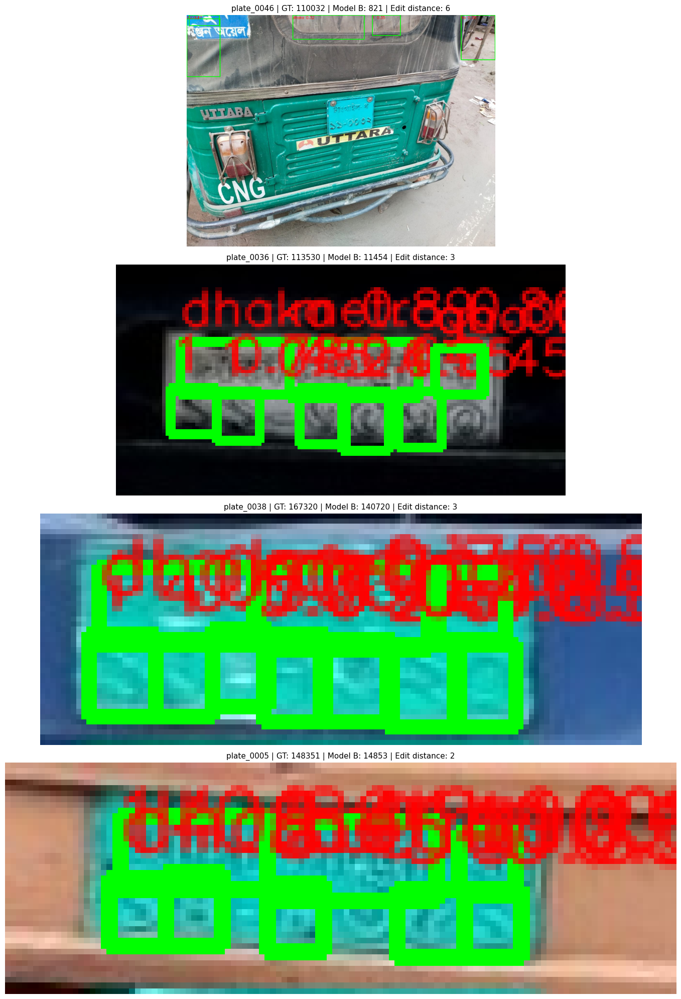

In [99]:
# ============================================================
# STEP 17 - Visualize difficult Model B cases
# ============================================================

import matplotlib.pyplot as plt
import cv2
import os
import numpy as np

image_path_by_id = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in real_images
}

cases = hard_cases.head(4)

if cases.empty:
    print("No incorrect Model B registration predictions found.")
else:
    fig, axes = plt.subplots(
        len(cases), 1,
        figsize=(16, 5 * len(cases))
    )

    axes = np.atleast_1d(axes)

    for ax, (_, row) in zip(axes, cases.iterrows()):

        image_id = row["image"]
        image_path = image_path_by_id.get(image_id)

        if image_path is None:
            ax.axis("off")
            continue

        image_bgr = cv2.imread(image_path)

        if image_bgr is None:
            ax.axis("off")
            continue

        image_rgb = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB
        )

        canvas = image_rgb.copy()

        boxes = pred_B_struct[
            pred_B_struct["image_id"] == image_id
        ]

        for _, det in boxes.iterrows():

            x1 = int(det["x1"])
            y1 = int(det["y1"])
            x2 = int(det["x2"])
            y2 = int(det["y2"])

            cv2.rectangle(
                canvas,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            label = (
                f'{det["class_name"]} '
                f'{det["confidence"]:.2f}'
            )

            cv2.putText(
                canvas,
                label,
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                1,
                cv2.LINE_AA
            )

        ax.imshow(canvas)
        ax.axis("off")

        ax.set_title(
            f'{image_id} | GT: {row["GT_digits"]} | '
            f'Model B: {row["B_pred_digits"]} | '
            f'Edit distance: {row["B_edit_distance"]}',
            fontsize=11
        )

    plt.tight_layout()
    plt.show()

Dataset exists: True
Path: /kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/License Plate Localization

TRAIN
Images: 5687
XML files: 5687
Matched image/XML pairs: 5687
Images without matching XML: 0

VALIDATION
Images: 277
XML files: 277
Matched image/XML pairs: 277
Images without matching XML: 0

TEST
Images: 553
XML files: 553
Matched image/XML pairs: 553
Images without matching XML: 0

Object classes found in XML:
0                         4795

Sample image: car-4041_jpg.rf.a18b5b0194feb17ed269bb3220313108.jpg
Sample XML: car-4041_jpg.rf.a18b5b0194feb17ed269bb3220313108.xml


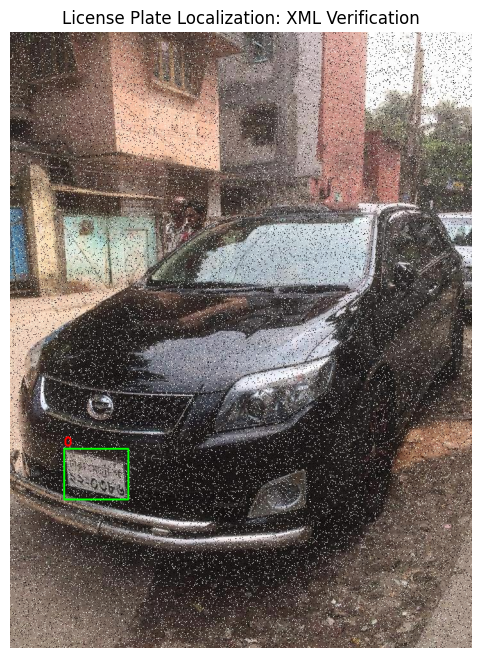

In [100]:
# ============================================================
# STEP 18.1 - Inspect License Plate Localization dataset
# ============================================================

import os
import glob
import random
import xml.etree.ElementTree as ET
from collections import Counter

import cv2
import matplotlib.pyplot as plt


DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "syednahinhossain/"
    "bangladeshi-license-plate-recognition-dataset"
)

LOC_ROOT = os.path.join(
    DATASET_ROOT,
    "License Plate Localization"
)

print("Dataset exists:", os.path.exists(LOC_ROOT))
print("Path:", LOC_ROOT)

IMAGE_EXTS = (".jpg", ".jpeg", ".png")

class_counts = Counter()
matched_pairs = {}
split_info = {}

for split in ["train", "validation", "test"]:

    split_dir = os.path.join(LOC_ROOT, split)

    if not os.path.isdir(split_dir):
        print(f"\nWARNING: Missing split: {split_dir}")
        continue

    image_files = [
        p for p in glob.glob(os.path.join(split_dir, "*"))
        if os.path.isfile(p)
        and os.path.splitext(p)[1].lower() in IMAGE_EXTS
    ]

    xml_files = glob.glob(
        os.path.join(split_dir, "*.xml")
    )

    xml_by_stem = {
        os.path.splitext(os.path.basename(p))[0]: p
        for p in xml_files
    }

    pairs = []

    for image_path in image_files:

        stem = os.path.splitext(
            os.path.basename(image_path)
        )[0]

        xml_path = xml_by_stem.get(stem)

        if xml_path is not None:
            pairs.append((image_path, xml_path))

            try:
                root = ET.parse(xml_path).getroot()

                for obj in root.findall("object"):
                    name_node = obj.find("name")

                    if name_node is not None and name_node.text:
                        class_counts[name_node.text.strip()] += 1

            except Exception as exc:
                print("XML reading error:", xml_path, exc)

    matched_pairs[split] = pairs

    split_info[split] = {
        "images": len(image_files),
        "xml": len(xml_files),
        "matched": len(pairs),
        "images_without_xml": len(image_files) - len(pairs)
    }

    print(f"\n{split.upper()}")
    print("Images:", len(image_files))
    print("XML files:", len(xml_files))
    print("Matched image/XML pairs:", len(pairs))
    print("Images without matching XML:", len(image_files) - len(pairs))


print("\nObject classes found in XML:")
for name, count in class_counts.most_common():
    print(f"{name:25s} {count}")

# ------------------------------------------------------------
# Visualize one original image with its XML boxes
# ------------------------------------------------------------

all_pairs = [
    pair
    for pairs in matched_pairs.values()
    for pair in pairs
]

if all_pairs:

    image_path, xml_path = random.choice(all_pairs)

    image = cv2.imread(image_path)

    if image is not None:

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        root = ET.parse(xml_path).getroot()

        print("\nSample image:", os.path.basename(image_path))
        print("Sample XML:", os.path.basename(xml_path))

        for obj in root.findall("object"):

            name_node = obj.find("name")
            bbox = obj.find("bndbox")

            if name_node is None or bbox is None:
                continue

            name = name_node.text.strip()

            x1 = int(float(bbox.find("xmin").text))
            y1 = int(float(bbox.find("ymin").text))
            x2 = int(float(bbox.find("xmax").text))
            y2 = int(float(bbox.find("ymax").text))

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                image,
                name,
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 0, 0),
                2
            )

        plt.figure(figsize=(14, 8))
        plt.imshow(image)
        plt.axis("off")
        plt.title("License Plate Localization: XML Verification")
        plt.show()

    else:
        print("Could not read the sampled image.")

else:
    print("\nNo matched image/XML pairs found. Check the dataset path.")

In [101]:
# ============================================================
# STEP 18.2 - Convert License Plate Localization XML to YOLO
# ============================================================

import os
import glob
import shutil
import xml.etree.ElementTree as ET
from collections import Counter

from PIL import Image

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "syednahinhossain/"
    "bangladeshi-license-plate-recognition-dataset"
)

LOC_ROOT = os.path.join(
    DATASET_ROOT,
    "License Plate Localization"
)

LP_OUT = "/kaggle/working/lp_detector_data"

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

# Create a fresh output directory to avoid mixing old files.
if os.path.exists(LP_OUT):
    shutil.rmtree(LP_OUT)

for split in ["train", "validation", "test"]:
    os.makedirs(
        os.path.join(LP_OUT, split, "images"),
        exist_ok=True
    )
    os.makedirs(
        os.path.join(LP_OUT, split, "labels"),
        exist_ok=True
    )


def convert_voc_xml_to_yolo(xml_path, image_width, image_height):
    """
    Convert Pascal VOC bounding boxes to YOLO format.

    Output line:
    class_id center_x center_y width height

    All coordinates are normalized to 0-1.
    Every valid annotated object is treated as license_plate.
    """

    root = ET.parse(xml_path).getroot()
    output_lines = []
    total_objects = 0

    for obj in root.findall("object"):

        bbox = obj.find("bndbox")

        if bbox is None:
            continue

        coords = [
            bbox.find(tag)
            for tag in ["xmin", "ymin", "xmax", "ymax"]
        ]

        if any(value is None for value in coords):
            continue

        try:
            xmin, ymin, xmax, ymax = [
                float(value.text) for value in coords
            ]
        except (ValueError, TypeError):
            continue

        # Clamp to image boundaries.
        xmin = max(0.0, min(xmin, float(image_width)))
        xmax = max(0.0, min(xmax, float(image_width)))
        ymin = max(0.0, min(ymin, float(image_height)))
        ymax = max(0.0, min(ymax, float(image_height)))

        # Skip invalid or degenerate boxes.
        if xmax <= xmin or ymax <= ymin:
            continue

        box_width = xmax - xmin
        box_height = ymax - ymin

        center_x = (xmin + xmax) / 2.0
        center_y = (ymin + ymax) / 2.0

        # Normalize coordinates.
        center_x /= image_width
        center_y /= image_height
        box_width /= image_width
        box_height /= image_height

        # One class only: license_plate = class 0.
        output_lines.append(
            f"0 {center_x:.6f} {center_y:.6f} "
            f"{box_width:.6f} {box_height:.6f}"
        )

        total_objects += 1

    return output_lines, total_objects


total_images = 0
total_boxes = 0
total_empty_labels = 0

for split in ["train", "validation", "test"]:

    source_dir = os.path.join(LOC_ROOT, split)

    # Build image lookup by filename stem.
    image_map = {}

    for path in glob.glob(os.path.join(source_dir, "*")):
        if (
            os.path.isfile(path)
            and os.path.splitext(path)[1].lower() in IMAGE_EXTS
        ):
            stem = os.path.splitext(os.path.basename(path))[0]
            image_map[stem] = path

    xml_files = sorted(
        glob.glob(os.path.join(source_dir, "*.xml"))
    )

    split_images = 0
    split_boxes = 0
    split_empty = 0
    missing_images = 0

    print(f"\nProcessing {split}: {len(xml_files)} XML files")

    for xml_path in xml_files:

        stem = os.path.splitext(os.path.basename(xml_path))[0]
        image_path = image_map.get(stem)

        if image_path is None:
            missing_images += 1
            continue

        try:
            with Image.open(image_path) as im:
                image_width, image_height = im.size

            labels, number_of_boxes = convert_voc_xml_to_yolo(
                xml_path,
                image_width,
                image_height
            )

        except Exception as exc:
            print("Skipping:", os.path.basename(xml_path), exc)
            continue

        # Preserve original image filename.
        out_image = os.path.join(
            LP_OUT, split, "images",
            os.path.basename(image_path)
        )

        # YOLO label file shares the image stem.
        out_label = os.path.join(
            LP_OUT, split, "labels", stem + ".txt"
        )

        shutil.copy2(image_path, out_image)

        # An empty file is intentional if an image has no objects.
        with open(out_label, "w", encoding="utf-8") as f:
            f.write("\n".join(labels))

        split_images += 1
        split_boxes += number_of_boxes

        if number_of_boxes == 0:
            split_empty += 1

    total_images += split_images
    total_boxes += split_boxes
    total_empty_labels += split_empty

    print("Images converted:", split_images)
    print("Valid plate boxes:", split_boxes)
    print("Empty annotation files:", split_empty)
    print("XML without matching image:", missing_images)


# Create data.yaml.
yaml_path = os.path.join(LP_OUT, "data.yaml")

with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(f"path: {LP_OUT}\n")
    f.write("train: train/images\n")
    f.write("val: validation/images\n")
    f.write("test: test/images\n\n")
    f.write("nc: 1\n")
    f.write("names:\n")
    f.write("  0: license_plate\n")

print("\n========================================")
print("CONVERSION COMPLETE")
print("========================================")
print("Total images:", total_images)
print("Total valid boxes:", total_boxes)
print("Empty label files:", total_empty_labels)
print("YAML:", yaml_path)


Processing train: 5687 XML files
Images converted: 5687
Valid plate boxes: 4206
Empty annotation files: 1541
XML without matching image: 0

Processing validation: 277 XML files
Images converted: 277
Valid plate boxes: 191
Empty annotation files: 92
XML without matching image: 0

Processing test: 553 XML files
Images converted: 553
Valid plate boxes: 398
Empty annotation files: 162
XML without matching image: 0

CONVERSION COMPLETE
Total images: 6517
Total valid boxes: 4795
Empty label files: 1795
YAML: /kaggle/working/lp_detector_data/data.yaml


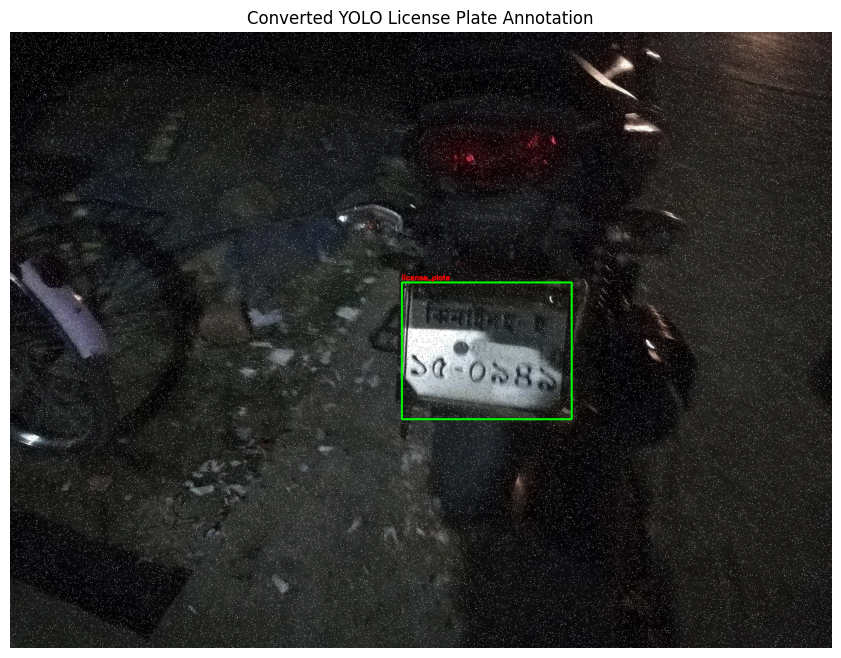

Image: 151832300_470608467410895_4739871976978838755_n_jpg.rf.bf7e3e0730f4317e526999b9e4e1f5d7.jpg
Number of boxes: 1


In [102]:
# ============================================================
# STEP 18.3 - Visual verification of YOLO plate boxes
# ============================================================

import random
import glob
import os
import cv2
import matplotlib.pyplot as plt

TRAIN_IMAGES = os.path.join(LP_OUT, "train", "images")
TRAIN_LABELS = os.path.join(LP_OUT, "train", "labels")

label_files = [
    path for path in glob.glob(
        os.path.join(TRAIN_LABELS, "*.txt")
    )
    if os.path.getsize(path) > 0
]

assert label_files, "No non-empty YOLO labels found."

# Select a randomly annotated image.
label_path = random.choice(label_files)
stem = os.path.splitext(os.path.basename(label_path))[0]

image_path = None

for ext in [".jpg", ".jpeg", ".png"]:
    candidate = os.path.join(TRAIN_IMAGES, stem + ext)
    if os.path.exists(candidate):
        image_path = candidate
        break

assert image_path is not None, "Could not find matching image."

image = cv2.imread(image_path)
assert image is not None, "OpenCV could not read this image."

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

with open(label_path, "r", encoding="utf-8") as f:
    lines = [line.strip() for line in f if line.strip()]

for line in lines:

    values = line.split()

    class_id = int(values[0])
    cx, cy, bw, bh = map(float, values[1:5])

    x1 = int((cx - bw / 2) * width)
    y1 = int((cy - bh / 2) * height)
    x2 = int((cx + bw / 2) * width)
    y2 = int((cy + bh / 2) * height)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        3
    )

    cv2.putText(
        image,
        "license_plate",
        (x1, max(15, y1 - 6)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.axis("off")
plt.title("Converted YOLO License Plate Annotation")
plt.show()

print("Image:", os.path.basename(image_path))
print("Number of boxes:", len(lines))

In [103]:
# ============================================================
# STEP 18.4 - Train dedicated license plate detector
# ============================================================

from ultralytics import YOLO
import os

LP_DATA_YAML = "/kaggle/working/lp_detector_data/data.yaml"

assert os.path.exists(LP_DATA_YAML), "Plate detector YAML not found."

if os.path.exists("/kaggle/working/yolov8n.pt"):
    lp_model = YOLO("/kaggle/working/yolov8n.pt")
else:
    lp_model = YOLO("yolov8n.pt")

lp_results = lp_model.train(
    data=LP_DATA_YAML,

    epochs=50,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    project="/kaggle/working/lp_detection_training",
    name="license_plate_yolov8n",

    seed=42,

    # No fading augmentation in the first plate-detector run.
    # We first establish a clean localization baseline.
    augmentations=[],

    mosaic=0.5,
    mixup=0.0,

    degrees=2.0,
    translate=0.05,
    scale=0.30,

    fliplr=0.0,

    save=True,
    plots=True
)

print("Plate detector training completed.")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/lp_detector_data/data.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/yolov8n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=license_plat

In [104]:
# STEP 19 - Inspect the 67 test image dimensions

import os
import pandas as pd
from PIL import Image

image_info = []

for path in real_images:
    with Image.open(path) as im:
        width, height = im.size

    image_info.append({
        "image": os.path.splitext(os.path.basename(path))[0],
        "width": width,
        "height": height,
        "area": width * height,
        "aspect_ratio": round(width / height, 2)
    })

dimensions_df = pd.DataFrame(image_info)

display(
    dimensions_df.sort_values(
        "area", ascending=False
    ).head(15)
)

,image,width,height,area,aspect_ratio
42,plate_0043,1515,1164,1763460,1.30
45,plate_0046,1280,960,1228800,1.33
41,plate_0042,710,410,291100,1.73
43,plate_0044,580,400,232000,1.45
0,plate_0001,535,390,208650,1.37
51,plate_0052,400,252,100800,1.59
48,plate_0049,323,219,70737,1.47
57,plate_0058,263,144,37872,1.83
15,plate_0016,252,150,37800,1.68
44,plate_0045,202,170,34340,1.19


Input: /kaggle/input/datasets/mdarifulhasan37/cropped-dataset/plate_0046.jpg


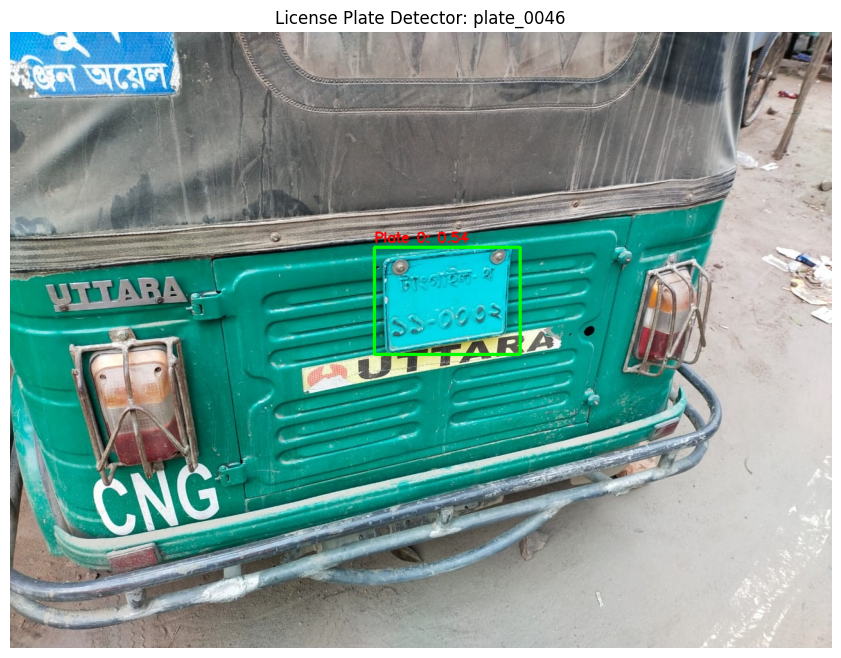


Candidate detections:
{'index': 0, 'x1': 567, 'y1': 335, 'x2': 794, 'y2': 502, 'confidence': 0.5446484088897705, 'area': 37909}


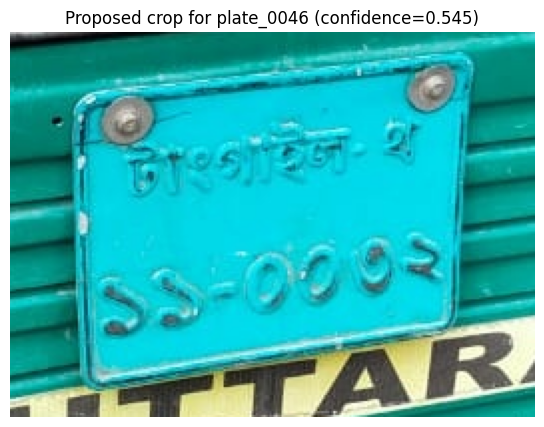

Proposed crop dimensions: (193, 263, 3)


In [105]:
# ============================================================
# STEP 19.1 - Detect the plate in plate_0046
# ============================================================

import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

LP_MODEL_PATH = (
    "/kaggle/working/lp_detection_training/"
    "license_plate_yolov8n/weights/best.pt"
)

assert os.path.exists(LP_MODEL_PATH), (
    f"License plate model not found: {LP_MODEL_PATH}"
)

# Find plate_0046 in the existing 67-image list.
target_matches = [
    p for p in real_images
    if os.path.splitext(os.path.basename(p))[0] == "plate_0046"
]

assert len(target_matches) == 1, (
    f"Expected exactly one plate_0046 image, found {len(target_matches)}"
)

uncropped_path = target_matches[0]

print("Input:", uncropped_path)

lp_model = YOLO(LP_MODEL_PATH)

# Use a lower threshold for inspection so we can see possible candidates.
result = lp_model.predict(
    source=uncropped_path,
    conf=0.15,
    imgsz=640,
    device=0,
    verbose=False
)[0]

image_bgr = cv2.imread(uncropped_path)
assert image_bgr is not None, "Could not read input image."

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
preview = image_rgb.copy()

if result.boxes is None or len(result.boxes) == 0:
    print("No plate detected. Do not crop automatically.")
else:
    candidates = []

    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].item())

        x1, y1, x2, y2 = map(
            int, [x1, y1, x2, y2]
        )

        area = max(0, x2 - x1) * max(0, y2 - y1)

        candidates.append({
            "index": i,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "confidence": confidence,
            "area": area
        })

        cv2.rectangle(
            preview,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        cv2.putText(
            preview,
            f"Plate {i}: {confidence:.2f}",
            (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(14, 8))
    plt.imshow(preview)
    plt.axis("off")
    plt.title("License Plate Detector: plate_0046")
    plt.show()

    print("\nCandidate detections:")
    for item in candidates:
        print(item)

    # Use the largest candidate as a preliminary choice.
    # Inspect it visually before using it for evaluation.
    best = max(candidates, key=lambda item: item["area"])

    H, W = image_rgb.shape[:2]

    # Add 8% padding around the detected box.
    pad_x = int((best["x2"] - best["x1"]) * 0.08)
    pad_y = int((best["y2"] - best["y1"]) * 0.08)

    x1 = max(0, best["x1"] - pad_x)
    y1 = max(0, best["y1"] - pad_y)
    x2 = min(W, best["x2"] + pad_x)
    y2 = min(H, best["y2"] + pad_y)

    plate_crop_preview = image_rgb[y1:y2, x1:x2]

    if plate_crop_preview.size == 0:
        raise RuntimeError("The proposed plate crop is empty.")

    plt.figure(figsize=(12, 5))
    plt.imshow(plate_crop_preview)
    plt.axis("off")
    plt.title(
        f"Proposed crop for plate_0046 "
        f"(confidence={best['confidence']:.3f})"
    )
    plt.show()

    print("Proposed crop dimensions:", plate_crop_preview.shape)

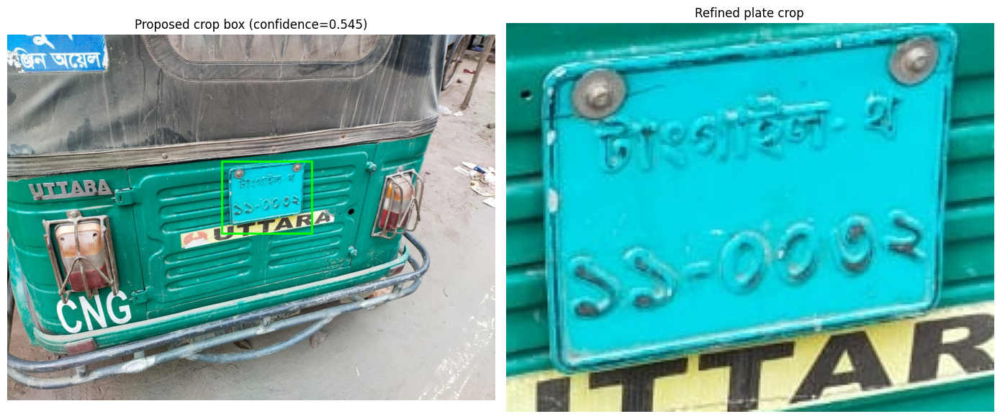

Proposed crop dimensions: (188, 236)
Crop coordinates: (563, 332, 799, 520)


In [108]:
# ============================================================
# STEP 19.2 - Refine plate_0046 and standardize the 67 images
# ============================================================

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

LP_MODEL_PATH = (
    "/kaggle/working/lp_detection_training/"
    "license_plate_yolov8n/weights/best.pt"
)

OUT_DIR = "/kaggle/working/real_faded_standardized"
TARGET_ID = "plate_0046"

# Crop adjustments; tune after inspecting the preview.
SIDE_PADDING = 0.02
TOP_PADDING = 0.02
BOTTOM_TRIM = -0.10

assert len(real_images) == 67, (
    f"Expected 67 images, got {len(real_images)}"
)

target_matches = [
    p for p in real_images
    if os.path.splitext(os.path.basename(p))[0] == TARGET_ID
]

assert len(target_matches) == 1, (
    f"Could not uniquely locate {TARGET_ID}"
)

target_path = target_matches[0]

# Detect the plate again.
lp_model = YOLO(LP_MODEL_PATH)

result = lp_model.predict(
    source=target_path,
    conf=0.15,
    imgsz=640,
    device=0,
    verbose=False
)[0]

assert result.boxes is not None and len(result.boxes) > 0, (
    "No plate detected. Do not create the crop automatically."
)

# Choose the highest-confidence detection.
scores = result.boxes.conf.cpu().numpy()
best_idx = int(np.argmax(scores))

bx1, by1, bx2, by2 = (
    result.boxes.xyxy[best_idx].cpu().numpy()
)

confidence = float(scores[best_idx])

image = cv2.imread(target_path)
assert image is not None, "Cannot read plate_0046."

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
H, W = image_rgb.shape[:2]

box_w = bx2 - bx1
box_h = by2 - by1

# Add a small margin on the sides and top.
x1 = max(0, int(round(bx1 - SIDE_PADDING * box_w)))
x2 = min(W, int(round(bx2 + SIDE_PADDING * box_w)))
y1 = max(0, int(round(by1 - TOP_PADDING * box_h)))

# Tighten the bottom edge to exclude the lettering below the plate.
y2 = min(H, int(round(by2 - BOTTOM_TRIM * box_h)))

assert x2 > x1 and y2 > y1, "Invalid proposed crop."

crop_rgb = image_rgb[y1:y2, x1:x2]

# Preview before accepting the crop.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image_rgb)
axes[0].add_patch(
    plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="lime", linewidth=2
    )
)
axes[0].set_title(
    f"Proposed crop box (confidence={confidence:.3f})"
)
axes[0].axis("off")

axes[1].imshow(crop_rgb)
axes[1].set_title("Refined plate crop")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Proposed crop dimensions:", crop_rgb.shape[:2])
print("Crop coordinates:", (x1, y1, x2, y2))

In [109]:
# ============================================================
# STEP 19.3 - Save standardized test images
# ============================================================

# Recreate only this generated output folder.
if os.path.exists(OUT_DIR):
    shutil.rmtree(OUT_DIR)

os.makedirs(OUT_DIR, exist_ok=True)

saved = 0

for source_path in real_images:

    image_id = os.path.splitext(
        os.path.basename(source_path)
    )[0]

    if image_id == TARGET_ID:
        # Save the refined crop.
        output_path = os.path.join(
            OUT_DIR,
            f"{TARGET_ID}.jpg"
        )

        Image.fromarray(crop_rgb).save(
            output_path,
            quality=95
        )

    else:
        # Preserve the other 66 images without recropping.
        output_path = os.path.join(
            OUT_DIR,
            os.path.basename(source_path)
        )

        shutil.copy2(
            source_path,
            output_path
        )

    saved += 1

# Verify the saved dataset.
standardized_images = [
    os.path.join(OUT_DIR, name)
    for name in os.listdir(OUT_DIR)
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
]

standardized_ids = {
    os.path.splitext(os.path.basename(p))[0]
    for p in standardized_images
}

print("Images saved:", saved)
print("Images in standardized folder:", len(standardized_images))
print("plate_0046 saved:", TARGET_ID in standardized_ids)

assert len(standardized_images) == 67, (
    "Expected exactly 67 standardized images."
)

assert TARGET_ID in standardized_ids

Images saved: 67
Images in standardized folder: 67
plate_0046 saved: True


In [110]:
# ============================================================
# STEP 19.4 - Re-evaluate Model A vs Model B on standardized
#             real faded plates
# ============================================================

import os
import re
import glob
import cv2
import numpy as np
import pandas as pd

from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

STANDARD_ROOT = "/kaggle/working/real_faded_standardized"

MODEL_A_PATH = (
    "/kaggle/working/lpr_training/"
    "model_A_baseline/weights/best.pt"
)

MODEL_B_PATH = (
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

GT_PATH = "/kaggle/working/real_faded_ground_truth_roman.csv"

OUTPUT_ROOT = "/kaggle/working/real_faded_final_evaluation"
os.makedirs(OUTPUT_ROOT, exist_ok=True)

for path in [MODEL_A_PATH, MODEL_B_PATH, GT_PATH]:
    assert os.path.exists(path), f"Required file not found: {path}"

# ------------------------------------------------------------
# 2. Load images and ground truth
# ------------------------------------------------------------

standardized_images = sorted([
    p
    for p in glob.glob(os.path.join(STANDARD_ROOT, "*"))
    if os.path.isfile(p)
    and os.path.splitext(p)[1].lower() in (".jpg", ".jpeg", ".png")
])

assert len(standardized_images) == 67, (
    f"Expected 67 standardized images; found {len(standardized_images)}. "
    "Check Step 19.3."
)

gt_df = pd.read_csv(GT_PATH, encoding="utf-8-sig")
gt_df["image"] = gt_df["image"].astype(str).str.strip()
gt_df["ground_truth"] = gt_df["ground_truth"].fillna("").astype(str)

gt_lookup = dict(zip(gt_df["image"], gt_df["ground_truth"]))

print("Standardized images:", len(standardized_images))
print("Ground-truth entries:", len(gt_df))
print(
    "Labeled images:",
    sum(bool(gt_lookup.get(os.path.splitext(os.path.basename(p))[0], "").strip())
        for p in standardized_images)
)

# ------------------------------------------------------------
# 3. Load trained models
# ------------------------------------------------------------

model_A = YOLO(MODEL_A_PATH)
model_B = YOLO(MODEL_B_PATH)

names_A = model_A.names
names_B = model_B.names

def names_as_list(names):
    if isinstance(names, dict):
        return [names[i] for i in range(len(names))]
    return list(names)

CLASS_NAMES = names_as_list(names_A)

assert CLASS_NAMES == names_as_list(names_B), (
    "Model A and Model B class names/order do not match."
)

print("\nBoth character models loaded.")
print("Number of character/word classes:", len(CLASS_NAMES))

# ------------------------------------------------------------
# 4. Run model predictions and save bounding-box information
# ------------------------------------------------------------

def run_detector(model, image_paths, model_label, conf=0.25):
    rows = []

    for index, image_path in enumerate(image_paths, start=1):

        result = model.predict(
            source=image_path,
            conf=conf,
            imgsz=640,
            device=0,
            verbose=False
        )[0]

        image_id = os.path.splitext(
            os.path.basename(image_path)
        )[0]

        if result.boxes is not None:
            boxes = result.boxes

            for j in range(len(boxes)):
                cls_id = int(boxes.cls[j].item())
                confidence = float(boxes.conf[j].item())

                x1, y1, x2, y2 = (
                    boxes.xyxy[j].cpu().numpy().tolist()
                )

                rows.append({
                    "image": os.path.basename(image_path),
                    "image_id": image_id,
                    "class_id": cls_id,
                    "class_name": str(CLASS_NAMES[cls_id]),
                    "confidence": confidence,
                    "x1": float(x1),
                    "y1": float(y1),
                    "x2": float(x2),
                    "y2": float(y2),
                    "center_x": float((x1 + x2) / 2),
                    "center_y": float((y1 + y2) / 2),
                    "width": float(x2 - x1),
                    "height": float(y2 - y1)
                })

        if index % 10 == 0 or index == len(image_paths):
            print(f"{model_label}: {index}/{len(image_paths)} images")

    return pd.DataFrame(rows, columns=[
        "image", "image_id", "class_id", "class_name",
        "confidence", "x1", "y1", "x2", "y2",
        "center_x", "center_y", "width", "height"
    ])


pred_A_new = run_detector(
    model_A, standardized_images, "Model A"
)

pred_B_new = run_detector(
    model_B, standardized_images, "Model B"
)

pred_A_new.to_csv(
    os.path.join(OUTPUT_ROOT, "model_A_detections.csv"),
    index=False, encoding="utf-8-sig"
)

pred_B_new.to_csv(
    os.path.join(OUTPUT_ROOT, "model_B_detections.csv"),
    index=False, encoding="utf-8-sig"
)

print("\nDetection counts:")
print("Model A:", len(pred_A_new))
print("Model B:", len(pred_B_new))

# ------------------------------------------------------------
# 5. Structure-aware registration-number decoder
# ------------------------------------------------------------

DIGIT_CLASSES = {str(i) for i in range(10)}

PLACE_CLASSES = {
    "dhaka", "khulna", "chattogram", "jashore"
}

METRO_CLASS = "metro"

LETTER_CLASSES = (
    set(CLASS_NAMES)
    - DIGIT_CLASSES
    - PLACE_CLASSES
    - {METRO_CLASS}
)


def decode_registration(
    detections,
    image_height,
    image_width,
    confidence_threshold=0.25
):
    """
    Preliminary structural decoder for the six registration
    digits. This does not claim full plate or matra recognition.
    """

    df = detections[
        detections["confidence"] >= confidence_threshold
    ].copy()

    digit_df = df[
        df["class_name"].isin(DIGIT_CLASSES)
    ].copy()

    # Limit duplicate/false-positive digits as a simple baseline.
    if len(digit_df) > 6:
        digit_df = digit_df.nlargest(6, "confidence").copy()

    # Registration digits run left-to-right.
    digit_df = digit_df.sort_values("center_x")

    digits_raw = "".join(digit_df["class_name"].tolist())
    complete = len(digits_raw) == 6

    registration = (
        digits_raw[:2] + "-" + digits_raw[2:]
        if complete else digits_raw
    )

    # Detect location/category words.
    word_df = df[
        df["class_name"].isin(PLACE_CLASSES | {METRO_CLASS})
    ].copy()

    if not word_df.empty:
        word_df = (
            word_df.sort_values("confidence", ascending=False)
            .drop_duplicates(subset=["class_name"])
            .sort_values("center_x")
        )

    prefix = " ".join(word_df["class_name"].tolist())

    # Estimate the series-letter class.
    letter_df = df[
        df["class_name"].isin(LETTER_CLASSES)
    ].copy()

    if not digit_df.empty and not letter_df.empty:
        median_digit_y = float(digit_df["center_y"].median())
        first_digit_x = float(digit_df["center_x"].min())

        y_tolerance = max(
            0.20 * image_height,
            1.5 * float(digit_df["height"].median())
        )

        letter_df = letter_df[
            (letter_df["center_y"] - median_digit_y).abs()
            <= y_tolerance
        ]

        letter_df = letter_df[
            letter_df["center_x"]
            < first_digit_x + 0.08 * image_width
        ]

    if not letter_df.empty:
        letter = str(
            letter_df.loc[
                letter_df["confidence"].idxmax(),
                "class_name"
            ]
        )
    else:
        letter = ""

    if prefix and letter:
        head = f"{prefix}-{letter}"
    else:
        head = prefix or letter

    if head and registration:
        candidate = f"{head} {registration}"
    else:
        candidate = head or registration

    return {
        "candidate": candidate,
        "registration": registration,
        "digits_raw": digits_raw,
        "digit_count": len(digit_df),
        "complete": complete
    }

# ------------------------------------------------------------
# 6. Decode every image for both models
# ------------------------------------------------------------

decoded_rows = []

for image_path in standardized_images:

    image_id = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        print("WARNING: unreadable image:", image_path)
        continue

    h, w = image_bgr.shape[:2]

    detections_A = pred_A_new[
        pred_A_new["image_id"] == image_id
    ]

    detections_B = pred_B_new[
        pred_B_new["image_id"] == image_id
    ]

    dec_A = decode_registration(detections_A, h, w)
    dec_B = decode_registration(detections_B, h, w)

    decoded_rows.append({
        "image": image_id,
        "ground_truth": gt_lookup.get(image_id, ""),

        "A_candidate": dec_A["candidate"],
        "A_registration": dec_A["registration"],
        "A_digits_raw": dec_A["digits_raw"],
        "A_digit_count": dec_A["digit_count"],
        "A_complete": dec_A["complete"],

        "B_candidate": dec_B["candidate"],
        "B_registration": dec_B["registration"],
        "B_digits_raw": dec_B["digits_raw"],
        "B_digit_count": dec_B["digit_count"],
        "B_complete": dec_B["complete"]
    })

decoded_new = pd.DataFrame(decoded_rows)

# ------------------------------------------------------------
# 7. Calculate registration-number accuracy and CER
# ------------------------------------------------------------

def extract_gt_registration(text):
    match = re.search(r"(\d{2})-(\d{4})\s*$", str(text).strip())
    return match.group(1) + match.group(2) if match else ""


def extract_digits(text):
    return re.sub(r"\D", "", str(text))


def levenshtein_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[j - 1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))

        previous = current

    return previous[-1]


decoded_new["GT_digits"] = (
    decoded_new["ground_truth"].apply(extract_gt_registration)
)

for model_prefix in ["A", "B"]:

    pred_col = f"{model_prefix}_registration"

    decoded_new[f"{model_prefix}_pred_digits"] = (
        decoded_new[pred_col].apply(extract_digits)
    )

    decoded_new[f"{model_prefix}_exact"] = (
        decoded_new[f"{model_prefix}_pred_digits"]
        == decoded_new["GT_digits"]
    )

    decoded_new[f"{model_prefix}_edit_distance"] = (
        decoded_new.apply(
            lambda row: (
                levenshtein_distance(
                    row["GT_digits"],
                    row[f"{model_prefix}_pred_digits"]
                )
                if row["GT_digits"] else np.nan
            ),
            axis=1
        )
    )

    decoded_new[f"{model_prefix}_digit_CER"] = (
        decoded_new.apply(
            lambda row: (
                row[f"{model_prefix}_edit_distance"]
                / len(row["GT_digits"])
                if row["GT_digits"] else np.nan
            ),
            axis=1
        )
    )

eval_df = decoded_new[
    decoded_new["GT_digits"].ne("")
].copy()

summary = []

for model_prefix in ["A", "B"]:

    complete_count = int(
        eval_df[f"{model_prefix}_complete"].sum()
    )

    exact_correct = int(
        eval_df[f"{model_prefix}_exact"].sum()
    )

    summary.append({
        "model": model_prefix,
        "labeled_images": len(eval_df),
        "complete_numbers": complete_count,
        "exact_correct": exact_correct,

        # All labeled images are the denominator; incomplete
        # or wrong predictions count as incorrect.
        "strict_exact_accuracy": round(
            exact_correct / len(eval_df), 4
        ) if len(eval_df) else np.nan,

        # Conditional accuracy among complete number outputs.
        "conditional_exact_accuracy": round(
            exact_correct / complete_count, 4
        ) if complete_count else np.nan,

        "mean_digit_CER": round(
            float(eval_df[f"{model_prefix}_digit_CER"].mean()), 4
        ) if len(eval_df) else np.nan
    })

metrics_new = pd.DataFrame(summary)

# ------------------------------------------------------------
# 8. Save final comparison tables
# ------------------------------------------------------------

RESULTS_CSV = os.path.join(
    OUTPUT_ROOT,
    "model_A_vs_B_standardized_results.csv"
)

METRICS_CSV = os.path.join(
    OUTPUT_ROOT,
    "registration_metrics.csv"
)

decoded_new.to_csv(
    RESULTS_CSV, index=False, encoding="utf-8-sig"
)

metrics_new.to_csv(
    METRICS_CSV, index=False, encoding="utf-8-sig"
)

print("\n========================================")
print("STANDARDIZED REAL-FADED TEST RESULTS")
print("========================================")
display(metrics_new)

print("\nFirst 20 plate results:")
display(
    decoded_new[
        [
            "image", "ground_truth",
            "A_registration", "B_registration",
            "A_exact", "B_exact"
        ]
    ].head(20)
)

print("\nSaved result files:")
print(RESULTS_CSV)
print(METRICS_CSV)
print(os.path.join(OUTPUT_ROOT, "model_A_detections.csv"))
print(os.path.join(OUTPUT_ROOT, "model_B_detections.csv"))

Standardized images: 67
Ground-truth entries: 67
Labeled images: 64

Both character models loaded.
Number of character/word classes: 27
Model A: 10/67 images
Model A: 20/67 images
Model A: 30/67 images
Model A: 40/67 images
Model A: 50/67 images
Model A: 60/67 images
Model A: 67/67 images
Model B: 10/67 images
Model B: 20/67 images
Model B: 30/67 images
Model B: 40/67 images
Model B: 50/67 images
Model B: 60/67 images
Model B: 67/67 images

Detection counts:
Model A: 556
Model B: 557

STANDARDIZED REAL-FADED TEST RESULTS


,model,labeled_images,complete_numbers,exact_correct,strict_exact_accuracy,conditional_exact_accuracy,mean_digit_CER
0,A,64,54,30,0.4688,0.5556,0.1849
1,B,64,55,43,0.6719,0.7818,0.0807



First 20 plate results:


,image,ground_truth,A_registration,B_registration,A_exact,B_exact
0,plate_0001,khulna metro-la 11-6328,11-6328,11-6328,True,True
1,plate_0002,,230,232,False,False
2,plate_0003,dhaka metro-u 20-5938,20-5938,20-5938,True,True
3,plate_0004,dhaka metro-ga 31-8763,31-8763,31-8763,True,True
4,plate_0005,dhaka metro-ba 14-8351,148,14853,False,False
5,plate_0006,dhaka metro-ga 20-1300,20-1300,20-1300,True,True
6,plate_0007,dhaka metro-na 11-1335,11-1435,11-1335,False,True
7,plate_0008,dhaka metro-ha 14-9803,14-9806,14-9803,False,True
8,plate_0009,dhaka metro-u 12-1205,12-1215,12124,False,False
9,plate_0010,dhaka metro-sha 11-0361,11062,11-0861,False,False



Saved result files:
/kaggle/working/real_faded_final_evaluation/model_A_vs_B_standardized_results.csv
/kaggle/working/real_faded_final_evaluation/registration_metrics.csv
/kaggle/working/real_faded_final_evaluation/model_A_detections.csv
/kaggle/working/real_faded_final_evaluation/model_B_detections.csv


In [118]:
# ============================================================
# STEP 20.1 - Load standardized evaluation results
# ============================================================

import os
import pandas as pd
import numpy as np

OUTPUT_ROOT = "/kaggle/working/real_faded_final_evaluation"

RESULTS_CSV = os.path.join(
    OUTPUT_ROOT,
    "model_A_vs_B_standardized_results.csv"
)

METRICS_CSV = os.path.join(
    OUTPUT_ROOT,
    "registration_metrics.csv"
)

assert os.path.exists(RESULTS_CSV), "Results CSV not found."
assert os.path.exists(METRICS_CSV), "Metrics CSV not found."

results_df = pd.read_csv(
    RESULTS_CSV,
    encoding="utf-8-sig"
)

metrics_df = pd.read_csv(
    METRICS_CSV,
    encoding="utf-8-sig"
)

print("Evaluation records:", len(results_df))
print("\nRegistration metrics:")
display(metrics_df)

print("\nFirst 10 predictions:")
display(
    results_df[
        [
            "image",
            "ground_truth",
            "A_registration",
            "B_registration"
        ]
    ].head(10)
)

Evaluation records: 67

Registration metrics:


,model,labeled_images,complete_numbers,exact_correct,strict_exact_accuracy,conditional_exact_accuracy,mean_digit_CER
0,A,64,54,30,0.4688,0.5556,0.1849
1,B,64,55,43,0.6719,0.7818,0.0807



First 10 predictions:


,image,ground_truth,A_registration,B_registration
0,plate_0001,khulna metro-la 11-6328,11-6328,11-6328
1,plate_0002,NaN,230,232
2,plate_0003,dhaka metro-u 20-5938,20-5938,20-5938
3,plate_0004,dhaka metro-ga 31-8763,31-8763,31-8763
4,plate_0005,dhaka metro-ba 14-8351,148,14853
5,plate_0006,dhaka metro-ga 20-1300,20-1300,20-1300
6,plate_0007,dhaka metro-na 11-1335,11-1435,11-1335
7,plate_0008,dhaka metro-ha 14-9803,14-9806,14-9803
8,plate_0009,dhaka metro-u 12-1205,12-1215,12124
9,plate_0010,dhaka metro-sha 11-0361,11062,11-0861


In [119]:
# ============================================================
# STEP 20.2 - Paired error analysis
# ============================================================

import re

eval_df = results_df[
    results_df["ground_truth"].fillna("").str.strip().ne("")
].copy()

def extract_registration(text):
    match = re.search(
        r"(\d{2})-(\d{4})\s*$",
        str(text).strip()
    )
    return match.group(1) + match.group(2) if match else ""

def digits_only(text):
    return re.sub(r"\D", "", str(text))

eval_df["GT_digits"] = (
    eval_df["ground_truth"].apply(extract_registration)
)

eval_df["A_pred_digits"] = (
    eval_df["A_registration"].fillna("").apply(digits_only)
)

eval_df["B_pred_digits"] = (
    eval_df["B_registration"].fillna("").apply(digits_only)
)

# Exclude any label that does not contain a valid registration number.
eval_df = eval_df[
    eval_df["GT_digits"].str.len().eq(6)
].copy()

eval_df["A_correct"] = (
    eval_df["A_pred_digits"] == eval_df["GT_digits"]
)

eval_df["B_correct"] = (
    eval_df["B_pred_digits"] == eval_df["GT_digits"]
)

both_correct = int(
    (eval_df["A_correct"] & eval_df["B_correct"]).sum()
)

A_only = int(
    (eval_df["A_correct"] & ~eval_df["B_correct"]).sum()
)

B_only = int(
    (~eval_df["A_correct"] & eval_df["B_correct"]).sum()
)

both_wrong = int(
    (~eval_df["A_correct"] & ~eval_df["B_correct"]).sum()
)

paired_table = pd.DataFrame({
    "Outcome": [
        "Both models correct",
        "Only Model A correct",
        "Only Model B correct",
        "Both models wrong"
    ],
    "Number of images": [
        both_correct,
        A_only,
        B_only,
        both_wrong
    ]
})

display(paired_table)

n = len(eval_df)

accuracy_A = eval_df["A_correct"].mean()
accuracy_B = eval_df["B_correct"].mean()

print(f"\nLabeled images evaluated: {n}")
print(f"Model A strict exact accuracy: {accuracy_A:.2%}")
print(f"Model B strict exact accuracy: {accuracy_B:.2%}")
print(
    "Absolute change:",
    f"{(accuracy_B - accuracy_A) * 100:+.2f} percentage points"
)

,Outcome,Number of images
0,Both models correct,29
1,Only Model A correct,1
2,Only Model B correct,14
3,Both models wrong,20



Labeled images evaluated: 64
Model A strict exact accuracy: 46.88%
Model B strict exact accuracy: 67.19%
Absolute change: +20.31 percentage points


In [121]:
# ============================================================
# STEP 20.3 - Exact paired McNemar test
# ============================================================

from scipy.stats import binomtest

discordant = A_only + B_only

if discordant == 0:
    p_value = 1.0
    print("The models have identical correctness outcomes.")
else:
    p_value = binomtest(
        k=B_only,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue

print("Model A only correct:", A_only)
print("Model B only correct:", B_only)
print("Discordant cases:", discordant)
print(f"Exact McNemar p-value: {p_value:.6f}")

if p_value < 0.05:
    print(
        "The paired difference is statistically significant "
        "at the 0.05 level."
    )
else:
    print(
        "The paired difference is not statistically significant "
        "at the 0.05 level."
    )

Model A only correct: 1
Model B only correct: 14
Discordant cases: 15
Exact McNemar p-value: 0.000977
The paired difference is statistically significant at the 0.05 level.


In [122]:
# ============================================================
# STEP 20.4 - Save improved and regressed examples
# ============================================================

improved = eval_df[
    ~eval_df["A_correct"] & eval_df["B_correct"]
].copy()

regressed = eval_df[
    eval_df["A_correct"] & ~eval_df["B_correct"]
].copy()

still_wrong = eval_df[
    ~eval_df["A_correct"] & ~eval_df["B_correct"]
].copy()

cols = [
    "image",
    "ground_truth",
    "A_pred_digits",
    "B_pred_digits",
    "A_correct",
    "B_correct"
]

print("Cases improved by Model B:", len(improved))
display(improved[cols])

print("\nCases where Model B regressed:", len(regressed))
display(regressed[cols])

print("\nCases where both models remain wrong:", len(still_wrong))
display(still_wrong[cols].head(20))

improved.to_csv(
    os.path.join(OUTPUT_ROOT, "model_B_improved_cases.csv"),
    index=False,
    encoding="utf-8-sig"
)

regressed.to_csv(
    os.path.join(OUTPUT_ROOT, "model_B_regressed_cases.csv"),
    index=False,
    encoding="utf-8-sig"
)

still_wrong.to_csv(
    os.path.join(OUTPUT_ROOT, "both_models_wrong_cases.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nError-analysis CSVs saved to:", OUTPUT_ROOT)

Cases improved by Model B: 14


,image,ground_truth,A_pred_digits,B_pred_digits,A_correct,B_correct
6,plate_0007,dhaka metro-na 11-1335,111435,111335,False,True
7,plate_0008,dhaka metro-ha 14-9803,149806,149803,False,True
11,plate_0012,dhaka metro-ta 18-8537,188567,188537,False,True
14,plate_0015,dhaka metro-ma 13-0558,1658,130558,False,True
21,plate_0022,dhaka metro-ga 22-4218,211218,224218,False,True
22,plate_0023,dhaka metro-ga 31-3134,31134,313134,False,True
24,plate_0025,dhaka metro-sa 11-0333,11040,110333,False,True
29,plate_0030,dhaka metro-ga 19-7556,1956,197556,False,True
34,plate_0035,dhaka metro-ga 23-3442,263442,233442,False,True
41,plate_0042,dhaka metro-ga 21-8571,111,218571,False,True



Cases where Model B regressed: 1


,image,ground_truth,A_pred_digits,B_pred_digits,A_correct,B_correct
65,plate_0066,gazipur-ja 04-0315,040315,04031,True,False



Cases where both models remain wrong: 20


,image,ground_truth,A_pred_digits,B_pred_digits,A_correct,B_correct
4,plate_0005,dhaka metro-ba 14-8351,148,14853,False,False
8,plate_0009,dhaka metro-u 12-1205,121215,12124,False,False
9,plate_0010,dhaka metro-sha 11-0361,11062,110861,False,False
10,plate_0011,dhaka metro-ca 63-5149,630119,630149,False,False
12,plate_0013,dhaka metro-kha 21-4286,112186,21286,False,False
18,plate_0019,dhaka metro-kha 13-5016,148496,13016,False,False
20,plate_0021,dhaka kha 11-1119,110199,111619,False,False
23,plate_0024,dhaka metro-tha 15-0902,09012,10102,False,False
28,plate_0029,dhaka metro-na 13-6315,114919,134315,False,False
32,plate_0033,dhaka metro-na 14-1336,141468,141338,False,False



Error-analysis CSVs saved to: /kaggle/working/real_faded_final_evaluation


In [117]:
# ============================================================
# STEP 21 - Audit ground-truth coverage by model vocabulary
# ============================================================

import os
import re
import pandas as pd
from collections import Counter

GT_PATH = "/kaggle/working/real_faded_ground_truth_roman.csv"

assert os.path.exists(GT_PATH), f"Missing file: {GT_PATH}"

roman_df = pd.read_csv(GT_PATH, encoding="utf-8-sig")
roman_df["ground_truth"] = roman_df["ground_truth"].fillna("").astype(str)

# Ensure the class vocabulary matches the trained model.
MODEL_CLASSES = set(str(name).lower() for name in CLASS_NAMES)

DIGITS = {str(i) for i in range(10)}
KNOWN_WORD_CLASSES = {
    "dhaka", "khulna", "chattogram", "jashore", "metro"
}

# Remaining non-digit classes are potential series-character classes.
SERIES_CLASSES = MODEL_CLASSES - DIGITS - KNOWN_WORD_CLASSES


def parse_plate_label(text):
    """
    Expected Roman label examples:
      dhaka metro-ga 31-8763
      khulna metro-la 11-6328
      gazipur-kha 11-0843
    """
    text = str(text).strip().lower()

    match = re.match(r"^(.*?)\s+(\d{2}-\d{4})$", text)

    if not match:
        return {
            "prefix": "",
            "place_tokens": "",
            "series_label": "",
            "registration": "",
            "valid_format": False
        }

    header = match.group(1).strip()
    registration = match.group(2)

    # Series label is the final alphabetic token after the hyphen.
    series_match = re.search(r"-([a-z]+)$", header)

    if series_match:
        series = series_match.group(1)
        prefix = header[:series_match.start()].strip()
    else:
        series = ""
        prefix = header

    # Remove words already represented as category/classes.
    place_tokens = [
        token for token in prefix.split()
        if token not in {"metro"}
    ]

    return {
        "prefix": prefix,
        "place_tokens": " ".join(place_tokens),
        "series_label": series,
        "registration": registration,
        "valid_format": True
    }


rows = []

for _, row in roman_df.iterrows():

    image_id = str(row["image"]).strip()
    text = row["ground_truth"]

    if not text.strip():
        continue

    parts = parse_plate_label(text)

    if not parts["valid_format"]:
        rows.append({
            "image": image_id,
            "ground_truth": text,
            **parts,
            "series_supported": False,
            "unsupported_place_words": "CHECK_FORMAT"
        })
        continue

    place_words = parts["place_tokens"].split()

    unsupported_places = [
        word for word in place_words
        if word not in KNOWN_WORD_CLASSES
    ]

    series_supported = (
        parts["series_label"] in SERIES_CLASSES
    )

    rows.append({
        "image": image_id,
        "ground_truth": text,
        **parts,
        "series_supported": series_supported,
        "unsupported_place_words": ", ".join(unsupported_places)
    })


coverage_df = pd.DataFrame(rows)

print("Labeled plates audited:", len(coverage_df))
print("Series-character classes in model:", sorted(SERIES_CLASSES))

print("\nSeries-label frequencies:")
print(coverage_df["series_label"].value_counts().to_string())

print("\nUnsupported series labels:")
unsupported_series = coverage_df[
    ~coverage_df["series_supported"]
]

print(
    unsupported_series["series_label"]
    .value_counts()
    .to_string()
)

print("\nUnsupported regional words:")
unsupported_places = Counter(
    word
    for value in coverage_df["unsupported_place_words"]
    for word in str(value).split(", ")
    if word and word != "CHECK_FORMAT"
)

for word, count in unsupported_places.most_common():
    print(f"{word}: {count}")

AUDIT_PATH = "/kaggle/working/plate_vocabulary_coverage_audit.csv"

coverage_df.to_csv(
    AUDIT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved:", AUDIT_PATH)

display(
    coverage_df[
        [
            "image",
            "ground_truth",
            "series_label",
            "series_supported",
            "unsupported_place_words"
        ]
    ].head(20)
)

Labeled plates audited: 64
Series-character classes in model: ['ba', 'ca', 'da', 'ga', 'gha', 'ha', 'ja', 'ka', 'kha', 'na', 'ta', 'va']

Series-label frequencies:
series_label
tha    11
ja      8
na      8
ga      7
ca      5
la      4
ba      4
ta      4
u       2
sa      2
ma      2
sha     2
ha      1
dha     1
        1
jha     1
kha     1

Unsupported series labels:
series_label
tha    11
la      4
u       2
sha     2
ma      2
sa      2
dha     1
        1
jha     1

Unsupported regional words:
narayanganj: 5
satkhira: 3
gazipur: 2
bhola: 2
tangail: 2
tha: 1
munshiganj: 1
barishal: 1

Saved: /kaggle/working/plate_vocabulary_coverage_audit.csv


,image,ground_truth,series_label,series_supported,unsupported_place_words
0,plate_0001,khulna metro-la 11-6328,la,False,
1,plate_0003,dhaka metro-u 20-5938,u,False,
2,plate_0004,dhaka metro-ga 31-8763,ga,True,
3,plate_0005,dhaka metro-ba 14-8351,ba,True,
4,plate_0006,dhaka metro-ga 20-1300,ga,True,
5,plate_0007,dhaka metro-na 11-1335,na,True,
6,plate_0008,dhaka metro-ha 14-9803,ha,True,
7,plate_0009,dhaka metro-u 12-1205,u,False,
8,plate_0010,dhaka metro-sha 11-0361,sha,False,
9,plate_0011,dhaka metro-dha 63-5149,dha,False,


In [116]:
# ============================================================
# STEP 22.2 - Save FINAL corrected Roman ground truth
# ============================================================

import os
import re
import pandas as pd
import unicodedata

ground_truth = {
    "plate_0001": "khulna metro-la 11-6328",
    "plate_0002": "",
    "plate_0003": "dhaka metro-u 20-5938",
    "plate_0004": "dhaka metro-ga 31-8763",
    "plate_0005": "dhaka metro-ba 14-8351",
    "plate_0006": "dhaka metro-ga 20-1300",
    "plate_0007": "dhaka metro-na 11-1335",
    "plate_0008": "dhaka metro-ha 14-9803",
    "plate_0009": "dhaka metro-u 12-1205",
    "plate_0010": "dhaka metro-sha 11-0361",
    "plate_0011": "dhaka metro-dha 63-5149",
    "plate_0012": "dhaka metro-ta 18-8537",
    "plate_0013": "dhaka metro-tha 21-4286",
    "plate_0014": "dhaka metro-ma 11-0511",
    "plate_0015": "dhaka metro-ma 13-0558",
    "plate_0016": "dhaka metro-ca 51-6865",
    "plate_0017": "dhaka metro-na 20-0124",
    "plate_0018": "dhaka metro-ca 51-8426",
    "plate_0019": "dhaka metro-tha 13-5016",
    "plate_0020": "dhaka metro-na 15-8845",
    "plate_0021": "dhaka tha 11-1119",
    "plate_0022": "dhaka metro-ga 22-4218",
    "plate_0023": "dhaka metro-ga 31-3134",
    "plate_0024": "dhaka metro-tha 15-0902",
    "plate_0025": "dhaka metro-sa 11-0333",
    "plate_0026": "",
    "plate_0027": "dhaka metro-jha 11-0806",
    "plate_0028": "dhaka metro-sa 11-0369",
    "plate_0029": "dhaka metro-na 13-6315",
    "plate_0030": "dhaka metro-ga 19-7556",
    "plate_0031": "dhaka metro-na 11-2419",
    "plate_0032": "dhaka metro-tha 15-0722",
    "plate_0033": "dhaka metro-na 14-1336",
    "plate_0034": "",
    "plate_0035": "dhaka metro-ga 23-3442",
    "plate_0036": "dhaka metro-sha 11-3530",
    "plate_0037": "gazipur-kha 11-0843",
    "plate_0038": "dhaka metro-na 16-7320",
    "plate_0039": "dhaka metro-na 17-6966",
    "plate_0040": "dhaka metro-ca 20-8590",
    "plate_0041": "dhaka metro-ca 11-1711",
    "plate_0042": "dhaka metro-ga 21-8571",
    "plate_0043": "bhola-la 11-0490",
    "plate_0044": "narayanganj-tha 11-0562",
    "plate_0045": "narayanganj-tha 11-3513",
    "plate_0046": "tangail-tha 11-0032",
    "plate_0047": "narayanganj-tha 11-4357",
    "plate_0048": "narayanganj-tha 11-1946",
    "plate_0049": "narayanganj-tha 11-2437",
    "plate_0050": "munshiganj-tha 11-0514",
    "plate_0051": "dhaka metro-ca 13-5683",
    "plate_0052": "bhola-la 11-0490",
    "plate_0053": "dhaka metro-la 25-5985",
    "plate_0054": "barishal-ja 05-0037",
    "plate_0055": "satkhira-ja 11-0004",
    "plate_0056": "satkhira-ja 12-0073",
    "plate_0057": "dhaka metro-ja 11-0383",
    "plate_0058": "tangail-ba 11-0001",
    "plate_0059": "dhaka metro-ba 18-6703",
    "plate_0060": "dhaka metro-ja 14-0816",
    "plate_0061": "dhaka metro-ba 15-3083",
    "plate_0062": "khulna metro-ja 04-0055",
    "plate_0063": "dhaka metro-ta 11-6124",
    "plate_0064": "jashore-ta 11-0870",
    "plate_0065": "jashore-ta 11-1380",
    "plate_0066": "gazipur-ja 04-0315",
    "plate_0067": "satkhira-ja 11-0081",
}

def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text)).lower().strip()
    return re.sub(r"\s+", "", text)

rows = []

for i in range(1, 68):
    image_id = f"plate_{i:04d}"
    text = ground_truth[image_id]

    rows.append({
        "image": image_id,
        "ground_truth": text,
        "normalized_ground_truth": normalize_text(text),
        "has_ground_truth": bool(text.strip())
    })

final_gt_df = pd.DataFrame(rows)

GT_PATH = (
    "/kaggle/working/"
    "real_faded_ground_truth_roman.csv"
)

final_gt_df.to_csv(
    GT_PATH,
    index=False,
    encoding="utf-8-sig"
)

assert len(final_gt_df) == 67
assert final_gt_df["has_ground_truth"].sum() == 64

print("FINAL ground truth saved:", GT_PATH)
print("Total images:", len(final_gt_df))
print("Labeled images:", int(final_gt_df["has_ground_truth"].sum()))
print("Unlabeled images:", int((~final_gt_df["has_ground_truth"]).sum()))

print("\nCorrected entries:")
display(
    final_gt_df[
        final_gt_df["image"].isin([
            "plate_0011", "plate_0013", "plate_0019",
            "plate_0021", "plate_0044", "plate_0045",
            "plate_0046", "plate_0047", "plate_0048",
            "plate_0049", "plate_0050"
        ])
    ][["image", "ground_truth"]]
)

FINAL ground truth saved: /kaggle/working/real_faded_ground_truth_roman.csv
Total images: 67
Labeled images: 64
Unlabeled images: 3

Corrected entries:


,image,ground_truth
10,plate_0011,dhaka metro-dha 63-5149
12,plate_0013,dhaka metro-tha 21-4286
18,plate_0019,dhaka metro-tha 13-5016
20,plate_0021,dhaka tha 11-1119
43,plate_0044,narayanganj-tha 11-0562
44,plate_0045,narayanganj-tha 11-3513
45,plate_0046,tangail-tha 11-0032
46,plate_0047,narayanganj-tha 11-4357
47,plate_0048,narayanganj-tha 11-1946
48,plate_0049,narayanganj-tha 11-2437


In [123]:
# ============================================================
# STEP 23 - Updated vocabulary audit using final ground truth
# ============================================================

import os
import re
import pandas as pd
from collections import Counter

GT_PATH = "/kaggle/working/real_faded_ground_truth_roman.csv"

assert os.path.exists(GT_PATH), "Ground-truth CSV not found."

gt_df = pd.read_csv(GT_PATH, encoding="utf-8-sig")
gt_df["ground_truth"] = gt_df["ground_truth"].fillna("").astype(str)

# The exact class names used by your trained detector
MODEL_CLASSES = {
    "0", "1", "2", "3", "4", "5", "6", "7", "8", "9",
    "ka", "kha", "ga", "gha", "ca", "ja",
    "ta", "da", "na", "ba", "va", "ha",
    "metro", "dhaka", "khulna", "chattogram", "jashore"
}

DIGITS = {str(i) for i in range(10)}
PLACE_CLASSES = {
    "dhaka", "khulna", "chattogram", "jashore"
}
SERIES_CLASSES = MODEL_CLASSES - DIGITS - PLACE_CLASSES - {"metro"}

# Candidate Roman series labels appearing in the supplied ground truth.
KNOWN_SERIES_TOKENS = {
    "ka", "kha", "ga", "gha", "ca", "ja", "ta", "da",
    "na", "ba", "va", "ha", "dha", "tha", "la", "u",
    "sha", "ma", "sa", "jha"
}


def parse_label(text):
    text = str(text).strip().lower()

    match = re.search(r"(\d{2}-\d{4})\s*$", text)

    if not match:
        return {
            "prefix": "",
            "series_label": "",
            "registration": "",
            "valid_format": False
        }

    header = text[:match.start()].strip()
    registration = match.group(1)
    tokens = header.split()

    if not tokens:
        return {
            "prefix": "",
            "series_label": "",
            "registration": registration,
            "valid_format": False
        }

    last = tokens[-1]

    # Examples: "dhaka metro-dha", "narayanganj-tha"
    if "-" in last:
        preceding, series = last.rsplit("-", 1)
        prefix = " ".join(tokens[:-1] + ([preceding] if preceding else []))

    # Example: "dhaka tha" without a hyphen
    elif last in KNOWN_SERIES_TOKENS and len(tokens) > 1:
        series = last
        prefix = " ".join(tokens[:-1])

    else:
        series = ""
        prefix = header

    return {
        "prefix": prefix.strip(),
        "series_label": series.strip(),
        "registration": registration,
        "valid_format": bool(series)
    }


rows = []

for _, row in gt_df.iterrows():

    image_id = str(row["image"]).strip()
    text = row["ground_truth"]

    if not text.strip():
        continue

    parsed = parse_label(text)

    prefix_tokens = [
        token for token in parsed["prefix"].split()
        if token != "metro"
    ]

    unsupported_places = [
        token for token in prefix_tokens
        if token not in PLACE_CLASSES
    ]

    rows.append({
        "image": image_id,
        "ground_truth": text,
        **parsed,
        # Exact class-name comparison only; visual glyph mapping
        # still needs verification using the original XML examples.
        "series_name_in_model_vocab":
            parsed["series_label"] in SERIES_CLASSES,
        "unsupported_place_words":
            ", ".join(unsupported_places)
    })


audit_df = pd.DataFrame(rows)

series_counts = Counter(
    audit_df["series_label"].dropna()
)

unsupported_series = Counter(
    audit_df.loc[
        ~audit_df["series_name_in_model_vocab"],
        "series_label"
    ].dropna()
)

unsupported_places = Counter(
    word
    for value in audit_df["unsupported_place_words"]
    for word in str(value).split(", ")
    if word
)

print("Labeled images audited:", len(audit_df))

print("\nSeries-label frequencies:")
for label, count in series_counts.most_common():
    print(f"{label or '[missing]':12s} {count}")

print("\nSeries tokens not present as exact model class names:")
for label, count in unsupported_series.most_common():
    print(f"{label or '[missing]':12s} {count}")

print("\nUnsupported regional-word frequencies:")
for label, count in unsupported_places.most_common():
    print(f"{label:20s} {count}")

AUDIT_PATH = "/kaggle/working/plate_vocabulary_coverage_audit_final.csv"

audit_df.to_csv(
    AUDIT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved final audit:", AUDIT_PATH)

display(
    audit_df[
        [
            "image",
            "ground_truth",
            "series_label",
            "series_name_in_model_vocab",
            "unsupported_place_words"
        ]
    ].head(20)
)

Labeled images audited: 64

Series-label frequencies:
tha          12
na           8
ja           8
ga           7
ca           5
la           4
ba           4
ta           4
u            2
sha          2
ma           2
sa           2
ha           1
dha          1
jha          1
kha          1

Series tokens not present as exact model class names:
tha          12
la           4
u            2
sha          2
ma           2
sa           2
dha          1
jha          1

Unsupported regional-word frequencies:
narayanganj          5
satkhira             3
gazipur              2
bhola                2
tangail              2
munshiganj           1
barishal             1

Saved final audit: /kaggle/working/plate_vocabulary_coverage_audit_final.csv


,image,ground_truth,series_label,series_name_in_model_vocab,unsupported_place_words
0,plate_0001,khulna metro-la 11-6328,la,False,
1,plate_0003,dhaka metro-u 20-5938,u,False,
2,plate_0004,dhaka metro-ga 31-8763,ga,True,
3,plate_0005,dhaka metro-ba 14-8351,ba,True,
4,plate_0006,dhaka metro-ga 20-1300,ga,True,
5,plate_0007,dhaka metro-na 11-1335,na,True,
6,plate_0008,dhaka metro-ha 14-9803,ha,True,
7,plate_0009,dhaka metro-u 12-1205,u,False,
8,plate_0010,dhaka metro-sha 11-0361,sha,False,
9,plate_0011,dhaka metro-dha 63-5149,dha,False,


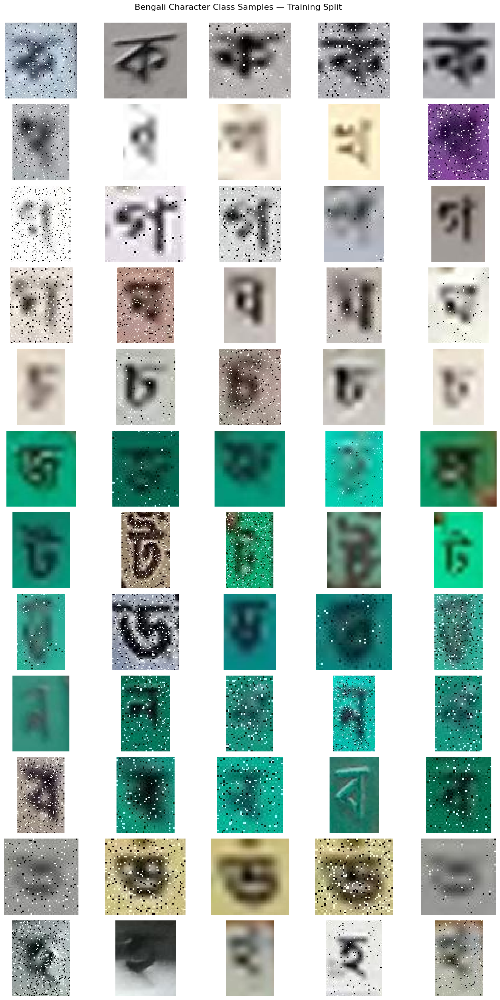

Gallery saved: /kaggle/working/bengali_character_class_audit.png

Class annotations encountered during the scan:
ka    | visual examples: 5 | instances encountered: 8
kha   | visual examples: 5 | instances encountered: 31
ga    | visual examples: 5 | instances encountered: 294
gha   | visual examples: 5 | instances encountered: 55
ca    | visual examples: 5 | instances encountered: 17
ja    | visual examples: 5 | instances encountered: 59
ta    | visual examples: 5 | instances encountered: 68
da    | visual examples: 5 | instances encountered: 13
na    | visual examples: 5 | instances encountered: 8
ba    | visual examples: 5 | instances encountered: 63
va    | visual examples: 5 | instances encountered: 5
ha    | visual examples: 5 | instances encountered: 21


In [124]:
# ============================================================
# STEP 24.1 - Visual audit of existing Bengali character classes
# Training split only; does not use the real faded test set
# ============================================================

import os
import glob
import random
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import matplotlib.pyplot as plt

CHAR_ROOT = (
    "/kaggle/input/datasets/"
    "syednahinhossain/"
    "bangladeshi-license-plate-recognition-dataset/"
    "Character Recognition"
)

TRAIN_DIR = os.path.join(CHAR_ROOT, "train")

TARGET_CLASSES = [
    "ka", "kha", "ga", "gha",
    "ca", "ja", "ta", "da",
    "na", "ba", "va", "ha"
]

EXAMPLES_PER_CLASS = 5
SEED = 42

random.seed(SEED)

# Randomize the source XML files so the gallery isn't always
# made from the earliest filenames.
xml_files = glob.glob(os.path.join(TRAIN_DIR, "*.xml"))
random.shuffle(xml_files)

examples = {name: [] for name in TARGET_CLASSES}
instance_counts = {name: 0 for name in TARGET_CLASSES}

def locate_image(xml_path):
    """Find an image sharing the XML file's stem."""
    stem = os.path.splitext(xml_path)[0]

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        candidate = stem + ext
        if os.path.exists(candidate):
            return candidate

    return None


for xml_path in xml_files:

    # Stop only after collecting enough visual samples per class.
    if all(
        len(examples[name]) >= EXAMPLES_PER_CLASS
        for name in TARGET_CLASSES
    ):
        break

    image_path = locate_image(xml_path)

    if image_path is None:
        continue

    image = cv2.imread(image_path)

    if image is None:
        continue

    height, width = image.shape[:2]

    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        continue

    for obj in root.findall("object"):

        name_node = obj.find("name")
        bbox = obj.find("bndbox")

        if name_node is None or bbox is None:
            continue

        name = name_node.text.strip()

        if name not in TARGET_CLASSES:
            continue

        instance_counts[name] += 1

        if len(examples[name]) >= EXAMPLES_PER_CLASS:
            continue

        try:
            xmin = int(float(bbox.find("xmin").text))
            ymin = int(float(bbox.find("ymin").text))
            xmax = int(float(bbox.find("xmax").text))
            ymax = int(float(bbox.find("ymax").text))
        except (AttributeError, ValueError, TypeError):
            continue

        xmin = max(0, min(xmin, width))
        xmax = max(0, min(xmax, width))
        ymin = max(0, min(ymin, height))
        ymax = max(0, min(ymax, height))

        if xmax <= xmin or ymax <= ymin:
            continue

        crop = cv2.cvtColor(
            image[ymin:ymax, xmin:xmax],
            cv2.COLOR_BGR2RGB
        )

        if crop.size == 0:
            continue

        examples[name].append(crop.copy())


# ------------------------------------------------------------
# Display each class and five representative crops
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(TARGET_CLASSES),
    EXAMPLES_PER_CLASS,
    figsize=(15, 27)
)

for row, class_name in enumerate(TARGET_CLASSES):

    for col in range(EXAMPLES_PER_CLASS):

        ax = axes[row, col]
        ax.axis("off")

        if col < len(examples[class_name]):

            crop = examples[class_name][col]

            ax.imshow(crop, interpolation="nearest")

            if col == 0:
                ax.set_ylabel(
                    class_name,
                    fontsize=12,
                    rotation=0,
                    labelpad=35,
                    va="center"
                )

        elif col == 0:
            ax.set_ylabel(
                class_name,
                fontsize=12,
                rotation=0,
                labelpad=35,
                va="center"
            )

plt.suptitle(
    "Bengali Character Class Samples — Training Split",
    fontsize=16
)

plt.tight_layout(rect=[0.04, 0, 1, 0.98])

GALLERY_PATH = (
    "/kaggle/working/"
    "bengali_character_class_audit.png"
)

plt.savefig(
    GALLERY_PATH,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Gallery saved:", GALLERY_PATH)
print("\nClass annotations encountered during the scan:")

for name in TARGET_CLASSES:
    print(
        f"{name:5s} | "
        f"visual examples: {len(examples[name])} | "
        f"instances encountered: {instance_counts[name]}"
    )

Scanned 1000/3480 XML files
Scanned 2000/3480 XML files
Scanned 3000/3480 XML files

Best examples selected per class:
ka   : 5 examples
kha  : 5 examples
ga   : 5 examples
gha  : 5 examples
ca   : 5 examples
ja   : 5 examples
ta   : 5 examples
da   : 5 examples
na   : 5 examples
ba   : 5 examples
va   : 5 examples
ha   : 5 examples


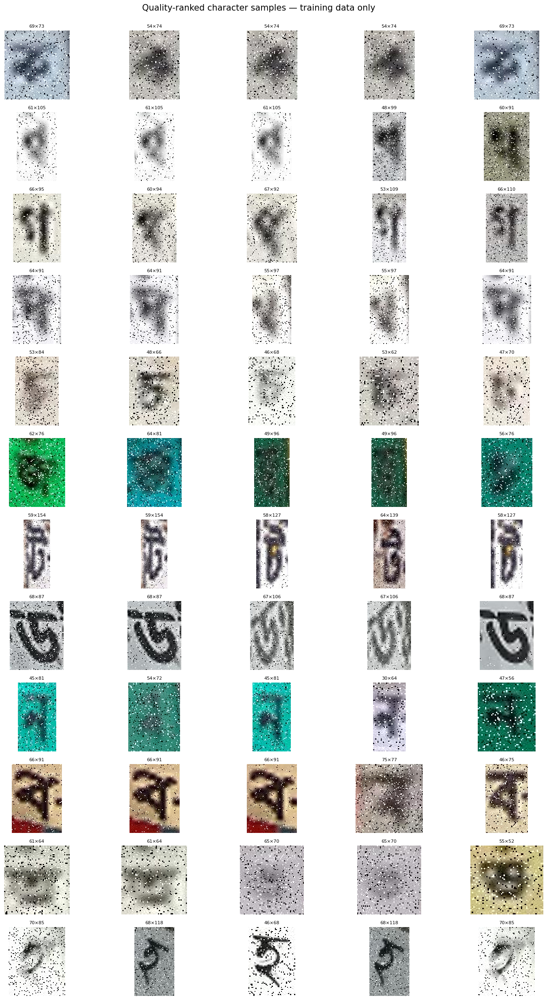


Saved: /kaggle/working/bengali_character_quality_gallery.png


In [125]:
# ============================================================
# STEP 24.2 - Quality-ranked Bengali character gallery
# Training split only
# ============================================================

import os
import glob
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

CHAR_ROOT = (
    "/kaggle/input/datasets/"
    "syednahinhossain/"
    "bangladeshi-license-plate-recognition-dataset/"
    "Character Recognition"
)

TRAIN_DIR = os.path.join(CHAR_ROOT, "train")

TARGET_CLASSES = [
    "ka", "kha", "ga", "gha",
    "ca", "ja", "ta", "da",
    "na", "ba", "va", "ha"
]

EXAMPLES_PER_CLASS = 5
best_examples = {c: [] for c in TARGET_CLASSES}


def find_matching_image(xml_path):
    stem = os.path.splitext(xml_path)[0]

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        path = stem + ext
        if os.path.exists(path):
            return path

    return None


xml_files = sorted(
    glob.glob(os.path.join(TRAIN_DIR, "*.xml"))
)

for idx, xml_path in enumerate(xml_files, start=1):

    image_path = find_matching_image(xml_path)

    if image_path is None:
        continue

    image = cv2.imread(image_path)

    if image is None:
        continue

    H, W = image.shape[:2]

    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        continue

    for obj in root.findall("object"):

        name_node = obj.find("name")
        bbox = obj.find("bndbox")

        if name_node is None or bbox is None:
            continue

        class_name = name_node.text.strip()

        if class_name not in best_examples:
            continue

        try:
            x1 = int(float(bbox.find("xmin").text))
            y1 = int(float(bbox.find("ymin").text))
            x2 = int(float(bbox.find("xmax").text))
            y2 = int(float(bbox.find("ymax").text))
        except (AttributeError, TypeError, ValueError):
            continue

        x1 = max(0, min(x1, W))
        x2 = max(0, min(x2, W))
        y1 = max(0, min(y1, H))
        y2 = max(0, min(y2, H))

        if x2 <= x1 or y2 <= y1:
            continue

        crop_bgr = image[y1:y2, x1:x2]

        ch, cw = crop_bgr.shape[:2]

        # Tiny crops are unlikely to be useful for checking glyph shape.
        if ch < 10 or cw < 8:
            continue

        gray = cv2.cvtColor(
            crop_bgr,
            cv2.COLOR_BGR2GRAY
        )

        area = ch * cw
        contrast = float(gray.std())
        sharpness = float(
            cv2.Laplacian(
                gray,
                cv2.CV_64F
            ).var()
        )

        # Prefer larger crops, with smaller contributions from
        # contrast and sharpness. This is only a ranking heuristic;
        # sharpness can be misleading when the image contains noise.
        score = (
            np.log1p(area)
            + 0.12 * np.log1p(sharpness)
            + 0.025 * contrast
        )

        item = {
            "crop": cv2.cvtColor(
                crop_bgr,
                cv2.COLOR_BGR2RGB
            ).copy(),
            "filename": os.path.basename(image_path),
            "width": cw,
            "height": ch,
            "score": float(score)
        }

        candidates = best_examples[class_name]
        candidates.append(item)

        candidates.sort(
            key=lambda x: x["score"],
            reverse=True
        )

        del candidates[EXAMPLES_PER_CLASS:]


    if idx % 1000 == 0:
        print(f"Scanned {idx}/{len(xml_files)} XML files")

print("\nBest examples selected per class:")
for class_name in TARGET_CLASSES:
    print(
        f"{class_name:5s}: "
        f"{len(best_examples[class_name])} examples"
    )


# ------------------------------------------------------------
# Plot the quality-ranked gallery
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(TARGET_CLASSES),
    EXAMPLES_PER_CLASS,
    figsize=(16, 25)
)

for r, class_name in enumerate(TARGET_CLASSES):

    for c in range(EXAMPLES_PER_CLASS):

        ax = axes[r, c]
        ax.axis("off")

        if c < len(best_examples[class_name]):

            item = best_examples[class_name][c]

            ax.imshow(
                item["crop"],
                interpolation="nearest"
            )

            ax.set_title(
                f'{item["width"]}×{item["height"]}',
                fontsize=8
            )

        if c == 0:
            ax.set_ylabel(
                class_name,
                fontsize=11,
                rotation=0,
                labelpad=35,
                va="center"
            )

plt.suptitle(
    "Quality-ranked character samples — training data only",
    fontsize=15
)

plt.tight_layout(rect=[0.04, 0, 1, 0.98])

GALLERY_PATH = (
    "/kaggle/working/"
    "bengali_character_quality_gallery.png"
)

plt.savefig(
    GALLERY_PATH,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", GALLERY_PATH)

Scanned 1000/3480 XML files
Scanned 2000/3480 XML files
Scanned 3000/3480 XML files


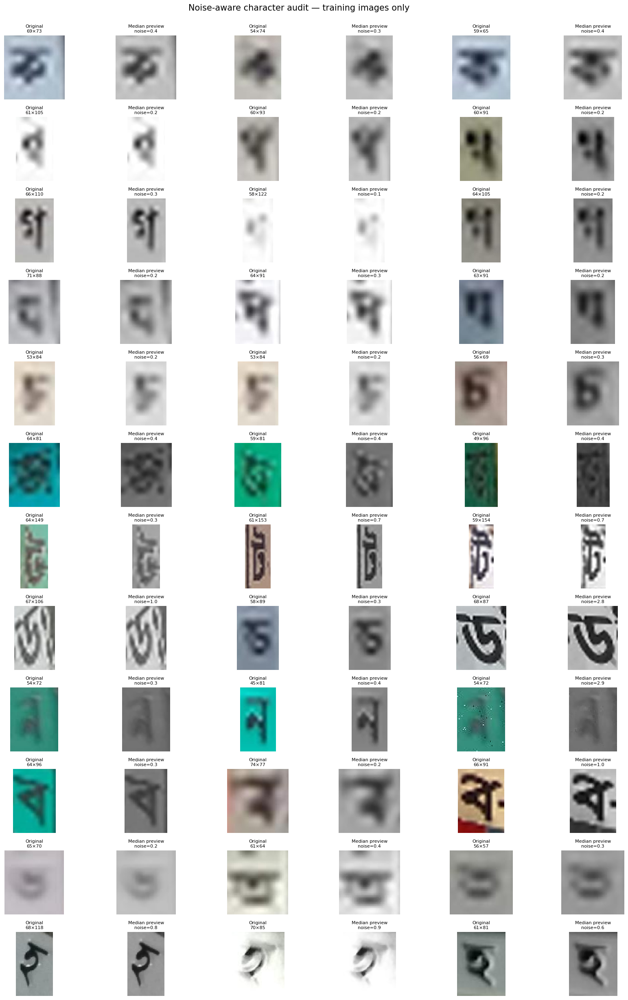

Saved: /kaggle/working/bengali_character_noise_aware_gallery.png

Available samples:
ka   : 3
kha  : 3
ga   : 3
gha  : 3
ca   : 3
ja   : 3
ta   : 3
da   : 3
na   : 3
ba   : 3
va   : 3
ha   : 3


In [126]:
# ============================================================
# STEP 24.3 - Noise-aware visual audit of Bengali classes
# Training split only; filtering is for preview only
# ============================================================

import os
import glob
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

CHAR_ROOT = (
    "/kaggle/input/datasets/"
    "syednahinhossain/"
    "bangladeshi-license-plate-recognition-dataset/"
    "Character Recognition"
)

TRAIN_DIR = os.path.join(CHAR_ROOT, "train")

TARGET_CLASSES = [
    "ka", "kha", "ga", "gha",
    "ca", "ja", "ta", "da",
    "na", "ba", "va", "ha"
]

EXAMPLES_PER_CLASS = 3
candidates = {c: [] for c in TARGET_CLASSES}


def find_image(xml_path):
    stem = os.path.splitext(xml_path)[0]

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        path = stem + ext
        if os.path.exists(path):
            return path

    return None


xml_files = glob.glob(os.path.join(TRAIN_DIR, "*.xml"))

for idx, xml_path in enumerate(xml_files, start=1):

    image_path = find_image(xml_path)

    if image_path is None:
        continue

    image = cv2.imread(image_path)

    if image is None:
        continue

    H, W = image.shape[:2]

    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        continue

    for obj in root.findall("object"):

        name_node = obj.find("name")
        bbox = obj.find("bndbox")

        if name_node is None or bbox is None:
            continue

        class_name = name_node.text.strip()

        if class_name not in TARGET_CLASSES:
            continue

        try:
            x1 = int(float(bbox.find("xmin").text))
            y1 = int(float(bbox.find("ymin").text))
            x2 = int(float(bbox.find("xmax").text))
            y2 = int(float(bbox.find("ymax").text))
        except (AttributeError, ValueError, TypeError):
            continue

        x1 = max(0, min(x1, W))
        x2 = max(0, min(x2, W))
        y1 = max(0, min(y1, H))
        y2 = max(0, min(y2, H))

        if x2 - x1 < 20 or y2 - y1 < 20:
            continue

        crop = image[y1:y2, x1:x2].copy()

        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

        # Estimate isolated high-frequency noise by comparing
        # the crop with a small median-filtered version.
        median = cv2.medianBlur(gray, 3)

        residual = cv2.absdiff(gray, median)
        noise_score = float(np.mean(residual))

        area = crop.shape[0] * crop.shape[1]

        # Prefer larger examples, but penalize strong isolated noise.
        # This is a sampling heuristic, not a validated image-quality metric.
        quality_score = (
            np.log1p(area)
            - 0.12 * noise_score
        )

        candidates[class_name].append({
            "crop": cv2.cvtColor(crop, cv2.COLOR_BGR2RGB),
            "median": cv2.cvtColor(median, cv2.COLOR_GRAY2RGB),
            "noise_score": noise_score,
            "quality_score": quality_score,
            "filename": os.path.basename(image_path),
            "width": crop.shape[1],
            "height": crop.shape[0]
        })

    if idx % 1000 == 0:
        print(f"Scanned {idx}/{len(xml_files)} XML files")


# Retain the three best-ranked candidates per class.
selected = {}

for class_name, items in candidates.items():

    items.sort(
        key=lambda item: item["quality_score"],
        reverse=True
    )

    selected[class_name] = items[:EXAMPLES_PER_CLASS]


# ------------------------------------------------------------
# Display: original and median-filtered preview side by side
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(TARGET_CLASSES),
    EXAMPLES_PER_CLASS * 2,
    figsize=(18, 25)
)

for row, class_name in enumerate(TARGET_CLASSES):

    for sample_idx in range(EXAMPLES_PER_CLASS):

        col_original = sample_idx * 2
        col_filtered = col_original + 1

        ax_original = axes[row, col_original]
        ax_filtered = axes[row, col_filtered]

        ax_original.axis("off")
        ax_filtered.axis("off")

        if sample_idx < len(selected[class_name]):

            item = selected[class_name][sample_idx]

            ax_original.imshow(
                item["crop"],
                interpolation="nearest"
            )

            ax_filtered.imshow(
                item["median"],
                interpolation="nearest"
            )

            ax_original.set_title(
                f'Original\n{item["width"]}×{item["height"]}',
                fontsize=8
            )

            ax_filtered.set_title(
                f'Median preview\nnoise={item["noise_score"]:.1f}',
                fontsize=8
            )

        if sample_idx == 0:
            ax_original.set_ylabel(
                class_name,
                fontsize=12,
                rotation=0,
                labelpad=35,
                va="center"
            )


plt.suptitle(
    "Noise-aware character audit — training images only",
    fontsize=15
)

plt.tight_layout(rect=[0.04, 0, 1, 0.98])

GALLERY_PATH = (
    "/kaggle/working/"
    "bengali_character_noise_aware_gallery.png"
)

plt.savefig(
    GALLERY_PATH,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Saved:", GALLERY_PATH)

print("\nAvailable samples:")
for class_name in TARGET_CLASSES:
    print(f"{class_name:5s}: {len(selected[class_name])}")

In [127]:
# ============================================================
# STEP 25.1 - Verify the held-out character detection test set
# ============================================================

import os
import glob

DATA_YAML = "/kaggle/working/bd_lpr_yolo/data.yaml"

TEST_IMAGES = "/kaggle/working/bd_lpr_yolo/test/images"
TEST_LABELS = "/kaggle/working/bd_lpr_yolo/test/labels"

MODEL_A_PATH = (
    "/kaggle/working/lpr_training/"
    "model_A_baseline/weights/best.pt"
)

MODEL_B_PATH = (
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

RESULTS_CSV = (
    "/kaggle/working/"
    "lpr_robustness_comparison.csv"
)

image_extensions = ("*.jpg", "*.jpeg", "*.png")

test_images = []

for ext in image_extensions:
    test_images.extend(
        glob.glob(os.path.join(TEST_IMAGES, ext))
    )

test_images = sorted(test_images)

missing_labels = []

for image_path in test_images:
    stem = os.path.splitext(os.path.basename(image_path))[0]
    label_path = os.path.join(TEST_LABELS, stem + ".txt")

    if not os.path.exists(label_path):
        missing_labels.append(stem)

print("Held-out test images:", len(test_images))
print("Test labels:", len(glob.glob(os.path.join(TEST_LABELS, "*.txt"))))
print("Images missing label files:", len(missing_labels))

assert os.path.exists(DATA_YAML), "Dataset YAML not found."
assert os.path.exists(MODEL_A_PATH), "Model A not found."
assert os.path.exists(MODEL_B_PATH), "Model B not found."
assert len(test_images) > 0, "No test images found."
assert not missing_labels, (
    "Some test images lack label files. Inspect before evaluating: "
    + str(missing_labels[:10])
)

print("\nDataset and model checks passed.")

Held-out test images: 218
Test labels: 218
Images missing label files: 0

Dataset and model checks passed.


In [128]:
# ============================================================
# STEP 25.2 - Clean held-out test evaluation
# ============================================================

import os
import pandas as pd
from ultralytics import YOLO

model_A = YOLO(MODEL_A_PATH)
model_B = YOLO(MODEL_B_PATH)

os.makedirs(
    "/kaggle/working/lpr_robustness_runs",
    exist_ok=True
)

def extract_detection_metrics(model, model_label, condition, data_yaml, split):
    metrics = model.val(
        data=data_yaml,
        split=split,
        imgsz=640,
        batch=16,
        device=0,
        workers=2,
        plots=False,
        verbose=False,
        project="/kaggle/working/lpr_robustness_runs",
        name=f"{condition}_{model_label}",
        exist_ok=True
    )

    return {
        "condition": condition,
        "model": model_label,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
        "source_images": len(test_images)
    }


if os.path.exists(RESULTS_CSV):
    results_rows = pd.read_csv(RESULTS_CSV).to_dict("records")
else:
    results_rows = []

# Clean test set
for model, label in [
    (model_A, "A_baseline"),
    (model_B, "B_synthetic_fading")
]:
    # Avoid accidentally duplicating prior rows if this cell is rerun.
    results_rows = [
        row for row in results_rows
        if not (
            row.get("condition") == "clean"
            and row.get("model") == label
        )
    ]

    row = extract_detection_metrics(
        model,
        label,
        condition="clean",
        data_yaml=DATA_YAML,
        split="test"
    )

    results_rows.append(row)

    pd.DataFrame(results_rows).to_csv(
        RESULTS_CSV,
        index=False
    )

    print("\nCompleted:", row)

print("\nCurrent clean-test comparison:")
display(
    pd.DataFrame(results_rows)
    .query("condition == 'clean'")
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 468.8±202.3 MB/s, size: 11.8 KB)
val: Scanning /kaggle/working/bd_lpr_yolo/test/labels... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 1.2Kit/s 0.2s<0.3s
val: New cache created: /kaggle/working/bd_lpr_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 9.1it/s 1.5s0.1s
                   all        218       1921      0.948      0.892      0.941      0.705
Speed: 0.5ms preprocess, 3.1ms inference, 0.0ms loss, 0.9ms postprocess per image

Completed: {'condition': 'clean', 'model': 'A_baseline', 'precision': 0.9476241521753025, 'recall': 0.8918425487255845, 'mAP50': 0.9412908447170912, 'mAP50_95': 0.7048981368620498, 'source_images': 218}
Ultralytics 8.4.174 🚀 Python-3.13.15 

,condition,model,precision,recall,mAP50,mAP50_95,source_images
0,clean,A_baseline,0.947624,0.891843,0.941291,0.704898,218
1,clean,B_synthetic_fading,0.946531,0.924874,0.956960,0.717326,218


In [129]:
# ============================================================
# STEP 26.1 - Load your original fading algorithm
# ============================================================

import sys
import importlib

if "/kaggle/working" not in sys.path:
    sys.path.insert(0, "/kaggle/working")

import bd_plate_fade as fade_module

importlib.reload(fade_module)

assert hasattr(fade_module, "fade_once"), (
    "fade_once() is missing from bd_plate_fade.py"
)

print("Original fading function loaded.")
print("Current fade range:", fade_module.FADE_MIN, fade_module.FADE_MAX)
print("Current rust:", fade_module.RUST)
print("Current noise:", fade_module.NOISE)
print("Current blur:", fade_module.BLUR)

Original fading function loaded.
Current fade range: 0.8 0.97
Current rust: 0.12
Current noise: 4.0
Current blur: 1.0


In [130]:
# ============================================================
# STEP 26.2 - Synthetic fading robustness experiment
# ============================================================

import os
import glob
import shutil
import cv2
import yaml
import numpy as np
import pandas as pd

from PIL import Image
from ultralytics import YOLO

# Reload saved models to make this cell standalone.
model_A_eval = YOLO(MODEL_A_PATH)
model_B_eval = YOLO(MODEL_B_PATH)

SYN_ROOT = "/kaggle/working/synthetic_fade_eval"
SYN_YAML = os.path.join(SYN_ROOT, "data.yaml")

# Temporary output is generated from the held-out test split only.
FADE_LEVELS = {
    "synthetic_mild": {
        "FADE_MIN": 0.35,
        "FADE_MAX": 0.55,
        "RUST": 0.04,
        "NOISE": 2.0,
        "BLUR": 0.35
    },
    "synthetic_moderate": {
        "FADE_MIN": 0.60,
        "FADE_MAX": 0.80,
        "RUST": 0.08,
        "NOISE": 3.0,
        "BLUR": 0.65
    },
    "synthetic_strong": {
        "FADE_MIN": 0.80,
        "FADE_MAX": 0.97,
        "RUST": 0.12,
        "NOISE": 4.0,
        "BLUR": 1.0
    }
}

# Get the trained model vocabulary in fixed ID order.
if isinstance(model_A_eval.names, dict):
    class_names = [
        model_A_eval.names[i]
        for i in range(len(model_A_eval.names))
    ]
else:
    class_names = list(model_A_eval.names)

assert class_names == (
    [model_B_eval.names[i] for i in range(len(model_B_eval.names))]
    if isinstance(model_B_eval.names, dict)
    else list(model_B_eval.names)
), "Model class vocabularies do not match."

# Retain previous clean results.
if os.path.exists(RESULTS_CSV):
    results_rows = pd.read_csv(RESULTS_CSV).to_dict("records")
else:
    results_rows = []

# Stable source-image order and reproducible corruption sampling.
for level_index, (level_name, params) in enumerate(FADE_LEVELS.items()):

    print("\n" + "=" * 60)
    print("Generating:", level_name)
    print("=" * 60)

    # Delete the previous temporary severity dataset.
    if os.path.exists(SYN_ROOT):
        shutil.rmtree(SYN_ROOT)

    os.makedirs(os.path.join(SYN_ROOT, "images"), exist_ok=True)
    os.makedirs(os.path.join(SYN_ROOT, "labels"), exist_ok=True)

    # Set the parameters used by your original fade_once() code.
    for key, value in params.items():
        setattr(fade_module, key, value)

    rng = np.random.default_rng(4200 + level_index)

    for i, image_path in enumerate(test_images, start=1):

        filename = os.path.basename(image_path)
        stem = os.path.splitext(filename)[0]

        input_bgr = cv2.imread(image_path)
        if input_bgr is None:
            raise RuntimeError(f"Cannot read image: {image_path}")

        # fade_once expects RGB because its ink mask uses
        # cv2.COLOR_RGB2GRAY.
        input_rgb = cv2.cvtColor(
            input_bgr,
            cv2.COLOR_BGR2RGB
        )

        faded_rgb = fade_module.fade_once(
            input_rgb,
            rng=rng
        )

        faded_path = os.path.join(
            SYN_ROOT,
            "images",
            filename
        )

        Image.fromarray(faded_rgb).save(
            faded_path,
            quality=95
        )

        # Fading does not move objects, so reuse the exact labels.
        original_label_path = os.path.join(
            TEST_LABELS,
            stem + ".txt"
        )

        if not os.path.exists(original_label_path):
            raise FileNotFoundError(
                f"Missing label for: {filename}"
            )

        shutil.copy2(
            original_label_path,
            os.path.join(
                SYN_ROOT,
                "labels",
                stem + ".txt"
            )
        )

        if i % 100 == 0 or i == len(test_images):
            print(f"Generated {i}/{len(test_images)} images")

    # Write test YAML for this temporary dataset.
    with open(SYN_YAML, "w", encoding="utf-8") as f:
        f.write(f"path: {SYN_ROOT}\n")
        f.write("train: images\n")
        f.write("val: images\n")
        f.write("test: images\n\n")
        f.write(f"nc: {len(class_names)}\n")
        f.write("names:\n")

        for idx, name in enumerate(class_names):
            f.write(f"  {idx}: '{name}'\n")

    # Remove previous metrics for this condition before rerunning.
    results_rows = [
        row for row in results_rows
        if row.get("condition") != level_name
    ]

    # Both models evaluate the identical generated images and labels.
    for model, model_label in [
        (model_A_eval, "A_baseline"),
        (model_B_eval, "B_synthetic_fading")
    ]:

        row = extract_detection_metrics(
            model,
            model_label,
            condition=level_name,
            data_yaml=SYN_YAML,
            split="test"
        )

        results_rows.append(row)

        pd.DataFrame(results_rows).to_csv(
            RESULTS_CSV,
            index=False
        )

        print("\nMetrics:", row)

    # Cleanup this severity before generating the next.
    shutil.rmtree(SYN_ROOT)

    print("Temporary dataset removed:", level_name)

print("\nSynthetic robustness experiment complete.")
print("Saved metrics:", RESULTS_CSV)


Generating: synthetic_mild
Generated 100/218 images
Generated 200/218 images
Generated 218/218 images
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 883.8±223.1 MB/s, size: 24.3 KB)
val: Scanning /kaggle/working/synthetic_fade_eval/labels... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 1.1Kit/s 0.2s<0.3s
val: New cache created: /kaggle/working/synthetic_fade_eval/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 9.5it/s 1.5s0.1s
                   all        218       1921      0.935      0.885      0.937      0.688
Speed: 0.6ms preprocess, 2.5ms inference, 0.0ms loss, 0.9ms postprocess per image

Metrics: {'condition': 'synthetic_mild', 'model': 'A_baseline', 'precision': 0.9349405260803808, 'recall': 0.8845695648073906, 'mAP

In [131]:
# ============================================================
# STEP 27 - Summarize clean and synthetic test results
# ============================================================

import pandas as pd

robustness_df = pd.read_csv(
    "/kaggle/working/lpr_robustness_comparison.csv"
)

metric_columns = [
    "condition",
    "model",
    "precision",
    "recall",
    "mAP50",
    "mAP50_95",
    "source_images"
]

display(
    robustness_df[metric_columns].sort_values(
        ["condition", "model"]
    )
)

# Model B minus Model A for each test condition.
wide = robustness_df.pivot(
    index="condition",
    columns="model",
    values=["precision", "recall", "mAP50", "mAP50_95"]
)

delta_rows = []

for condition in wide.index:

    row = {"condition": condition}

    for metric in ["precision", "recall", "mAP50", "mAP50_95"]:

        a = wide.loc[condition, (metric, "A_baseline")]
        b = wide.loc[condition, (metric, "B_synthetic_fading")]

        row[f"{metric}_B_minus_A"] = float(b - a)

    delta_rows.append(row)

delta_df = pd.DataFrame(delta_rows)

print("\nModel B improvement relative to Model A:")
display(delta_df)

robustness_df.to_csv(
    "/kaggle/working/lpr_robustness_comparison.csv",
    index=False
)

delta_df.to_csv(
    "/kaggle/working/lpr_robustness_deltas.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/lpr_robustness_comparison.csv")
print("/kaggle/working/lpr_robustness_deltas.csv")

,condition,model,precision,recall,mAP50,mAP50_95,source_images
0,clean,A_baseline,0.947624,0.891843,0.941291,0.704898,218
1,clean,B_synthetic_fading,0.946531,0.924874,0.956960,0.717326,218
2,synthetic_mild,A_baseline,0.934941,0.884570,0.937433,0.688202,218
3,synthetic_mild,B_synthetic_fading,0.945369,0.929673,0.959652,0.719898,218
4,synthetic_moderate,A_baseline,0.928004,0.821052,0.909016,0.648644,218
5,synthetic_moderate,B_synthetic_fading,0.934294,0.932860,0.952560,0.706718,218
6,synthetic_strong,A_baseline,0.809048,0.678494,0.783947,0.539836,218
7,synthetic_strong,B_synthetic_fading,0.948422,0.900295,0.948364,0.694083,218



Model B improvement relative to Model A:


,condition,precision_B_minus_A,recall_B_minus_A,mAP50_B_minus_A,mAP50_95_B_minus_A
0,clean,-0.001094,0.033031,0.015669,0.012428
1,synthetic_mild,0.010428,0.045103,0.022219,0.031696
2,synthetic_moderate,0.006291,0.111808,0.043544,0.058073
3,synthetic_strong,0.139374,0.221801,0.164416,0.154248



Saved:
/kaggle/working/lpr_robustness_comparison.csv
/kaggle/working/lpr_robustness_deltas.csv


In [132]:
# ============================================================
# STEP 28.1 - Verify image and annotation counts
# ============================================================

import os
import glob

TEST_IMAGES = "/kaggle/working/bd_lpr_yolo/test/images"
TEST_LABELS = "/kaggle/working/bd_lpr_yolo/test/labels"

image_extensions = ("*.jpg", "*.jpeg", "*.png")

image_files = []
for ext in image_extensions:
    image_files.extend(
        glob.glob(os.path.join(TEST_IMAGES, ext))
    )

label_files = glob.glob(
    os.path.join(TEST_LABELS, "*.txt")
)

label_stems = {
    os.path.splitext(os.path.basename(p))[0]
    for p in label_files
}

missing_labels = [
    os.path.splitext(os.path.basename(p))[0]
    for p in image_files
    if os.path.splitext(os.path.basename(p))[0] not in label_stems
]

print("Test images:", len(image_files))
print("Label files:", len(label_files))
print("Images without label files:", len(missing_labels))

if len(image_files) != 218:
    print(
        "\nWARNING: The current folder contains a different "
        "number of images than the robustness report."
    )
else:
    print("\nThe image count matches the robustness report.")

Test images: 218
Label files: 218
Images without label files: 0

The image count matches the robustness report.


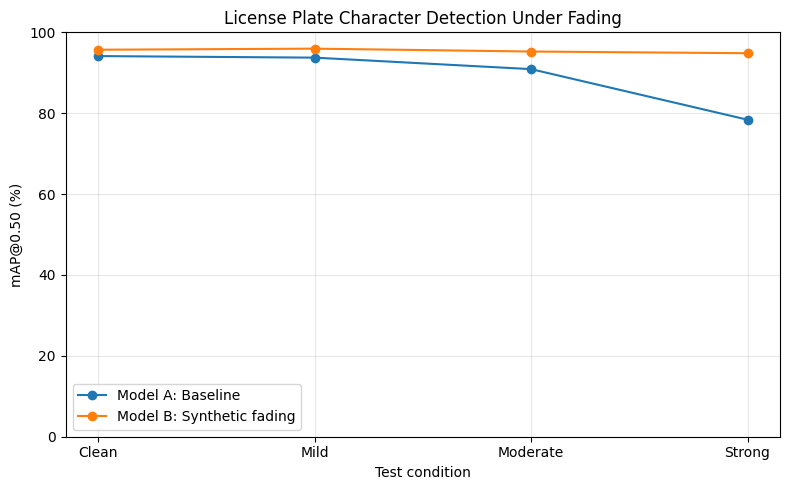

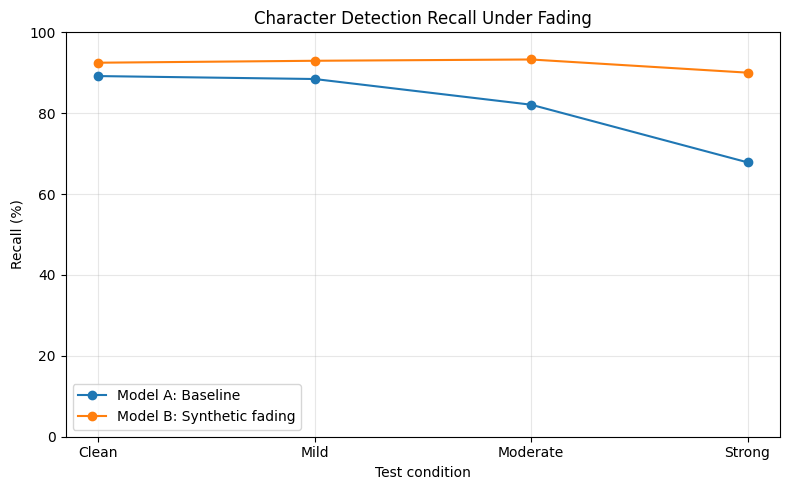


THESIS SUMMARY


,Condition,Images,Model A mAP50 (%),Model B mAP50 (%),mAP50 improvement (pp),Model A recall (%),Model B recall (%),Recall improvement (pp)
0,Clean,218,94.13,95.70,1.57,89.18,92.49,3.30
1,Mild,218,93.74,95.97,2.22,88.46,92.97,4.51
2,Moderate,218,90.90,95.26,4.35,82.11,93.29,11.18
3,Strong,218,78.39,94.84,16.44,67.85,90.03,22.18



Saved figures and table:
/kaggle/working/thesis_robustness_figures/figure_map50_robustness.png
/kaggle/working/thesis_robustness_figures/figure_recall_robustness.png
/kaggle/working/thesis_robustness_figures/thesis_robustness_summary.csv


In [133]:
# ============================================================
# STEP 28.2 - Create thesis-ready robustness plots
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_CSV = (
    "/kaggle/working/"
    "lpr_robustness_comparison.csv"
)

FIGURE_DIR = (
    "/kaggle/working/"
    "thesis_robustness_figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

df = pd.read_csv(RESULTS_CSV)

conditions = [
    "clean",
    "synthetic_mild",
    "synthetic_moderate",
    "synthetic_strong"
]

display_names = [
    "Clean",
    "Mild",
    "Moderate",
    "Strong"
]

A_NAME = "A_baseline"
B_NAME = "B_synthetic_fading"

def ordered_metric(metric):
    return (
        df.pivot(
            index="condition",
            columns="model",
            values=metric
        )
        .reindex(conditions)
    )


# ------------------------------------------------------------
# Figure 1: mAP@0.50
# ------------------------------------------------------------

map_df = ordered_metric("mAP50")

plt.figure(figsize=(8, 5))

plt.plot(
    display_names,
    map_df[A_NAME].values * 100,
    marker="o",
    label="Model A: Baseline"
)

plt.plot(
    display_names,
    map_df[B_NAME].values * 100,
    marker="o",
    label="Model B: Synthetic fading"
)

plt.xlabel("Test condition")
plt.ylabel("mAP@0.50 (%)")
plt.title("License Plate Character Detection Under Fading")
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

MAP_FIG = os.path.join(
    FIGURE_DIR,
    "figure_map50_robustness.png"
)

plt.savefig(MAP_FIG, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# Figure 2: Recall
# ------------------------------------------------------------

recall_df = ordered_metric("recall")

plt.figure(figsize=(8, 5))

plt.plot(
    display_names,
    recall_df[A_NAME].values * 100,
    marker="o",
    label="Model A: Baseline"
)

plt.plot(
    display_names,
    recall_df[B_NAME].values * 100,
    marker="o",
    label="Model B: Synthetic fading"
)

plt.xlabel("Test condition")
plt.ylabel("Recall (%)")
plt.title("Character Detection Recall Under Fading")
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

RECALL_FIG = os.path.join(
    FIGURE_DIR,
    "figure_recall_robustness.png"
)

plt.savefig(RECALL_FIG, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# Thesis summary table
# ------------------------------------------------------------

summary_rows = []

for condition, label in zip(conditions, display_names):

    condition_df = df[df["condition"] == condition]

    a = condition_df[
        condition_df["model"] == A_NAME
    ].iloc[0]

    b = condition_df[
        condition_df["model"] == B_NAME
    ].iloc[0]

    summary_rows.append({
        "Condition": label,
        "Images": int(a["source_images"]),
        "Model A mAP50 (%)": round(a["mAP50"] * 100, 2),
        "Model B mAP50 (%)": round(b["mAP50"] * 100, 2),
        "mAP50 improvement (pp)": round(
            (b["mAP50"] - a["mAP50"]) * 100, 2
        ),
        "Model A recall (%)": round(a["recall"] * 100, 2),
        "Model B recall (%)": round(b["recall"] * 100, 2),
        "Recall improvement (pp)": round(
            (b["recall"] - a["recall"]) * 100, 2
        )
    })

summary_df = pd.DataFrame(summary_rows)

SUMMARY_PATH = os.path.join(
    FIGURE_DIR,
    "thesis_robustness_summary.csv"
)

summary_df.to_csv(
    SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nTHESIS SUMMARY")
display(summary_df)

print("\nSaved figures and table:")
print(MAP_FIG)
print(RECALL_FIG)
print(SUMMARY_PATH)

,Condition,Source images,Model A precision (%),Model B precision (%),Model A recall (%),Model B recall (%),Model A mAP50 (%),Model B mAP50 (%),mAP50 change (percentage points),Model A mAP50-95 (%),Model B mAP50-95 (%),mAP50-95 change (percentage points)
0,Clean,218,94.76,94.65,89.18,92.49,94.13,95.70,1.57,70.49,71.73,1.24
1,Mild fading,218,93.49,94.54,88.46,92.97,93.74,95.97,2.22,68.82,71.99,3.17
2,Moderate fading,218,92.80,93.43,82.11,93.29,90.90,95.26,4.35,64.86,70.67,5.81
3,Strong fading,218,80.90,94.84,67.85,90.03,78.39,94.84,16.44,53.98,69.41,15.42


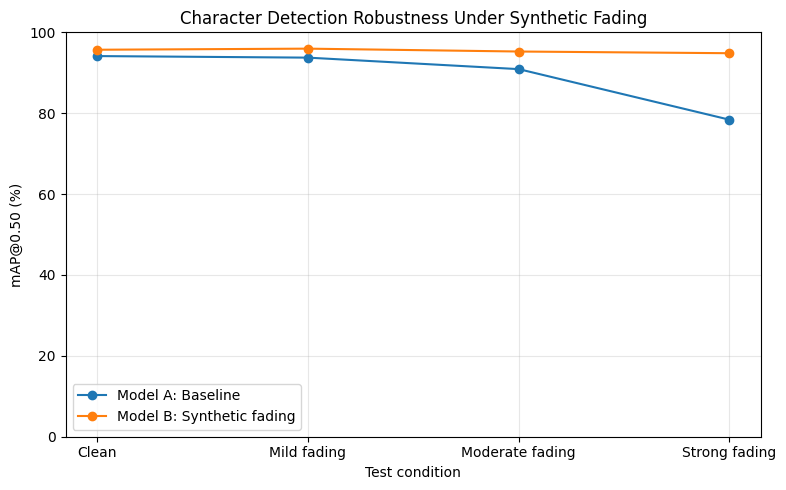

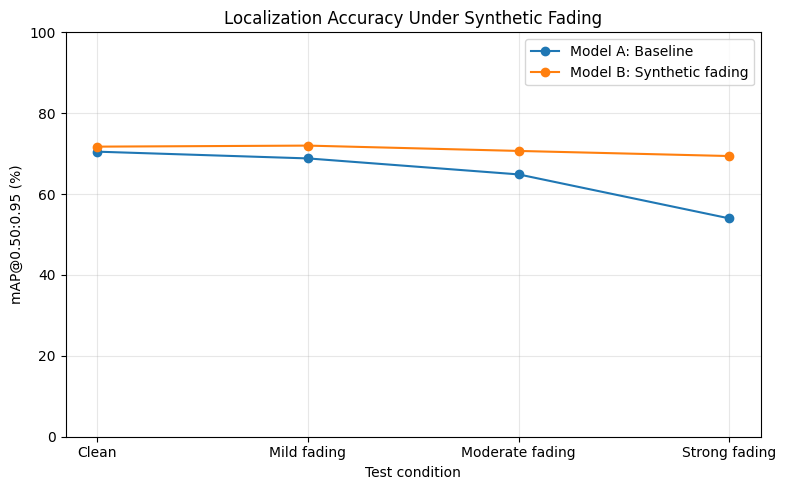

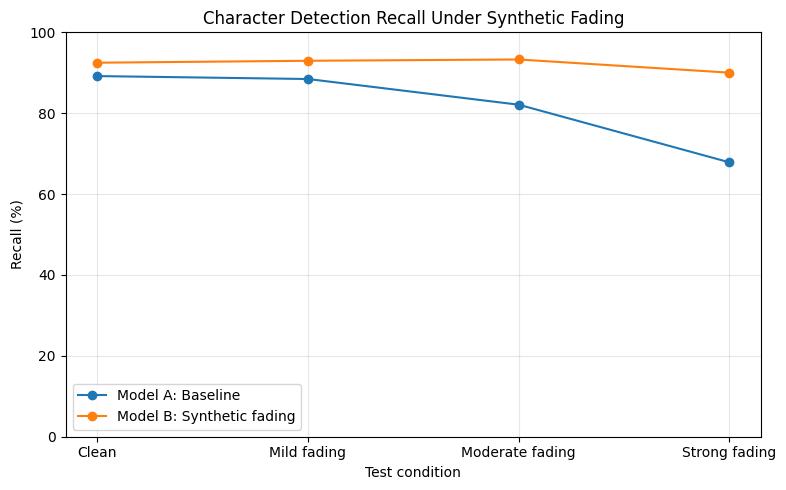

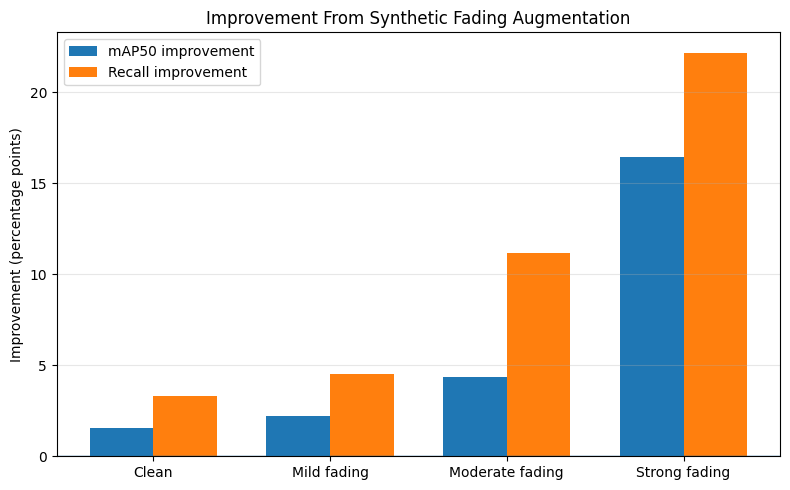

,Model,Labeled plates,Complete number predictions,Exact number matches,Strict exact accuracy (%),Conditional exact accuracy (%),Mean digit CER (%)
0,Model A: Baseline,64,54,30,46.88,55.56,18.49
1,Model B: Synthetic fading,64,55,43,67.19,78.18,8.07


,Outcome,Images
0,Both models correct,29
1,Only Model A correct,1
2,Only Model B correct,14
3,Both models wrong,20


,Labeled images,Model A only correct,Model B only correct,Discordant cases,Exact McNemar p-value
0,64,1,14,15,0.000977


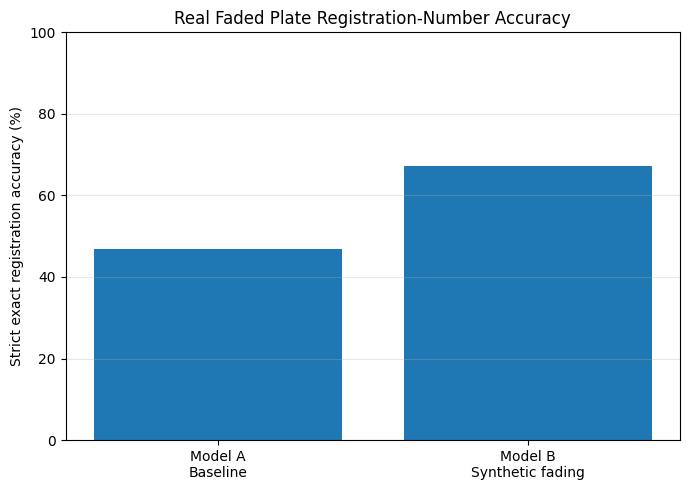

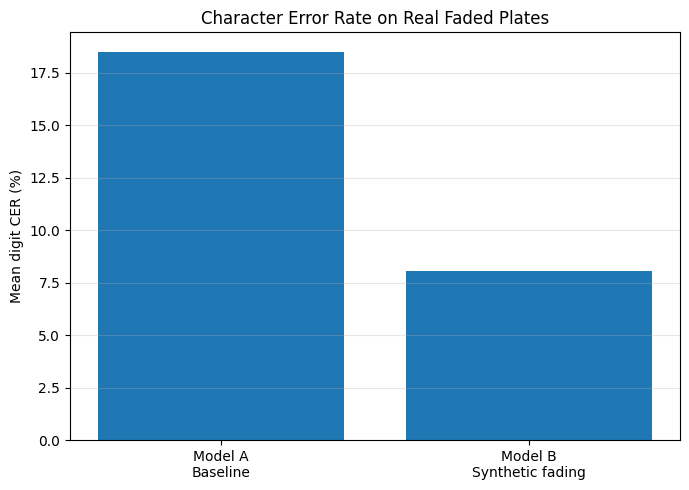


THESIS ARTIFACTS GENERATED
Figures folder: /kaggle/working/thesis_artifacts/figures
Tables folder: /kaggle/working/thesis_artifacts/tables
FIGURE: figure_01_map50_robustness.png
FIGURE: figure_02_map5095_robustness.png
FIGURE: figure_03_recall_robustness.png
FIGURE: figure_04_model_B_improvement.png
FIGURE: figure_05_real_faded_exact_accuracy.png
FIGURE: figure_06_real_faded_digit_CER.png
TABLE: real_faded_corrected_digit_predictions.csv
TABLE: table_real_faded_paired_outcomes.csv
TABLE: table_real_faded_recognition.csv
TABLE: table_real_faded_statistical_test.csv
TABLE: table_synthetic_robustness.csv


In [134]:
# ============================================================
# STEP 28.1 - Create thesis figures and evaluation tables
# No model training
# ============================================================

from pathlib import Path
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

BASE = Path("/kaggle/working")
ART = BASE / "thesis_artifacts"
FIG = ART / "figures"
TAB = ART / "tables"

FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# A. Synthetic robustness results
# ------------------------------------------------------------

ROBUST_PATH = BASE / "lpr_robustness_comparison.csv"

assert ROBUST_PATH.exists(), (
    f"Missing robustness results: {ROBUST_PATH}"
)

robust = pd.read_csv(ROBUST_PATH)

conditions = [
    "clean",
    "synthetic_mild",
    "synthetic_moderate",
    "synthetic_strong"
]

condition_labels = [
    "Clean",
    "Mild fading",
    "Moderate fading",
    "Strong fading"
]

model_A = "A_baseline"
model_B = "B_synthetic_fading"

required_columns = {
    "condition", "model", "precision", "recall",
    "mAP50", "mAP50_95"
}

assert required_columns.issubset(robust.columns), (
    f"Missing required columns: {required_columns - set(robust.columns)}"
)

# Save a clean, percentage-formatted comparison table.
table_rows = []

for condition, label in zip(conditions, condition_labels):

    part = robust[robust["condition"] == condition]

    row_A = part[part["model"] == model_A]
    row_B = part[part["model"] == model_B]

    if row_A.empty or row_B.empty:
        print("WARNING: Incomplete condition:", condition)
        continue

    a = row_A.iloc[0]
    b = row_B.iloc[0]

    table_rows.append({
        "Condition": label,
        "Source images": int(a["source_images"]),
        "Model A precision (%)": 100 * a["precision"],
        "Model B precision (%)": 100 * b["precision"],
        "Model A recall (%)": 100 * a["recall"],
        "Model B recall (%)": 100 * b["recall"],
        "Model A mAP50 (%)": 100 * a["mAP50"],
        "Model B mAP50 (%)": 100 * b["mAP50"],
        "mAP50 change (percentage points)": 100 * (b["mAP50"] - a["mAP50"]),
        "Model A mAP50-95 (%)": 100 * a["mAP50_95"],
        "Model B mAP50-95 (%)": 100 * b["mAP50_95"],
        "mAP50-95 change (percentage points)": 100 * (
            b["mAP50_95"] - a["mAP50_95"]
        )
    })

robust_table = pd.DataFrame(table_rows)

robust_table.to_csv(
    TAB / "table_synthetic_robustness.csv",
    index=False,
    float_format="%.3f"
)

display(robust_table.round(2))


# ------------------------------------------------------------
# B. Figure 1 - mAP50 by condition
# ------------------------------------------------------------

def plot_robustness_metric(
    metric,
    ylabel,
    title,
    filename
):
    values = (
        robust.pivot(
            index="condition",
            columns="model",
            values=metric
        )
        .reindex(conditions)
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        condition_labels,
        values[model_A].values * 100,
        marker="o",
        label="Model A: Baseline"
    )

    plt.plot(
        condition_labels,
        values[model_B].values * 100,
        marker="o",
        label="Model B: Synthetic fading"
    )

    plt.xlabel("Test condition")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIG / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


plot_robustness_metric(
    "mAP50",
    "mAP@0.50 (%)",
    "Character Detection Robustness Under Synthetic Fading",
    "figure_01_map50_robustness.png"
)

# ------------------------------------------------------------
# C. Figure 2 - mAP50-95 by condition
# ------------------------------------------------------------

plot_robustness_metric(
    "mAP50_95",
    "mAP@0.50:0.95 (%)",
    "Localization Accuracy Under Synthetic Fading",
    "figure_02_map5095_robustness.png"
)

# ------------------------------------------------------------
# D. Figure 3 - Recall by condition
# ------------------------------------------------------------

plot_robustness_metric(
    "recall",
    "Recall (%)",
    "Character Detection Recall Under Synthetic Fading",
    "figure_03_recall_robustness.png"
)

# ------------------------------------------------------------
# E. Figure 4 - Model B improvement by condition
# ------------------------------------------------------------

delta_map50 = robust.pivot(
    index="condition",
    columns="model",
    values="mAP50"
).reindex(conditions)

delta_recall = robust.pivot(
    index="condition",
    columns="model",
    values="recall"
).reindex(conditions)

x = np.arange(len(conditions))
width = 0.36

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    100 * (
        delta_map50[model_B].values
        - delta_map50[model_A].values
    ),
    width,
    label="mAP50 improvement"
)

plt.bar(
    x + width / 2,
    100 * (
        delta_recall[model_B].values
        - delta_recall[model_A].values
    ),
    width,
    label="Recall improvement"
)

plt.axhline(0, linewidth=1)
plt.xticks(x, condition_labels)
plt.ylabel("Improvement (percentage points)")
plt.title("Improvement From Synthetic Fading Augmentation")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIG / "figure_04_model_B_improvement.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ------------------------------------------------------------
# F. Recalculate real-faded registration metrics
#     using the LATEST corrected ground-truth CSV.
# ------------------------------------------------------------

REAL_RESULTS_PATH = (
    BASE / "real_faded_final_evaluation"
    / "model_A_vs_B_standardized_results.csv"
)

GT_PATH = BASE / "real_faded_ground_truth_roman.csv"

assert REAL_RESULTS_PATH.exists(), (
    f"Missing real faded results: {REAL_RESULTS_PATH}"
)
assert GT_PATH.exists(), f"Missing final ground truth: {GT_PATH}"

real = pd.read_csv(
    REAL_RESULTS_PATH,
    encoding="utf-8-sig"
)

gt = pd.read_csv(
    GT_PATH,
    encoding="utf-8-sig"
)

gt["image"] = gt["image"].astype(str).str.strip()
gt["ground_truth"] = gt["ground_truth"].fillna("").astype(str)

real["image_id"] = real["image"].apply(
    lambda v: os.path.splitext(
        os.path.basename(str(v))
    )[0]
)

gt_map = dict(zip(gt["image"], gt["ground_truth"]))

# Overwrite the label field with the final corrected ground truth.
real["ground_truth"] = (
    real["image_id"].map(gt_map).fillna("")
)

def gt_registration(text):
    match = re.search(
        r"(\d{2})-(\d{4})\s*$",
        str(text).strip()
    )
    return match.group(1) + match.group(2) if match else ""


def predicted_digits(text):
    return re.sub(r"\D", "", str(text))


def edit_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(
                min(
                    current[j - 1] + 1,
                    previous[j] + 1,
                    previous[j - 1] + (ca != cb)
                )
            )

        previous = current

    return previous[-1]


real["GT_digits"] = real["ground_truth"].apply(
    gt_registration
)

real["A_digits"] = real["A_registration"].fillna("").apply(
    predicted_digits
)

real["B_digits"] = real["B_registration"].fillna("").apply(
    predicted_digits
)

# Only images with a labeled registration number are evaluable.
real_eval = real[
    real["GT_digits"].str.len().eq(6)
].copy()

assert len(real_eval) == 64, (
    f"Expected 64 labeled real test plates, found {len(real_eval)}. "
    "Check missing or incorrect ground-truth labels."
)

for prefix in ["A", "B"]:

    pred_col = f"{prefix}_digits"

    real_eval[f"{prefix}_complete"] = (
        real_eval[pred_col].str.len() == 6
    )

    real_eval[f"{prefix}_exact"] = (
        real_eval[pred_col] == real_eval["GT_digits"]
    )

    real_eval[f"{prefix}_edit_distance"] = real_eval.apply(
        lambda row: edit_distance(
            row["GT_digits"],
            row[pred_col]
        ),
        axis=1
    )

    real_eval[f"{prefix}_CER"] = (
        real_eval[f"{prefix}_edit_distance"] / 6.0
    )


# ------------------------------------------------------------
# G. Table - real faded recognition results
# ------------------------------------------------------------

real_metric_rows = []

for prefix, label in [
    ("A", "Model A: Baseline"),
    ("B", "Model B: Synthetic fading")
]:
    exact_count = int(real_eval[f"{prefix}_exact"].sum())
    complete_count = int(real_eval[f"{prefix}_complete"].sum())

    real_metric_rows.append({
        "Model": label,
        "Labeled plates": len(real_eval),
        "Complete number predictions": complete_count,
        "Exact number matches": exact_count,
        "Strict exact accuracy (%)": (
            100 * exact_count / len(real_eval)
        ),
        "Conditional exact accuracy (%)": (
            100 * exact_count / complete_count
            if complete_count
            else np.nan
        ),
        "Mean digit CER (%)": (
            100 * real_eval[f"{prefix}_CER"].mean()
        )
    })

real_metrics = pd.DataFrame(real_metric_rows)

real_metrics.to_csv(
    TAB / "table_real_faded_recognition.csv",
    index=False,
    float_format="%.4f"
)

display(real_metrics.round(2))


# ------------------------------------------------------------
# H. Paired outcomes and exact McNemar test
# ------------------------------------------------------------

both_correct = int(
    (real_eval["A_exact"] & real_eval["B_exact"]).sum()
)

A_only = int(
    (real_eval["A_exact"] & ~real_eval["B_exact"]).sum()
)

B_only = int(
    (~real_eval["A_exact"] & real_eval["B_exact"]).sum()
)

both_wrong = int(
    (~real_eval["A_exact"] & ~real_eval["B_exact"]).sum()
)

paired_table = pd.DataFrame({
    "Outcome": [
        "Both models correct",
        "Only Model A correct",
        "Only Model B correct",
        "Both models wrong"
    ],
    "Images": [
        both_correct,
        A_only,
        B_only,
        both_wrong
    ]
})

discordant = A_only + B_only

p_value = (
    float(binomtest(
        k=B_only,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue)
    if discordant > 0
    else 1.0
)

paired_table.to_csv(
    TAB / "table_real_faded_paired_outcomes.csv",
    index=False
)

stat_df = pd.DataFrame([{
    "Labeled images": len(real_eval),
    "Model A only correct": A_only,
    "Model B only correct": B_only,
    "Discordant cases": discordant,
    "Exact McNemar p-value": p_value
}])

stat_df.to_csv(
    TAB / "table_real_faded_statistical_test.csv",
    index=False
)

display(paired_table)
display(stat_df)


# ------------------------------------------------------------
# I. Figure 5 - Real faded exact accuracy
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

acc_values = [
    real_metrics.iloc[0]["Strict exact accuracy (%)"],
    real_metrics.iloc[1]["Strict exact accuracy (%)"]
]

plt.bar(
    ["Model A\nBaseline", "Model B\nSynthetic fading"],
    acc_values
)

plt.ylabel("Strict exact registration accuracy (%)")
plt.title("Real Faded Plate Registration-Number Accuracy")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG / "figure_05_real_faded_exact_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ------------------------------------------------------------
# J. Figure 6 - Real faded digit CER
# ------------------------------------------------------------

cer_values = [
    real_metrics.iloc[0]["Mean digit CER (%)"],
    real_metrics.iloc[1]["Mean digit CER (%)"]
]

plt.figure(figsize=(7, 5))

plt.bar(
    ["Model A\nBaseline", "Model B\nSynthetic fading"],
    cer_values
)

plt.ylabel("Mean digit CER (%)")
plt.title("Character Error Rate on Real Faded Plates")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG / "figure_06_real_faded_digit_CER.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ------------------------------------------------------------
# K. Save the corrected predictions used in evaluation
# ------------------------------------------------------------

real_eval.to_csv(
    TAB / "real_faded_corrected_digit_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nTHESIS ARTIFACTS GENERATED")
print("Figures folder:", FIG)
print("Tables folder:", TAB)

for path in sorted(FIG.glob("*.png")):
    print("FIGURE:", path.name)

for path in sorted(TAB.glob("*.csv")):
    print("TABLE:", path.name)

,Task,Split,Images,Label files,Annotated objects,Empty label files
0,Character detection,train,3480,3480,30604,0
1,Character detection,validation,363,363,3180,0
2,Character detection,test,218,218,1921,0
3,License plate localization,train,5687,5687,4206,1541
4,License plate localization,validation,277,277,191,92
5,License plate localization,test,553,553,398,162


,class_id,class_name,training_instances,training_images_containing_class
0,0,0,2460,1732
1,1,1,4524,2664
2,2,2,2208,1784
3,3,3,2096,1572
4,4,4,1808,1480
5,5,5,1896,1476
6,6,6,1344,1116
7,7,7,1536,1272
8,8,8,1392,1164
9,9,9,1520,1280


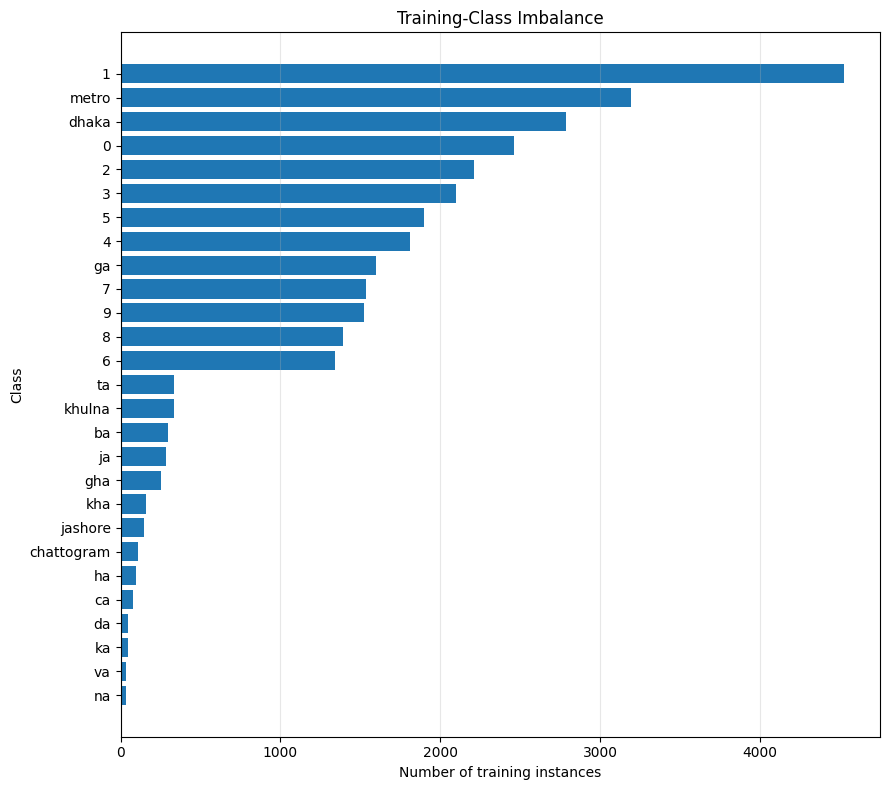


Training histories available: ['Model A: Baseline', 'Model B: Synthetic fading', 'Plate detector']


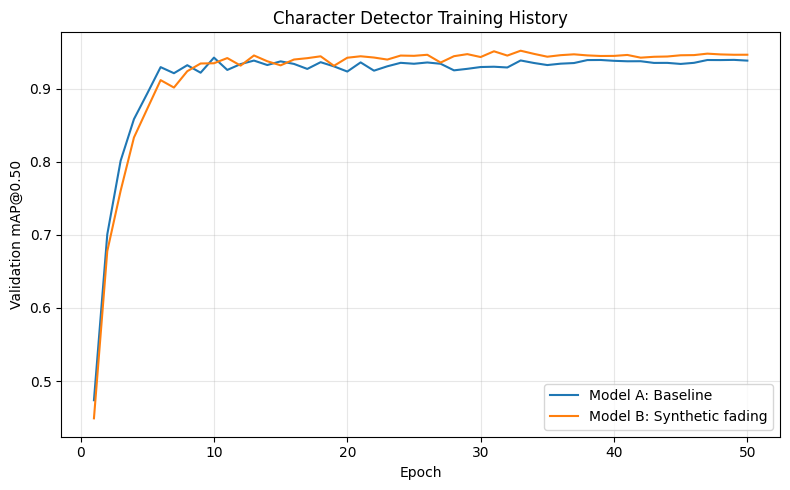

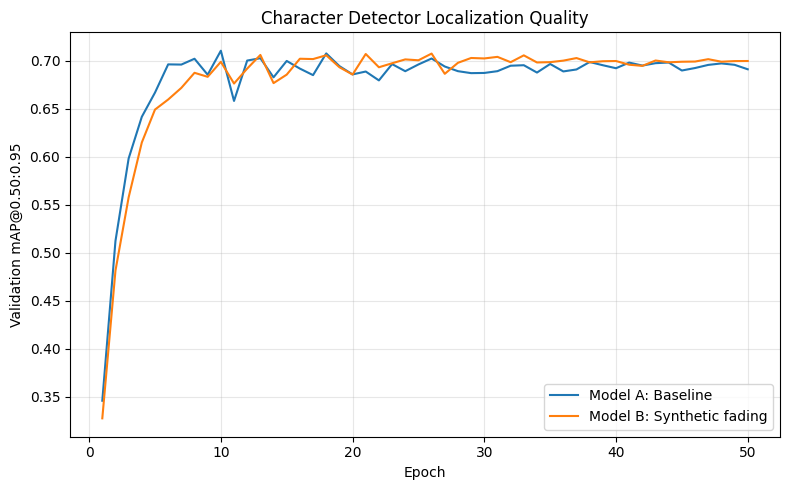

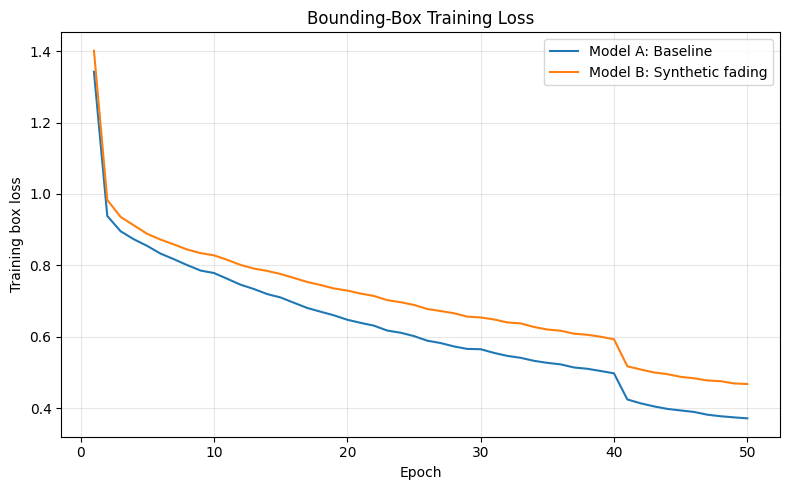

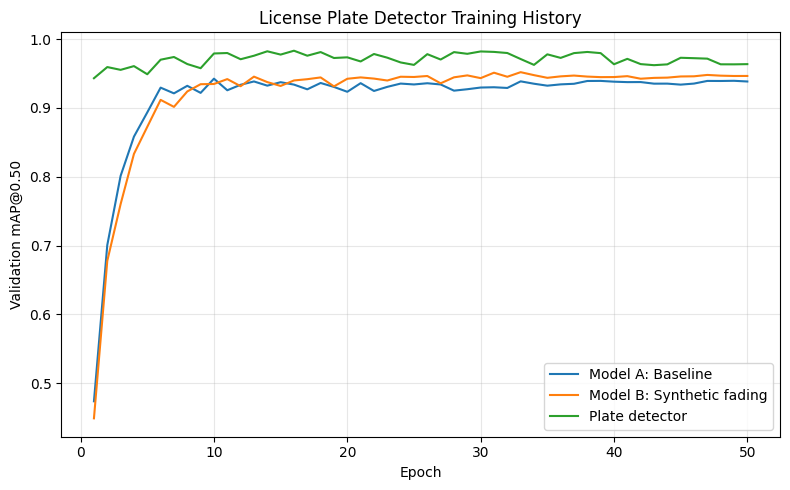

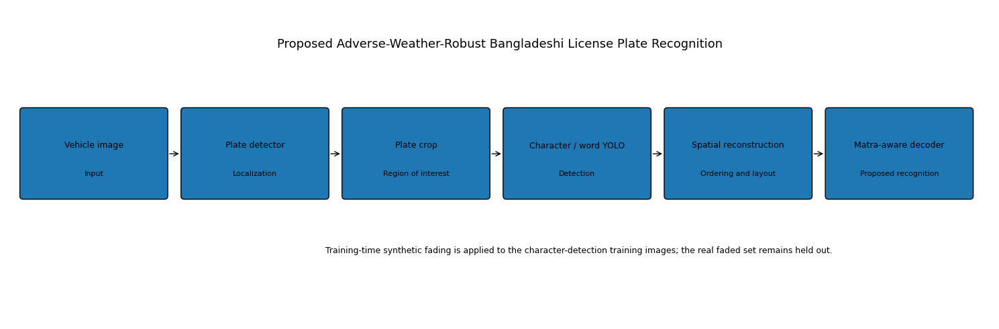


Generated thesis artifacts:
Figures: /kaggle/working/thesis_artifacts/figures
Tables: /kaggle/working/thesis_artifacts/tables


In [135]:
# ============================================================
# STEP 28.2 - Training histories, class distribution, dataset
#             statistics, and proposed architecture figure
# ============================================================

from pathlib import Path
import os
import glob
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = Path("/kaggle/working")
ART = BASE / "thesis_artifacts"
FIG = ART / "figures"
TAB = ART / "tables"

FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# A. Dataset split statistics
# ------------------------------------------------------------

datasets = {
    "Character detection": BASE / "bd_lpr_yolo",
    "License plate localization": BASE / "lp_detector_data"
}

dataset_rows = []

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

for task_name, dataset_root in datasets.items():

    if not dataset_root.exists():
        print("WARNING: Dataset folder not found:", dataset_root)
        continue

    for split in ["train", "validation", "test"]:

        image_dir = dataset_root / split / "images"
        label_dir = dataset_root / split / "labels"

        images = [
            p for p in image_dir.glob("*")
            if p.suffix.lower() in IMAGE_EXTS
        ] if image_dir.exists() else []

        labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

        object_count = 0
        empty_labels = 0

        for label_path in labels:
            try:
                with open(label_path, "r", encoding="utf-8") as f:
                    lines = [line.strip() for line in f if line.strip()]

                object_count += len(lines)

                if not lines:
                    empty_labels += 1

            except OSError:
                print("Could not read:", label_path)

        dataset_rows.append({
            "Task": task_name,
            "Split": split,
            "Images": len(images),
            "Label files": len(labels),
            "Annotated objects": object_count,
            "Empty label files": empty_labels
        })

dataset_table = pd.DataFrame(dataset_rows)

dataset_table.to_csv(
    TAB / "table_dataset_split_statistics.csv",
    index=False
)

display(dataset_table)


# ------------------------------------------------------------
# B. Character-class distribution in training set
# ------------------------------------------------------------

CLASS_NAMES = [
    "0", "1", "2", "3", "4", "5", "6", "7", "8", "9",
    "ka", "kha", "ga", "gha", "ca", "ja",
    "ta", "da", "na", "ba", "va", "ha",
    "metro", "dhaka", "khulna", "chattogram", "jashore"
]

CLASS_ROOT = BASE / "bd_lpr_yolo"
TRAIN_LABEL_DIR = CLASS_ROOT / "train" / "labels"

if TRAIN_LABEL_DIR.exists():

    instance_counts = {name: 0 for name in CLASS_NAMES}
    image_counts = {name: 0 for name in CLASS_NAMES}

    label_files = list(TRAIN_LABEL_DIR.glob("*.txt"))

    for label_path in label_files:

        found_classes = set()

        with open(label_path, "r", encoding="utf-8") as f:
            for line in f:

                parts = line.strip().split()

                if not parts:
                    continue

                try:
                    class_id = int(parts[0])
                except ValueError:
                    continue

                if 0 <= class_id < len(CLASS_NAMES):
                    class_name = CLASS_NAMES[class_id]
                    instance_counts[class_name] += 1
                    found_classes.add(class_name)

        for class_name in found_classes:
            image_counts[class_name] += 1

    class_table = pd.DataFrame({
        "class_id": list(range(len(CLASS_NAMES))),
        "class_name": CLASS_NAMES,
        "training_instances": [
            instance_counts[name] for name in CLASS_NAMES
        ],
        "training_images_containing_class": [
            image_counts[name] for name in CLASS_NAMES
        ]
    })

    class_table.to_csv(
        TAB / "table_character_class_distribution.csv",
        index=False
    )

    display(class_table)

    # Sort by frequency, making rare classes visible.
    plot_table = class_table.sort_values("training_instances")

    plt.figure(figsize=(9, 8))

    plt.barh(
        plot_table["class_name"],
        plot_table["training_instances"]
    )

    plt.xlabel("Number of training instances")
    plt.ylabel("Class")
    plt.title("Training-Class Imbalance")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        FIG / "figure_07_training_class_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

else:
    print("Character YOLO training labels not found.")


# ------------------------------------------------------------
# C. Training curves from saved results.csv
# ------------------------------------------------------------

RUNS = {
    "Model A: Baseline": (
        BASE / "lpr_training/model_A_baseline/results.csv"
    ),
    "Model B: Synthetic fading": (
        BASE / "lpr_training/model_B_synthetic_fading/results.csv"
    ),
    "Plate detector": (
        BASE / "lp_detection_training/"
        "license_plate_yolov8n/results.csv"
    )
}

history = {}

for label, path in RUNS.items():

    if not path.exists():
        print("Training history not found:", path)
        continue

    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]

    if "epoch" not in df.columns:
        df["epoch"] = np.arange(len(df))

    history[label] = df

    # Copy original history table to thesis output.
    safe_label = (
        label.lower()
        .replace(":", "")
        .replace(" ", "_")
    )

    df.to_csv(
        TAB / f"training_history_{safe_label}.csv",
        index=False
    )

print("\nTraining histories available:", list(history.keys()))


# Plot a metric for both character detector models.
def plot_training_metric(
    metric,
    ylabel,
    title,
    filename,
    include_plate_detector=False
):

    plt.figure(figsize=(8, 5))
    plotted = 0

    for label, df in history.items():

        if (
            not include_plate_detector
            and label == "Plate detector"
        ):
            continue

        if metric not in df.columns:
            print(f"Metric '{metric}' is missing for {label}")
            continue

        plt.plot(
            df["epoch"],
            df[metric],
            label=label
        )

        plotted += 1

    if plotted == 0:
        plt.close()
        print("No data available for:", title)
        return

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIG / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


plot_training_metric(
    "metrics/mAP50(B)",
    "Validation mAP@0.50",
    "Character Detector Training History",
    "figure_08_character_training_map50.png"
)

plot_training_metric(
    "metrics/mAP50-95(B)",
    "Validation mAP@0.50:0.95",
    "Character Detector Localization Quality",
    "figure_09_character_training_map5095.png"
)

plot_training_metric(
    "train/box_loss",
    "Training box loss",
    "Bounding-Box Training Loss",
    "figure_10_character_box_loss.png"
)

plot_training_metric(
    "metrics/mAP50(B)",
    "Validation mAP@0.50",
    "License Plate Detector Training History",
    "figure_11_plate_detector_training_map50.png",
    include_plate_detector=True
)


# ------------------------------------------------------------
# D. Proposed pipeline architecture diagram
# ------------------------------------------------------------

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(15, 5))

ax.set_xlim(0, 15)
ax.set_ylim(0, 5)
ax.axis("off")

stages = [
    (0.25, "Vehicle image", "Input"),
    (2.7, "Plate detector", "Localization"),
    (5.15, "Plate crop", "Region of interest"),
    (7.6, "Character / word YOLO", "Detection"),
    (10.05, "Spatial reconstruction", "Ordering and layout"),
    (12.5, "Matra-aware decoder", "Proposed recognition")
]

for x, title, subtitle in stages:

    box = FancyBboxPatch(
        (x, 2.0),
        2.15,
        1.35,
        boxstyle="round,pad=0.05"
    )

    ax.add_patch(box)

    ax.text(
        x + 1.075,
        2.80,
        title,
        ha="center",
        va="center",
        fontsize=9,
        wrap=True
    )

    ax.text(
        x + 1.075,
        2.35,
        subtitle,
        ha="center",
        va="center",
        fontsize=8
    )

for i in range(len(stages) - 1):

    x_start = stages[i][0] + 2.15
    x_end = stages[i + 1][0]

    ax.add_patch(
        FancyArrowPatch(
            (x_start + 0.05, 2.67),
            (x_end - 0.05, 2.67),
            arrowstyle="->",
            mutation_scale=12
        )
    )

ax.text(
    7.5,
    4.35,
    "Proposed Adverse-Weather-Robust Bangladeshi License Plate Recognition",
    ha="center",
    fontsize=13
)

ax.text(
    8.7,
    1.1,
    "Training-time synthetic fading is applied to the character-detection training images; "
    "the real faded set remains held out.",
    ha="center",
    fontsize=9,
    wrap=True
)

plt.tight_layout()

plt.savefig(
    FIG / "figure_12_proposed_pipeline_architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


print("\nGenerated thesis artifacts:")
print("Figures:", FIG)
print("Tables:", TAB)

In [136]:
# ============================================================
# STEP 29 - Build a thesis reproducibility and recovery bundle
# Does NOT train models
# ============================================================

from pathlib import Path
import os
import sys
import json
import shutil
import zipfile
import platform
import hashlib
import subprocess

BASE = Path("/kaggle/working")

BUNDLE = BASE / "thesis_reproducibility_bundle"
ZIP_PATH = BASE / "thesis_reproducibility_bundle.zip"

# Start with a clean package directory.
if BUNDLE.exists():
    shutil.rmtree(BUNDLE)

for folder in [
    "models",
    "code",
    "configs",
    "results",
    "figures",
    "tables",
    "training_logs",
    "documentation"
]:
    (BUNDLE / folder).mkdir(parents=True, exist_ok=True)


def copy_optional(source, destination, required=False):
    """Copy a file when it exists and report missing files."""
    source = Path(source)
    destination = BUNDLE / destination

    if not source.exists() or not source.is_file():
        message = f"MISSING: {source}"
        print(message)

        if required:
            raise FileNotFoundError(message)

        return False

    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

    print(f"Copied: {source.name}")
    return True


def copy_folder_contents(source, destination, extensions=None):
    """Copy selected files from a folder, preserving filenames."""
    source = Path(source)
    destination = BUNDLE / destination

    if not source.exists():
        print("Optional folder not found:", source)
        return

    destination.mkdir(parents=True, exist_ok=True)

    for file_path in source.rglob("*"):

        if not file_path.is_file():
            continue

        if extensions is not None and file_path.suffix.lower() not in extensions:
            continue

        relative = file_path.relative_to(source)
        target = destination / relative

        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(file_path, target)


# ------------------------------------------------------------
# A. Trained model weights
# ------------------------------------------------------------

model_files = [
    (
        BASE / "lpr_training/model_A_baseline/weights/best.pt",
        "models/character_model_A_baseline_best.pt"
    ),
    (
        BASE / "lpr_training/model_A_baseline/weights/last.pt",
        "models/character_model_A_baseline_last.pt"
    ),
    (
        BASE / "lpr_training/model_B_synthetic_fading/weights/best.pt",
        "models/character_model_B_synthetic_fading_best.pt"
    ),
    (
        BASE / "lpr_training/model_B_synthetic_fading/weights/last.pt",
        "models/character_model_B_synthetic_fading_last.pt"
    ),
    (
        BASE / "lp_detection_training/license_plate_yolov8n/weights/best.pt",
        "models/license_plate_detector_best.pt"
    ),
    (
        BASE / "lp_detection_training/license_plate_yolov8n/weights/last.pt",
        "models/license_plate_detector_last.pt"
    )
]

for source, destination in model_files:
    copy_optional(source, destination)


# ------------------------------------------------------------
# B. Code and configuration
# ------------------------------------------------------------

copy_optional(
    BASE / "bd_plate_fade.py",
    "code/bd_plate_fade.py",
    required=True
)

copy_optional(
    BASE / "bd_lpr_yolo/data.yaml",
    "configs/character_detector_data.yaml"
)

copy_optional(
    BASE / "lp_detector_data/data.yaml",
    "configs/license_plate_detector_data.yaml"
)

# Record class order explicitly.
class_names = [
    "0", "1", "2", "3", "4", "5", "6", "7", "8", "9",
    "ka", "kha", "ga", "gha", "ca", "ja",
    "ta", "da", "na", "ba", "va", "ha",
    "metro", "dhaka", "khulna", "chattogram", "jashore"
]

with open(
    BUNDLE / "configs/character_class_names.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {i: name for i, name in enumerate(class_names)},
        f,
        ensure_ascii=False,
        indent=2
    )


# ------------------------------------------------------------
# C. Main experimental data and results
# ------------------------------------------------------------

important_files = [
    # Synthetic robustness
    (
        BASE / "lpr_robustness_comparison.csv",
        "results/lpr_robustness_comparison.csv"
    ),
    (
        BASE / "lpr_robustness_deltas.csv",
        "results/lpr_robustness_deltas.csv"
    ),

    # Corrected ground truth
    (
        BASE / "real_faded_ground_truth_roman.csv",
        "results/real_faded_ground_truth_FINAL.csv"
    ),

    # Vocabulary and preliminary diagnostics
    (
        BASE / "plate_vocabulary_coverage_audit_final.csv",
        "results/plate_vocabulary_coverage_audit_final.csv"
    ),
    (
        BASE / "real_faded_spatial_reconstruction.csv",
        "results/preliminary_spatial_reconstruction.csv"
    ),

    # Standardized final evaluation
    (
        BASE / "real_faded_final_evaluation/model_A_vs_B_standardized_results.csv",
        "results/raw_standardized_real_faded_predictions.csv"
    ),
    (
        BASE / "real_faded_final_evaluation/model_A_detections.csv",
        "results/real_faded_model_A_detections.csv"
    ),
    (
        BASE / "real_faded_final_evaluation/model_B_detections.csv",
        "results/real_faded_model_B_detections.csv"
    )
]

for source, destination in important_files:
    copy_optional(source, destination)


# Include the consolidated tables and plots.
copy_folder_contents(
    BASE / "thesis_artifacts/tables",
    "tables",
    extensions={".csv", ".txt", ".json"}
)

copy_folder_contents(
    BASE / "thesis_artifacts/figures",
    "figures",
    extensions={".png", ".jpg", ".jpeg", ".pdf"}
)


# ------------------------------------------------------------
# D. Useful training history, configurations, and plots
# ------------------------------------------------------------

run_directories = [
    (
        BASE / "lpr_training/model_A_baseline",
        "training_logs/model_A_baseline"
    ),
    (
        BASE / "lpr_training/model_B_synthetic_fading",
        "training_logs/model_B_synthetic_fading"
    ),
    (
        BASE / "lp_detection_training/license_plate_yolov8n",
        "training_logs/license_plate_detector"
    )
]

for source_dir, destination_dir in run_directories:

    source_dir = Path(source_dir)

    if not source_dir.exists():
        print("Training run not found:", source_dir)
        continue

    destination = BUNDLE / destination_dir
    destination.mkdir(parents=True, exist_ok=True)

    # Preserve the metric history and training configuration.
    for filename in ["results.csv", "args.yaml"]:
        src = source_dir / filename

        if src.exists():
            shutil.copy2(src, destination / filename)

    # Preserve Ultralytics-generated plots and curves.
    for file_path in source_dir.glob("*.png"):
        shutil.copy2(file_path, destination / file_path.name)


# ------------------------------------------------------------
# E. Include any existing character-label galleries
# ------------------------------------------------------------

gallery_files = [
    "bengali_character_class_audit.png",
    "bengali_character_noise_aware_gallery.png",
    "bengali_character_quality_gallery.png",
    "word_class_examples.png"
]

for filename in gallery_files:
    copy_optional(
        BASE / filename,
        f"figures/{filename}"
    )


# ------------------------------------------------------------
# F. Environment and reproducibility manifest
# ------------------------------------------------------------

environment = {
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "source_dataset_root": (
        "/kaggle/input/datasets/"
        "syednahinhossain/"
        "bangladeshi-license-plate-recognition-dataset"
    ),
    "character_dataset_folder": "Character Recognition",
    "localization_dataset_folder": "License Plate Localization",
    "character_model_A": (
        "YOLOv8n; baseline training without the custom fading transform"
    ),
    "character_model_B": (
        "YOLOv8n; custom on-the-fly BanglaPlateFade augmentation, p=0.60"
    ),
    "plate_detector": "YOLOv8n; one-class license plate detector",
    "character_imgsz": 640,
    "character_epochs": 50,
    "character_batch": 16,
    "seed": 42,
    "class_names": class_names
}

try:
    import torch
    environment["torch_version"] = torch.__version__
    environment["cuda_available"] = torch.cuda.is_available()

    if torch.cuda.is_available():
        environment["gpu_name"] = torch.cuda.get_device_name(0)
except Exception as exc:
    environment["torch_info_error"] = str(exc)

try:
    import ultralytics
    environment["ultralytics_version"] = ultralytics.__version__
except Exception:
    pass

try:
    import cv2
    environment["opencv_version"] = cv2.__version__
except Exception:
    pass

with open(
    BUNDLE / "documentation/environment.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        environment,
        f,
        ensure_ascii=False,
        indent=2
    )


manifest = r"""
THESIS REPRODUCIBILITY BUNDLE
=============================

PURPOSE
-------
Preserve the trained weights, results, plots, and experiment metadata
for the Bangladeshi license plate recognition thesis.

TRAINED MODELS
--------------
character_model_A_baseline_best.pt
    Character/word detector trained without the custom synthetic fading
    augmentation.

character_model_B_synthetic_fading_best.pt
    Character/word detector trained using the custom on-the-fly fading
    transform in code/bd_plate_fade.py.

license_plate_detector_best.pt
    One-class detector used to localize plates in full vehicle images.

The best.pt files are intended for inference and evaluation. Their use
does not require retraining.

IMPORTANT DATA NOTES
--------------------
The original Kaggle datasets are not copied into this archive. Add the
same source datasets to the notebook's Input panel before attempting to
recreate data paths or rerun experiments.

The YAML files may contain absolute paths under /kaggle/working. If the
archive is extracted somewhere else, update those paths before evaluating
on the source dataset.

REAL FADED TEST SET
-------------------
The final ground-truth CSV contains 67 image IDs, 64 labeled strings, and
3 unlabeled images. Keep these real labeled images held out from training.

EVALUATION SCOPE
----------------
The synthetic robustness figures evaluate character/word object detection.
The real faded registration-number results evaluate the six registration
digits. Neither result alone demonstrates full-plate matra-aware recognition.

SYNTHETIC TEST SET
------------------
Synthetic variants are derived from the held-out clean test images. Treat
severity conditions as related variants of the same source images, not as
new independent images.

REPRODUCIBILITY
---------------
Use the saved results.csv files, args.yaml files, environment.json, class
vocabulary, code module, and source notebook version to document the
experiments. Do not report a model as matra-aware until the reconstruction
method has been implemented and evaluated separately.
"""

with open(
    BUNDLE / "README.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(manifest.strip() + "\n")


# ------------------------------------------------------------
# G. Save notebook cell history as a reference file
# ------------------------------------------------------------

try:
    ip = get_ipython()
    cell_history = ip.user_ns.get("In", [])

    history_path = BUNDLE / "documentation/notebook_cell_history.txt"

    with open(history_path, "w", encoding="utf-8") as f:
        for cell_number, source in enumerate(cell_history):
            if not isinstance(source, str) or not source.strip():
                continue

            f.write("\n")
            f.write("=" * 80 + "\n")
            f.write(f"EXECUTED CELL HISTORY ENTRY: {cell_number}\n")
            f.write("=" * 80 + "\n")
            f.write(source)
            f.write("\n")

    print("Notebook cell-history reference saved.")

except Exception as exc:
    print("Could not export cell history:", exc)


# ------------------------------------------------------------
# H. Create a file inventory and checksums
# ------------------------------------------------------------

inventory = []
checksums = []

for file_path in sorted(BUNDLE.rglob("*")):

    if not file_path.is_file():
        continue

    relative = file_path.relative_to(BUNDLE).as_posix()
    size = file_path.stat().st_size

    inventory.append({
        "path": relative,
        "size_bytes": size
    })

    digest = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    checksums.append({
        "path": relative,
        "sha256": digest.hexdigest()
    })

pd_inventory = None

import pandas as pd

pd.DataFrame(inventory).to_csv(
    BUNDLE / "documentation/file_inventory.csv",
    index=False
)

pd.DataFrame(checksums).to_csv(
    BUNDLE / "documentation/checksums_sha256.csv",
    index=False
)


# ------------------------------------------------------------
# I. Zip the bundle
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=3
) as zf:

    for file_path in BUNDLE.rglob("*"):

        if not file_path.is_file():
            continue

        archive_name = (
            Path("thesis_reproducibility_bundle")
            / file_path.relative_to(BUNDLE)
        )

        zf.write(file_path, archive_name)

size_mb = ZIP_PATH.stat().st_size / (1024 * 1024)

print("\n========================================")
print("THESIS BACKUP BUNDLE CREATED")
print("========================================")
print("Archive:", ZIP_PATH)
print(f"Size: {size_mb:.2f} MB")
print("Files:", len(inventory))

# Interactive download link inside Kaggle.
from IPython.display import FileLink, display

display(FileLink(str(ZIP_PATH)))

Copied: best.pt
Copied: last.pt
Copied: best.pt
Copied: last.pt
Copied: best.pt
Copied: last.pt
Copied: bd_plate_fade.py
Copied: data.yaml
Copied: data.yaml
Copied: lpr_robustness_comparison.csv
Copied: lpr_robustness_deltas.csv
Copied: real_faded_ground_truth_roman.csv
Copied: plate_vocabulary_coverage_audit_final.csv
Copied: real_faded_spatial_reconstruction.csv
Copied: model_A_vs_B_standardized_results.csv
Copied: model_A_detections.csv
Copied: model_B_detections.csv
Copied: bengali_character_class_audit.png
Copied: bengali_character_noise_aware_gallery.png
Copied: bengali_character_quality_gallery.png
Copied: word_class_examples.png
Notebook cell-history reference saved.

THESIS BACKUP BUNDLE CREATED
Archive: /kaggle/working/thesis_reproducibility_bundle.zip
Size: 42.05 MB
Files: 74


/kaggle/working/thesis_reproducibility_bundle.zip

In [137]:
# ============================================================
# STEP 30.1 - Verify the backup archive
# ============================================================

import os
import zipfile

ZIP_PATH = "/kaggle/working/thesis_reproducibility_bundle.zip"

assert os.path.exists(ZIP_PATH), "Backup archive not found."

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    corrupt_file = zf.testzip()
    names = zf.namelist()

    print("ZIP integrity:", "PASS" if corrupt_file is None else "FAIL")
    print("Files inside archive:", len(names))

    required_models = [
        "character_model_A_baseline_best.pt",
        "character_model_B_synthetic_fading_best.pt",
        "license_plate_detector_best.pt"
    ]

    for model_name in required_models:
        found = any(
            name.endswith("/models/" + model_name)
            for name in names
        )

        print(f"{model_name}: {'FOUND' if found else 'MISSING'}")

    if corrupt_file is not None:
        raise RuntimeError(f"Corrupt file found: {corrupt_file}")

print("\nBackup verification finished.")

ZIP integrity: PASS
Files inside archive: 76
character_model_A_baseline_best.pt: FOUND
character_model_B_synthetic_fading_best.pt: FOUND
license_plate_detector_best.pt: FOUND

Backup verification finished.


In [138]:
from IPython.display import FileLink, display

display(
    FileLink(
        "/kaggle/working/thesis_reproducibility_bundle.zip"
    )
)

/kaggle/working/thesis_reproducibility_bundle.zip

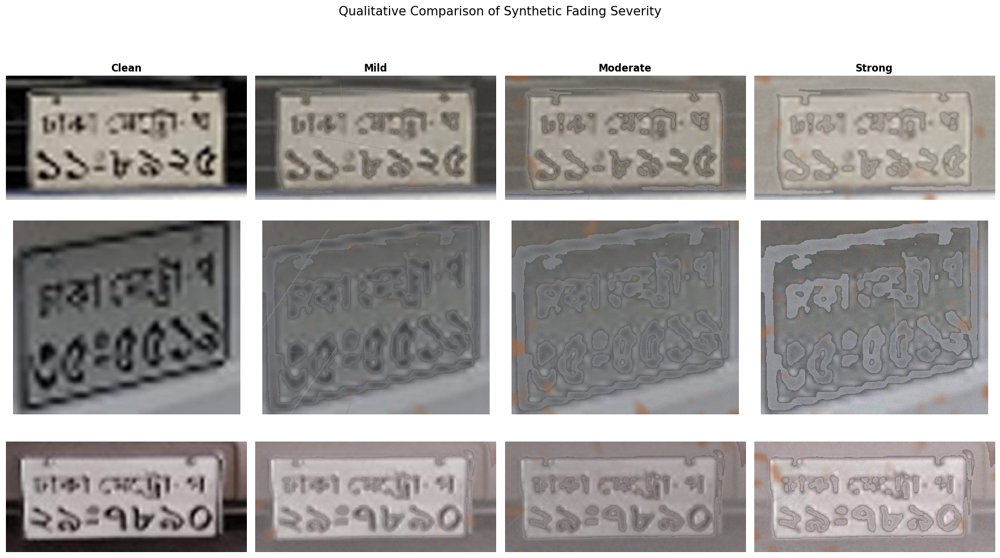

Saved thesis figure: /kaggle/working/thesis_artifacts/figures/figure_13_clean_vs_synthetic_fading.png


In [139]:
# ============================================================
# STEP 33 - Thesis figure: clean vs synthetic fading
# No training. Uses held-out test images only.
# ============================================================

import os
import sys
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

BASE = Path("/kaggle/working")
FIG_DIR = BASE / "thesis_artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load your original fading function
if "/kaggle/working" not in sys.path:
    sys.path.insert(0, "/kaggle/working")

import bd_plate_fade as fade_module

# Held-out test images from the character dataset
TEST_DIR = BASE / "bd_lpr_yolo" / "test" / "images"
LABEL_DIR = BASE / "bd_lpr_yolo" / "test" / "labels"

test_paths = []

for ext in ("*.jpg", "*.jpeg", "*.png"):
    test_paths.extend(TEST_DIR.glob(ext))

test_paths = sorted(test_paths)

assert test_paths, f"No test images found under {TEST_DIR}"

# Select three images with low, medium, and high numbers of annotated objects.
candidate_records = []

for image_path in test_paths:

    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as f:
            object_count = sum(
                1 for line in f if line.strip()
            )
    else:
        object_count = 0

    candidate_records.append(
        (image_path, object_count)
    )

candidate_records.sort(key=lambda x: x[1])

indices = [
    int(0.15 * (len(candidate_records) - 1)),
    int(0.50 * (len(candidate_records) - 1)),
    int(0.85 * (len(candidate_records) - 1))
]

selected = []
used_paths = set()

for index in indices:
    path, object_count = candidate_records[index]

    if str(path) not in used_paths:
        selected.append((path, object_count))
        used_paths.add(str(path))

# Fill any duplicate selection with another image.
for path, count in candidate_records:
    if len(selected) >= 3:
        break
    if str(path) not in used_paths:
        selected.append((path, count))
        used_paths.add(str(path))

# Fading parameters: same family as your original algorithm.
levels = {
    "Clean": None,
    "Mild": {
        "FADE_MIN": 0.35,
        "FADE_MAX": 0.55,
        "RUST": 0.04,
        "NOISE": 2.0,
        "BLUR": 0.35,
    },
    "Moderate": {
        "FADE_MIN": 0.60,
        "FADE_MAX": 0.80,
        "RUST": 0.08,
        "NOISE": 3.0,
        "BLUR": 0.65,
    },
    "Strong": {
        "FADE_MIN": 0.80,
        "FADE_MAX": 0.97,
        "RUST": 0.12,
        "NOISE": 4.0,
        "BLUR": 1.0,
    },
}

fig, axes = plt.subplots(
    len(selected),
    len(levels),
    figsize=(17, 10)
)

for row_idx, (image_path, object_count) in enumerate(selected):

    image_bgr = cv2.imread(str(image_path))

    assert image_bgr is not None, (
        f"Could not read {image_path}"
    )

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    # Give each image/severity a repeatable random seed.
    for col_idx, (level_name, params) in enumerate(levels.items()):

        ax = axes[row_idx, col_idx]

        if params is None:
            visual = image_rgb.copy()

        else:
            # Set the original function's global parameters.
            for key, value in params.items():
                setattr(fade_module, key, value)

            rng = np.random.default_rng(
                2026 + row_idx * 100 + col_idx
            )

            visual = fade_module.fade_once(
                image_rgb.copy(),
                rng=rng
            )

        ax.imshow(visual, interpolation="nearest")
        ax.axis("off")

        if row_idx == 0:
            ax.set_title(
                level_name,
                fontsize=12,
                fontweight="bold"
            )

        if col_idx == 0:
            ax.set_ylabel(
                f"Example {row_idx + 1}\n"
                f"{object_count} annotated objects",
                fontsize=9
            )

plt.suptitle(
    "Qualitative Comparison of Synthetic Fading Severity",
    fontsize=15,
    y=1.01
)

plt.tight_layout()

FIG_PATH = (
    FIG_DIR /
    "figure_13_clean_vs_synthetic_fading.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved thesis figure:", FIG_PATH)

plate_0007: Model B improvement | GT digits=111335 | A=111435 | B=111335
plate_0001: Both models correct | GT digits=116328 | A=116328 | B=116328
plate_0005: Both models wrong | GT digits=148351 | A=148 | B=14853
plate_0066: Model A only correct | GT digits=040315 | A=040315 | B=04031


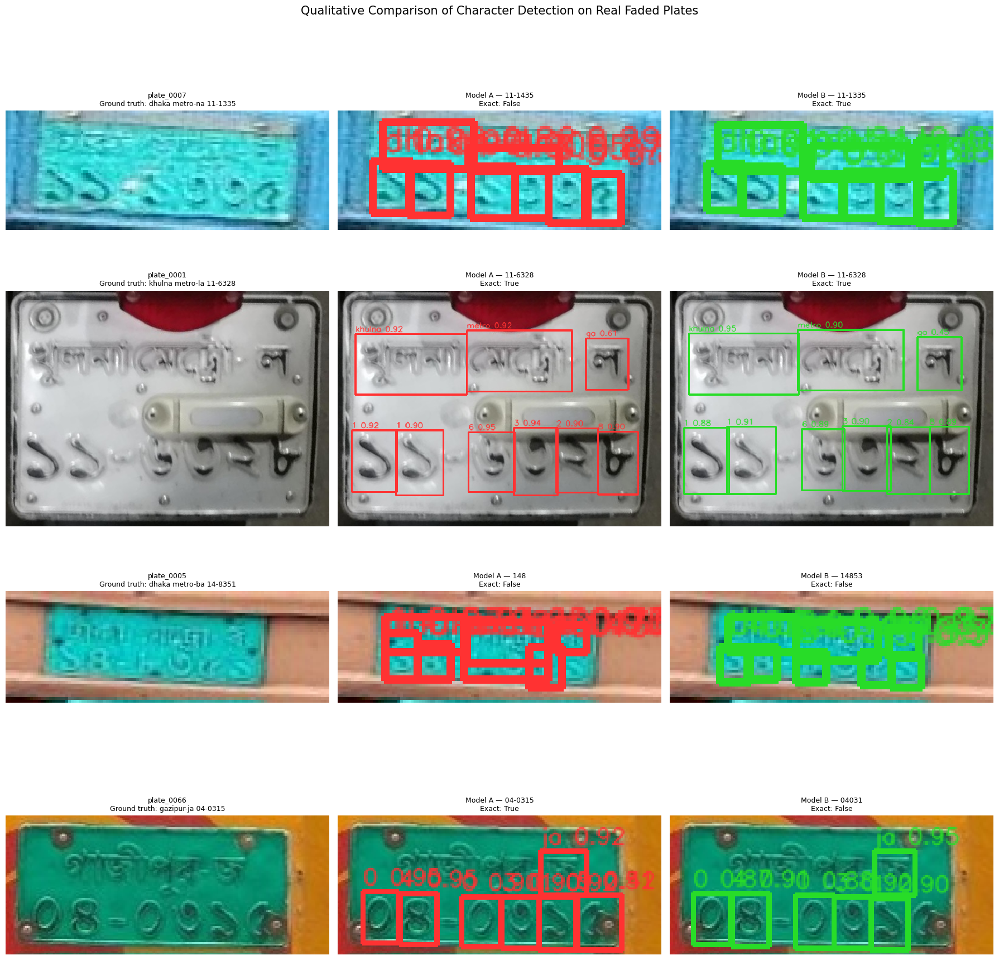


Saved thesis figure: /kaggle/working/thesis_artifacts/figures/figure_14_model_A_vs_B_real_faded_examples.png


In [140]:
# ============================================================
# STEP 34 - Thesis figure: Model A vs Model B on real faded data
# No training. Reuses saved predictions.
# ============================================================

import os
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

BASE = Path("/kaggle/working")
FIG_DIR = BASE / "thesis_artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

STANDARD_DIR = BASE / "real_faded_standardized"

EVAL_CSV = (
    BASE / "real_faded_final_evaluation" /
    "model_A_vs_B_standardized_results.csv"
)

PRED_A_CSV = (
    BASE / "real_faded_final_evaluation" /
    "model_A_detections.csv"
)

PRED_B_CSV = (
    BASE / "real_faded_final_evaluation" /
    "model_B_detections.csv"
)

GT_CSV = BASE / "real_faded_ground_truth_roman.csv"

for path in [EVAL_CSV, PRED_A_CSV, PRED_B_CSV, GT_CSV]:
    assert path.exists(), f"Required saved result not found: {path}"

eval_df = pd.read_csv(EVAL_CSV, encoding="utf-8-sig")
pred_A = pd.read_csv(PRED_A_CSV, encoding="utf-8-sig")
pred_B = pd.read_csv(PRED_B_CSV, encoding="utf-8-sig")
gt_df = pd.read_csv(GT_CSV, encoding="utf-8-sig")

gt_df["image"] = gt_df["image"].astype(str).str.strip()
gt_df["ground_truth"] = gt_df["ground_truth"].fillna("").astype(str)

gt_lookup = dict(zip(gt_df["image"], gt_df["ground_truth"]))


def normalize_image_id(value):
    return os.path.splitext(
        os.path.basename(str(value))
    )[0]


def gt_digits(text):
    match = re.search(
        r"(\d{2})-(\d{4})\s*$",
        str(text).strip()
    )
    return match.group(1) + match.group(2) if match else ""


def predicted_digits(text):
    return re.sub(r"\D", "", str(text))


# Use final ground truth, not a previously stored label.
eval_df["image_id"] = eval_df["image"].apply(normalize_image_id)
eval_df["ground_truth"] = (
    eval_df["image_id"].map(gt_lookup).fillna("")
)

eval_df["GT_digits"] = (
    eval_df["ground_truth"].apply(gt_digits)
)

for prefix in ("A", "B"):
    column = f"{prefix}_registration"

    assert column in eval_df.columns, (
        f"Missing prediction column {column}"
    )

    eval_df[f"{prefix}_digits"] = (
        eval_df[column].fillna("").apply(predicted_digits)
    )

    eval_df[f"{prefix}_correct"] = (
        eval_df[f"{prefix}_digits"] == eval_df["GT_digits"]
    )

# Avoid examples where the ground truth is missing.
labeled = eval_df[
    eval_df["GT_digits"].str.len().eq(6)
].copy()

# Find representative cases.
categories = [
    (
        "Model B improvement",
        labeled[
            ~labeled["A_correct"] & labeled["B_correct"]
        ]
    ),
    (
        "Both models correct",
        labeled[
            labeled["A_correct"] & labeled["B_correct"]
        ]
    ),
    (
        "Both models wrong",
        labeled[
            ~labeled["A_correct"] & ~labeled["B_correct"]
        ]
    ),
    (
        "Model A only correct",
        labeled[
            labeled["A_correct"] & ~labeled["B_correct"]
        ]
    )
]

selected_cases = []

for category_name, group in categories:
    if len(group):
        selected_cases.append(
            (category_name, group.iloc[0])
        )

if not selected_cases:
    raise RuntimeError(
        "No labeled real faded samples found in the evaluation file."
    )

# Ensure prediction tables use the same image-ID convention.
for df in (pred_A, pred_B):
    if "image_id" not in df.columns:
        df["image_id"] = df["image"].apply(normalize_image_id)
    else:
        df["image_id"] = df["image_id"].apply(normalize_image_id)


def draw_predictions(image_rgb, detections, color, confidence_threshold=0.25):
    """
    Draw detected bounding boxes on an RGB image.
    """
    canvas = image_rgb.copy()

    if detections.empty:
        return canvas

    for _, row in detections.iterrows():

        if float(row["confidence"]) < confidence_threshold:
            continue

        x1 = int(round(float(row["x1"])))
        y1 = int(round(float(row["y1"])))
        x2 = int(round(float(row["x2"])))
        y2 = int(round(float(row["y2"])))

        h, w = canvas.shape[:2]

        x1 = max(0, min(x1, w - 1))
        x2 = max(0, min(x2, w - 1))
        y1 = max(0, min(y1, h - 1))
        y2 = max(0, min(y2, h - 1))

        if x2 <= x1 or y2 <= y1:
            continue

        cv2.rectangle(
            canvas,
            (x1, y1),
            (x2, y2),
            color,
            2
        )

        label = (
            f'{row["class_name"]} '
            f'{float(row["confidence"]):.2f}'
        )

        cv2.putText(
            canvas,
            label,
            (x1, max(15, y1 - 4)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.42,
            color,
            1,
            cv2.LINE_AA
        )

    return canvas


# Plot input, Model A, and Model B side by side.
fig, axes = plt.subplots(
    len(selected_cases),
    3,
    figsize=(18, 4.5 * len(selected_cases))
)

axes = np.atleast_2d(axes)

for row_idx, (category_name, row) in enumerate(selected_cases):

    image_id = row["image_id"]

    image_candidates = [
        STANDARD_DIR / f"{image_id}.jpg",
        STANDARD_DIR / f"{image_id}.jpeg",
        STANDARD_DIR / f"{image_id}.png"
    ]

    image_path = next(
        (p for p in image_candidates if p.exists()),
        None
    )

    if image_path is None:
        print("Image not found; skipping:", image_id)
        for ax in axes[row_idx]:
            ax.axis("off")
        continue

    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        for ax in axes[row_idx]:
            ax.axis("off")
        continue

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    a_boxes = pred_A[
        pred_A["image_id"] == image_id
    ]

    b_boxes = pred_B[
        pred_B["image_id"] == image_id
    ]

    image_A = draw_predictions(
        image_rgb, a_boxes, (255, 50, 50)
    )

    image_B = draw_predictions(
        image_rgb, b_boxes, (40, 220, 40)
    )

    axes[row_idx, 0].imshow(
        image_rgb,
        interpolation="nearest"
    )

    axes[row_idx, 0].set_title(
        f"{image_id}\nGround truth: {row['ground_truth']}",
        fontsize=9
    )

    axes[row_idx, 1].imshow(
        image_A,
        interpolation="nearest"
    )

    axes[row_idx, 1].set_title(
        f"Model A — {row['A_registration']}\n"
        f"Exact: {bool(row['A_correct'])}",
        fontsize=9
    )

    axes[row_idx, 2].imshow(
        image_B,
        interpolation="nearest"
    )

    axes[row_idx, 2].set_title(
        f"Model B — {row['B_registration']}\n"
        f"Exact: {bool(row['B_correct'])}",
        fontsize=9
    )

    for ax in axes[row_idx]:
        ax.axis("off")

    print(
        f"{image_id}: {category_name} | "
        f"GT digits={row['GT_digits']} | "
        f"A={row['A_digits']} | "
        f"B={row['B_digits']}"
    )

plt.suptitle(
    "Qualitative Comparison of Character Detection on Real Faded Plates",
    fontsize=15,
    y=1.01
)

plt.tight_layout()

FIG_PATH = (
    FIG_DIR /
    "figure_14_model_A_vs_B_real_faded_examples.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nSaved thesis figure:", FIG_PATH)

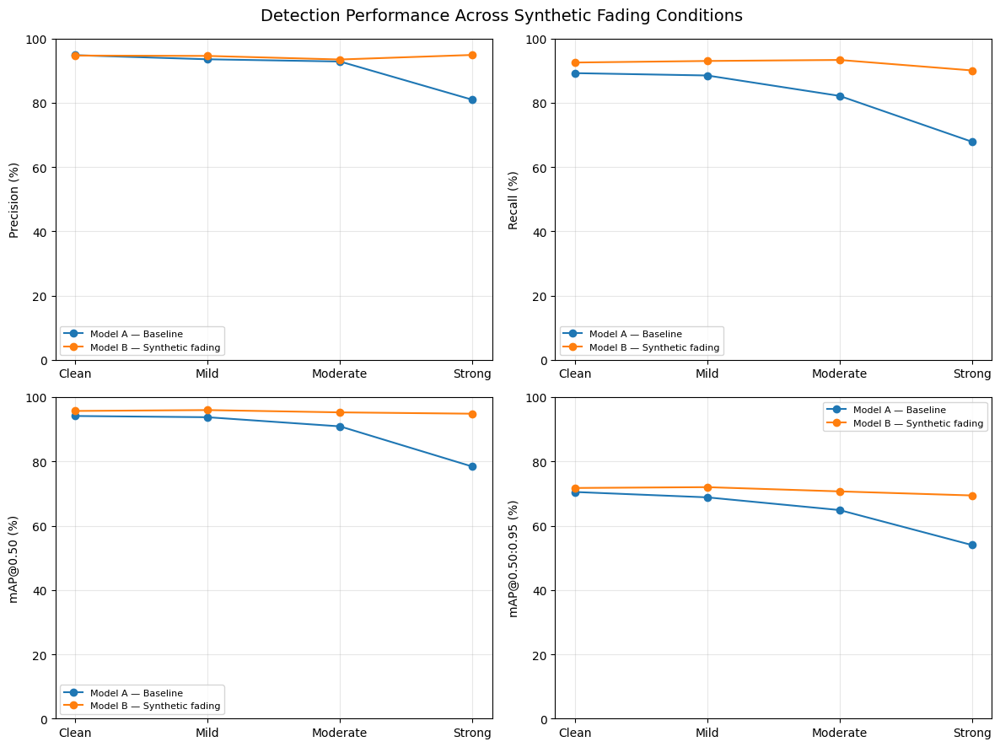

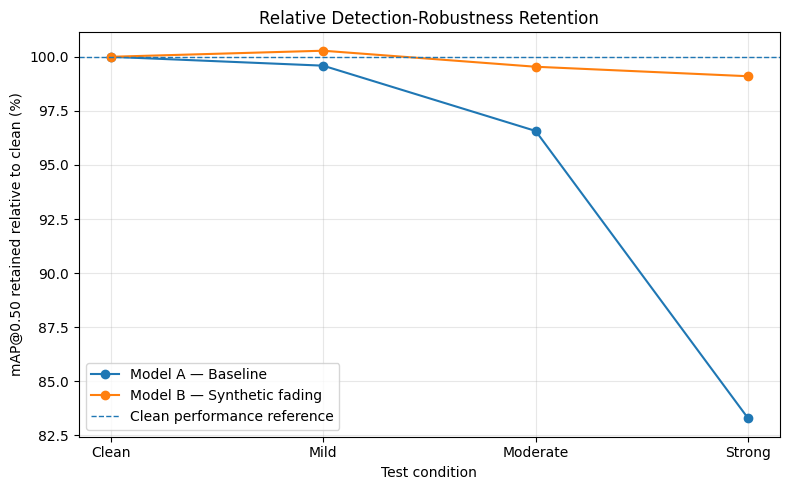

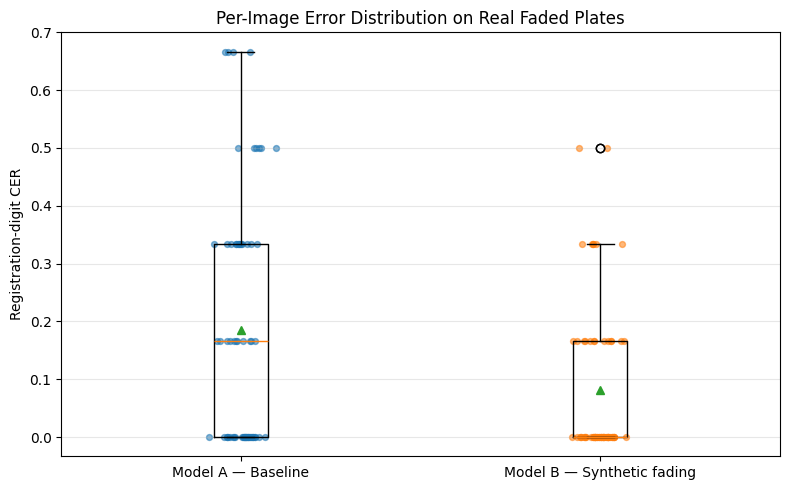

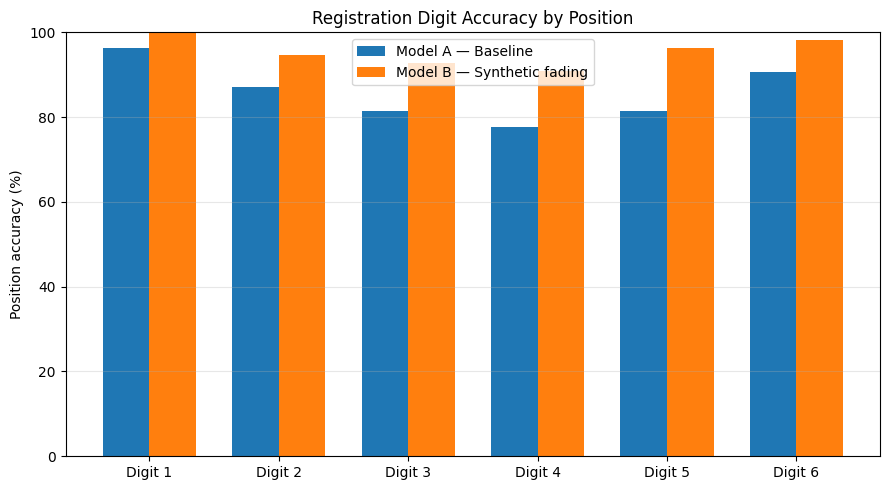

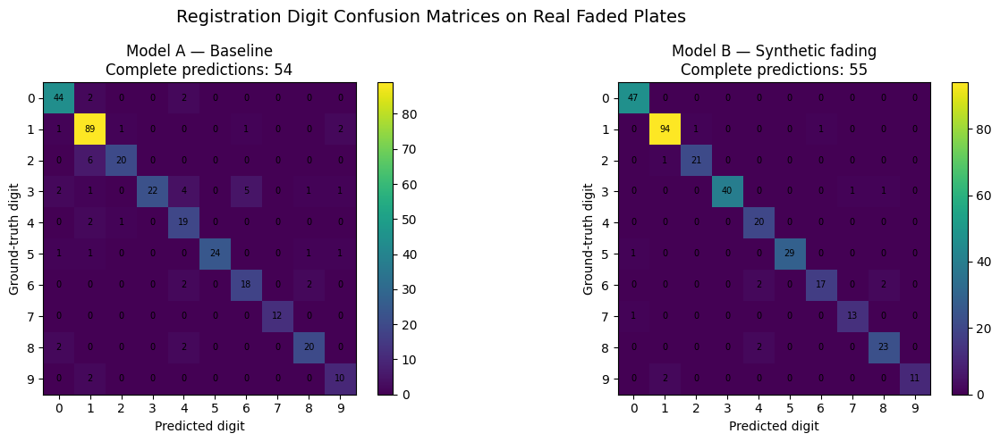


Figures saved:
/kaggle/working/thesis_artifacts/figures/figure_15_detection_metrics_grid.png
/kaggle/working/thesis_artifacts/figures/figure_16_map50_retention.png
/kaggle/working/thesis_artifacts/figures/figure_17_real_faded_cer_distribution.png
/kaggle/working/thesis_artifacts/figures/figure_18_digit_position_accuracy.png
/kaggle/working/thesis_artifacts/figures/figure_19_digit_confusion_matrices.png

Tables saved:
/kaggle/working/thesis_artifacts/tables/table_digit_position_accuracy.csv
/kaggle/working/thesis_artifacts/tables/table_real_faded_per_image_cer.csv


In [141]:
# ============================================================
# STEP 36 - Quantitative thesis figures
# No training; uses saved results
# ============================================================

from pathlib import Path
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("/kaggle/working")
FIG_DIR = BASE / "thesis_artifacts" / "figures"
TAB_DIR = BASE / "thesis_artifacts" / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

ROBUST_PATH = BASE / "lpr_robustness_comparison.csv"
REAL_PATH = (
    BASE / "real_faded_final_evaluation"
    / "model_A_vs_B_standardized_results.csv"
)
GT_PATH = BASE / "real_faded_ground_truth_roman.csv"

for path in [ROBUST_PATH, REAL_PATH, GT_PATH]:
    assert path.exists(), f"Missing file: {path}"

robust = pd.read_csv(ROBUST_PATH)
real = pd.read_csv(REAL_PATH)
gt = pd.read_csv(GT_PATH, encoding="utf-8-sig")

conditions = [
    "clean",
    "synthetic_mild",
    "synthetic_moderate",
    "synthetic_strong"
]

condition_labels = [
    "Clean",
    "Mild",
    "Moderate",
    "Strong"
]

A_NAME = "A_baseline"
B_NAME = "B_synthetic_fading"

# ------------------------------------------------------------
# FIGURE 15 - Four detection metrics across degradation levels
# ------------------------------------------------------------

metric_specs = [
    ("precision", "Precision (%)"),
    ("recall", "Recall (%)"),
    ("mAP50", "mAP@0.50 (%)"),
    ("mAP50_95", "mAP@0.50:0.95 (%)")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

for ax, (metric, ylabel) in zip(axes, metric_specs):

    pivot = (
        robust.pivot(
            index="condition",
            columns="model",
            values=metric
        )
        .reindex(conditions)
    )

    ax.plot(
        condition_labels,
        pivot[A_NAME].values * 100,
        marker="o",
        label="Model A — Baseline"
    )

    ax.plot(
        condition_labels,
        pivot[B_NAME].values * 100,
        marker="o",
        label="Model B — Synthetic fading"
    )

    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle(
    "Detection Performance Across Synthetic Fading Conditions",
    fontsize=14
)

plt.tight_layout()

FIG15 = FIG_DIR / "figure_15_detection_metrics_grid.png"

plt.savefig(FIG15, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# FIGURE 16 - Performance retention relative to clean images
# ------------------------------------------------------------

pivot = robust.pivot(
    index="condition",
    columns="model",
    values="mAP50"
).reindex(conditions)

clean_A = float(pivot.loc["clean", A_NAME])
clean_B = float(pivot.loc["clean", B_NAME])

retention_A = 100 * pivot[A_NAME] / clean_A
retention_B = 100 * pivot[B_NAME] / clean_B

plt.figure(figsize=(8, 5))

plt.plot(
    condition_labels,
    retention_A.values,
    marker="o",
    label="Model A — Baseline"
)

plt.plot(
    condition_labels,
    retention_B.values,
    marker="o",
    label="Model B — Synthetic fading"
)

plt.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="Clean performance reference"
)

plt.ylabel("mAP@0.50 retained relative to clean (%)")
plt.xlabel("Test condition")
plt.title("Relative Detection-Robustness Retention")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

FIG16 = FIG_DIR / "figure_16_map50_retention.png"

plt.savefig(FIG16, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# Prepare per-image real-faded registration results
# ------------------------------------------------------------

gt["image"] = gt["image"].astype(str).str.strip()
gt["ground_truth"] = gt["ground_truth"].fillna("").astype(str)

gt_map = dict(zip(gt["image"], gt["ground_truth"]))

real["image_id"] = real["image"].apply(
    lambda x: os.path.splitext(os.path.basename(str(x)))[0]
)

real["ground_truth"] = (
    real["image_id"].map(gt_map).fillna("")
)

def extract_registration(text):
    match = re.search(
        r"(\d{2})-(\d{4})\s*$",
        str(text).strip()
    )
    return match.group(1) + match.group(2) if match else ""

def digit_sequence(text):
    return re.sub(r"\D", "", str(text))

def levenshtein_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(
                min(
                    current[j - 1] + 1,
                    previous[j] + 1,
                    previous[j - 1] + (ca != cb)
                )
            )

        previous = current

    return previous[-1]

real["GT_digits"] = real["ground_truth"].apply(
    extract_registration
)

real["A_digits"] = (
    real["A_registration"].fillna("").apply(digit_sequence)
)

real["B_digits"] = (
    real["B_registration"].fillna("").apply(digit_sequence)
)

# Only the 64 images with valid ground truth are evaluated.
real_eval = real[
    real["GT_digits"].str.len().eq(6)
].copy()

assert len(real_eval) == 64, (
    f"Expected 64 labeled images, got {len(real_eval)}. "
    "Check the ground-truth CSV before interpreting figures."
)

for prefix in ["A", "B"]:

    pred_col = f"{prefix}_digits"

    real_eval[f"{prefix}_CER"] = real_eval.apply(
        lambda r: (
            levenshtein_distance(
                r["GT_digits"],
                r[pred_col]
            ) / 6.0
        ),
        axis=1
    )

    real_eval[f"{prefix}_exact"] = (
        real_eval[pred_col] == real_eval["GT_digits"]
    )


# ------------------------------------------------------------
# FIGURE 17 - Per-image character error rate
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        real_eval["A_CER"].values,
        real_eval["B_CER"].values
    ],
    tick_labels=[
        "Model A — Baseline",
        "Model B — Synthetic fading"
    ],
    showmeans=True
)

# Add light jittered points so the variation is visible.
rng = np.random.default_rng(42)

for x_pos, col in [
    (1, "A_CER"),
    (2, "B_CER")
]:
    jitter = rng.normal(
        loc=x_pos,
        scale=0.045,
        size=len(real_eval)
    )

    plt.scatter(
        jitter,
        real_eval[col],
        alpha=0.55,
        s=18
    )

plt.ylabel("Registration-digit CER")
plt.title("Per-Image Error Distribution on Real Faded Plates")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

FIG17 = FIG_DIR / "figure_17_real_faded_cer_distribution.png"

plt.savefig(FIG17, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# FIGURE 18 - Digit-position accuracy
# ------------------------------------------------------------

position_rows = []

for prefix in ["A", "B"]:

    pred_col = f"{prefix}_digits"

    # Position-wise accuracy is computed only for complete
    # six-digit predictions, so positions align correctly.
    complete = real_eval[
        real_eval[pred_col].str.len().eq(6)
    ].copy()

    for position in range(6):

        correct_count = int(
            (
                complete[pred_col].str[position]
                == complete["GT_digits"].str[position]
            ).sum()
        )

        count = len(complete)

        position_rows.append({
            "model": prefix,
            "position": position + 1,
            "complete_predictions": count,
            "correct_at_position": correct_count,
            "accuracy": (
                correct_count / count
                if count else np.nan
            )
        })

position_df = pd.DataFrame(position_rows)

position_df.to_csv(
    TAB_DIR / "table_digit_position_accuracy.csv",
    index=False
)

plt.figure(figsize=(9, 5))

x = np.arange(6)
bar_width = 0.36

for model_name, label, offset in [
    ("A", "Model A — Baseline", -bar_width / 2),
    ("B", "Model B — Synthetic fading", bar_width / 2)
]:

    vals = (
        position_df[position_df["model"] == model_name]
        .sort_values("position")["accuracy"]
        .values
    )

    plt.bar(
        x + offset,
        vals * 100,
        width=bar_width,
        label=label
    )

plt.xticks(x, ["Digit 1", "Digit 2", "Digit 3", "Digit 4", "Digit 5", "Digit 6"])
plt.ylabel("Position accuracy (%)")
plt.ylim(0, 100)
plt.title("Registration Digit Accuracy by Position")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

FIG18 = FIG_DIR / "figure_18_digit_position_accuracy.png"

plt.savefig(FIG18, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# FIGURE 19 - Digit confusion matrices
# Only complete six-digit predictions are position-aligned.
# ------------------------------------------------------------

digits = list("0123456789")
digit_to_index = {d: i for i, d in enumerate(digits)}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, prefix, title in [
    (axes[0], "A", "Model A — Baseline"),
    (axes[1], "B", "Model B — Synthetic fading")
]:

    pred_col = f"{prefix}_digits"

    complete = real_eval[
        real_eval[pred_col].str.len().eq(6)
    ].copy()

    cm = np.zeros((10, 10), dtype=int)

    for _, row in complete.iterrows():

        gt_text = row["GT_digits"]
        pred_text = row[pred_col]

        for true_digit, pred_digit in zip(gt_text, pred_text):

            cm[
                digit_to_index[true_digit],
                digit_to_index[pred_digit]
            ] += 1

    image = ax.imshow(cm, interpolation="nearest")

    ax.set_title(
        f"{title}\nComplete predictions: {len(complete)}"
    )

    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("Ground-truth digit")

    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xticklabels(digits)
    ax.set_yticklabels(digits)

    # Write counts into each cell.
    for i in range(10):
        for j in range(10):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=7
            )

    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle(
    "Registration Digit Confusion Matrices on Real Faded Plates",
    fontsize=14
)

plt.tight_layout()

FIG19 = FIG_DIR / "figure_19_digit_confusion_matrices.png"

plt.savefig(FIG19, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# Save updated detailed analysis
# ------------------------------------------------------------

real_eval.to_csv(
    TAB_DIR / "table_real_faded_per_image_cer.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFigures saved:")
for p in [FIG15, FIG16, FIG17, FIG18, FIG19]:
    print(p)

print("\nTables saved:")
print(TAB_DIR / "table_digit_position_accuracy.csv")
print(TAB_DIR / "table_real_faded_per_image_cer.csv")

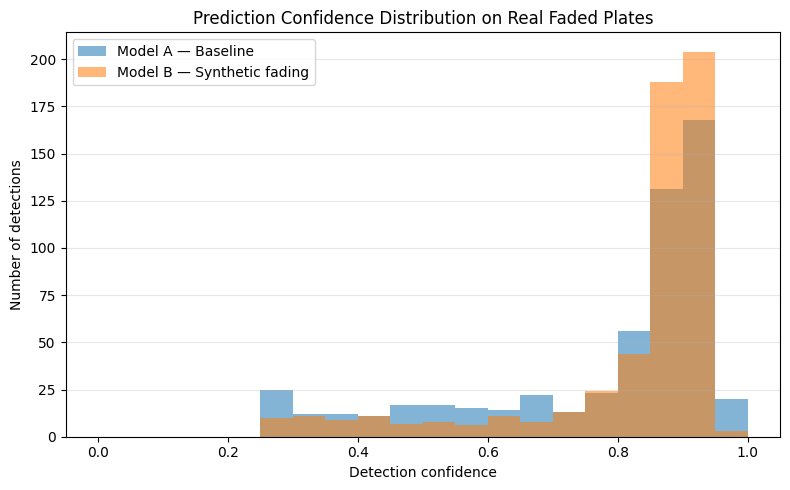

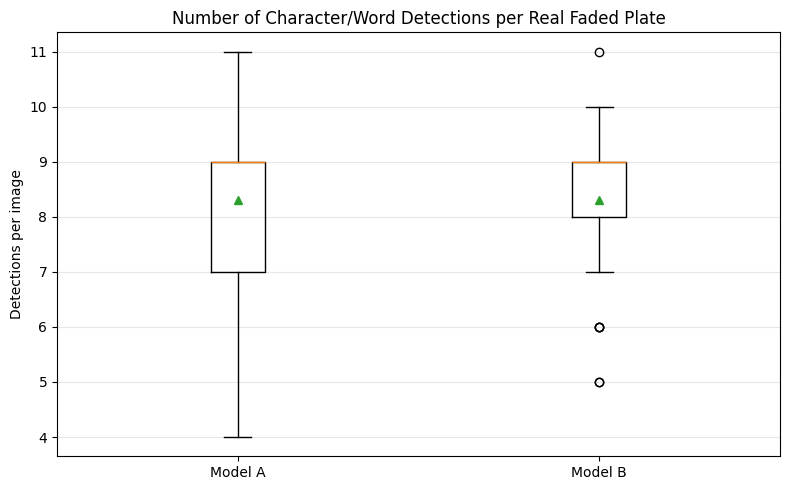

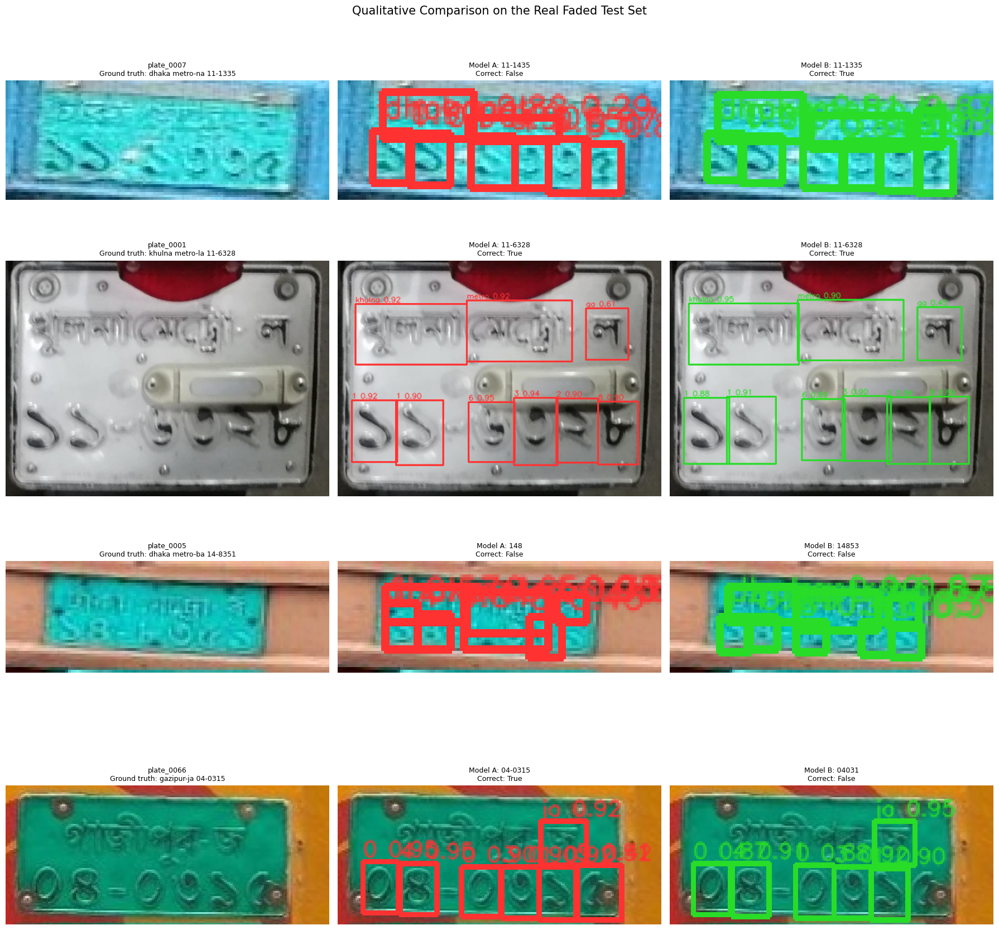

Saved: /kaggle/working/thesis_artifacts/figures/figure_22_real_faded_examples_extended.png

Additional figures saved:
/kaggle/working/thesis_artifacts/figures/figure_20_detection_confidence_distribution.png
/kaggle/working/thesis_artifacts/figures/figure_21_detections_per_image.png


In [142]:
# ============================================================
# STEP 37 - Additional visual diagnostics on real faded plates
# No training
# ============================================================

from pathlib import Path
import os
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("/kaggle/working")
FIG_DIR = BASE / "thesis_artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

STANDARD_DIR = BASE / "real_faded_standardized"

PRED_A_PATH = (
    BASE / "real_faded_final_evaluation"
    / "model_A_detections.csv"
)

PRED_B_PATH = (
    BASE / "real_faded_final_evaluation"
    / "model_B_detections.csv"
)

RESULTS_PATH = (
    BASE / "real_faded_final_evaluation"
    / "model_A_vs_B_standardized_results.csv"
)

GT_PATH = BASE / "real_faded_ground_truth_roman.csv"

for p in [PRED_A_PATH, PRED_B_PATH, RESULTS_PATH, GT_PATH]:
    assert p.exists(), f"Missing file: {p}"

pred_A = pd.read_csv(PRED_A_PATH)
pred_B = pd.read_csv(PRED_B_PATH)
results = pd.read_csv(RESULTS_PATH)
gt = pd.read_csv(GT_PATH, encoding="utf-8-sig")

for df in [pred_A, pred_B]:
    df["image_id"] = df["image"].apply(
        lambda x: os.path.splitext(
            os.path.basename(str(x))
        )[0]
    )

gt["image"] = gt["image"].astype(str).str.strip()
gt["ground_truth"] = gt["ground_truth"].fillna("").astype(str)

gt_map = dict(zip(gt["image"], gt["ground_truth"]))

results["image_id"] = results["image"].apply(
    lambda x: os.path.splitext(
        os.path.basename(str(x))
    )[0]
)

results["ground_truth"] = (
    results["image_id"].map(gt_map).fillna("")
)

def gt_digits(text):
    match = re.search(
        r"(\d{2})-(\d{4})\s*$",
        str(text).strip()
    )
    return match.group(1) + match.group(2) if match else ""

def pred_digits(text):
    return re.sub(r"\D", "", str(text))

results["GT_digits"] = results["ground_truth"].apply(gt_digits)

for prefix in ["A", "B"]:
    results[f"{prefix}_digits"] = (
        results[f"{prefix}_registration"]
        .fillna("")
        .apply(pred_digits)
    )
    results[f"{prefix}_correct"] = (
        results[f"{prefix}_digits"]
        == results["GT_digits"]
    )

labeled = results[
    results["GT_digits"].str.len().eq(6)
].copy()


# ------------------------------------------------------------
# FIGURE 20 - Detection confidence distributions
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

if not pred_A.empty:
    plt.hist(
        pred_A["confidence"].dropna(),
        bins=np.linspace(0, 1, 21),
        alpha=0.55,
        label="Model A — Baseline"
    )

if not pred_B.empty:
    plt.hist(
        pred_B["confidence"].dropna(),
        bins=np.linspace(0, 1, 21),
        alpha=0.55,
        label="Model B — Synthetic fading"
    )

plt.xlabel("Detection confidence")
plt.ylabel("Number of detections")
plt.title("Prediction Confidence Distribution on Real Faded Plates")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

FIG20 = FIG_DIR / "figure_20_detection_confidence_distribution.png"

plt.savefig(FIG20, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# FIGURE 21 - Detections per image
# ------------------------------------------------------------

all_image_ids = sorted({
    os.path.splitext(p.name)[0]
    for p in STANDARD_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
})

count_A = pred_A.groupby("image_id").size()
count_B = pred_B.groupby("image_id").size()

counts_df = pd.DataFrame({
    "image_id": all_image_ids,
    "Model A": [int(count_A.get(x, 0)) for x in all_image_ids],
    "Model B": [int(count_B.get(x, 0)) for x in all_image_ids]
})

counts_df.to_csv(
    BASE / "thesis_artifacts/tables/table_detections_per_real_plate.csv",
    index=False
)

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        counts_df["Model A"].values,
        counts_df["Model B"].values
    ],
    tick_labels=["Model A", "Model B"],
    showmeans=True
)

plt.ylabel("Detections per image")
plt.title("Number of Character/Word Detections per Real Faded Plate")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

FIG21 = FIG_DIR / "figure_21_detections_per_image.png"

plt.savefig(FIG21, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# FIGURE 22 - Example predictions, same image in all columns
# ------------------------------------------------------------

categories = [
    (
        "Model B improves",
        labeled[
            ~labeled["A_correct"] & labeled["B_correct"]
        ]
    ),
    (
        "Both correct",
        labeled[
            labeled["A_correct"] & labeled["B_correct"]
        ]
    ),
    (
        "Both wrong",
        labeled[
            ~labeled["A_correct"] & ~labeled["B_correct"]
        ]
    ),
    (
        "Model A only correct",
        labeled[
            labeled["A_correct"] & ~labeled["B_correct"]
        ]
    )
]

selected_cases = []

for title, group in categories:
    if len(group):
        selected_cases.append((title, group.iloc[0]))

selected_cases = selected_cases[:4]

def find_image_path(image_id):
    for ext in [".jpg", ".jpeg", ".png"]:
        p = STANDARD_DIR / f"{image_id}{ext}"
        if p.exists():
            return p
    return None

def draw_boxes(image_rgb, det_df, color):
    canvas = image_rgb.copy()
    h, w = canvas.shape[:2]

    for _, row in det_df.iterrows():

        if float(row["confidence"]) < 0.25:
            continue

        x1, y1, x2, y2 = [
            int(round(float(row[k])))
            for k in ["x1", "y1", "x2", "y2"]
        ]

        x1 = max(0, min(x1, w - 1))
        x2 = max(0, min(x2, w - 1))
        y1 = max(0, min(y1, h - 1))
        y2 = max(0, min(y2, h - 1))

        if x2 <= x1 or y2 <= y1:
            continue

        cv2.rectangle(
            canvas,
            (x1, y1),
            (x2, y2),
            color,
            2
        )

        label = (
            f'{row["class_name"]} '
            f'{float(row["confidence"]):.2f}'
        )

        cv2.putText(
            canvas,
            label,
            (x1, max(14, y1 - 3)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            color,
            1,
            cv2.LINE_AA
        )

    return canvas


if selected_cases:

    fig, axes = plt.subplots(
        len(selected_cases),
        3,
        figsize=(18, 4.5 * len(selected_cases))
    )

    axes = np.atleast_2d(axes)

    for row_idx, (category_title, case) in enumerate(selected_cases):

        image_id = case["image_id"]
        image_path = find_image_path(image_id)

        if image_path is None:
            for ax in axes[row_idx]:
                ax.axis("off")
            continue

        img_bgr = cv2.imread(str(image_path))

        if img_bgr is None:
            for ax in axes[row_idx]:
                ax.axis("off")
            continue

        img_rgb = cv2.cvtColor(
            img_bgr,
            cv2.COLOR_BGR2RGB
        )

        a_rows = pred_A[
            pred_A["image_id"] == image_id
        ]

        b_rows = pred_B[
            pred_B["image_id"] == image_id
        ]

        canvas_A = draw_boxes(
            img_rgb, a_rows, (255, 50, 50)
        )

        canvas_B = draw_boxes(
            img_rgb, b_rows, (40, 220, 40)
        )

        axes[row_idx, 0].imshow(img_rgb)
        axes[row_idx, 0].set_title(
            f"{image_id}\nGround truth: {case['ground_truth']}",
            fontsize=9
        )

        axes[row_idx, 1].imshow(canvas_A)
        axes[row_idx, 1].set_title(
            f"Model A: {case['A_registration']}\n"
            f"Correct: {bool(case['A_correct'])}",
            fontsize=9
        )

        axes[row_idx, 2].imshow(canvas_B)
        axes[row_idx, 2].set_title(
            f"Model B: {case['B_registration']}\n"
            f"Correct: {bool(case['B_correct'])}",
            fontsize=9
        )

        axes[row_idx, 0].set_ylabel(
            category_title,
            fontsize=10
        )

        for ax in axes[row_idx]:
            ax.axis("off")

    plt.suptitle(
        "Qualitative Comparison on the Real Faded Test Set",
        fontsize=15
    )

    plt.tight_layout()

    FIG22 = FIG_DIR / "figure_22_real_faded_examples_extended.png"

    plt.savefig(FIG22, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", FIG22)

else:
    print("No labeled cases available for this figure.")


print("\nAdditional figures saved:")
print(FIG20)
print(FIG21)

In [143]:
# ============================================================
# STEP 38 - Collect saved Ultralytics training diagnostics
# No training
# ============================================================

from pathlib import Path
import shutil

BASE = Path("/kaggle/working")
FIG_DIR = BASE / "thesis_artifacts" / "figures"
DIAG_DIR = FIG_DIR / "ultralytics_diagnostics"

DIAG_DIR.mkdir(parents=True, exist_ok=True)

run_dirs = {
    "model_A": BASE / "lpr_training/model_A_baseline",
    "model_B": BASE / "lpr_training/model_B_synthetic_fading",
    "plate_detector": (
        BASE / "lp_detection_training/license_plate_yolov8n"
    )
}

allowed_extensions = {".png", ".jpg", ".jpeg"}

copied = []

for run_name, run_dir in run_dirs.items():

    if not run_dir.exists():
        print("Run folder missing:", run_dir)
        continue

    for path in run_dir.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in allowed_extensions:
            continue

        # Preserve important training curves, class plots,
        # PR curves and confusion matrices.
        destination_name = f"{run_name}_{path.name}"
        destination = DIAG_DIR / destination_name

        if destination.exists():
            continue

        shutil.copy2(path, destination)
        copied.append(destination_name)

print("Diagnostic images copied:", len(copied))

for filename in sorted(p.name for p in DIAG_DIR.iterdir() if p.is_file()):
    print(filename)

Diagnostic images copied: 60
model_A_BoxF1_curve.png
model_A_BoxPR_curve.png
model_A_BoxP_curve.png
model_A_BoxR_curve.png
model_A_confusion_matrix.png
model_A_confusion_matrix_normalized.png
model_A_labels.jpg
model_A_results.png
model_A_train_batch0.jpg
model_A_train_batch1.jpg
model_A_train_batch2.jpg
model_A_train_batch8720.jpg
model_A_train_batch8721.jpg
model_A_train_batch8722.jpg
model_A_val_batch0_labels.jpg
model_A_val_batch0_pred.jpg
model_A_val_batch1_labels.jpg
model_A_val_batch1_pred.jpg
model_A_val_batch2_labels.jpg
model_A_val_batch2_pred.jpg
model_B_BoxF1_curve.png
model_B_BoxPR_curve.png
model_B_BoxP_curve.png
model_B_BoxR_curve.png
model_B_confusion_matrix.png
model_B_confusion_matrix_normalized.png
model_B_labels.jpg
model_B_results.png
model_B_train_batch0.jpg
model_B_train_batch1.jpg
model_B_train_batch2.jpg
model_B_train_batch8720.jpg
model_B_train_batch8721.jpg
model_B_train_batch8722.jpg
model_B_val_batch0_labels.jpg
model_B_val_batch0_pred.jpg
model_B_val_batch

In [144]:
# ============================================================
# STEP 38 - Collect saved Ultralytics training diagnostics
# No training
# ============================================================

from pathlib import Path
import shutil

BASE = Path("/kaggle/working")
FIG_DIR = BASE / "thesis_artifacts" / "figures"
DIAG_DIR = FIG_DIR / "ultralytics_diagnostics"

DIAG_DIR.mkdir(parents=True, exist_ok=True)

run_dirs = {
    "model_A": BASE / "lpr_training/model_A_baseline",
    "model_B": BASE / "lpr_training/model_B_synthetic_fading",
    "plate_detector": (
        BASE / "lp_detection_training/license_plate_yolov8n"
    )
}

allowed_extensions = {".png", ".jpg", ".jpeg"}

copied = []

for run_name, run_dir in run_dirs.items():

    if not run_dir.exists():
        print("Run folder missing:", run_dir)
        continue

    for path in run_dir.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in allowed_extensions:
            continue

        # Preserve important training curves, class plots,
        # PR curves and confusion matrices.
        destination_name = f"{run_name}_{path.name}"
        destination = DIAG_DIR / destination_name

        if destination.exists():
            continue

        shutil.copy2(path, destination)
        copied.append(destination_name)

print("Diagnostic images copied:", len(copied))

for filename in sorted(p.name for p in DIAG_DIR.iterdir() if p.is_file()):
    print(filename)

Diagnostic images copied: 0
model_A_BoxF1_curve.png
model_A_BoxPR_curve.png
model_A_BoxP_curve.png
model_A_BoxR_curve.png
model_A_confusion_matrix.png
model_A_confusion_matrix_normalized.png
model_A_labels.jpg
model_A_results.png
model_A_train_batch0.jpg
model_A_train_batch1.jpg
model_A_train_batch2.jpg
model_A_train_batch8720.jpg
model_A_train_batch8721.jpg
model_A_train_batch8722.jpg
model_A_val_batch0_labels.jpg
model_A_val_batch0_pred.jpg
model_A_val_batch1_labels.jpg
model_A_val_batch1_pred.jpg
model_A_val_batch2_labels.jpg
model_A_val_batch2_pred.jpg
model_B_BoxF1_curve.png
model_B_BoxPR_curve.png
model_B_BoxP_curve.png
model_B_BoxR_curve.png
model_B_confusion_matrix.png
model_B_confusion_matrix_normalized.png
model_B_labels.jpg
model_B_results.png
model_B_train_batch0.jpg
model_B_train_batch1.jpg
model_B_train_batch2.jpg
model_B_train_batch8720.jpg
model_B_train_batch8721.jpg
model_B_train_batch8722.jpg
model_B_val_batch0_labels.jpg
model_B_val_batch0_pred.jpg
model_B_val_batch1

In [145]:
import zipfile, os, shutil

src = '/kaggle/working'
dst = '/tmp/working_all.zip'
exclude_dirs = {'.virtual_documents'}   # folders to skip

with zipfile.ZipFile(dst, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(src):
        dirs[:] = [d for d in dirs if d not in exclude_dirs]
        for f in files:
            p = os.path.join(root, f)
            z.write(p, os.path.relpath(p, src))

# move the archive into /kaggle/working so it appears in the Output pane
shutil.copy(dst, os.path.join(src, 'working_all.zip'))
print('Done:', os.path.getsize('/kaggle/working/working_all.zip') / 1e6, 'MB')

Done: 2036.449138 MB


In [146]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

# Existing trained model — no training required
MODEL_PATH = Path(
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

# These images are already standardized plate crops.
# Do not run the plate-localization detector on them again.
IMAGE_DIR = Path("/kaggle/working/real_faded_standardized")

GT_PATH = Path(
    "/kaggle/working/real_faded_ground_truth_roman.csv"
)

for path in [MODEL_PATH, IMAGE_DIR, GT_PATH]:
    print(f"{path}: {'FOUND' if path.exists() else 'MISSING'}")

assert MODEL_PATH.exists(), "Model B weights are missing."
assert IMAGE_DIR.exists(), "Plate image directory is missing."
assert GT_PATH.exists(), "Ground-truth CSV is missing."

model = YOLO(str(MODEL_PATH))
gt = pd.read_csv(GT_PATH)

images = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print("\nModel classes:")
print(model.names)

print("\nImages available:", len(images))
print("Ground-truth columns:", gt.columns.tolist())
print("\nGround-truth preview:")
print(gt.head().to_string(index=False))

/kaggle/working/lpr_training/model_B_synthetic_fading/weights/best.pt: FOUND
/kaggle/working/real_faded_standardized: FOUND
/kaggle/working/real_faded_ground_truth_roman.csv: FOUND

Model classes:
{0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'ka', 11: 'kha', 12: 'ga', 13: 'gha', 14: 'ca', 15: 'ja', 16: 'ta', 17: 'da', 18: 'na', 19: 'ba', 20: 'va', 21: 'ha', 22: 'metro', 23: 'dhaka', 24: 'khulna', 25: 'chattogram', 26: 'jashore'}

Images available: 67
Ground-truth columns: ['image', 'ground_truth', 'normalized_ground_truth', 'has_ground_truth']

Ground-truth preview:
     image            ground_truth normalized_ground_truth  has_ground_truth
plate_0001 khulna metro-la 11-6328   khulnametro-la11-6328              True
plate_0002                     NaN                     NaN             False
plate_0003   dhaka metro-u 20-5938     dhakametro-u20-5938              True
plate_0004  dhaka metro-ga 31-8763    dhakametro-ga31-8763              True
pl

In [147]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/plate_text_recognition")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def normalize_text(value):
    """Normalize Romanized plate text for comparison."""
    if pd.isna(value):
        return ""
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def get_reading_order(detections):
    """
    Group detections into approximate text rows, then sort
    each row from left to right.
    """
    if not detections:
        return []

    heights = [
        max(1, d["y2"] - d["y1"])
        for d in detections
    ]
    row_threshold = max(8, 0.8 * float(np.median(heights)))

    by_y = sorted(detections, key=lambda d: d["cy"])
    rows = []

    for det in by_y:
        if not rows:
            rows.append([det])
            continue

        current_center = np.mean([item["cy"] for item in rows[-1]])

        if abs(det["cy"] - current_center) <= row_threshold:
            rows[-1].append(det)
        else:
            rows.append([det])

    rows.sort(key=lambda row: np.mean([d["cy"] for d in row]))

    ordered = []
    for row_number, row in enumerate(rows, start=1):
        row.sort(key=lambda d: d["cx"])
        for det in row:
            det["row"] = row_number
            ordered.append(det)

    return ordered


prediction_rows = []
box_rows = []

for index, image_path in enumerate(images, start=1):
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    detections = []

    if result.boxes is not None and len(result.boxes) > 0:
        xyxy = result.boxes.xyxy.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        confidences = result.boxes.conf.cpu().numpy()

        for box, class_id, confidence in zip(
            xyxy, classes, confidences
        ):
            x1, y1, x2, y2 = map(float, box)

            if isinstance(model.names, dict):
                token = model.names[int(class_id)]
            else:
                token = model.names[int(class_id)]

            detections.append({
                "image_id": image_path.stem,
                "token": str(token).strip().lower(),
                "class_id": int(class_id),
                "confidence": float(confidence),
                "x1": x1, "y1": y1,
                "x2": x2, "y2": y2,
                "cx": (x1 + x2) / 2,
                "cy": (y1 + y2) / 2
            })

    ordered = get_reading_order(detections)
    tokens = [d["token"] for d in ordered]

    # The raw token list is useful for diagnosing failed recognition.
    predicted_text = " ".join(tokens)

    prediction_rows.append({
        "image_id": image_path.stem,
        "image_file": image_path.name,
        "predicted_text": predicted_text,
        "predicted_normalized": normalize_text(predicted_text),
        "num_detections": len(ordered)
    })

    for det in ordered:
        box_rows.append(det.copy())

    if index % 10 == 0 or index == len(images):
        print(f"Processed {index}/{len(images)} images")

predictions = pd.DataFrame(prediction_rows)
box_details = pd.DataFrame(box_rows)

pred_path = OUTPUT_DIR / "full_plate_predictions.csv"
box_path = OUTPUT_DIR / "individual_character_detections.csv"

predictions.to_csv(pred_path, index=False)
box_details.to_csv(box_path, index=False)

print("\nSaved:")
print(pred_path)
print(box_path)

print("\nExample reconstructed predictions:")
print(
    predictions[
        ["image_id", "predicted_text", "num_detections"]
    ].head(15).to_string(index=False)
)

Processed 10/67 images
Processed 20/67 images
Processed 30/67 images
Processed 40/67 images
Processed 50/67 images
Processed 60/67 images
Processed 67/67 images

Saved:
/kaggle/working/plate_text_recognition/full_plate_predictions.csv
/kaggle/working/plate_text_recognition/individual_character_detections.csv

Example reconstructed predictions:
  image_id                predicted_text  num_detections
plate_0001   khulna metro ga 1 1 6 3 2 8               9
plate_0002             dhaka metro 2 3 2               5
plate_0003    2 dhaka 0 5 metro 9 3 ja 8               9
plate_0004    3 dhaka 1 8 metro 7 6 ga 3               9
plate_0005      1 dhaka 4 8 metro 5 ba 3               8
plate_0006       2 dhaka 0 1 metro 3 0 0               8
plate_0007    1 dhaka 1 1 metro 3 3 ta 5               9
plate_0008    1 dhaka 4 9 metro 8 0 ba 3               9
plate_0009         1 dhaka 2 1 metro 2 4               7
plate_0010    1 dhaka 1 0 metro 8 6 ga 1               9
plate_0011    dhaka metro j

In [148]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/plate_text_recognition")

predictions = pd.read_csv(
    OUTPUT_DIR / "full_plate_predictions.csv"
)
gt = pd.read_csv(GT_PATH)

# Identify the image-ID column.
id_candidates = [
    "image_id", "image", "image_name", "filename",
    "file_name", "plate_id", "id"
]
id_col = next(
    (c for c in id_candidates if c in gt.columns),
    None
)

# Identify the ground-truth text column.
text_candidates = [
    "normalized_ground_truth", "ground_truth",
    "gt_text", "plate_text", "text"
]
gt_col = next(
    (c for c in text_candidates if c in gt.columns),
    None
)

if id_col is None or gt_col is None:
    raise ValueError(
        f"Cannot identify ID/text columns. "
        f"Available columns: {gt.columns.tolist()}"
    )

def normalise(value):
    if pd.isna(value):
        return ""
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def edit_distance(a, b):
    """Levenshtein edit distance."""
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,          # insertion
                previous[j] + 1,          # deletion
                previous[j - 1] + (ca != cb)  # substitution
            ))
        previous = current

    return previous[-1]

pred_lookup = {
    str(row["image_id"]): row
    for _, row in predictions.iterrows()
}

# Keep labeled rows only.
if "has_ground_truth" in gt.columns:
    valid_flags = gt["has_ground_truth"].astype(str).str.lower().isin(
        ["true", "1", "yes", "y"]
    )
else:
    valid_flags = gt[gt_col].notna() & (
        gt[gt_col].astype(str).str.strip() != ""
    )

evaluation_rows = []

for _, row in gt[valid_flags].iterrows():
    image_id = Path(str(row[id_col])).stem

    if image_id not in pred_lookup:
        continue

    truth = normalise(row[gt_col])
    pred_text = str(pred_lookup[image_id]["predicted_text"])
    predicted = normalise(pred_text)

    if not truth:
        continue

    distance = edit_distance(truth, predicted)

    evaluation_rows.append({
        "image_id": image_id,
        "ground_truth": row[gt_col],
        "predicted_text": pred_text,
        "ground_truth_normalized": truth,
        "prediction_normalized": predicted,
        "exact_match": truth == predicted,
        "edit_distance": distance,
        "CER": distance / len(truth),
        "num_detections": int(
            pred_lookup[image_id]["num_detections"]
        )
    })

evaluation = pd.DataFrame(evaluation_rows)

if evaluation.empty:
    raise ValueError(
        "No ground-truth images matched the prediction IDs. "
        "Check the ID column and image filenames."
    )

evaluation_path = OUTPUT_DIR / "full_plate_evaluation.csv"
evaluation.to_csv(evaluation_path, index=False)

metrics = pd.DataFrame([{
    "labeled_images_evaluated": len(evaluation),
    "exact_full_text_matches": int(evaluation["exact_match"].sum()),
    "full_text_exact_accuracy_percent":
        100 * evaluation["exact_match"].mean(),
    "mean_CER_percent": 100 * evaluation["CER"].mean(),
    "images_with_no_detections": int(
        (evaluation["num_detections"] == 0).sum()
    )
}])

metrics_path = OUTPUT_DIR / "full_plate_metrics.csv"
metrics.to_csv(metrics_path, index=False)

print("\nFULL PLATE TEXT RECOGNITION RESULTS")
print(metrics.to_string(index=False))

print("\nSaved evaluation:", evaluation_path)
print("Saved metrics:", metrics_path)

print("\nExamples of failed predictions:")
failed = evaluation[~evaluation["exact_match"]]

if len(failed):
    print(
        failed[
            ["image_id", "ground_truth", "predicted_text", "CER"]
        ].head(15).to_string(index=False)
    )
else:
    print("No mismatches in the labeled images evaluated.")


FULL PLATE TEXT RECOGNITION RESULTS
 labeled_images_evaluated  exact_full_text_matches  full_text_exact_accuracy_percent  mean_CER_percent  images_with_no_detections
                       64                        8                              12.5         37.972747                          0

Saved evaluation: /kaggle/working/plate_text_recognition/full_plate_evaluation.csv
Saved metrics: /kaggle/working/plate_text_recognition/full_plate_metrics.csv

Examples of failed predictions:
  image_id          ground_truth                predicted_text      CER
plate_0001 khulnametro-la11-6328   khulna metro ga 1 1 6 3 2 8 0.052632
plate_0003   dhakametro-u20-5938    2 dhaka 0 5 metro 9 3 ja 8 0.529412
plate_0004  dhakametro-ga31-8763    3 dhaka 1 8 metro 7 6 ga 3 0.555556
plate_0005  dhakametro-ba14-8351      1 dhaka 4 8 metro 5 ba 3 0.500000
plate_0006  dhakametro-ga20-1300       2 dhaka 0 1 metro 3 0 0 0.444444
plate_0007  dhakametro-na11-1335    1 dhaka 1 1 metro 3 3 ta 5 0.555556
plate

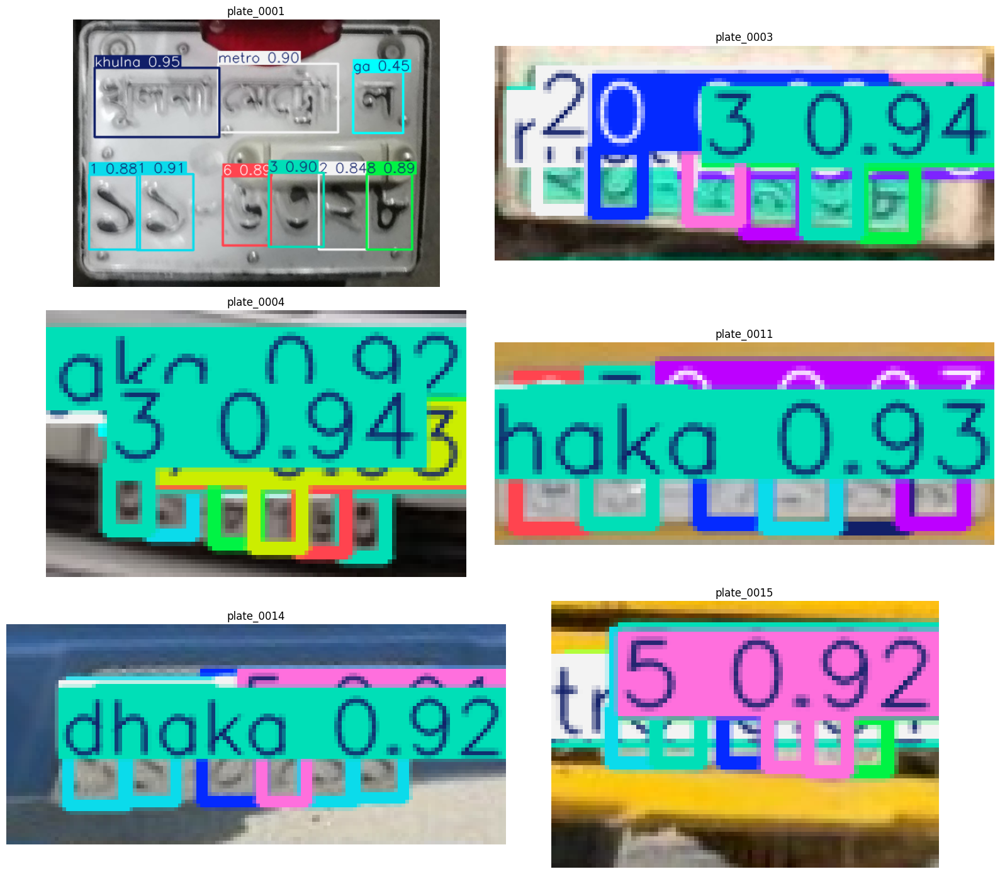

In [149]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import pandas as pd

# Reuse the variables from your previous cells.
IMAGE_DIR = Path("/kaggle/working/real_faded_standardized")

diagnostic_ids = [
    "plate_0001",
    "plate_0003",
    "plate_0004",
    "plate_0011",
    "plate_0014",
    "plate_0015",
]

image_lookup = {
    p.stem: p
    for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()

for ax, image_id in zip(axes, diagnostic_ids):
    image_path = image_lookup.get(image_id)

    if image_path is None:
        ax.set_title(f"{image_id}: image not found")
        ax.axis("off")
        continue

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    # Draw predicted boxes, class names, and confidence scores.
    annotated = result.plot()
    annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    ax.imshow(annotated)
    ax.set_title(image_id)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [150]:
from pathlib import Path
import pandas as pd

BOX_PATH = Path(
    "/kaggle/working/plate_text_recognition/"
    "individual_character_detections.csv"
)

boxes = pd.read_csv(BOX_PATH)

for image_id in ["plate_0003", "plate_0004", "plate_0011"]:
    subset = boxes[boxes["image_id"] == image_id].copy()

    if subset.empty:
        print(f"\n{image_id}: no detections in saved CSV")
        continue

    subset = subset.sort_values("cy")

    print(f"\n--- {image_id}: detections ordered by vertical position ---")
    print(
        subset[
            ["token", "confidence", "cx", "cy", "x1", "y1", "x2", "y2"]
        ].round(2).to_string(index=False)
    )


--- plate_0003: detections ordered by vertical position ---
token  confidence    cx    cy    x1    y1     x2    y2
dhaka        0.87 29.80 18.65 13.86 10.42  45.74 26.88
metro        0.87 65.02 20.72 45.67 11.61  84.38 29.83
   ja        0.43 94.35 21.93 87.04 14.07 101.67 29.80
    2        0.90 17.22 32.05 10.75 23.43  23.69 40.66
    0        0.92 30.27 33.29 24.00 25.42  36.54 41.15
    5        0.91 53.92 34.82 47.48 25.82  60.37 43.83
    9        0.88 68.38 36.79 61.53 27.47  75.22 46.12
    3        0.94 82.95 37.42 76.10 28.40  89.79 46.43
    8        0.90 96.96 38.45 90.05 29.29 103.87 47.62

--- plate_0004: detections ordered by vertical position ---
token  confidence    cx    cy    x1    y1    x2    y2
dhaka        0.92 27.57 30.01 16.19 22.83 38.95 37.19
metro        0.91 51.41 33.30 38.46 25.58 64.36 41.01
   ga        0.70 71.53 34.47 66.70 28.66 76.36 40.28
    3        0.94 18.96 43.04 14.03 35.51 23.88 50.58
    1        0.87 28.20 44.24 23.22 36.60 33.18 51.88
    

In [151]:
from pathlib import Path
import pandas as pd
import numpy as np

OUTPUT_DIR = Path("/kaggle/working/plate_text_recognition")

BOX_PATH = OUTPUT_DIR / "individual_character_detections.csv"

boxes = pd.read_csv(BOX_PATH)


def reconstruct_plate(group):
    """
    Split detections into top/bottom rows using the largest
    vertical gap, then order each row from left to right.
    """
    group = group.dropna(subset=["cx", "cy"]).copy()

    if group.empty:
        return ""

    group["cx"] = pd.to_numeric(group["cx"])
    group["cy"] = pd.to_numeric(group["cy"])

    sorted_y = group.sort_values("cy").reset_index(drop=True)

    if len(sorted_y) >= 4:
        y_centers = sorted_y["cy"].to_numpy()
        gaps = np.diff(y_centers)

        split_index = int(np.argmax(gaps)) + 1
        largest_gap = float(gaps.max())

        box_heights = (
            pd.to_numeric(group["y2"]) -
            pd.to_numeric(group["y1"])
        ).clip(lower=1)

        median_height = float(box_heights.median())
        gap_threshold = max(3.0, 0.35 * median_height)

        if largest_gap >= gap_threshold:
            top_row = sorted_y.iloc[:split_index].sort_values("cx")
            bottom_row = sorted_y.iloc[split_index:].sort_values("cx")

            ordered = pd.concat([top_row, bottom_row])
        else:
            ordered = group.sort_values("cx")
    else:
        ordered = group.sort_values("cx")

    tokens = ordered["token"].astype(str).str.lower().tolist()

    return " ".join(tokens)


# Reconstruct text for every image from its saved detections.
prediction_rows = []

for image_id, group in boxes.groupby("image_id", sort=True):
    prediction_rows.append({
        "image_id": str(image_id),
        "predicted_text": reconstruct_plate(group),
        "num_detections": len(group)
    })

predictions_fixed = pd.DataFrame(prediction_rows)

pred_path = OUTPUT_DIR / "full_plate_predictions_row_fixed.csv"
predictions_fixed.to_csv(pred_path, index=False)

print("Saved:", pred_path)
print("\nExample reconstructed predictions:")

print(
    predictions_fixed[
        predictions_fixed["image_id"].isin([
            "plate_0001", "plate_0003",
            "plate_0004", "plate_0011",
            "plate_0014"
        ])
    ].to_string(index=False)
)

Saved: /kaggle/working/plate_text_recognition/full_plate_predictions_row_fixed.csv

Example reconstructed predictions:
  image_id              predicted_text  num_detections
plate_0001 khulna metro ga 1 1 6 3 2 8               9
plate_0003  dhaka metro ja 2 0 5 9 3 8               9
plate_0004  dhaka metro ga 3 1 8 7 6 3               9
plate_0011  dhaka metro ja 6 3 0 1 4 9               9
plate_0014  dhaka metro ca 1 1 0 5 1 1               9


In [152]:
import pandas as pd
import re
from pathlib import Path

GT_PATH = Path(
    "/kaggle/working/real_faded_ground_truth_roman.csv"
)

gt = pd.read_csv(GT_PATH)


def normalize_text(text):
    if pd.isna(text):
        return ""
    return re.sub(r"[^a-z0-9]", "", str(text).lower())


def edit_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))

        previous = current

    return previous[-1]


# Find the ground-truth column names.
id_candidates = [
    "image_id", "image", "image_name", "filename",
    "file_name", "plate_id", "id"
]
text_candidates = [
    "ground_truth", "normalized_ground_truth",
    "gt_text", "plate_text", "text"
]

id_col = next((c for c in id_candidates if c in gt.columns), None)
gt_col = next((c for c in text_candidates if c in gt.columns), None)

if id_col is None or gt_col is None:
    raise ValueError(f"Unexpected ground-truth columns: {gt.columns.tolist()}")

if "has_ground_truth" in gt.columns:
    valid = gt["has_ground_truth"].astype(str).str.lower().isin(
        ["true", "1", "yes", "y"]
    )
else:
    valid = gt[gt_col].notna() & (
        gt[gt_col].astype(str).str.strip() != ""
    )

pred_lookup = {
    str(row["image_id"]): row
    for _, row in predictions_fixed.iterrows()
}

results = []

for _, row in gt[valid].iterrows():
    image_id = Path(str(row[id_col])).stem

    if image_id not in pred_lookup:
        continue

    truth = normalize_text(row[gt_col])
    predicted = normalize_text(
        pred_lookup[image_id]["predicted_text"]
    )

    if not truth:
        continue

    distance = edit_distance(truth, predicted)

    results.append({
        "image_id": image_id,
        "ground_truth": row[gt_col],
        "predicted_text": pred_lookup[image_id]["predicted_text"],
        "exact_match": truth == predicted,
        "edit_distance": distance,
        "CER": distance / len(truth)
    })

evaluation_fixed = pd.DataFrame(results)

if evaluation_fixed.empty:
    raise ValueError("No ground-truth entries matched the predictions.")

evaluation_fixed.to_csv(
    OUTPUT_DIR / "full_plate_evaluation_row_fixed.csv",
    index=False
)

print("Labeled plates evaluated:", len(evaluation_fixed))
print(
    "Exact full-text accuracy: "
    f"{100 * evaluation_fixed['exact_match'].mean():.2f}%"
)
print(
    "Mean CER: "
    f"{100 * evaluation_fixed['CER'].mean():.2f}%"
)

print("\nFirst 15 mismatches:")
print(
    evaluation_fixed[~evaluation_fixed["exact_match"]][
        ["image_id", "ground_truth", "predicted_text", "CER"]
    ].head(15).to_string(index=False)
)

Labeled plates evaluated: 64
Exact full-text accuracy: 14.06%
Mean CER: 24.46%

First 15 mismatches:
  image_id            ground_truth                predicted_text      CER
plate_0001 khulna metro-la 11-6328   khulna metro ga 1 1 6 3 2 8 0.052632
plate_0003   dhaka metro-u 20-5938    dhaka metro ja 2 0 5 9 3 8 0.117647
plate_0005  dhaka metro-ba 14-8351      dhaka metro ba 1 4 8 5 3 0.111111
plate_0006  dhaka metro-ga 20-1300       dhaka metro 2 0 1 3 0 0 0.111111
plate_0007  dhaka metro-na 11-1335    dhaka metro ta 1 1 1 3 3 5 0.055556
plate_0008  dhaka metro-ha 14-9803    dhaka metro ba 1 4 9 8 0 3 0.055556
plate_0009   dhaka metro-u 12-1205         dhaka metro 1 2 1 2 4 0.176471
plate_0010 dhaka metro-sha 11-0361    dhaka metro ga 1 1 0 8 6 1 0.157895
plate_0011 dhaka metro-dha 63-5149    dhaka metro ja 6 3 0 1 4 9 0.157895
plate_0012  dhaka metro-ta 18-8537 ta dhaka metro ta 1 8 8 5 3 7 0.111111
plate_0013 dhaka metro-tha 21-4286      dhaka metro ga 2 1 2 8 6 0.157895
plate_0014 

In [153]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

OUT = Path("/kaggle/working/plate_text_recognition")

boxes = pd.read_csv(
    OUT / "individual_character_detections.csv"
)
gt = pd.read_csv(
    "/kaggle/working/real_faded_ground_truth_roman.csv"
)

# Find ground-truth columns automatically.
id_col = next(
    (c for c in [
        "image_id", "image", "image_name",
        "filename", "file_name", "plate_id", "id"
    ] if c in gt.columns),
    None
)
gt_col = next(
    (c for c in [
        "ground_truth", "normalized_ground_truth",
        "gt_text", "plate_text", "text"
    ] if c in gt.columns),
    None
)

if id_col is None or gt_col is None:
    raise ValueError(f"Unexpected GT columns: {gt.columns.tolist()}")

if "has_ground_truth" in gt.columns:
    valid = gt["has_ground_truth"].astype(str).str.lower().isin(
        ["true", "1", "yes", "y"]
    )
else:
    valid = gt[gt_col].notna() & (
        gt[gt_col].astype(str).str.strip() != ""
    )

DIGITS = set("0123456789")

def edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))
        previous = current
    return previous[-1]

def split_into_rows(group):
    """Use the largest vertical gap to separate plate rows."""
    group = group.dropna(subset=["cx", "cy"]).copy()
    group["cx"] = pd.to_numeric(group["cx"])
    group["cy"] = pd.to_numeric(group["cy"])

    if len(group) < 4:
        return group.sort_values("cx"), pd.DataFrame(columns=group.columns)

    by_y = group.sort_values("cy").reset_index(drop=True)
    gaps = np.diff(by_y["cy"].to_numpy())

    heights = (
        pd.to_numeric(group["y2"]) -
        pd.to_numeric(group["y1"])
    ).clip(lower=1)

    threshold = max(3.0, 0.35 * float(heights.median()))
    split_at = int(np.argmax(gaps)) + 1

    if float(gaps.max()) >= threshold:
        top = by_y.iloc[:split_at].sort_values("cx")
        bottom = by_y.iloc[split_at:].sort_values("cx")
        return top, bottom

    return group.sort_values("cx"), pd.DataFrame(columns=group.columns)

records = []

for _, row in gt[valid].iterrows():
    image_id = Path(str(row[id_col])).stem
    g = boxes[boxes["image_id"].astype(str) == image_id].copy()

    if g.empty:
        continue

    truth_digits = "".join(re.findall(r"\d", str(row[gt_col])))

    top, bottom = split_into_rows(g)

    # Registration number: digits detected in the lower row.
    pred_digits = "".join(
        token
        for token in bottom["token"].astype(str).str.lower()
        if token in DIGITS
    )

    top_tokens = " ".join(top["token"].astype(str).tolist())
    bottom_tokens = " ".join(bottom["token"].astype(str).tolist())

    dist = edit_distance(truth_digits, pred_digits)

    records.append({
        "image_id": image_id,
        "ground_truth_digits": truth_digits,
        "predicted_digits": pred_digits,
        "digit_count": len(pred_digits),
        "digit_exact": truth_digits == pred_digits,
        "digit_CER": dist / len(truth_digits) if truth_digits else np.nan,
        "top_row_tokens": top_tokens,
        "bottom_row_tokens": bottom_tokens
    })

digit_eval = pd.DataFrame(records)
digit_eval.to_csv(OUT / "digit_only_evaluation.csv", index=False)

print("Labeled plates evaluated:", len(digit_eval))
print(
    "Exact six-digit accuracy:",
    f"{100 * digit_eval['digit_exact'].mean():.2f}%"
)
print(
    "Mean digit CER:",
    f"{100 * digit_eval['digit_CER'].mean():.2f}%"
)
print(
    "Exactly six digits detected:",
    f"{(digit_eval['digit_count'] == 6).sum()} / {len(digit_eval)}"
)

print("\nExamples:")
print(
    digit_eval[
        [
            "image_id", "ground_truth_digits", "predicted_digits",
            "digit_count", "digit_exact", "top_row_tokens"
        ]
    ].head(25).to_string(index=False)
)

Labeled plates evaluated: 64
Exact six-digit accuracy: 62.50%
Mean digit CER: 11.72%
Exactly six digits detected: 49 / 64

Examples:
  image_id ground_truth_digits predicted_digits  digit_count  digit_exact    top_row_tokens
plate_0001              116328           116328            6         True   khulna metro ga
plate_0003              205938           205938            6         True    dhaka metro ja
plate_0004              318763           318763            6         True    dhaka metro ga
plate_0005              148351            14853            5        False    dhaka metro ba
plate_0006              201300           201300            6         True       dhaka metro
plate_0007              111335           111335            6         True    dhaka metro ta
plate_0008              149803           149803            6         True    dhaka metro ba
plate_0009              121205            12124            5        False       dhaka metro
plate_0010              110361         

In [154]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

OUT = Path("/kaggle/working/plate_text_recognition")

boxes = pd.read_csv(
    OUT / "individual_character_detections.csv"
)
gt = pd.read_csv(
    "/kaggle/working/real_faded_ground_truth_roman.csv"
)

id_col = next(
    (c for c in [
        "image_id", "image", "image_name",
        "filename", "file_name", "plate_id", "id"
    ] if c in gt.columns),
    None
)

gt_col = next(
    (c for c in [
        "ground_truth", "normalized_ground_truth",
        "gt_text", "plate_text", "text"
    ] if c in gt.columns),
    None
)

if id_col is None or gt_col is None:
    raise ValueError(
        f"Cannot identify GT columns: {gt.columns.tolist()}"
    )

if "has_ground_truth" in gt.columns:
    valid = gt["has_ground_truth"].astype(str).str.lower().isin(
        ["true", "1", "yes", "y"]
    )
else:
    valid = gt[gt_col].notna() & (
        gt[gt_col].astype(str).str.strip() != ""
    )


def split_rows(group):
    group = group.dropna(subset=["cx", "cy"]).copy()
    group["cx"] = pd.to_numeric(group["cx"])
    group["cy"] = pd.to_numeric(group["cy"])

    if len(group) < 4:
        return group.sort_values("cx"), group.iloc[0:0]

    ordered = group.sort_values("cy").reset_index(drop=True)
    gaps = np.diff(ordered["cy"].to_numpy())

    heights = (
        pd.to_numeric(group["y2"]) -
        pd.to_numeric(group["y1"])
    ).clip(lower=1)

    threshold = max(3.0, 0.35 * float(heights.median()))
    split_at = int(np.argmax(gaps)) + 1

    if float(gaps.max()) >= threshold:
        return (
            ordered.iloc[:split_at].sort_values("cx"),
            ordered.iloc[split_at:].sort_values("cx")
        )

    return group.sort_values("cx"), group.iloc[0:0]


digit_errors = []

for _, row in gt[valid].iterrows():
    image_id = Path(str(row[id_col])).stem
    group = boxes[
        boxes["image_id"].astype(str) == image_id
    ].copy()

    if group.empty:
        continue

    truth_digits = "".join(re.findall(r"\d", str(row[gt_col])))

    top, bottom = split_rows(group)

    def tokens(frame):
        return " ".join(
            frame.sort_values("cx")["token"].astype(str).tolist()
        )

    bottom_digits = "".join(
        t for t in bottom.sort_values("cx")["token"]
        .astype(str).tolist()
        if t in "0123456789"
    )

    top_digits = "".join(
        t for t in top.sort_values("cx")["token"]
        .astype(str).tolist()
        if t in "0123456789"
    )

    all_tokens_by_row = (
        group.sort_values("cy")[
            ["token", "confidence", "cx", "cy"]
        ]
        .round(2)
    )

    if bottom_digits != truth_digits:
        digit_errors.append({
            "image_id": image_id,
            "ground_truth_digits": truth_digits,
            "top_row_tokens": tokens(top),
            "bottom_row_tokens": tokens(bottom),
            "top_row_digits": top_digits,
            "bottom_row_digits": bottom_digits,
            "all_detected_digits": "".join(
                group.sort_values("cy")["token"]
                .astype(str)
                .loc[lambda s: s.isin(list("0123456789"))]
                .tolist()
            ),
            "top_y_range": (
                f"{top['cy'].min():.1f}-{top['cy'].max():.1f}"
                if not top.empty else ""
            ),
            "bottom_y_range": (
                f"{bottom['cy'].min():.1f}-{bottom['cy'].max():.1f}"
                if not bottom.empty else ""
            ),
            "digit_count": len(bottom_digits),
            "detection_count": len(group)
        })

diagnostics = pd.DataFrame(digit_errors)

diagnostic_path = OUT / "digit_error_diagnostics.csv"
diagnostics.to_csv(diagnostic_path, index=False)

print("Failed digit predictions:", len(diagnostics))
print("Saved diagnostic file:", diagnostic_path)

print("\nFailed examples:")
print(
    diagnostics[
        [
            "image_id",
            "ground_truth_digits",
            "top_row_tokens",
            "bottom_row_tokens",
            "top_row_digits",
            "bottom_row_digits",
            "digit_count"
        ]
    ].to_string(index=False)
)

Failed digit predictions: 24
Saved diagnostic file: /kaggle/working/plate_text_recognition/digit_error_diagnostics.csv

Failed examples:
  image_id ground_truth_digits             top_row_tokens bottom_row_tokens top_row_digits bottom_row_digits  digit_count
plate_0005              148351             dhaka metro ba         1 4 8 5 3                            14853            5
plate_0009              121205                dhaka metro         1 2 1 2 4                            12124            5
plate_0010              110361             dhaka metro ga       1 1 0 8 6 1                           110861            6
plate_0011              635149             dhaka metro ja       6 3 0 1 4 9                           630149            6
plate_0013              214286             dhaka metro ga         2 1 2 8 6                            21286            5
plate_0019              135016             dhaka metro ba         1 3 0 1 6                            13016            5
plate_002

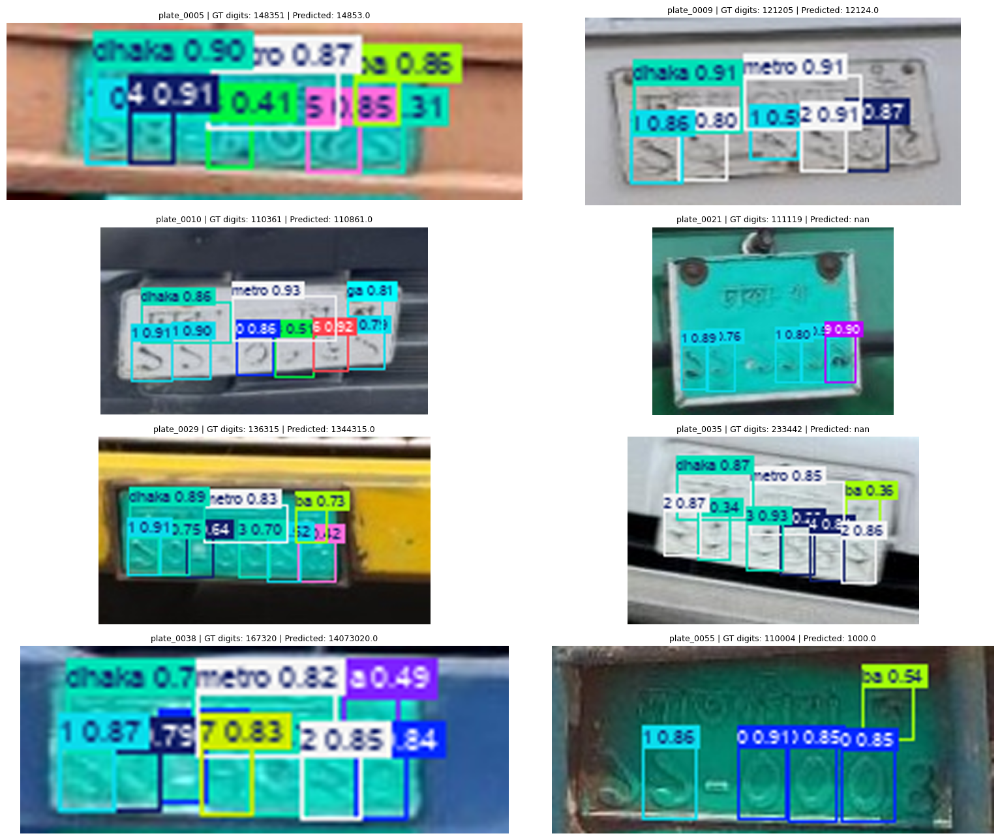

Saved visualizations to: /kaggle/working/plate_text_recognition/compact_visualizations
Saved diagnostic grid: /kaggle/working/plate_text_recognition/compact_visualizations/digit_error_diagnostic_grid.png


In [155]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Existing Model B
MODEL_PATH = (
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

# Existing standardized plate crops
IMAGE_DIR = Path("/kaggle/working/real_faded_standardized")

OUT_DIR = Path(
    "/kaggle/working/plate_text_recognition/compact_visualizations"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

DIAG_PATH = Path(
    "/kaggle/working/plate_text_recognition/"
    "digit_error_diagnostics.csv"
)

# Load the model and the saved diagnostic results.
model = YOLO(MODEL_PATH)
diagnostics = pd.read_csv(DIAG_PATH)

image_lookup = {
    p.stem: p
    for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

# Selected examples: missing digits, wrong digits,
# excessive detections, and row-assignment problems.
diagnostic_ids = [
    "plate_0005",
    "plate_0009",
    "plate_0010",
    "plate_0021",
    "plate_0029",
    "plate_0035",
    "plate_0038",
    "plate_0055",
]

# MAIN SETTINGS — adjust these if needed.
FONT_SIZE = 7       # Try 5 for smaller labels, 9 for larger labels
BOX_LINE_WIDTH = 1  # Bounding box thickness in pixels
DISPLAY_SCALE = 3   # Enlarge the final visualization for viewing

diag_lookup = diagnostics.set_index("image_id").to_dict("index")

fig, axes = plt.subplots(4, 2, figsize=(16, 13))
axes = axes.flatten()

for ax, image_id in zip(axes, diagnostic_ids):

    image_path = image_lookup.get(image_id)

    if image_path is None:
        ax.set_title(f"{image_id}: image not found")
        ax.axis("off")
        continue

    # Keep the same inference settings as the previous evaluation.
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    # PIL mode lets font_size control annotation text size.
    annotated_pil = result.plot(
        pil=True,
        font_size=FONT_SIZE,
        line_width=BOX_LINE_WIDTH,
        labels=True,
        conf=True,
        boxes=True
    )

    # Convert to RGB NumPy array for Matplotlib.
    annotated_rgb = np.array(annotated_pil)

    # Save the annotated result at its original image resolution.
    save_path = OUT_DIR / f"{image_id}_compact.png"
    annotated_bgr = cv2.cvtColor(
        annotated_rgb, cv2.COLOR_RGB2BGR
    )
    cv2.imwrite(str(save_path), annotated_bgr)

    # Enlarge only for on-screen inspection.
    display_img = cv2.resize(
        annotated_rgb,
        None,
        fx=DISPLAY_SCALE,
        fy=DISPLAY_SCALE,
        interpolation=cv2.INTER_CUBIC
    )

    info = diag_lookup.get(image_id, {})
    gt_digits = info.get("ground_truth_digits", "unknown")
    pred_digits = info.get("bottom_row_digits", "unknown")

    ax.imshow(display_img)
    ax.set_title(
        f"{image_id} | GT digits: {gt_digits} | "
        f"Predicted: {pred_digits}",
        fontsize=9
    )
    ax.axis("off")

# Hide unused axes if fewer images were found.
for ax in axes[len(diagnostic_ids):]:
    ax.axis("off")

plt.tight_layout()

figure_path = OUT_DIR / "digit_error_diagnostic_grid.png"
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved visualizations to:", OUT_DIR)
print("Saved diagnostic grid:", figure_path)

In [156]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from ultralytics import YOLO

# Existing files
MODEL_PATH = Path(
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)
IMAGE_DIR = Path("/kaggle/working/real_faded_standardized")
GT_PATH = Path("/kaggle/working/real_faded_ground_truth_roman.csv")
OUT_DIR = Path("/kaggle/working/plate_text_recognition")

OUT_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))
gt = pd.read_csv(GT_PATH)

id_col = next(
    (c for c in [
        "image_id", "image", "image_name", "filename",
        "file_name", "plate_id", "id"
    ] if c in gt.columns),
    None
)
gt_col = next(
    (c for c in [
        "ground_truth", "normalized_ground_truth",
        "gt_text", "plate_text", "text"
    ] if c in gt.columns),
    None
)

if id_col is None or gt_col is None:
    raise ValueError(f"Ground-truth columns not recognized: {gt.columns.tolist()}")

if "has_ground_truth" in gt.columns:
    valid = gt["has_ground_truth"].astype(str).str.lower().isin(
        ["true", "1", "yes", "y"]
    )
else:
    valid = gt[gt_col].notna() & gt[gt_col].astype(str).str.strip().ne("")

gt_lookup = {}
for _, row in gt[valid].iterrows():
    image_id = Path(str(row[id_col])).stem
    gt_lookup[image_id] = "".join(re.findall(r"\d", str(row[gt_col])))

image_lookup = {
    p.stem: p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

image_ids = sorted(set(gt_lookup) & set(image_lookup))

if not image_ids:
    raise RuntimeError("No matching labeled images found.")

print(f"Images available for evaluation: {len(image_ids)}")


def levenshtein(a, b):
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))
        previous = current
    return previous[-1]


def extract_digits_by_row(result):
    detections = []

    if result.boxes is None or len(result.boxes) == 0:
        return "", 0

    xyxy = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for box, class_id in zip(xyxy, classes):
        x1, y1, x2, y2 = map(float, box)
        token = str(model.names[int(class_id)]).strip()

        detections.append({
            "token": token,
            "cx": (x1 + x2) / 2,
            "cy": (y1 + y2) / 2,
            "height": max(1.0, y2 - y1)
        })

    # Split into top and bottom rows at the largest vertical gap.
    ordered = sorted(detections, key=lambda d: d["cy"])

    if len(ordered) < 4:
        bottom_row = []
    else:
        gaps = [
            ordered[i + 1]["cy"] - ordered[i]["cy"]
            for i in range(len(ordered) - 1)
        ]
        split_at = int(np.argmax(gaps)) + 1
        largest_gap = gaps[split_at - 1]
        median_height = float(np.median([
            d["height"] for d in ordered
        ]))
        threshold = max(3.0, 0.35 * median_height)

        if largest_gap >= threshold:
            bottom_row = ordered[split_at:]
        else:
            bottom_row = []

    bottom_row = sorted(bottom_row, key=lambda d: d["cx"])
    digits = "".join(
        d["token"] for d in bottom_row
        if d["token"] in "0123456789"
    )

    return digits, len(detections)


thresholds = [0.10, 0.15, 0.25]
all_details = []
summary = []

for conf in thresholds:
    exact_count = 0
    six_digit_count = 0
    empty_count = 0
    total_cer = 0.0
    details = []

    for i, image_id in enumerate(image_ids, start=1):
        result = model.predict(
            source=str(image_lookup[image_id]),
            imgsz=640,
            conf=conf,
            verbose=False
        )[0]

        pred_digits, detection_count = extract_digits_by_row(result)
        true_digits = gt_lookup[image_id]

        exact = pred_digits == true_digits
        distance = levenshtein(true_digits, pred_digits)
        cer = distance / len(true_digits) if true_digits else np.nan

        exact_count += int(exact)
        six_digit_count += int(len(pred_digits) == 6)
        empty_count += int(len(pred_digits) == 0)
        total_cer += cer if not np.isnan(cer) else 0

        details.append({
            "confidence_threshold": conf,
            "image_id": image_id,
            "ground_truth_digits": true_digits,
            "predicted_digits": pred_digits,
            "digit_count": len(pred_digits),
            "exact_match": exact,
            "CER": cer,
            "total_detections": detection_count
        })

    detail_df = pd.DataFrame(details)
    all_details.append(detail_df)

    n = len(detail_df)
    correct_with_six = int(
        (
            detail_df["exact_match"]
            & (detail_df["digit_count"] == 6)
        ).sum()
    )

    summary.append({
        "confidence_threshold": conf,
        "labeled_images": n,
        "exact_six_digit_matches": exact_count,
        "exact_six_digit_accuracy_percent": 100 * exact_count / n,
        "mean_digit_CER_percent": 100 * total_cer / n,
        "images_with_exactly_six_detections": six_digit_count,
        "exact_accuracy_among_six_digit_predictions_percent":
            100 * correct_with_six / six_digit_count
            if six_digit_count else 0,
        "images_with_no_digit_predictions": empty_count
    })

    print(f"Finished threshold {conf:.2f}: {n} images")

summary_df = pd.DataFrame(summary)
details_df = pd.concat(all_details, ignore_index=True)

summary_path = OUT_DIR / "confidence_threshold_comparison.csv"
details_path = OUT_DIR / "confidence_threshold_per_image.csv"

summary_df.to_csv(summary_path, index=False)
details_df.to_csv(details_path, index=False)

print("\n=== CONFIDENCE THRESHOLD COMPARISON ===")
print(summary_df.round(2).to_string(index=False))

print("\nSaved summary:", summary_path)
print("Saved per-image results:", details_path)

Images available for evaluation: 64
Finished threshold 0.10: 64 images
Finished threshold 0.15: 64 images
Finished threshold 0.25: 64 images

=== CONFIDENCE THRESHOLD COMPARISON ===
 confidence_threshold  labeled_images  exact_six_digit_matches  exact_six_digit_accuracy_percent  mean_digit_CER_percent  images_with_exactly_six_detections  exact_accuracy_among_six_digit_predictions_percent  images_with_no_digit_predictions
                 0.10              64                       34                             53.12                   15.36                                  42                                               80.95                                 1
                 0.15              64                       37                             57.81                   14.32                                  45                                               82.22                                 2
                 0.25              64                       40                           

In [157]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

OUT = Path("/kaggle/working/plate_text_recognition")

boxes = pd.read_csv(
    OUT / "individual_character_detections.csv"
)
gt = pd.read_csv(
    "/kaggle/working/real_faded_ground_truth_roman.csv"
)

id_col = next(
    (c for c in [
        "image_id", "image", "image_name", "filename",
        "file_name", "plate_id", "id"
    ] if c in gt.columns),
    None
)
gt_col = next(
    (c for c in [
        "ground_truth", "normalized_ground_truth",
        "gt_text", "plate_text", "text"
    ] if c in gt.columns),
    None
)

if id_col is None or gt_col is None:
    raise ValueError(f"Unexpected GT columns: {gt.columns.tolist()}")

if "has_ground_truth" in gt.columns:
    valid = gt["has_ground_truth"].astype(str).str.lower().isin(
        ["true", "1", "yes", "y"]
    )
else:
    valid = gt[gt_col].notna() & gt[gt_col].astype(str).str.strip().ne("")


def edit_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))

        previous = current

    return previous[-1]


def get_digits(group):
    return "".join(
        token for token in group.sort_values("cx")["token"]
        .astype(str).str.strip().tolist()
        if token in "0123456789"
    )


def decode_largest_gap(group):
    """Reproduce the previous largest-vertical-gap method."""
    group = group.dropna(subset=["cx", "cy"]).copy()
    group = group.sort_values("cy").reset_index(drop=True)

    if len(group) < 4:
        return get_digits(group)

    gaps = np.diff(group["cy"].to_numpy())
    heights = (group["y2"] - group["y1"]).clip(lower=1)
    threshold = max(3.0, 0.35 * float(heights.median()))

    split_at = int(np.argmax(gaps)) + 1

    if float(gaps.max()) >= threshold:
        bottom = group.iloc[split_at:]
        return get_digits(bottom)

    # No clear two-row separation: treat as one row.
    return get_digits(group)


def decode_kmeans_adaptive(group):
    """
    Cluster vertical positions into two rows.
    If row separation is weak, read all detected digits
    from left to right. Otherwise select the row whose
    digit count is closest to six, preferring the bottom
    row when the two candidates tie.
    """
    group = group.dropna(subset=["cx", "cy"]).copy()

    if group.empty:
        return ""

    if len(group) < 4:
        return get_digits(group)

    xy = group[["cx", "cy"]].to_numpy(dtype=float)

    # Cluster only vertical position, not horizontal position.
    km = KMeans(n_clusters=2, random_state=42, n_init=10)
    labels = km.fit_predict(group[["cy"]].to_numpy())

    group["cluster"] = labels

    cluster_means = group.groupby("cluster")["cy"].mean()
    top_label = int(cluster_means.idxmin())
    bottom_label = int(cluster_means.idxmax())

    separation = float(
        cluster_means.loc[bottom_label] -
        cluster_means.loc[top_label]
    )

    heights = (group["y2"] - group["y1"]).clip(lower=1)
    threshold = max(3.0, 0.55 * float(heights.median()))

    # If the rows are not clearly separated, read one line.
    if separation < threshold:
        return get_digits(group)

    top = group[group["cluster"] == top_label]
    bottom = group[group["cluster"] == bottom_label]

    candidates = [
        (bottom, 0),  # Prefer bottom row in a tie.
        (top, 1)
    ]

    candidates.sort(
        key=lambda item: (
            abs(len(get_digits(item[0])) - 6),
            item[1]
        )
    )

    return get_digits(candidates[0][0])


# Evaluate the same labeled images using both decoders.
records = []

for _, row in gt[valid].iterrows():
    image_id = Path(str(row[id_col])).stem
    group = boxes[boxes["image_id"].astype(str) == image_id]

    if group.empty:
        continue

    truth = "".join(re.findall(r"\d", str(row[gt_col])))

    if not truth:
        continue

    for method, decoder in [
        ("largest_gap", decode_largest_gap),
        ("kmeans_adaptive", decode_kmeans_adaptive)
    ]:
        predicted = decoder(group)
        distance = edit_distance(truth, predicted)

        records.append({
            "image_id": image_id,
            "method": method,
            "ground_truth_digits": truth,
            "predicted_digits": predicted,
            "digit_count": len(predicted),
            "exact_match": predicted == truth,
            "CER": distance / len(truth)
        })

comparison = pd.DataFrame(records)

summary = (
    comparison.groupby("method")
    .agg(
        labeled_images=("image_id", "nunique"),
        exact_matches=("exact_match", "sum"),
        mean_CER=("CER", "mean"),
        exactly_six_digits=("digit_count", lambda s: (s == 6).sum())
    )
    .reset_index()
)

summary["exact_accuracy_percent"] = (
    100 * summary["exact_matches"] / summary["labeled_images"]
)
summary["mean_CER_percent"] = 100 * summary["mean_CER"]
summary.drop(columns="mean_CER", inplace=True)

comparison.to_csv(OUT / "row_decoder_comparison_per_image.csv", index=False)
summary.to_csv(OUT / "row_decoder_comparison_summary.csv", index=False)

print("=== DECODER COMPARISON ===")
print(summary.round(2).to_string(index=False))

# Show plates where the two decoders disagree.
pivot = comparison.pivot(
    index="image_id",
    columns="method",
    values="predicted_digits"
)

different = pivot[
    pivot["largest_gap"] != pivot["kmeans_adaptive"]
]

print("\n=== FIRST 20 DIFFERENCES ===")
print(different.head(20).to_string())

print("\nResults saved to:", OUT)

=== DECODER COMPARISON ===
         method  labeled_images  exact_matches  exactly_six_digits  exact_accuracy_percent  mean_CER_percent
kmeans_adaptive              64             41                  51                   64.06              8.85
    largest_gap              64             41                  51                   64.06              8.85

=== FIRST 20 DIFFERENCES ===
Empty DataFrame
Columns: [kmeans_adaptive, largest_gap]
Index: []

Results saved to: /kaggle/working/plate_text_recognition


In [158]:
from pathlib import Path
import yaml
import pandas as pd
from PIL import Image

# Dataset and model paths
DATA_DIR = Path("/kaggle/working/bd_lpr_yolo")
YAML_PATH = DATA_DIR / "data.yaml"

MODEL_A = Path(
    "/kaggle/working/lpr_training/"
    "model_A_baseline/weights/best.pt"
)
MODEL_B = Path(
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)

assert YAML_PATH.exists(), f"Missing dataset config: {YAML_PATH}"
assert MODEL_A.exists(), f"Missing Model A weights: {MODEL_A}"
assert MODEL_B.exists(), f"Missing Model B weights: {MODEL_B}"

with open(YAML_PATH, "r") as f:
    cfg = yaml.safe_load(f)

print("=== DATASET CONFIGURATION ===")
print("Classes:", cfg.get("names"))
print("Number of classes:", cfg.get("nc"))

# Resolve the test image directory.
root = Path(cfg.get("path", DATA_DIR))
if not root.is_absolute():
    root = DATA_DIR / root

test_entry = cfg.get("test", "test/images")
test_dir = Path(test_entry)

if not test_dir.is_absolute():
    test_dir = root / test_dir

print("\nTest image directory:", test_dir)
print("Directory exists:", test_dir.exists())

if not test_dir.exists():
    raise FileNotFoundError(
        "Test directory not found. Check the paths printed above."
    )

image_paths = sorted(
    p for p in test_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

label_dir = DATA_DIR / "test" / "labels"

print("Clean test images:", len(image_paths))
print("Label directory:", label_dir)
print("Label directory exists:", label_dir.exists())

# Inspect annotations and object counts.
class_names = cfg.get("names", [])
if isinstance(class_names, dict):
    class_names = {
        int(k): v for k, v in class_names.items()
    }
else:
    class_names = dict(enumerate(class_names))

rows = []

for image_path in image_paths:
    label_path = label_dir / f"{image_path.stem}.txt"

    if not label_path.exists():
        rows.append({
            "image": image_path.name,
            "objects": 0,
            "classes": "MISSING LABEL"
        })
        continue

    objects = []
    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                class_id = int(float(parts[0]))
                objects.append(class_id)

    class_labels = [
        class_names.get(c, f"unknown_{c}") for c in objects
    ]

    rows.append({
        "image": image_path.name,
        "objects": len(objects),
        "classes": ", ".join(class_labels)
    })

audit = pd.DataFrame(rows)

print("\n=== ANNOTATION AUDIT ===")
print(audit.head(12).to_string(index=False))
print("\nImages with labels:", (audit["classes"] != "MISSING LABEL").sum())
print("Images missing labels:", (audit["classes"] == "MISSING LABEL").sum())
print("Mean objects per image:", round(audit["objects"].mean(), 2))

print("\nModels and dataset are ready for inspection.")

=== DATASET CONFIGURATION ===
Classes: {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'ka', 11: 'kha', 12: 'ga', 13: 'gha', 14: 'ca', 15: 'ja', 16: 'ta', 17: 'da', 18: 'na', 19: 'ba', 20: 'va', 21: 'ha', 22: 'metro', 23: 'dhaka', 24: 'khulna', 25: 'chattogram', 26: 'jashore'}
Number of classes: 27

Test image directory: /kaggle/working/bd_lpr_yolo/test/images
Directory exists: True
Clean test images: 218
Label directory: /kaggle/working/bd_lpr_yolo/test/labels
Label directory exists: True

=== ANNOTATION AUDIT ===
                                                                                              image  objects                             classes
                                               110_78_1_jpg.rf.d7fe68d3205b26fe2a8f82ec749245d3.jpg        9 dhaka, metro, gha, 1, 5, 8, 7, 2, 6
                                              112_218_1_jpg.rf.615e65a9b5abddc656237c528cd29631.jpg        9 dhaka, metro, gha, 1, 1, 8, 9, 2, 5
       

In [159]:
from pathlib import Path
import yaml
import pandas as pd
from ultralytics import YOLO

# --------------------------------------------------
# PATHS
# --------------------------------------------------
DATA_DIR = Path("/kaggle/working/bd_lpr_yolo")
OUT_DIR = Path("/kaggle/working/clean_test_evaluation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATHS = {
    "Model_A_Baseline": Path(
        "/kaggle/working/lpr_training/"
        "model_A_baseline/weights/best.pt"
    ),
    "Model_B_Synthetic_Fading": Path(
        "/kaggle/working/lpr_training/"
        "model_B_synthetic_fading/weights/best.pt"
    ),
}

# --------------------------------------------------
# CREATE AN EVALUATION CONFIG WITH EXPLICIT PATHS
# --------------------------------------------------
original_yaml = DATA_DIR / "data.yaml"

with open(original_yaml, "r") as f:
    data_cfg = yaml.safe_load(f)

data_cfg["path"] = str(DATA_DIR)
data_cfg["test"] = "test/images"

eval_yaml = OUT_DIR / "clean_test_data.yaml"

with open(eval_yaml, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

# Confirm both models exist before starting.
for name, path in MODEL_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} weights missing: {path}")

# --------------------------------------------------
# EVALUATE BOTH MODELS ON THE SAME TEST SET
# --------------------------------------------------
records = []

for model_name, weights_path in MODEL_PATHS.items():
    print(f"\nEvaluating {model_name}...")

    model = YOLO(str(weights_path))

    metrics = model.val(
        data=str(eval_yaml),
        split="test",
        imgsz=640,
        batch=16,
        plots=True,
        save_json=True,
        project=str(OUT_DIR),
        name=model_name,
        exist_ok=True,
        verbose=False
    )

    box_metrics = metrics.box

    record = {
        "model": model_name,
        "precision": float(box_metrics.mp),
        "recall": float(box_metrics.mr),
        "mAP50": float(box_metrics.map50),
        "mAP50_95": float(box_metrics.map),
    }

    records.append(record)

    print(f"Precision:  {record['precision']:.4f}")
    print(f"Recall:     {record['recall']:.4f}")
    print(f"mAP@50:     {record['mAP50']:.4f}")
    print(f"mAP@50-95:  {record['mAP50_95']:.4f}")

# --------------------------------------------------
# SAVE THE COMPARISON TABLE
# --------------------------------------------------
results_df = pd.DataFrame(records)

results_path = OUT_DIR / "clean_test_model_comparison.csv"
results_df.to_csv(results_path, index=False)

print("\n=== CLEAN TEST SET: MODEL COMPARISON ===")
print(results_df.round(4).to_string(index=False))
print("\nSaved results:", results_path)
print("\nEvaluation plots are saved under:", OUT_DIR)


Evaluating Model_A_Baseline...
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 462.4±93.5 MB/s, size: 10.3 KB)
val: Scanning /kaggle/working/bd_lpr_yolo/test/labels.cache... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 83.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.7it/s 3.0s0.1s
                   all        218       1921      0.948      0.892      0.941      0.705
Speed: 1.0ms preprocess, 3.2ms inference, 0.0ms loss, 3.1ms postprocess per image
Saving /kaggle/working/clean_test_evaluation/Model_A_Baseline/predictions.json...

Evaluating faster-coco-eval mAP...
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packa

In [160]:
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
from ultralytics import YOLO

# --------------------------------------------------
# PATHS
# --------------------------------------------------
DATA_DIR = Path("/kaggle/working/bd_lpr_yolo")
TEST_DIR = DATA_DIR / "test" / "images"
LABEL_DIR = DATA_DIR / "test" / "labels"

OUT_DIR = Path("/kaggle/working/clean_test_sequence_evaluation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATHS = {
    "Model_A_Baseline": Path(
        "/kaggle/working/lpr_training/"
        "model_A_baseline/weights/best.pt"
    ),
    "Model_B_Synthetic_Fading": Path(
        "/kaggle/working/lpr_training/"
        "model_B_synthetic_fading/weights/best.pt"
    ),
}

with open(DATA_DIR / "data.yaml", "r") as f:
    cfg = yaml.safe_load(f)

if isinstance(cfg["names"], dict):
    names = {int(k): str(v) for k, v in cfg["names"].items()}
else:
    names = dict(enumerate(cfg["names"]))

DIGITS = set("0123456789")

image_paths = sorted(
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

assert image_paths, f"No test images found in {TEST_DIR}"

for path in image_paths:
    if not (LABEL_DIR / f"{path.stem}.txt").exists():
        raise FileNotFoundError(
            f"Missing annotation for {path.name}"
        )

# --------------------------------------------------
# EDIT DISTANCE
# --------------------------------------------------
def edit_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))

        previous = current

    return previous[-1]


# --------------------------------------------------
# ORDER DETECTIONS INTO ROWS
# Each object needs: token, cx, cy, w, h
# --------------------------------------------------
def order_rows(objects):
    if not objects:
        return []

    objects = list(objects)

    if len(objects) < 4:
        return [sorted(objects, key=lambda d: d["cx"])]

    by_y = sorted(objects, key=lambda d: d["cy"])
    y_values = np.array([d["cy"] for d in by_y], dtype=float)
    gaps = np.diff(y_values)

    median_height = float(np.median([
        max(1.0, d["h"]) for d in objects
    ]))
    threshold = max(3.0, 0.35 * median_height)

    split_at = int(np.argmax(gaps)) + 1

    if float(gaps.max()) >= threshold:
        top = sorted(by_y[:split_at], key=lambda d: d["cx"])
        bottom = sorted(by_y[split_at:], key=lambda d: d["cx"])
        return [top, bottom]

    return [sorted(objects, key=lambda d: d["cx"])]


def flatten_rows(rows):
    return [obj["token"] for row in rows for obj in row]


def get_digit_sequence(tokens):
    return "".join(token for token in tokens if token in DIGITS)


# --------------------------------------------------
# READ GROUND-TRUTH SEQUENCES FROM YOLO ANNOTATIONS
# --------------------------------------------------
ground_truth = {}

for image_path in image_paths:
    label_path = LABEL_DIR / f"{image_path.stem}.txt"
    objects = []

    # YOLO labels store normalized center x, center y, width, height.
    from PIL import Image

    with Image.open(image_path) as im:
        image_width, image_height = im.size

    with open(label_path, "r") as f:
        for line in f:
            parts = line.split()

            if len(parts) < 5:
                continue

            class_id = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:5])

            objects.append({
                "token": names[class_id],
                "cx": x * image_width,
                "cy": y * image_height,
                "w": w * image_width,
                "h": h * image_height,
            })

    rows = order_rows(objects)
    gt_tokens = flatten_rows(rows)

    ground_truth[image_path.stem] = {
        "tokens": gt_tokens,
        "digits": get_digit_sequence(gt_tokens),
    }


# --------------------------------------------------
# RUN BOTH MODELS AT THE SAME CONFIDENCE
# --------------------------------------------------
all_results = []

for model_name, weights in MODEL_PATHS.items():
    if not weights.exists():
        raise FileNotFoundError(f"Missing model weights: {weights}")

    print(f"Running sequence evaluation: {model_name}")
    model = YOLO(str(weights))

    seen = set()

    # stream=True avoids holding all Results objects in memory.
    for result in model.predict(
        source=str(TEST_DIR),
        imgsz=640,
        conf=0.25,
        iou=0.70,
        batch=16,
        stream=True,
        verbose=False,
    ):
        image_id = Path(result.path).stem
        seen.add(image_id)

        predicted_objects = []

        if result.boxes is not None and len(result.boxes) > 0:
            xywh = result.boxes.xywh.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy().astype(int)
            confidences = result.boxes.conf.cpu().numpy()

            for box, class_id, confidence in zip(
                xywh, classes, confidences
            ):
                cx, cy, w, h = map(float, box)

                predicted_objects.append({
                    "token": names[int(class_id)],
                    "cx": cx,
                    "cy": cy,
                    "w": w,
                    "h": h,
                    "confidence": float(confidence),
                })

        pred_rows = order_rows(predicted_objects)
        pred_tokens = flatten_rows(pred_rows)
        pred_digits = get_digit_sequence(pred_tokens)

        gt_tokens = ground_truth[image_id]["tokens"]
        gt_digits = ground_truth[image_id]["digits"]

        token_dist = edit_distance(gt_tokens, pred_tokens)
        digit_dist = edit_distance(gt_digits, pred_digits)

        all_results.append({
            "model": model_name,
            "image_id": image_id,
            "gt_sequence": " ".join(gt_tokens),
            "predicted_sequence": " ".join(pred_tokens),
            "gt_token_count": len(gt_tokens),
            "predicted_token_count": len(pred_tokens),
            "sequence_exact": gt_tokens == pred_tokens,
            "token_edit_distance": token_dist,
            "token_error_rate": (
                token_dist / len(gt_tokens) if gt_tokens else np.nan
            ),
            "gt_digits": gt_digits,
            "predicted_digits": pred_digits,
            "digit_exact": gt_digits == pred_digits,
            "digit_CER": (
                digit_dist / len(gt_digits) if gt_digits else np.nan
            ),
            "detections": len(predicted_objects),
        })

    if seen != set(ground_truth):
        missing = set(ground_truth) - seen
        raise RuntimeError(
            f"{model_name}: prediction count mismatch. "
            f"Missing image IDs: {sorted(missing)[:10]}"
        )

# --------------------------------------------------
# SUMMARY AND EXPORT
# --------------------------------------------------
details = pd.DataFrame(all_results)

summary_rows = []

for model_name, subset in details.groupby("model", sort=False):
    summary_rows.append({
        "model": model_name,
        "images_evaluated": len(subset),
        "full_sequence_exact_matches": int(subset["sequence_exact"].sum()),
        "full_sequence_exact_accuracy_percent":
            100 * subset["sequence_exact"].mean(),
        "mean_token_error_rate_percent":
            100 * subset["token_error_rate"].mean(),
        "digit_exact_matches": int(subset["digit_exact"].sum()),
        "digit_exact_accuracy_percent":
            100 * subset["digit_exact"].mean(),
        "mean_digit_CER_percent":
            100 * subset["digit_CER"].mean(),
        "images_with_no_detections":
            int((subset["detections"] == 0).sum()),
    })

summary = pd.DataFrame(summary_rows)

details_path = OUT_DIR / "clean_test_sequence_per_image.csv"
summary_path = OUT_DIR / "clean_test_sequence_summary.csv"

details.to_csv(details_path, index=False)
summary.to_csv(summary_path, index=False)

print("\n=== CLEAN TEST TEXT RECOGNITION SUMMARY ===")
print(summary.round(2).to_string(index=False))

print("\nSaved per-image results:", details_path)
print("Saved summary:", summary_path)

print("\n=== FIRST 12 EXAMPLES ===")
print(
    details[
        [
            "model", "image_id", "gt_sequence",
            "predicted_sequence", "sequence_exact"
        ]
    ].head(12).to_string(index=False)
)

Running sequence evaluation: Model_A_Baseline
Running sequence evaluation: Model_B_Synthetic_Fading

=== CLEAN TEST TEXT RECOGNITION SUMMARY ===
                   model  images_evaluated  full_sequence_exact_matches  full_sequence_exact_accuracy_percent  mean_token_error_rate_percent  digit_exact_matches  digit_exact_accuracy_percent  mean_digit_CER_percent  images_with_no_detections
        Model_A_Baseline               218                          158                                 72.48                           5.31                  192                         88.07                    3.28                          0
Model_B_Synthetic_Fading               218                          171                                 78.44                           3.70                  196                         89.91                    2.86                          0

Saved per-image results: /kaggle/working/clean_test_sequence_evaluation/clean_test_sequence_per_image.csv
Saved summary: /kag

In [161]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import binomtest

OUT = Path("/kaggle/working/clean_test_sequence_evaluation")

df = pd.read_csv(OUT / "clean_test_sequence_per_image.csv")

MODEL_A = "Model_A_Baseline"
MODEL_B = "Model_B_Synthetic_Fading"

required = {
    "model", "image_id", "sequence_exact",
    "digit_exact", "token_error_rate", "digit_CER"
}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")


def to_bool(series):
    if series.dtype == bool:
        return series

    converted = series.astype(str).str.lower().map({
        "true": True,
        "false": False,
        "1": True,
        "0": False
    })

    if converted.isna().any():
        raise ValueError("Could not parse boolean correctness values.")

    return converted.astype(bool)


for col in ["sequence_exact", "digit_exact"]:
    df[col] = to_bool(df[col])

# Prepare matched A/B results for each image.
def paired_pivot(metric):
    table = df.pivot(
        index="image_id",
        columns="model",
        values=metric
    )

    if MODEL_A not in table.columns or MODEL_B not in table.columns:
        raise ValueError("One or both expected model names are missing.")

    table = table[[MODEL_A, MODEL_B]].dropna()

    if len(table) != 218:
        print(f"Note: {len(table)} paired images available for {metric}.")

    return table


rng = np.random.default_rng(42)


def bootstrap_difference(a, b, repeats=20000):
    """95% paired-bootstrap CI for mean(Model B - Model A)."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    n = len(a)
    indices = rng.integers(0, n, size=(repeats, n))
    differences = (b - a)[indices].mean(axis=1)

    return (
        float((b - a).mean()),
        float(np.percentile(differences, 2.5)),
        float(np.percentile(differences, 97.5))
    )


def report_binary(metric, label):
    table = paired_pivot(metric)
    a = table[MODEL_A].to_numpy(dtype=bool)
    b = table[MODEL_B].to_numpy(dtype=bool)

    a_only = int((a & ~b).sum())
    b_only = int((~a & b).sum())

    discordant = a_only + b_only
    p_value = (
        binomtest(
            k=b_only,
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue
        if discordant else 1.0
    )

    difference, ci_low, ci_high = bootstrap_difference(a, b)

    return {
        "metric": label,
        "images": len(table),
        "Model_A_percent": 100 * a.mean(),
        "Model_B_percent": 100 * b.mean(),
        "difference_percentage_points": 100 * difference,
        "bootstrap_95CI_low_pp": 100 * ci_low,
        "bootstrap_95CI_high_pp": 100 * ci_high,
        "A_only_correct": a_only,
        "B_only_correct": b_only,
        "McNemar_exact_p": p_value
    }


def report_error(metric, label):
    table = paired_pivot(metric)
    a = table[MODEL_A].to_numpy(dtype=float)
    b = table[MODEL_B].to_numpy(dtype=float)

    difference, ci_low, ci_high = bootstrap_difference(a, b)

    return {
        "metric": label,
        "images": len(table),
        "Model_A_percent": 100 * a.mean(),
        "Model_B_percent": 100 * b.mean(),
        "difference_percentage_points": 100 * difference,
        "bootstrap_95CI_low_pp": 100 * ci_low,
        "bootstrap_95CI_high_pp": 100 * ci_high,
        "A_only_correct": np.nan,
        "B_only_correct": np.nan,
        "McNemar_exact_p": np.nan
    }


results = pd.DataFrame([
    report_binary("sequence_exact", "Exact full sequence accuracy"),
    report_binary("digit_exact", "Exact digit sequence accuracy"),
    report_error("token_error_rate", "Mean token error rate"),
    report_error("digit_CER", "Mean digit CER")
])

results_path = OUT / "paired_statistical_comparison.csv"
results.to_csv(results_path, index=False)

print("=== PAIRED STATISTICAL COMPARISON ===")
print(results.round(4).to_string(index=False))
print("\nSaved:", results_path)
print("\nFor the error metrics, negative differences favor Model B.")
print("For accuracy metrics, positive differences favor Model B.")
print("McNemar's test is reported for the binary exact-match metrics.")

=== PAIRED STATISTICAL COMPARISON ===
                       metric  images  Model_A_percent  Model_B_percent  difference_percentage_points  bootstrap_95CI_low_pp  bootstrap_95CI_high_pp  A_only_correct  B_only_correct  McNemar_exact_p
 Exact full sequence accuracy     218          72.4771          78.4404                        5.9633                 1.8349                 10.0917             5.0            18.0           0.0106
Exact digit sequence accuracy     218          88.0734          89.9083                        1.8349                -1.3761                  5.0459             4.0             8.0           0.3877
        Mean token error rate     218           5.3111           3.6958                       -1.6153                -2.6920                 -0.6726             NaN             NaN              NaN
               Mean digit CER     218           3.2798           2.8593                       -0.4205                -1.0703                  0.2294             NaN      

=== FINAL CLEAN TEST COMPARISON ===
                   model  Precision (%)  Recall (%)  mAP@50 (%)  mAP@50-95 (%)  Full sequence exact accuracy (%)  Mean token error rate (%)  Exact digit sequence accuracy (%)  Mean digit CER (%)  Images evaluated
        Model_A_Baseline          94.76       89.18       94.13          70.49                             72.48                       5.31                              88.07                3.28               218
Model_B_Synthetic_Fading          94.65       92.49       95.70          71.73                             78.44                       3.70                              89.91                2.86               218

Saved table: /kaggle/working/thesis_artifacts/tables/clean_test_final_comparison.csv


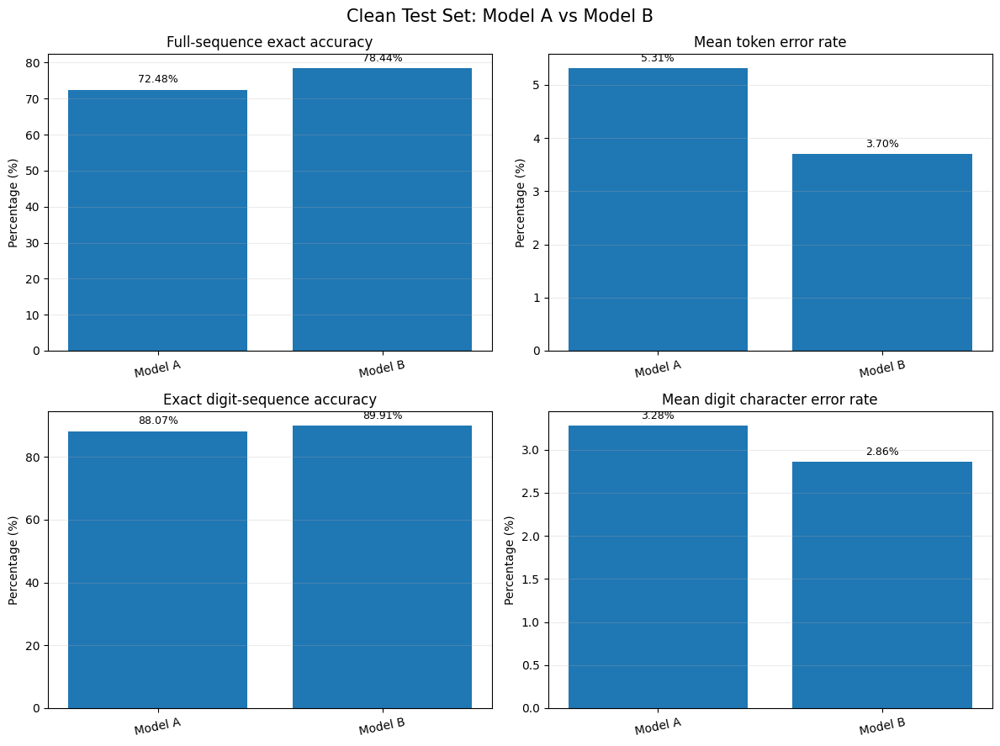

Saved figure: /kaggle/working/thesis_artifacts/figures/figure_23_clean_text_recognition_comparison.png


In [162]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/working")

DETECTION_PATH = (
    ROOT / "clean_test_evaluation"
    / "clean_test_model_comparison.csv"
)
SEQUENCE_PATH = (
    ROOT / "clean_test_sequence_evaluation"
    / "clean_test_sequence_per_image.csv"
)

FIG_DIR = ROOT / "thesis_artifacts" / "figures"
TABLE_DIR = ROOT / "thesis_artifacts" / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Load existing results: no inference or retraining.
det = pd.read_csv(DETECTION_PATH)
seq = pd.read_csv(SEQUENCE_PATH)

def parse_bool(s):
    if s.dtype == bool:
        return s
    return s.astype(str).str.lower().map({
        "true": True,
        "false": False,
        "1": True,
        "0": False
    })

for col in ["sequence_exact", "digit_exact"]:
    seq[col] = parse_bool(seq[col])

summary = (
    seq.groupby("model")
    .agg(
        sequence_exact_accuracy=("sequence_exact", "mean"),
        mean_token_error_rate=("token_error_rate", "mean"),
        digit_exact_accuracy=("digit_exact", "mean"),
        mean_digit_CER=("digit_CER", "mean"),
        images_evaluated=("image_id", "nunique")
    )
    .reset_index()
)

# Combine detection and recognition metrics.
final_table = det.merge(summary, on="model", how="inner")

# Convert all rates to percentages for presentation.
for col in [
    "precision", "recall", "mAP50", "mAP50_95",
    "sequence_exact_accuracy", "mean_token_error_rate",
    "digit_exact_accuracy", "mean_digit_CER"
]:
    final_table[col] *= 100

final_table = final_table.rename(columns={
    "precision": "Precision (%)",
    "recall": "Recall (%)",
    "mAP50": "mAP@50 (%)",
    "mAP50_95": "mAP@50-95 (%)",
    "sequence_exact_accuracy": "Full sequence exact accuracy (%)",
    "mean_token_error_rate": "Mean token error rate (%)",
    "digit_exact_accuracy": "Exact digit sequence accuracy (%)",
    "mean_digit_CER": "Mean digit CER (%)",
    "images_evaluated": "Images evaluated"
})

table_path = TABLE_DIR / "clean_test_final_comparison.csv"
final_table.to_csv(table_path, index=False)

print("=== FINAL CLEAN TEST COMPARISON ===")
print(final_table.round(2).to_string(index=False))
print("\nSaved table:", table_path)

# --------------------------------------------------
# Publication figure: four recognition metrics
# --------------------------------------------------
plot_metrics = [
    ("Full sequence exact accuracy (%)",
     "Full-sequence exact accuracy", True),
    ("Mean token error rate (%)",
     "Mean token error rate", False),
    ("Exact digit sequence accuracy (%)",
     "Exact digit-sequence accuracy", True),
    ("Mean digit CER (%)",
     "Mean digit character error rate", False)
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, (metric, title, higher_is_better) in zip(axes, plot_metrics):
    values = final_table[metric].to_numpy()
    labels = final_table["model"].replace({
        "Model_A_Baseline": "Model A",
        "Model_B_Synthetic_Fading": "Model B"
    }).tolist()

    bars = ax.bar(labels, values)

    ax.set_title(title)
    ax.set_ylabel("Percentage (%)")
    ax.tick_params(axis="x", rotation=12)
    ax.grid(axis="y", alpha=0.25)

    for bar, val in zip(bars, values):
        ax.annotate(
            f"{val:.2f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

fig.suptitle(
    "Clean Test Set: Model A vs Model B",
    fontsize=15
)
fig.tight_layout()

figure_path = FIG_DIR / "figure_23_clean_text_recognition_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", figure_path)

In [163]:
from pathlib import Path
import sys
import zlib
import shutil
import zipfile
import hashlib

import numpy as np
import pandas as pd
import yaml
from PIL import Image
from IPython.display import display, FileLink

# ==========================================================
# 1. PATHS
# ==========================================================
SOURCE_DIR = Path("/kaggle/working/bd_lpr_yolo")
FADE_MODULE_PATH = Path("/kaggle/working/bd_plate_fade.py")

OUTPUT_DIR = Path("/kaggle/working/synthetic_faded_dataset")
ZIP_PATH = Path("/kaggle/working/synthetic_faded_dataset.zip")

SOURCE_YAML = SOURCE_DIR / "data.yaml"

assert SOURCE_DIR.exists(), f"Dataset not found: {SOURCE_DIR}"
assert SOURCE_YAML.exists(), f"Dataset config not found: {SOURCE_YAML}"
assert FADE_MODULE_PATH.exists(), (
    f"Fading module not found: {FADE_MODULE_PATH}"
)

# Import the existing fading algorithm.
sys.path.insert(0, str(FADE_MODULE_PATH.parent))
import bd_plate_fade

assert callable(getattr(bd_plate_fade, "fade_once", None)), (
    "fade_once() was not found in bd_plate_fade.py"
)

# Read the original class names and configuration.
with open(SOURCE_YAML, "r") as f:
    data_config = yaml.safe_load(f)

# Rebuild the output rather than mixing old and new files.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================================
# 2. GENERATE FADED COPIES, KEEPING ALL SPLITS SEPARATE
# ==========================================================
SPLITS = ["train", "validation", "test"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

manifest = []
missing_labels = []

for split in SPLITS:
    source_images = SOURCE_DIR / split / "images"
    source_labels = SOURCE_DIR / split / "labels"

    destination_images = OUTPUT_DIR / split / "images"
    destination_labels = OUTPUT_DIR / split / "labels"

    assert source_images.exists(), (
        f"Missing image directory: {source_images}"
    )
    assert source_labels.exists(), (
        f"Missing label directory: {source_labels}"
    )

    destination_images.mkdir(parents=True, exist_ok=True)
    destination_labels.mkdir(parents=True, exist_ok=True)

    image_files = sorted(
        p for p in source_images.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"\nCreating faded {split} split: {len(image_files)} images")

    for index, image_path in enumerate(image_files, start=1):
        label_path = source_labels / f"{image_path.stem}.txt"

        if not label_path.exists():
            missing_labels.append(f"{split}/{image_path.name}")
            continue

        # Stable seed per source image for reproducibility.
        seed_text = f"{split}/{image_path.name}"
        seed = zlib.crc32(seed_text.encode("utf-8"))
        rng = np.random.default_rng(seed)

        # Apply the existing custom fading function.
        with Image.open(image_path) as im:
            clean_rgb = np.asarray(im.convert("RGB"), dtype=np.uint8)

        faded_rgb = bd_plate_fade.fade_once(
            clean_rgb.copy(),
            rng=rng
        )

        faded_rgb = np.asarray(faded_rgb, dtype=np.uint8)

        # Ensure a valid RGB output image.
        if faded_rgb.ndim != 3 or faded_rgb.shape[2] != 3:
            raise ValueError(
                f"Unexpected faded image shape for {image_path.name}: "
                f"{faded_rgb.shape}"
            )

        faded_rgb = np.ascontiguousarray(faded_rgb)

        # Retain the original filename and image format.
        destination_image = destination_images / image_path.name

        with Image.fromarray(faded_rgb, mode="RGB") as output_image:
            if image_path.suffix.lower() in {".jpg", ".jpeg"}:
                output_image.save(
                    destination_image,
                    quality=95
                )
            else:
                output_image.save(destination_image)

        # Copy the original YOLO annotation unchanged.
        destination_label = (
            destination_labels / f"{image_path.stem}.txt"
        )
        shutil.copy2(label_path, destination_label)

        manifest.append({
            "split": split,
            "filename": image_path.name,
            "label_filename": label_path.name,
            "random_seed": seed,
            "source_image": str(image_path),
            "synthetic_image": str(destination_image),
            "annotation_preserved": True
        })

        if index % 100 == 0 or index == len(image_files):
            print(f"  Processed {index}/{len(image_files)}")

if missing_labels:
    examples = "\n".join(missing_labels[:15])
    raise RuntimeError(
        f"{len(missing_labels)} images lacked matching labels. "
        "The ZIP was not finalized. Missing annotations include:\n"
        f"{examples}"
    )

# ==========================================================
# 3. WRITE YOLO CONFIGURATION AND DOCUMENTATION
# ==========================================================
output_config = dict(data_config)
output_config["path"] = "."
output_config["train"] = "train/images"
output_config["val"] = "validation/images"
output_config["test"] = "test/images"

with open(OUTPUT_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(output_config, f, sort_keys=False)

manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(OUTPUT_DIR / "manifest.csv", index=False)

readme = """
# Synthetic Faded Bangladeshi License Plate Dataset

## Contents

- train/images and train/labels
- validation/images and validation/labels
- test/images and test/labels
- data.yaml
- manifest.csv

## Construction

One synthetic faded counterpart was generated for each source image,
using the existing bd_plate_fade.py `fade_once` implementation.

The source train/validation/test splits were preserved. YOLO annotation
files were copied unchanged because this image transformation does not
change object coordinates.

The random seed for each image is recorded in manifest.csv.

## Important limitations

This archive is a regenerated synthetic dataset; it is not a byte-for-byte
archive of the temporary mild/moderate/strong robustness benchmark images.

The dataset has 27 classes and inherits the source dataset's class coverage
and annotation limitations. It does not add missing Bengali character classes.

For fair experiments, keep the provided splits separate. Use the training
split for training, validation for model selection, and test for final
evaluation. Do not combine all splits before evaluation.

The original clean dataset is not included.
""".strip()

(OUTPUT_DIR / "README.md").write_text(readme, encoding="utf-8")

# ==========================================================
# 4. VERIFY COUNTS AND PACKAGE THE ZIP
# ==========================================================
for split in SPLITS:
    images_dir = OUTPUT_DIR / split / "images"
    labels_dir = OUTPUT_DIR / split / "labels"

    image_count = sum(
        p.suffix.lower() in IMAGE_EXTENSIONS
        for p in images_dir.iterdir()
    )
    label_count = len(list(labels_dir.glob("*.txt")))

    print(
        f"{split}: {image_count} images, "
        f"{label_count} labels"
    )

    assert image_count == label_count, (
        f"Image/label count mismatch in {split}"
    )

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as archive:
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=str(
                    Path(OUTPUT_DIR.name) / path.relative_to(OUTPUT_DIR)
                )
            )

sha256 = hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest()
zip_size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)

print("\n" + "=" * 55)
print("SYNTHETIC FADED DATASET CREATED")
print("=" * 55)
print("ZIP:", ZIP_PATH)
print(f"ZIP size: {zip_size_mb:.2f} MB")
print("Total faded images:", len(manifest_df))
print("SHA-256:", sha256)

print("\nClick below to download:")
display(FileLink(str(ZIP_PATH)))


Creating faded train split: 3480 images
  Processed 100/3480
  Processed 200/3480
  Processed 300/3480
  Processed 400/3480
  Processed 500/3480
  Processed 600/3480
  Processed 700/3480
  Processed 800/3480
  Processed 900/3480
  Processed 1000/3480
  Processed 1100/3480
  Processed 1200/3480
  Processed 1300/3480
  Processed 1400/3480
  Processed 1500/3480
  Processed 1600/3480
  Processed 1700/3480
  Processed 1800/3480
  Processed 1900/3480
  Processed 2000/3480
  Processed 2100/3480
  Processed 2200/3480
  Processed 2300/3480
  Processed 2400/3480
  Processed 2500/3480
  Processed 2600/3480
  Processed 2700/3480
  Processed 2800/3480
  Processed 2900/3480
  Processed 3000/3480
  Processed 3100/3480
  Processed 3200/3480
  Processed 3300/3480
  Processed 3400/3480
  Processed 3480/3480

Creating faded validation split: 363 images
  Processed 100/363
  Processed 200/363
  Processed 300/363
  Processed 363/363

Creating faded test split: 218 images
  Processed 100/218
  Processed 20

/kaggle/working/synthetic_faded_dataset.zip


Evaluating class-wise metrics: Model_A_Baseline
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 394.9±128.1 MB/s, size: 8.6 KB)
val: Scanning /kaggle/working/bd_lpr_yolo/test/labels.cache... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 83.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 5.3it/s 2.6s0.1s
                   all        218       1921      0.948      0.892      0.941      0.705
Speed: 1.1ms preprocess, 3.8ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /kaggle/working/clean_test_classwise/Model_A_Baseline

Evaluating class-wise metrics: Model_B_Synthetic_Fading
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 param

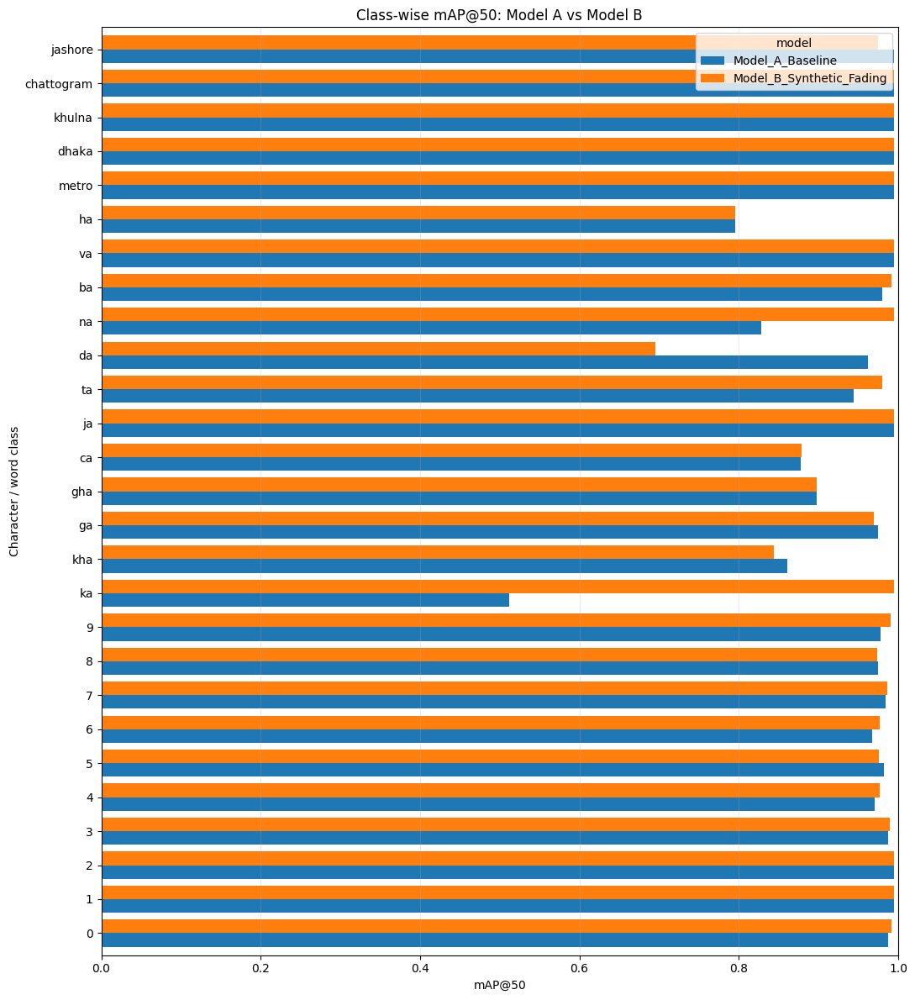


Saved per-class table: /kaggle/working/clean_test_classwise/per_class_metrics.csv
Saved comparison table: /kaggle/working/clean_test_classwise/per_class_model_comparison.csv
Saved figure: /kaggle/working/clean_test_classwise/classwise_map50_comparison.png

Confusion matrix and other validation plots should be under:
/kaggle/working/clean_test_classwise


In [164]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from ultralytics import YOLO

ROOT = Path("/kaggle/working")
DATA_DIR = ROOT / "bd_lpr_yolo"
EVAL_DIR = ROOT / "clean_test_evaluation"
OUT_DIR = ROOT / "clean_test_classwise"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_YAML = EVAL_DIR / "clean_test_data.yaml"

MODEL_PATHS = {
    "Model_A_Baseline": (
        ROOT / "lpr_training/model_A_baseline/weights/best.pt"
    ),
    "Model_B_Synthetic_Fading": (
        ROOT / "lpr_training/model_B_synthetic_fading/weights/best.pt"
    ),
}

assert DATA_YAML.exists(), f"Missing config: {DATA_YAML}"

with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, dict):
    names = {int(k): str(v) for k, v in names.items()}
else:
    names = dict(enumerate(names))

records = []

for model_name, weights in MODEL_PATHS.items():
    assert weights.exists(), f"Missing weights: {weights}"

    print(f"\nEvaluating class-wise metrics: {model_name}")

    model = YOLO(str(weights))

    metrics = model.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=640,
        batch=16,
        plots=True,
        save_json=False,
        project=str(OUT_DIR),
        name=model_name,
        exist_ok=True,
        verbose=False
    )

    box = metrics.box

    class_ids = np.asarray(box.ap_class_index, dtype=int)
    precision = np.asarray(box.p)
    recall = np.asarray(box.r)
    f1 = np.asarray(box.f1)
    ap50 = np.asarray(box.ap50)
    ap = np.asarray(box.ap)

    for i, class_id in enumerate(class_ids):
        records.append({
            "model": model_name,
            "class_id": int(class_id),
            "class_name": names[int(class_id)],
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(f1[i]),
            "mAP50": float(ap50[i]),
            "mAP50_95": float(ap[i]),
        })

class_df = pd.DataFrame(records)

# Keep classes without valid per-class metrics visible as missing,
# instead of incorrectly treating their performance as zero.
all_classes = pd.DataFrame({
    "class_id": list(names.keys()),
    "class_name": [names[k] for k in names.keys()]
})

full_df = (
    all_classes
    .merge(
        class_df,
        on=["class_id", "class_name"],
        how="left"
    )
    .sort_values("class_id")
)

full_df.to_csv(
    OUT_DIR / "per_class_metrics.csv",
    index=False
)

print("\n=== PER-CLASS METRICS ===")
print(full_df.round(4).to_string(index=False))

# Wide-format comparison table.
comparison = full_df.pivot(
    index=["class_id", "class_name"],
    columns="model",
    values=["precision", "recall", "f1", "mAP50", "mAP50_95"]
)
comparison.to_csv(OUT_DIR / "per_class_model_comparison.csv")

# Plot class-wise mAP@50 for both models.
plot_df = (
    full_df.pivot(
        index="class_name",
        columns="model",
        values="mAP50"
    )
    .reindex([names[k] for k in names.keys()])
)

ax = plot_df.plot(
    kind="barh",
    figsize=(11, 12),
    width=0.8
)

ax.set_title("Class-wise mAP@50: Model A vs Model B")
ax.set_xlabel("mAP@50")
ax.set_ylabel("Character / word class")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

fig_path = OUT_DIR / "classwise_map50_comparison.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved per-class table:", OUT_DIR / "per_class_metrics.csv")
print("Saved comparison table:", OUT_DIR / "per_class_model_comparison.csv")
print("Saved figure:", fig_path)

print("\nConfusion matrix and other validation plots should be under:")
print(OUT_DIR)

Total labeled test instances: 1921

Classes with the fewest test instances:
class_name  test_instances  f1_Model_A  f1_Model_B
        ka               2      0.6474      0.8386
        na               2      0.6077      0.8875
        va               4      0.9978      0.9830
        ha               5      0.8441      0.8476
        da               5      0.8331      0.6367
        ja               6      0.9776      0.9770
        ca               9      0.7835      0.8176
   jashore               9      0.9874      0.9131
chattogram               9      0.9875      0.9802
       kha              10      0.7505      0.8878

Largest F1 improvements:
class_name  test_instances  f1_delta_B_minus_A_pp  mAP50_delta_B_minus_A_pp
        na               2                  27.98                     16.67
        ka               2                  19.12                     48.36
       kha              10                  13.73                     -1.63
       gha              16       

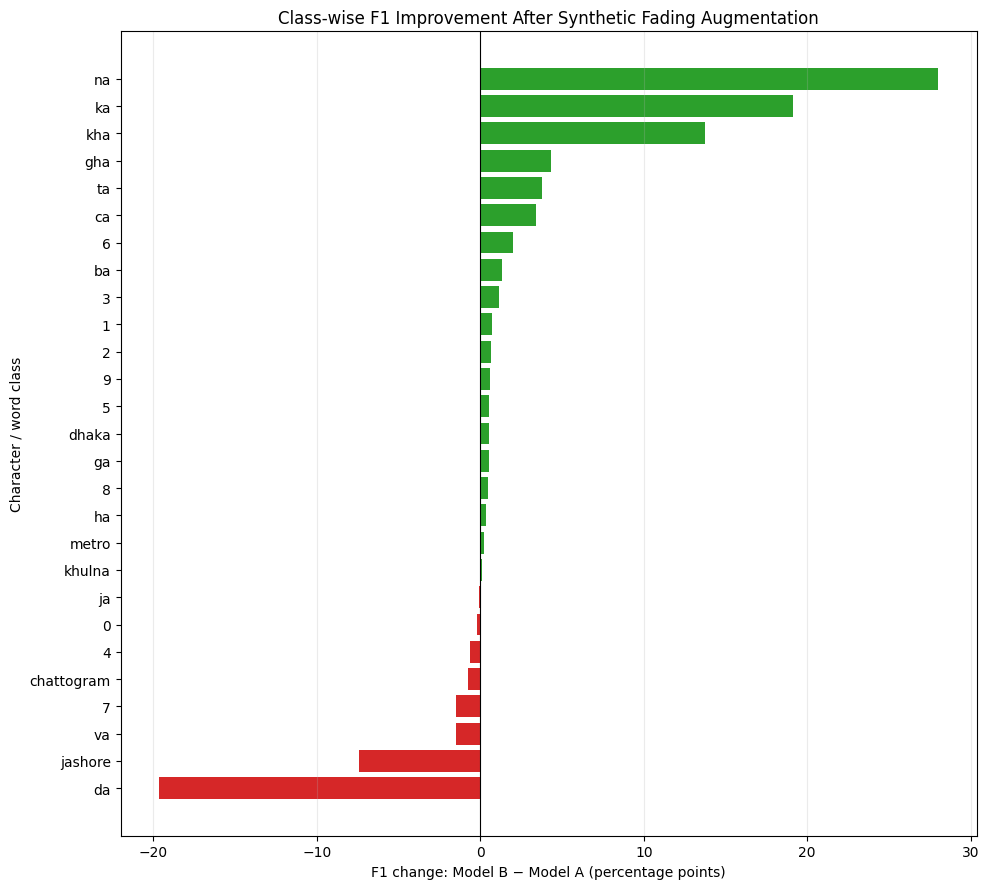


Saved comparison table: /kaggle/working/thesis_artifacts/tables/classwise_comparison_with_support.csv
Saved figure: /kaggle/working/thesis_artifacts/figures/figure_24_classwise_f1_change.png


In [165]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/working")
METRICS_PATH = ROOT / "clean_test_classwise" / "per_class_metrics.csv"
LABEL_DIR = ROOT / "bd_lpr_yolo" / "test" / "labels"

OUT_DIR = ROOT / "thesis_artifacts"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

assert METRICS_PATH.exists(), f"Missing metrics file: {METRICS_PATH}"
assert LABEL_DIR.exists(), f"Missing test labels: {LABEL_DIR}"

df = pd.read_csv(METRICS_PATH)

# Count actual test instances from YOLO ground-truth annotations.
support = Counter()

for label_path in LABEL_DIR.glob("*.txt"):
    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                support[int(float(parts[0]))] += 1

df["test_instances"] = df["class_id"].map(
    lambda class_id: support.get(int(class_id), 0)
)

metrics = ["precision", "recall", "f1", "mAP50", "mAP50_95"]

wide = df.pivot(
    index=["class_id", "class_name", "test_instances"],
    columns="model",
    values=metrics
)

model_a = "Model_A_Baseline"
model_b = "Model_B_Synthetic_Fading"

required_models = set(wide.columns.get_level_values(1))
if not {model_a, model_b}.issubset(required_models):
    raise ValueError(f"Unexpected model names: {sorted(required_models)}")

comparison = wide.index.to_frame(index=False)

for metric in metrics:
    comparison[f"{metric}_Model_A"] = wide[(metric, model_a)].to_numpy()
    comparison[f"{metric}_Model_B"] = wide[(metric, model_b)].to_numpy()
    comparison[f"{metric}_delta_B_minus_A_pp"] = (
        100 * (
            wide[(metric, model_b)].to_numpy()
            - wide[(metric, model_a)].to_numpy()
        )
    )

comparison["test_instances"] = comparison["test_instances"].astype(int)

# Save a full comparison table.
csv_path = TABLE_DIR / "classwise_comparison_with_support.csv"
comparison.to_csv(csv_path, index=False)

print("Total labeled test instances:", int(comparison["test_instances"].sum()))
print("\nClasses with the fewest test instances:")
print(
    comparison.sort_values("test_instances")[
        ["class_name", "test_instances",
         "f1_Model_A", "f1_Model_B"]
    ].head(10).round(4).to_string(index=False)
)

print("\nLargest F1 improvements:")
print(
    comparison.nlargest(8, "f1_delta_B_minus_A_pp")[
        ["class_name", "test_instances",
         "f1_delta_B_minus_A_pp", "mAP50_delta_B_minus_A_pp"]
    ].round(2).to_string(index=False)
)

print("\nLargest F1 declines:")
print(
    comparison.nsmallest(8, "f1_delta_B_minus_A_pp")[
        ["class_name", "test_instances",
         "f1_delta_B_minus_A_pp", "mAP50_delta_B_minus_A_pp"]
    ].round(2).to_string(index=False)
)

# Plot the change in F1 for all classes.
plot_df = comparison.sort_values("f1_delta_B_minus_A_pp")
fig, ax = plt.subplots(figsize=(10, 9))

bar_colors = [
    "tab:green" if x >= 0 else "tab:red"
    for x in plot_df["f1_delta_B_minus_A_pp"]
]

ax.barh(
    plot_df["class_name"],
    plot_df["f1_delta_B_minus_A_pp"],
    color=bar_colors
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("F1 change: Model B − Model A (percentage points)")
ax.set_ylabel("Character / word class")
ax.set_title("Class-wise F1 Improvement After Synthetic Fading Augmentation")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

figure_path = FIG_DIR / "figure_24_classwise_f1_change.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved comparison table:", csv_path)
print("Saved figure:", figure_path)

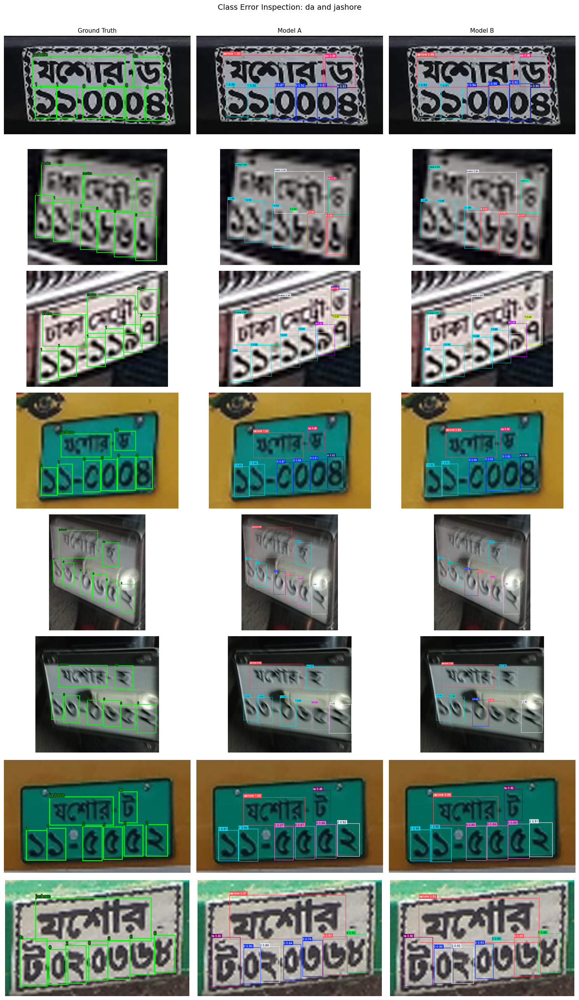

Images inspected: 8
Saved figure: /kaggle/working/thesis_artifacts/figures/figure_25_da_jashore_error_audit.png


In [166]:
from pathlib import Path
import yaml
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import numpy as np
from ultralytics import YOLO

ROOT = Path("/kaggle/working")
DATA_DIR = ROOT / "bd_lpr_yolo"
IMAGE_DIR = DATA_DIR / "test/images"
LABEL_DIR = DATA_DIR / "test/labels"

MODEL_A_PATH = (
    ROOT / "lpr_training/model_A_baseline/weights/best.pt"
)
MODEL_B_PATH = (
    ROOT / "lpr_training/model_B_synthetic_fading/weights/best.pt"
)

OUT_DIR = ROOT / "thesis_artifacts/figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA_DIR / "data.yaml", "r") as f:
    cfg = yaml.safe_load(f)

names = cfg["names"]
if isinstance(names, dict):
    names = {int(k): str(v) for k, v in names.items()}
else:
    names = dict(enumerate(names))

# Classes selected for investigation
TARGET_CLASSES = {17: "da", 26: "jashore"}

# Find test images containing either class in ground truth
image_lookup = {
    p.stem: p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
}

selected = []

for class_id, class_name in TARGET_CLASSES.items():
    matches = []

    for image_id, image_path in image_lookup.items():
        label_path = LABEL_DIR / f"{image_id}.txt"
        if not label_path.exists():
            continue

        with open(label_path, "r") as f:
            class_ids = [
                int(float(line.split()[0]))
                for line in f
                if len(line.split()) >= 5
            ]

        if class_id in class_ids:
            matches.append(image_path)

    # Up to four examples per class
    selected.extend(matches[:4])

# Remove duplicate images while preserving order
selected = list({p.stem: p for p in selected}.values())

assert selected, "No images with the selected classes were found."

model_a = YOLO(str(MODEL_A_PATH))
model_b = YOLO(str(MODEL_B_PATH))

# Small font for ground-truth labels
font_path = Path("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf")
font = ImageFont.truetype(str(font_path), 9) if font_path.exists() \
    else ImageFont.load_default()


def draw_ground_truth(image_path):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    w_img, h_img = image.size

    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue

            cls = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:5])

            x1 = (x - w / 2) * w_img
            y1 = (y - h / 2) * h_img
            x2 = (x + w / 2) * w_img
            y2 = (y + h / 2) * h_img

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="lime",
                width=2
            )

            label = names.get(cls, str(cls))
            draw.text(
                (x1, max(0, y1 - 10)),
                label,
                fill="lime",
                font=font,
                stroke_width=1,
                stroke_fill="black"
            )

    return image


def predict_annotated(model, image_path):
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    # Small annotation labels and thin boxes
    annotated = result.plot(
        pil=True,
        font_size=7,
        line_width=1,
        labels=True,
        conf=True
    )

    return annotated.convert("RGB") if isinstance(annotated, Image.Image) \
        else Image.fromarray(np.asarray(annotated))


fig, axes = plt.subplots(
    len(selected), 3,
    figsize=(15, max(4, len(selected) * 3.2)),
    squeeze=False
)

for row_idx, image_path in enumerate(selected):
    panels = [
        draw_ground_truth(image_path),
        predict_annotated(model_a, image_path),
        predict_annotated(model_b, image_path)
    ]

    axes[row_idx, 0].set_ylabel(
        image_path.stem,
        rotation=0,
        labelpad=55,
        fontsize=8,
        va="center"
    )

    for col_idx, panel in enumerate(panels):
        axes[row_idx, col_idx].imshow(panel)
        axes[row_idx, col_idx].axis("off")

        if row_idx == 0:
            axes[row_idx, col_idx].set_title(
                ["Ground Truth", "Model A", "Model B"][col_idx],
                fontsize=11
            )

plt.suptitle(
    "Class Error Inspection: da and jashore",
    fontsize=14,
    y=1.002
)
plt.tight_layout()

figure_path = OUT_DIR / "figure_25_da_jashore_error_audit.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Images inspected:", len(selected))
print("Saved figure:", figure_path)

In [167]:
from pathlib import Path
from collections import Counter, defaultdict
import yaml
import numpy as np
import pandas as pd
from ultralytics import YOLO

ROOT = Path("/kaggle/working")
DATA_DIR = ROOT / "bd_lpr_yolo"

MODEL_PATHS = {
    "Model_A_Baseline": (
        ROOT / "lpr_training/model_A_baseline/weights/best.pt"
    ),
    "Model_B_Synthetic_Fading": (
        ROOT / "lpr_training/model_B_synthetic_fading/weights/best.pt"
    ),
}

OUT_DIR = ROOT / "targeted_class_improvement"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Load existing class configuration.
with open(DATA_DIR / "data.yaml", "r") as f:
    cfg = yaml.safe_load(f)

names = cfg["names"]
if isinstance(names, dict):
    names = {int(k): str(v) for k, v in names.items()}
else:
    names = dict(enumerate(names))

# Classes flagged in the previous test analysis.
TARGET_IDS = [17, 26]  # da, jashore

# ------------------------------------------------------
# 1. COUNT CLASS INSTANCES AND IMAGES PER DATA SPLIT
# ------------------------------------------------------
support_rows = []

for split in ["train", "validation", "test"]:
    labels_dir = DATA_DIR / split / "labels"

    if not labels_dir.exists():
        raise FileNotFoundError(f"Missing labels: {labels_dir}")

    instance_counts = Counter()
    image_counts = Counter()

    for label_path in labels_dir.glob("*.txt"):
        classes_in_image = set()

        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    class_id = int(float(parts[0]))
                    instance_counts[class_id] += 1
                    classes_in_image.add(class_id)

        image_counts.update(classes_in_image)

    for class_id, class_name in names.items():
        support_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_name,
            "instances": instance_counts[class_id],
            "images_containing_class": image_counts[class_id],
        })

support_df = pd.DataFrame(support_rows)
support_df.to_csv(OUT_DIR / "class_support_by_split.csv", index=False)

print("=== SUPPORT FOR TARGET CLASSES ===")
print(
    support_df[
        support_df["class_id"].isin(TARGET_IDS)
    ].to_string(index=False)
)

# ------------------------------------------------------
# 2. BUILD AN EXPLICIT VALIDATION CONFIGURATION
# ------------------------------------------------------
val_cfg = dict(cfg)
val_cfg["path"] = str(DATA_DIR)
val_cfg["train"] = "train/images"
val_cfg["val"] = "validation/images"
val_cfg["test"] = "test/images"

val_yaml = OUT_DIR / "validation_data.yaml"

with open(val_yaml, "w") as f:
    yaml.safe_dump(val_cfg, f, sort_keys=False)

# ------------------------------------------------------
# 3. EVALUATE BOTH MODELS ON VALIDATION ONLY
# ------------------------------------------------------
val_rows = []

for model_name, weights_path in MODEL_PATHS.items():
    if not weights_path.exists():
        raise FileNotFoundError(f"Missing weights: {weights_path}")

    print(f"\nEvaluating validation split: {model_name}")

    model = YOLO(str(weights_path))

    metrics = model.val(
        data=str(val_yaml),
        split="val",
        imgsz=640,
        batch=16,
        plots=False,
        save_json=False,
        project=str(OUT_DIR),
        name=f"{model_name}_validation",
        exist_ok=True,
        verbose=False,
    )

    box = metrics.box
    class_ids = np.asarray(box.ap_class_index, dtype=int)

    arrays = {
        "precision": np.asarray(box.p),
        "recall": np.asarray(box.r),
        "f1": np.asarray(box.f1),
        "mAP50": np.asarray(box.ap50),
        "mAP50_95": np.asarray(box.ap),
    }

    for i, class_id in enumerate(class_ids):
        if class_id not in TARGET_IDS:
            continue

        val_rows.append({
            "model": model_name,
            "class_id": int(class_id),
            "class_name": names[int(class_id)],
            **{
                key: float(values[i])
                for key, values in arrays.items()
            }
        })

val_results = pd.DataFrame(val_rows)
val_results.to_csv(
    OUT_DIR / "target_class_validation_metrics.csv",
    index=False
)

print("\n=== TARGET CLASS VALIDATION RESULTS ===")
print(val_results.round(4).to_string(index=False))

print("\nSaved support audit:", OUT_DIR / "class_support_by_split.csv")
print("Saved validation metrics:",
      OUT_DIR / "target_class_validation_metrics.csv")

=== SUPPORT FOR TARGET CLASSES ===
     split  class_id class_name  instances  images_containing_class
     train        17         da         48                       48
     train        26    jashore        144                      144
validation        17         da          4                        4
validation        26    jashore         21                       21
      test        17         da          5                        5
      test        26    jashore          9                        9

Evaluating validation split: Model_A_Baseline
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 406.8±105.3 MB/s, size: 10.1 KB)
val: Scanning /kaggle/working/bd_lpr_yolo/validation/labels.cache... 363 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 363/363 138.4Mit/s 0.0s
                 Class     Images  Instances  

In [168]:
from pathlib import Path
import shutil
import zlib

import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageEnhance, ImageFilter

# --------------------------------------------------
# PATHS
# --------------------------------------------------
SOURCE = Path("/kaggle/working/bd_lpr_yolo")
FADE_MODULE = Path("/kaggle/working/bd_plate_fade.py")
OUTPUT = Path("/kaggle/working/bd_lpr_da_finetune_data")

TARGET_CLASS_ID = 17  # da
AUGMENTED_COPIES_PER_TARGET_IMAGE = 2

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

assert (SOURCE / "data.yaml").exists()
assert FADE_MODULE.exists(), f"Missing {FADE_MODULE}"

# Import your established fading implementation.
import importlib.util

spec = importlib.util.spec_from_file_location(
    "bd_plate_fade", str(FADE_MODULE)
)
fade_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(fade_module)

fade_once = fade_module.fade_once

if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

train_images_out = OUTPUT / "train/images"
train_labels_out = OUTPUT / "train/labels"
train_images_out.mkdir(parents=True, exist_ok=True)
train_labels_out.mkdir(parents=True, exist_ok=True)

SOURCE_IMAGES = SOURCE / "train/images"
SOURCE_LABELS = SOURCE / "train/labels"

def label_classes(label_path):
    classes = set()

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                classes.add(int(float(parts[0])))

    return classes


def save_image(array, path):
    array = np.asarray(array, dtype=np.uint8)
    array = np.ascontiguousarray(array)

    with Image.fromarray(array, mode="RGB") as im:
        if path.suffix.lower() in {".jpg", ".jpeg"}:
            im.save(path, quality=95)
        else:
            im.save(path)


def mild_photometric_augmentation(rgb, seed):
    """Change appearance only; bounding boxes remain valid."""
    rng = np.random.default_rng(seed)

    im = Image.fromarray(np.asarray(rgb, dtype=np.uint8), mode="RGB")
    im = ImageEnhance.Brightness(im).enhance(
        float(rng.uniform(0.80, 1.15))
    )
    im = ImageEnhance.Contrast(im).enhance(
        float(rng.uniform(0.80, 1.20))
    )
    im = ImageEnhance.Color(im).enhance(
        float(rng.uniform(0.85, 1.10))
    )

    if rng.random() < 0.35:
        im = im.filter(
            ImageFilter.GaussianBlur(
                radius=float(rng.uniform(0.1, 0.45))
            )
        )

    arr = np.asarray(im, dtype=np.float32)
    sigma = float(rng.uniform(1.0, 4.0))
    noise = rng.normal(0, sigma, size=arr.shape)

    return np.clip(arr + noise, 0, 255).astype(np.uint8)


manifest = []
target_images = 0

# Copy every original training image/label unchanged first.
source_files = sorted(
    p for p in SOURCE_IMAGES.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
)

for image_path in source_files:
    label_path = SOURCE_LABELS / f"{image_path.stem}.txt"

    if not label_path.exists():
        raise FileNotFoundError(f"Missing annotation: {label_path}")

    dst_img = train_images_out / image_path.name
    dst_label = train_labels_out / label_path.name

    shutil.copy2(image_path, dst_img)
    shutil.copy2(label_path, dst_label)

    classes = label_classes(label_path)

    if TARGET_CLASS_ID not in classes:
        continue

    target_images += 1

    with Image.open(image_path) as im:
        clean_rgb = np.asarray(im.convert("RGB"), dtype=np.uint8)

    for version in range(1, AUGMENTED_COPIES_PER_TARGET_IMAGE + 1):
        seed = zlib.crc32(
            f"{image_path.name}-da-augmentation-{version}".encode()
        )
        rng = np.random.default_rng(seed)

        if version == 1:
            augmented = fade_once(clean_rgb.copy(), rng=rng)
            augmentation_name = "synthetic_fade"
        else:
            augmented = mild_photometric_augmentation(
                clean_rgb.copy(), seed
            )
            augmentation_name = "photometric"

        augmented = np.asarray(augmented, dtype=np.uint8)

        if augmented.shape != clean_rgb.shape:
            raise ValueError(
                f"Shape changed for {image_path.name}: "
                f"{clean_rgb.shape} -> {augmented.shape}"
            )

        stem = f"aug_da_{image_path.stem}_v{version}"
        aug_img_path = train_images_out / f"{stem}{image_path.suffix}"
        aug_label_path = train_labels_out / f"{stem}.txt"

        save_image(augmented, aug_img_path)

        # No geometric transformation: preserve original YOLO labels.
        shutil.copy2(label_path, aug_label_path)

        manifest.append({
            "source_image": image_path.name,
            "augmented_image": aug_img_path.name,
            "augmentation": augmentation_name,
            "seed": seed,
            "target_class": "da",
            "annotation_copied_unchanged": True
        })

# Prepare a dataset config.
with open(SOURCE / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

config["path"] = str(OUTPUT)
config["train"] = "train/images"

# Use the original, untouched validation and test splits.
config["val"] = str(SOURCE / "validation/images")
config["test"] = str(SOURCE / "test/images")

with open(OUTPUT / "data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

pd.DataFrame(manifest).to_csv(
    OUTPUT / "augmentation_manifest.csv", index=False
)

original_count = len(source_files)
augmented_count = len(manifest)

print("Target-class images augmented:", target_images)
print("Original training images:", original_count)
print("Additional augmented images:", augmented_count)
print("Total fine-tuning training images:",
      original_count + augmented_count)
print("New data configuration:", OUTPUT / "data.yaml")

assert augmented_count == target_images * AUGMENTED_COPIES_PER_TARGET_IMAGE

Target-class images augmented: 48
Original training images: 3480
Additional augmented images: 96
Total fine-tuning training images: 3576
New data configuration: /kaggle/working/bd_lpr_da_finetune_data/data.yaml


In [169]:
from pathlib import Path
from ultralytics import YOLO

BASE_MODEL = Path(
    "/kaggle/working/lpr_training/"
    "model_B_synthetic_fading/weights/best.pt"
)
DATA_YAML = Path(
    "/kaggle/working/bd_lpr_da_finetune_data/data.yaml"
)

assert BASE_MODEL.exists(), f"Missing model: {BASE_MODEL}"
assert DATA_YAML.exists(), f"Missing dataset config: {DATA_YAML}"

model = YOLO(str(BASE_MODEL))

results = model.train(
    data=str(DATA_YAML),
    epochs=25,
    patience=8,
    imgsz=640,
    batch=16,

    # Conservative fine-tuning settings.
    lr0=0.0003,
    lrf=0.01,
    optimizer="AdamW",
    weight_decay=0.0005,

    # Preserve plate layout.
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    fliplr=0.0,
    flipud=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.10,
    perspective=0.0,

    # Mild appearance augmentation.
    hsv_h=0.015,
    hsv_s=0.30,
    hsv_v=0.20,

    seed=42,
    deterministic=True,
    workers=2,
    plots=True,
    val=True,
    save=True,
    project="/kaggle/working/lpr_targeted_training",
    name="model_B_da_finetune",
    exist_ok=True
)

print("\nFine-tuning finished.")
print(
    "Candidate best weights:",
    "/kaggle/working/lpr_targeted_training/"
    "model_B_da_finetune/weights/best.pt"
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bd_lpr_da_finetune_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/lpr_training/model_B_synthetic_fading/weights/best.pt, momentum=0.937, mosaic=0.0, mu

In [172]:
import zipfile, os, shutil

src = '/kaggle/working'
dst = '/tmp/all_works_together.zip'   # built outside working dir

exclude_dirs  = {'.virtual_documents', 'synthetic_faded_dataset'}
exclude_files = {'synthetic_faded_dataset.zip', 'working_all.zip', 'all_works_together.zip'}

with zipfile.ZipFile(dst, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(src):
        dirs[:] = [d for d in dirs if d not in exclude_dirs]
        for f in files:
            if f in exclude_files:
                continue
            p = os.path.join(root, f)
            z.write(p, os.path.relpath(p, src))

shutil.copy(dst, os.path.join(src, 'all_works_together.zip'))
print('Done:', os.path.getsize('/kaggle/working/all_works_together.zip') / 1e6, 'MB')

Done: 2200.14624 MB


In [173]:
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
from ultralytics import YOLO

ROOT = Path("/kaggle/working")
OUT = ROOT / "targeted_class_improvement"
OUT.mkdir(parents=True, exist_ok=True)

VAL_YAML = OUT / "validation_data.yaml"

MODELS = {
    "Original_Model_B": (
        ROOT / "lpr_training/model_B_synthetic_fading/weights/best.pt"
    ),
    "FineTuned_Model_B": (
        ROOT / "lpr_targeted_training/model_B_da_finetune/weights/best.pt"
    ),
}

assert VAL_YAML.exists(), f"Missing validation config: {VAL_YAML}"

with open(VAL_YAML, "r") as f:
    cfg = yaml.safe_load(f)

names = cfg["names"]
if isinstance(names, dict):
    names = {int(k): str(v) for k, v in names.items()}
else:
    names = dict(enumerate(names))

overall_rows = []
class_rows = []

for model_name, weights in MODELS.items():
    assert weights.exists(), f"Missing weights: {weights}"
    print(f"\nValidating {model_name}")

    model = YOLO(str(weights))
    metrics = model.val(
        data=str(VAL_YAML),
        split="val",
        imgsz=640,
        batch=16,
        plots=False,
        save_json=False,
        project=str(OUT),
        name=model_name,
        exist_ok=True,
        verbose=False,
    )

    box = metrics.box

    overall_rows.append({
        "model": model_name,
        "precision": float(box.mp),
        "recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50_95": float(box.map),
    })

    arrays = {
        "precision": np.asarray(box.p),
        "recall": np.asarray(box.r),
        "F1": np.asarray(box.f1),
        "mAP50": np.asarray(box.ap50),
        "mAP50_95": np.asarray(box.ap),
    }

    for i, class_id in enumerate(np.asarray(box.ap_class_index, dtype=int)):
        class_rows.append({
            "model": model_name,
            "class_id": int(class_id),
            "class_name": names[int(class_id)],
            **{
                metric: float(values[i])
                for metric, values in arrays.items()
            }
        })

overall = pd.DataFrame(overall_rows)
per_class = pd.DataFrame(class_rows)

overall.to_csv(OUT / "finetune_overall_validation_comparison.csv", index=False)
per_class.to_csv(OUT / "finetune_per_class_validation_comparison.csv", index=False)

print("\n=== OVERALL VALIDATION COMPARISON ===")
print(overall.round(4).to_string(index=False))

print("\n=== TARGET CLASSES: DA AND JASHORE ===")
print(
    per_class[
        per_class["class_name"].isin(["da", "jashore"])
    ].round(4).to_string(index=False)
)

print("\nSaved results to:", OUT)


Validating Original_Model_B
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 262.7±68.4 MB/s, size: 9.8 KB)
val: Scanning /kaggle/working/bd_lpr_yolo/validation/labels.cache... 363 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 363/363 138.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 10.3it/s 2.2s0.1s
                   all        363       3180      0.949      0.891      0.946      0.707
Speed: 0.5ms preprocess, 2.4ms inference, 0.0ms loss, 0.9ms postprocess per image

Validating FineTuned_Model_B
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,010,913 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 517.2±195.3 MB/s, size: 11.6 K

In [174]:
from pathlib import Path
import zipfile
import hashlib
import json
import platform
import sys
from datetime import datetime
from IPython.display import FileLink, display

ROOT = Path("/kaggle/working")
STAGE = ROOT / "final_thesis_research_backup"
ZIP_PATH = ROOT / "final_thesis_research_backup.zip"

if STAGE.exists():
    import shutil
    shutil.rmtree(STAGE)

STAGE.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Select important research artifacts
# --------------------------------------------------
files_to_collect = [
    # Original research models
    "lpr_training/model_A_baseline/weights/best.pt",
    "lpr_training/model_A_baseline/weights/last.pt",
    "lpr_training/model_B_synthetic_fading/weights/best.pt",
    "lpr_training/model_B_synthetic_fading/weights/last.pt",

    # Exploratory targeted fine-tuning
    "lpr_targeted_training/model_B_da_finetune/weights/best.pt",
    "lpr_targeted_training/model_B_da_finetune/weights/last.pt",

    # Separate license plate localization model
    "lp_detection_training/license_plate_yolov8n/weights/best.pt",
    "lp_detection_training/license_plate_yolov8n/weights/last.pt",

    # Dataset configurations and fading implementation
    "bd_lpr_yolo/data.yaml",
    "bd_plate_fade.py",

    # Core clean test results
    "clean_test_evaluation/clean_test_model_comparison.csv",
    "clean_test_sequence_evaluation/clean_test_sequence_summary.csv",
    "clean_test_sequence_evaluation/clean_test_sequence_per_image.csv",
    "clean_test_sequence_evaluation/paired_statistical_comparison.csv",

    # Class-wise metrics and diagnostics
    "clean_test_classwise/per_class_metrics.csv",
    "clean_test_classwise/per_class_model_comparison.csv",
    "targeted_class_improvement/class_support_by_split.csv",
    "targeted_class_improvement/target_class_validation_metrics.csv",
    "targeted_class_improvement/finetune_overall_validation_comparison.csv",
    "targeted_class_improvement/finetune_per_class_validation_comparison.csv",

    # Synthetic fading robustness benchmark
    "lpr_robustness_comparison.csv",
    "lpr_robustness_deltas.csv",

    # Real faded plate evaluation
    "real_faded_ground_truth_roman.csv",
    "real_faded_final_evaluation/model_A_detections.csv",
    "real_faded_final_evaluation/model_B_detections.csv",
    "real_faded_final_evaluation/model_A_vs_B_standardized_results.csv",
    "real_faded_final_evaluation/registration_metrics.csv",

    # Generated archives, if present
    "synthetic_faded_dataset.zip",
    "thesis_figures_and_tables.zip",
]

# Copy the selected files and collect missing paths.
import shutil

copied = []
missing = []

for relative_path in files_to_collect:
    source = ROOT / relative_path

    if source.is_file():
        destination = STAGE / relative_path
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)
        copied.append(relative_path)
    else:
        missing.append(relative_path)

# Include all available thesis figures and tables.
for relative_dir in [
    "thesis_artifacts/figures",
    "thesis_artifacts/tables",
]:
    source_dir = ROOT / relative_dir

    if source_dir.exists():
        for source in source_dir.rglob("*"):
            if source.is_file():
                destination = STAGE / source.relative_to(ROOT)
                destination.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(source, destination)
                copied.append(str(source.relative_to(ROOT)))

# --------------------------------------------------
# 2. Write environment and inventory information
# --------------------------------------------------
environment = {
    "created_at": datetime.now().isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "note": (
        "Backup of research artifacts. The complete original "
        "image datasets are not included. Missing files were skipped."
    ),
}

(STAGE / "environment.json").write_text(
    json.dumps(environment, indent=2),
    encoding="utf-8"
)

(STAGE / "BACKUP_README.txt").write_text(
    "\n".join([
        "FINAL THESIS RESEARCH BACKUP",
        "",
        "Contains available models, evaluation tables,",
        "ground-truth files, figures, tables, and dataset archives.",
        "",
        "Model B original weights are the primary thesis checkpoint.",
        "The targeted fine-tuning checkpoint is exploratory.",
        "",
        "The original full image datasets are not included.",
        "Retain a separate copy of the original Kaggle dataset.",
    ]),
    encoding="utf-8"
)

# Create a file inventory with SHA-256 checksums.
inventory = []

for path in sorted(STAGE.rglob("*")):
    if path.is_file() and path.name != "file_inventory.csv":
        digest = hashlib.sha256(path.read_bytes()).hexdigest()

        inventory.append({
            "relative_path": str(path.relative_to(STAGE)),
            "size_bytes": path.stat().st_size,
            "sha256": digest,
        })

import pandas as pd

pd.DataFrame(inventory).to_csv(
    STAGE / "file_inventory.csv",
    index=False
)

# --------------------------------------------------
# 3. Create the final ZIP
# --------------------------------------------------
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=3
) as archive:
    for path in sorted(STAGE.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=str(path.relative_to(STAGE))
            )

# Verify archive integrity.
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_member = archive.testzip()
    assert bad_member is None, f"ZIP integrity check failed: {bad_member}"

print("BACKUP CREATED SUCCESSFULLY")
print("Files collected:", len(inventory))
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("ZIP location:", ZIP_PATH)

if missing:
    print(f"\nFiles not found: {len(missing)}")
    for item in missing:
        print("  -", item)
else:
    print("\nAll specifically requested artifact paths were found.")

print("\nDownload your backup:")
display(FileLink(str(ZIP_PATH)))

BACKUP CREATED SUCCESSFULLY
Files collected: 130
ZIP size: 253.75 MB
ZIP location: /kaggle/working/final_thesis_research_backup.zip

Files not found: 1
  - thesis_figures_and_tables.zip

Download your backup:


/kaggle/working/final_thesis_research_backup.zip

In [175]:
"""Generate thesis-ready tables/figures from existing Kaggle outputs and package them.
No model training is performed. Missing optional sources are logged and skipped.
"""
from pathlib import Path
from collections import Counter
import shutil, zipfile, hashlib, json, platform, sys, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('/kaggle/working')
DATA = ROOT / 'bd_lpr_yolo'
ART = ROOT / 'thesis_artifacts'
FIG = ART / 'figures'
TAB = ART / 'tables'
STAGE = ROOT / 'thesis_final_bundle_contents'
BUNDLE = ROOT / 'thesis_final_artifacts_bundle.zip'
for d in [FIG, TAB]: d.mkdir(parents=True, exist_ok=True)

# -------- Source paths --------
paths = {
    'detection': ROOT / 'clean_test_evaluation/clean_test_model_comparison.csv',
    'sequence_per_image': ROOT / 'clean_test_sequence_evaluation/clean_test_sequence_per_image.csv',
    'sequence_summary': ROOT / 'clean_test_sequence_evaluation/clean_test_sequence_summary.csv',
    'paired': ROOT / 'clean_test_sequence_evaluation/paired_statistical_comparison.csv',
    'classwise': ROOT / 'clean_test_classwise/per_class_metrics.csv',
    'robustness': ROOT / 'lpr_robustness_comparison.csv',
    'finetune_overall': ROOT / 'targeted_class_improvement/finetune_overall_validation_comparison.csv',
    'finetune_classwise': ROOT / 'targeted_class_improvement/finetune_per_class_validation_comparison.csv',
    'ground_truth_real': ROOT / 'real_faded_ground_truth_roman.csv',
    'fade_module': ROOT / 'bd_plate_fade.py',
    'data_yaml': DATA / 'data.yaml',
}
missing_sources = []

def load_csv(key):
    p = paths[key]
    if p.exists():
        return pd.read_csv(p)
    missing_sources.append(str(p))
    return None

def save_table(df, filename):
    dest = TAB / filename
    df.to_csv(dest, index=False)
    print('Saved table:', dest)
    return dest

def save_fig(fig, filename):
    dest = FIG / filename
    fig.savefig(dest, dpi=300, bbox_inches='tight')
    plt.close(fig)
    print('Saved figure:', dest)
    return dest

plt.rcParams.update({'font.size': 9, 'figure.dpi': 120})

# -------- 1) Dataset composition and class support --------
if DATA.exists():
    try:
        import yaml
        with open(paths['data_yaml'], 'r') as f: cfg = yaml.safe_load(f)
        raw_names = cfg.get('names', {})
        names = ({int(k): str(v) for k, v in raw_names.items()}
                 if isinstance(raw_names, dict) else dict(enumerate(raw_names)))
        extensions = {'.jpg','.jpeg','.png','.bmp','.webp'}
        split_rows, support = [], []
        for split in ['train','validation','test']:
            imdir = DATA / split / 'images'; labdir = DATA / split / 'labels'
            imgs = [p for p in imdir.glob('*') if p.suffix.lower() in extensions] if imdir.exists() else []
            inst = Counter(); image_support = Counter(); labels_found = 0; object_total = 0
            if labdir.exists():
                for lab in labdir.glob('*.txt'):
                    labels_found += 1; seen = set()
                    for line in lab.read_text(encoding='utf-8').splitlines():
                        cols = line.split()
                        if len(cols) >= 5:
                            cid = int(float(cols[0])); inst[cid] += 1; seen.add(cid); object_total += 1
                    image_support.update(seen)
            split_rows.append({'split': split, 'images': len(imgs), 'label_files': labels_found,
                               'annotated_instances': object_total, 'distinct_classes_present': sum(v > 0 for v in inst.values())})
            for cid, cname in names.items():
                support.append({'split': split, 'class_id': cid, 'class_name': cname,
                                'instances': inst[cid], 'images_containing_class': image_support[cid]})
        split_df = pd.DataFrame(split_rows)
        supp_df = pd.DataFrame(support)
        save_table(split_df, 'table_3_1_dataset_split_summary.csv')
        save_table(supp_df, 'table_3_2_class_support_by_split.csv')
        # Figure: class frequency in train split
        train_supp = supp_df[supp_df.split == 'train'].sort_values('instances')
        fig, ax = plt.subplots(figsize=(9, 8))
        ax.barh(train_supp.class_name, train_supp.instances)
        ax.set_xlabel('Annotated training instances'); ax.set_ylabel('Class')
        ax.set_title('Training-split class distribution')
        ax.grid(axis='x', alpha=.25)
        save_fig(fig, 'figure_3_3_training_class_distribution.png')
    except Exception as e:
        print('WARNING: Dataset support tables skipped:', repr(e))
else:
    missing_sources.append(str(DATA))
    names = {}

# -------- 2) Main clean-test detection metrics --------
det = load_csv('detection')
if det is not None:
    save_table(det, 'table_4_1_clean_test_detection_metrics.csv')
    # chart expects proportions, convert to percent
    metric_map = [('precision','Precision'),('recall','Recall'),('mAP50','mAP@50'),('mAP50_95','mAP@50-95')]
    if {'model', *[x[0] for x in metric_map]}.issubset(det.columns):
        fig, ax = plt.subplots(figsize=(8,4.5)); x=np.arange(len(metric_map)); w=.36
        models=list(det['model'])
        vals=[]
        for col,_ in metric_map: vals.append(pd.to_numeric(det[col], errors='coerce').to_numpy()*100)
        for i,row in det.reset_index(drop=True).iterrows():
            heights=[float(pd.to_numeric(row[col], errors='coerce'))*100 for col,_ in metric_map]
            off=(-w/2 if i==0 else w/2)
            bars=ax.bar(x+off, heights, w, label=str(row['model']).replace('Model_A_Baseline','Model A').replace('Model_B_Synthetic_Fading','Model B'))
            ax.bar_label(bars, fmt='%.1f', fontsize=7, padding=2)
        ax.set_xticks(x,[b for _,b in metric_map]); ax.set_ylim(0,105); ax.set_ylabel('Percentage (%)')
        ax.set_title('Clean test-set object-detection performance'); ax.grid(axis='y',alpha=.25); ax.legend(frameon=False)
        save_fig(fig,'figure_4_1_clean_test_detection_metrics.png')

# -------- 3) Sequence metrics + paired stats --------
seq = load_csv('sequence_per_image')
seq_summary = load_csv('sequence_summary')
paired = load_csv('paired')
if seq is not None and {'model','sequence_exact','digit_exact','token_error_rate','digit_CER'}.issubset(seq.columns):
    for c in ['sequence_exact','digit_exact']:
        if seq[c].dtype != bool:
            seq[c] = seq[c].astype(str).str.lower().map({'true':True,'false':False,'1':True,'0':False})
    summary = seq.groupby('model').agg(
        images=('image_id','nunique'), full_sequence_exact=('sequence_exact','mean'),
        token_error_rate=('token_error_rate','mean'), digit_exact=('digit_exact','mean'), digit_CER=('digit_CER','mean')
    ).reset_index()
    for c in ['full_sequence_exact','token_error_rate','digit_exact','digit_CER']: summary[c] *= 100
    save_table(summary, 'table_4_2_clean_test_sequence_metrics.csv')
    if paired is not None: save_table(paired, 'table_4_3_paired_statistical_comparison.csv')
    # sequence figure
    cols=[('full_sequence_exact','Exact full-sequence accuracy'),('digit_exact','Exact digit-sequence accuracy')]
    fig, axes = plt.subplots(1,2,figsize=(10,4))
    x=np.arange(2); w=.34
    for idx,(col,title) in enumerate(cols):
        ax=axes[idx]
        bars1=ax.bar(x[0]-w/2, summary.loc[summary.model=='Model_A_Baseline',col].iloc[0],w,label='Model A') if (summary.model=='Model_A_Baseline').any() else None
        bars2=ax.bar(x[0]+w/2, summary.loc[summary.model=='Model_B_Synthetic_Fading',col].iloc[0],w,label='Model B') if (summary.model=='Model_B_Synthetic_Fading').any() else None
        ercol='token_error_rate' if col=='full_sequence_exact' else 'digit_CER'
        a=summary.loc[summary.model=='Model_A_Baseline',ercol]
        b=summary.loc[summary.model=='Model_B_Synthetic_Fading',ercol]
        if len(a) and len(b):
            ax.bar(x[1]-w/2, float(a.iloc[0]), w)
            ax.bar(x[1]+w/2, float(b.iloc[0]), w)
        ax.set_xticks(x,[title, 'Error rate (%)']); ax.set_ylabel('Percentage (%)'); ax.grid(axis='y',alpha=.25); ax.set_title(title)
        if bars1 is not None and bars2 is not None: ax.legend(frameon=False)
    save_fig(fig, 'figure_4_2_sequence_recognition_metrics.png')
elif seq_summary is not None:
    save_table(seq_summary, 'table_4_2_clean_test_sequence_metrics.csv')
if paired is not None and seq is None:
    save_table(paired, 'table_4_3_paired_statistical_comparison.csv')

# -------- 4) Synthetic fading benchmark --------
rob = load_csv('robustness')
if rob is not None:
    save_table(rob, 'table_4_4_synthetic_fading_robustness.csv')
    # column names expected from earlier notebook output
    condition_col = 'condition' if 'condition' in rob.columns else None
    model_col = 'model' if 'model' in rob.columns else None
    if condition_col and model_col and {'mAP50','recall','mAP50_95'}.issubset(rob.columns):
        order=['clean','synthetic_mild','synthetic_moderate','synthetic_strong','mild','moderate','strong']
        rob['_order']=rob[condition_col].astype(str).str.lower().map({v:i for i,v in enumerate(order)}).fillna(99)
        rob=rob.sort_values('_order')
        for metric,title,filename in [('mAP50','mAP@50 under synthetic fading','figure_4_3_map50_fading_robustness.png'),('recall','Recall under synthetic fading','figure_4_4_recall_fading_robustness.png'),('mAP50_95','mAP@50-95 under synthetic fading','figure_4_5_map5095_fading_robustness.png')]:
            fig,ax=plt.subplots(figsize=(7.8,4.4))
            for model_name,grp in rob.groupby(model_col):
                ax.plot(grp[condition_col].astype(str),grp[metric].astype(float)*100,marker='o',linewidth=2,label=str(model_name).replace('Model_A_Baseline','Model A').replace('Model_B_Synthetic_Fading','Model B'))
            ax.set_ylabel('Percentage (%)'); ax.set_title(title); ax.grid(alpha=.25); ax.legend(frameon=False)
            save_fig(fig,filename)
    else:
        print('WARNING: robustness CSV columns differ; saved table, skipped plot.')

# -------- 5) Class-wise comparison table and chart --------
cl = load_csv('classwise')
if cl is not None and {'model','class_id','class_name','f1','mAP50'}.issubset(cl.columns):
    save_table(cl, 'table_4_5_full_classwise_metrics_long.csv')
    piv=cl.pivot(index=['class_id','class_name'],columns='model',values=['precision','recall','f1','mAP50','mAP50_95'])
    rows=[]
    # support from calculated label stats, when available
    supportmap={}
    supp_csv=TAB/'table_3_2_class_support_by_split.csv'
    if supp_csv.exists():
        s=pd.read_csv(supp_csv); s=s[s.split=='test']; supportmap={str(r.class_name):int(r.instances) for _,r in s.iterrows()}
    for idx in piv.index:
        cid,cname=idx; r={'class_id':cid,'class_name':cname,'test_instances':supportmap.get(str(cname),np.nan)}
        for metric in ['precision','recall','f1','mAP50','mAP50_95']:
            a=piv.loc[idx,(metric,'Model_A_Baseline')] if (metric,'Model_A_Baseline') in piv.columns else np.nan
            b=piv.loc[idx,(metric,'Model_B_Synthetic_Fading')] if (metric,'Model_B_Synthetic_Fading') in piv.columns else np.nan
            r[f'{metric}_Model_A']=a; r[f'{metric}_Model_B']=b; r[f'{metric}_delta_pp']=(b-a)*100 if pd.notna(a) and pd.notna(b) else np.nan
        rows.append(r)
    comp=pd.DataFrame(rows)
    save_table(comp,'table_4_5_classwise_comparison_with_deltas.csv')
    if 'f1_delta_pp' in comp:
        plot=comp.dropna(subset=['f1_delta_pp']).sort_values('f1_delta_pp')
        fig,ax=plt.subplots(figsize=(9,9))
        ax.barh(plot.class_name,plot.f1_delta_pp)
        ax.axvline(0,color='black',linewidth=.8); ax.set_xlabel('F1 change (percentage points)'); ax.set_ylabel('Class')
        ax.set_title('Class-wise F1 change: Model B minus Model A'); ax.grid(axis='x',alpha=.25)
        save_fig(fig,'figure_4_6_classwise_f1_change.png')

# -------- 6) Fine-tuning comparison --------
ft=load_csv('finetune_overall')
if ft is not None:
    save_table(ft,'table_4_8_finetuning_validation_comparison.csv')
    if {'model','precision','recall','mAP50','mAP50_95'}.issubset(ft.columns):
        fig,ax=plt.subplots(figsize=(8,4.5)); metrics=['precision','recall','mAP50','mAP50_95']; x=np.arange(len(metrics)); w=.36
        for i,(_,row) in enumerate(ft.iterrows()):
            bars=ax.bar(x+(-w/2 if i==0 else w/2),[float(row[m])*100 for m in metrics],w,label=str(row['model']))
            ax.bar_label(bars,fmt='%.2f',fontsize=7,padding=2)
        ax.set_xticks(x,['Precision','Recall','mAP@50','mAP@50-95']); ax.set_ylim(0,105); ax.set_ylabel('Percentage (%)')
        ax.set_title('Exploratory fine-tuning: validation performance'); ax.grid(axis='y',alpha=.25); ax.legend(frameon=False)
        save_fig(fig,'figure_4_7_finetuning_validation_tradeoff.png')
ftc=load_csv('finetune_classwise')
if ftc is not None: save_table(ftc,'table_4_8b_finetuning_classwise_validation.csv')

# -------- 7) Training config from args.yaml, if available --------
try:
    import yaml
    args_rows=[]
    candidate_dirs=[ROOT/'lpr_training/model_A_baseline',ROOT/'lpr_training/model_B_synthetic_fading',ROOT/'lpr_targeted_training/model_B_da_finetune',ROOT/'lp_detection_training/license_plate_yolov8n']
    wanted=['model','data','epochs','patience','imgsz','batch','optimizer','lr0','lrf','weight_decay','mosaic','mixup','fliplr','flipud','seed','workers','device']
    for d in candidate_dirs:
        ap=d/'args.yaml'
        if ap.exists():
            args=yaml.safe_load(ap.read_text()) or {}
            row={'run':d.name,'args_file':str(ap)}
            for k in wanted: row[k]=args.get(k,'')
            args_rows.append(row)
    if args_rows:
        save_table(pd.DataFrame(args_rows),'table_3_4_training_settings_from_args.csv')
except Exception as e:
    print('WARNING: could not parse training args:',repr(e))


# -------- 7b) Synthetic augmentation settings / evaluation metric definitions --------
aug_rows = [
    {'component':'Custom synthetic fading transform','setting':'BanglaPlateFade(p=0.60)','role':'Applied stochastically during training'},
    {'component':'Ink fading intensity range','setting':'FADE_MIN=0.80; FADE_MAX=0.97','role':'Fading recipe parameters recorded in experiment notes'},
    {'component':'Surface degradation','setting':'Rust/grunge probability or strength recorded as 0.12','role':'Simulates worn plate surface'},
    {'component':'Noise','setting':'NOISE=4.0','role':'Adds mild pixel-level degradation'},
    {'component':'Blur','setting':'BLUR=1.0','role':'Simulates softening/blur'},
    {'component':'Label geometry','setting':'YOLO labels copied unchanged for appearance-only transformations','role':'No geometric change intended'},
]
save_table(pd.DataFrame(aug_rows),'table_3_3_synthetic_fading_settings.csv')
metric_rows = [
    {'metric':'Precision','definition':'TP / (TP + FP)','interpretation':'Proportion of predicted detections that are correct'},
    {'metric':'Recall','definition':'TP / (TP + FN)','interpretation':'Proportion of ground-truth objects detected'},
    {'metric':'mAP@50','definition':'Mean average precision at IoU=0.50','interpretation':'Detection/classification quality at IoU threshold 0.50'},
    {'metric':'mAP@50-95','definition':'Mean AP across IoU thresholds 0.50 to 0.95','interpretation':'Stricter localization-quality summary'},
    {'metric':'Exact sequence accuracy','definition':'Images with exactly matching token sequence / evaluated images','interpretation':'Requires every token and order to match'},
    {'metric':'Token error rate','definition':'Levenshtein distance / reference token count','interpretation':'Insertion, deletion, and substitution errors normalized by reference'},
    {'metric':'Digit CER','definition':'Digit-string edit distance / reference digit count','interpretation':'Character-level error on extracted digit strings'},
]
save_table(pd.DataFrame(metric_rows),'table_3_5_evaluation_metric_definitions.csv')

# -------- 7c) Training curves, when Ultralytics results.csv logs exist --------
training_runs = {
    'Model A baseline': ROOT/'lpr_training/model_A_baseline/results.csv',
    'Model B synthetic fading': ROOT/'lpr_training/model_B_synthetic_fading/results.csv',
    'Model B targeted fine-tuning': ROOT/'lpr_targeted_training/model_B_da_finetune/results.csv',
}
train_logs=[]
for run_name, logpath in training_runs.items():
    if logpath.exists():
        df_run=pd.read_csv(logpath)
        df_run.columns=[str(c).strip() for c in df_run.columns]
        df_run['run']=run_name
        train_logs.append(df_run)
if train_logs:
    for run_name, logpath in training_runs.items():
        if not logpath.exists(): continue
        hist=pd.read_csv(logpath); hist.columns=[str(c).strip() for c in hist.columns]
        epoch_col=next((c for c in hist.columns if c.lower()=='epoch'),None)
        if epoch_col is None:
            hist['epoch']=np.arange(1,len(hist)+1); epoch_col='epoch'
        # Plot whichever loss and validation metrics exist in this run.
        plot_specs=[
            (['train/box_loss','train/cls_loss','train/dfl_loss'],'Training losses','box / cls / dfl loss'),
            (['metrics/mAP50(B)','metrics/mAP50-95(B)'],'Validation mAP','mAP'),
        ]
        for candidates,title,ylabel in plot_specs:
            cols=[c for c in candidates if c in hist.columns]
            if not cols: continue
            fig,ax=plt.subplots(figsize=(7.5,4.2))
            for c in cols: ax.plot(hist[epoch_col],hist[c],label=c)
            ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.set_title(f'{title}: {run_name}')
            ax.grid(alpha=.25); ax.legend(frameon=False)
            safe=run_name.lower().replace(' ','_')
            suffix='loss' if 'loss' in title.lower() else 'map'
            save_fig(fig,f'figure_3_5_{safe}_{suffix}.png')
        hist.to_csv(TAB/f'training_history_{run_name.lower().replace(" ","_")}.csv',index=False)

# -------- 8) Architecture pipeline figure --------
fig,ax=plt.subplots(figsize=(12,3.4)); ax.axis('off')
boxes=[
    (0.02,'Annotated plate-character\ndataset'),(0.22,'Model A: YOLOv8n\nbaseline'),
    (0.42,'Model B: YOLOv8n +\nsynthetic fading'),(0.64,'Character/word\ndetections'),
    (0.83,'Spatial ordering +\nsequence metrics')]
for x,label in boxes:
    ax.text(x,0.52,label,ha='center',va='center',fontsize=9,
            bbox=dict(boxstyle='round,pad=0.6',fc='#eef3f8',ec='#42627d',lw=1.2),transform=ax.transAxes)
for (x1,_),(x2,_) in zip(boxes[:-1],boxes[1:]):
    ax.annotate('',xy=(x2-.065,.52),xytext=(x1+.065,.52),xycoords=ax.transAxes,
                arrowprops=dict(arrowstyle='->',lw=1.6,color='#42627d'))
ax.text(.32,.88,'Training comparison',ha='center',va='center',fontsize=9,transform=ax.transAxes)
ax.annotate('',xy=(.42,.68),xytext=(.32,.83),xycoords=ax.transAxes,arrowprops=dict(arrowstyle='->',lw=1.1,color='gray'))
ax.text(.5,.12,'Shared clean validation/test protocol; synthetic faded copies are generated for the robustness benchmark.',ha='center',va='center',fontsize=8,transform=ax.transAxes)
save_fig(fig,'figure_3_1_overall_research_pipeline.png')

# -------- 9) A few synthetic example images, if the module and source data exist --------
try:
    from PIL import Image
    fade_path=paths['fade_module']
    if fade_path.exists() and (DATA/'train/images').exists():
        import importlib.util
        spec=importlib.util.spec_from_file_location('bd_plate_fade_export',str(fade_path))
        mod=importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
        imfiles=sorted([p for p in (DATA/'train/images').glob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png'}])
        if imfiles:
            src=imfiles[0]
            with Image.open(src) as im: orig=np.asarray(im.convert('RGB'))
            variants=[orig]
            for seed in [11,29,47]:
                arr=mod.fade_once(orig.copy(),rng=np.random.default_rng(seed))
                variants.append(np.asarray(arr,dtype=np.uint8))
            fig,axes=plt.subplots(1,4,figsize=(12,3.2))
            for ax,img,title in zip(axes,variants,['Original','Synthetic fade A','Synthetic fade B','Synthetic fade C']):
                ax.imshow(img); ax.set_title(title,fontsize=9); ax.axis('off')
            fig.suptitle('Illustrative synthetic fading examples (different random seeds)',y=1.03)
            save_fig(fig,'figure_3_2_synthetic_fading_examples.png')
except Exception as e:
    print('WARNING: synthetic example figure skipped:',repr(e))

# -------- 10) Copy existing evaluation plots and diagnostic outputs --------
extra_dirs=[ROOT/'clean_test_evaluation',ROOT/'clean_test_classwise',ROOT/'lpr_training/model_A_baseline',ROOT/'lpr_training/model_B_synthetic_fading',ROOT/'lpr_targeted_training/model_B_da_finetune',ROOT/'lp_detection_training/license_plate_yolov8n']
for base in extra_dirs:
    if base.exists():
        for p in base.rglob('*'):
            if p.is_file() and p.suffix.lower() in {'.png','.jpg','.jpeg'}:
                rel=p.relative_to(ROOT)
                dest=FIG/'existing_diagnostics'/rel
                dest.parent.mkdir(parents=True,exist_ok=True)
                if not dest.exists(): shutil.copy2(p,dest)

# -------- 11) Create provenance/readme and inventory --------
readme = '''FINAL THESIS ARTIFACTS BUNDLE\n\nIncludes generated tables, figures, available evaluation diagnostics, selected model weights, configs, scripts, and synthetic_faded_dataset.zip if that ZIP existed when this script ran.\n\nPrimary comparison: Model A baseline vs original Model B with synthetic fading augmentation.\nThe target-class fine-tuned checkpoint is exploratory, not the main selected model.\n\nThe original complete image datasets are not copied into this bundle. Preserve the source Kaggle dataset separately.\n\nIMPORTANT: The real-faded plate sequence/digit metrics from earlier notebook runs were produced by more than one decoder implementation. Do not treat the inconsistent values as final until recomputed with a single frozen evaluation script.\n\nFigures/tables based on existing CSVs do not retrain or change model weights.\n'''
(ART/'README_final_artifacts.txt').write_text(readme,encoding='utf-8')

# Copy selected critical source files plus results and model weights into a staging tree.
if STAGE.exists(): shutil.rmtree(STAGE)
STAGE.mkdir(parents=True)
copy_candidates=[
 'lpr_training/model_A_baseline/weights/best.pt','lpr_training/model_A_baseline/weights/last.pt',
 'lpr_training/model_B_synthetic_fading/weights/best.pt','lpr_training/model_B_synthetic_fading/weights/last.pt',
 'lpr_targeted_training/model_B_da_finetune/weights/best.pt','lpr_targeted_training/model_B_da_finetune/weights/last.pt',
 'lp_detection_training/license_plate_yolov8n/weights/best.pt','lp_detection_training/license_plate_yolov8n/weights/last.pt',
 'bd_plate_fade.py','bd_lpr_yolo/data.yaml','lpr_robustness_comparison.csv','lpr_robustness_deltas.csv',
 'real_faded_ground_truth_roman.csv','synthetic_faded_dataset.zip','thesis_figures_and_tables.zip',
 'clean_test_evaluation/clean_test_model_comparison.csv',
 'clean_test_sequence_evaluation/clean_test_sequence_summary.csv',
 'clean_test_sequence_evaluation/clean_test_sequence_per_image.csv',
 'clean_test_sequence_evaluation/paired_statistical_comparison.csv',
 'targeted_class_improvement/class_support_by_split.csv',
 'targeted_class_improvement/target_class_validation_metrics.csv',
 'targeted_class_improvement/finetune_overall_validation_comparison.csv',
 'targeted_class_improvement/finetune_per_class_validation_comparison.csv',
]
found=[]
for rel in copy_candidates:
    src=ROOT/rel
    if src.is_file():
        dst=STAGE/rel; dst.parent.mkdir(parents=True,exist_ok=True); shutil.copy2(src,dst); found.append(rel)
    else:
        # missing optional sources are summarized in the report, not treated as failure
        pass
# Copy all generated figures/tables and existing diagnostics.
for srcroot in [FIG,TAB]:
    for p in srcroot.rglob('*'):
        if p.is_file():
            dst=STAGE/'thesis_artifacts'/p.relative_to(ART); dst.parent.mkdir(parents=True,exist_ok=True); shutil.copy2(p,dst)
# include README
shutil.copy2(ART/'README_final_artifacts.txt', STAGE/'README_final_artifacts.txt')
# inventory & hash manifest
inventory=[]
for p in sorted(STAGE.rglob('*')):
    if p.is_file() and p.name!='SHA256_inventory.csv':
        inventory.append({'relative_path':str(p.relative_to(STAGE)),'size_bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
pd.DataFrame(inventory).to_csv(STAGE/'SHA256_inventory.csv',index=False)
# environment
(STAGE/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'generated_at':'notebook runtime time','files_included':len(inventory),'missing_source_paths':missing_sources},indent=2),encoding='utf-8')
if BUNDLE.exists(): BUNDLE.unlink()
with zipfile.ZipFile(BUNDLE,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=3) as z:
    for p in sorted(STAGE.rglob('*')):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(STAGE)))
with zipfile.ZipFile(BUNDLE) as z:
    bad=z.testzip()
    if bad: raise RuntimeError(f'ZIP verification failed at {bad}')
print('\nDONE — no training was performed.')
print('Generated tables:', len(list(TAB.glob('*.csv'))))
print('Generated figures:', len(list(FIG.rglob('*.png'))))
print('Critical files copied:', len(found))
print(f'Bundle: {BUNDLE} ({BUNDLE.stat().st_size/(1024**2):.1f} MB)')
print('\nMissing optional sources skipped:')
for m in missing_sources: print(' -',m)
try:
    from IPython.display import display, FileLink
    display(FileLink(str(BUNDLE)))
except Exception:
    print('Download the file from the Kaggle Output panel:', BUNDLE)


Saved table: /kaggle/working/thesis_artifacts/tables/table_3_1_dataset_split_summary.csv
Saved table: /kaggle/working/thesis_artifacts/tables/table_3_2_class_support_by_split.csv
Saved figure: /kaggle/working/thesis_artifacts/figures/figure_3_3_training_class_distribution.png
Saved table: /kaggle/working/thesis_artifacts/tables/table_4_1_clean_test_detection_metrics.csv
Saved figure: /kaggle/working/thesis_artifacts/figures/figure_4_1_clean_test_detection_metrics.png
Saved table: /kaggle/working/thesis_artifacts/tables/table_4_2_clean_test_sequence_metrics.csv
Saved table: /kaggle/working/thesis_artifacts/tables/table_4_3_paired_statistical_comparison.csv
Saved figure: /kaggle/working/thesis_artifacts/figures/figure_4_2_sequence_recognition_metrics.png
Saved table: /kaggle/working/thesis_artifacts/tables/table_4_4_synthetic_fading_robustness.csv
Saved figure: /kaggle/working/thesis_artifacts/figures/figure_4_3_map50_fading_robustness.png
Saved figure: /kaggle/working/thesis_artifacts/f

/kaggle/working/thesis_final_artifacts_bundle.zip

In [176]:
# FINAL KAGGLE EXPORT CELL: tables + figures + backup ZIP. No model training/inference.
from pathlib import Path
from collections import Counter
import shutil, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('/kaggle/working')
DATA = ROOT / 'bd_lpr_yolo'
ART = ROOT / 'thesis_artifacts'
FIG = ART / 'figures'
TAB = ART / 'tables'
BUNDLE = ROOT / 'thesis_final_artifacts_bundle.zip'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

# Copy already-generated experiment CSVs into the thesis tables folder.
source_csvs = {
 'clean_detection':'clean_test_evaluation/clean_test_model_comparison.csv',
 'sequence_per_image':'clean_test_sequence_evaluation/clean_test_sequence_per_image.csv',
 'sequence_summary':'clean_test_sequence_evaluation/clean_test_sequence_summary.csv',
 'paired_stats':'clean_test_sequence_evaluation/paired_statistical_comparison.csv',
 'classwise':'clean_test_classwise/per_class_metrics.csv',
 'robustness':'lpr_robustness_comparison.csv',
 'finetune_overall':'targeted_class_improvement/finetune_overall_validation_comparison.csv',
 'finetune_classwise':'targeted_class_improvement/finetune_per_class_validation_comparison.csv',
}
D = {}
for key, rel in source_csvs.items():
    p = ROOT / rel
    if p.exists():
        D[key] = pd.read_csv(p)
        D[key].to_csv(TAB / f'{key}.csv', index=False)
    else:
        print('Optional source not found, skipping:', p)

def savefig(fig, filename):
    p = FIG / filename
    fig.savefig(p, dpi=300, bbox_inches='tight')
    plt.close(fig)
    print('Figure:', p)

# Table: split sizes and class support, calculated from YOLO labels.
if DATA.exists():
    try:
        import yaml
        with open(DATA/'data.yaml', 'r') as f: cfg = yaml.safe_load(f)
        ns = cfg['names']; names = {int(k):str(v) for k,v in ns.items()} if isinstance(ns,dict) else dict(enumerate(ns))
        extensions={'.jpg','.jpeg','.png','.bmp','.webp'}
        split_rows=[]; support=[]
        for split in ['train','validation','test']:
            idir=DATA/split/'images'; ldir=DATA/split/'labels'
            imgs=[p for p in idir.glob('*') if p.suffix.lower() in extensions] if idir.exists() else []
            inst=Counter(); imgcnt=Counter(); objects=0; labelfiles=0
            if ldir.exists():
                for lab in ldir.glob('*.txt'):
                    labelfiles+=1; present=set()
                    for line in lab.read_text().splitlines():
                        z=line.split()
                        if len(z)>=5:
                            c=int(float(z[0])); inst[c]+=1; present.add(c); objects+=1
                    imgcnt.update(present)
            split_rows.append({'split':split,'images':len(imgs),'label_files':labelfiles,'annotated_instances':objects,'classes_present':sum(v>0 for v in inst.values())})
            for cid, cname in names.items(): support.append({'split':split,'class_id':cid,'class_name':cname,'instances':inst[cid],'images_containing_class':imgcnt[cid]})
        pd.DataFrame(split_rows).to_csv(TAB/'table_dataset_split_summary.csv',index=False)
        support_df=pd.DataFrame(support)
        support_df.to_csv(TAB/'table_class_support_by_split.csv',index=False)
        tr=support_df[support_df.split=='train'].sort_values('instances')
        fig,ax=plt.subplots(figsize=(9,8)); ax.barh(tr.class_name,tr.instances); ax.set_xlabel('Training instances'); ax.set_title('Training-split class distribution'); ax.grid(axis='x',alpha=.25); savefig(fig,'figure_training_class_distribution.png')
    except Exception as e: print('Dataset stats skipped:',repr(e))

# Figure: clean-test detection metrics.
det=D.get('clean_detection')
if det is not None and {'model','precision','recall','mAP50','mAP50_95'}.issubset(det.columns):
    metrics=[('precision','Precision'),('recall','Recall'),('mAP50','mAP@50'),('mAP50_95','mAP@50-95')]
    fig,ax=plt.subplots(figsize=(8,4.5)); x=np.arange(len(metrics)); w=.36
    for i,(_,r) in enumerate(det.iterrows()):
        vals=[float(r[k])*100 for k,_ in metrics]; bars=ax.bar(x+(-w/2 if i==0 else w/2),vals,w,label=str(r['model']).replace('Model_A_Baseline','Model A').replace('Model_B_Synthetic_Fading','Model B')); ax.bar_label(bars,fmt='%.1f',fontsize=7,padding=2)
    ax.set_xticks(x,[lab for _,lab in metrics]); ax.set_ylim(0,105); ax.set_ylabel('Percent (%)'); ax.set_title('Clean-test object-detection performance'); ax.grid(axis='y',alpha=.25); ax.legend(frameon=False); savefig(fig,'figure_clean_detection_comparison.png')

# Table and figure: sequence metrics, recomputed from per-image output.
seq=D.get('sequence_per_image')
if seq is not None and {'model','image_id','sequence_exact','digit_exact','token_error_rate','digit_CER'}.issubset(seq.columns):
    for c in ['sequence_exact','digit_exact']:
        if seq[c].dtype!=bool: seq[c]=seq[c].astype(str).str.lower().map({'true':True,'false':False,'1':True,'0':False})
    sm=seq.groupby('model').agg(images=('image_id','nunique'),full_sequence_exact=('sequence_exact','mean'),token_error_rate=('token_error_rate','mean'),digit_exact=('digit_exact','mean'),digit_CER=('digit_CER','mean')).reset_index()
    for c in ['full_sequence_exact','token_error_rate','digit_exact','digit_CER']: sm[c]*=100
    sm.to_csv(TAB/'table_clean_sequence_metrics.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(10,4.2))
    for ax,good,bad,title in [(axes[0],'full_sequence_exact','token_error_rate','Full sequence'),(axes[1],'digit_exact','digit_CER','Digits')]:
        xx=np.arange(2); w=.34
        for i,m in enumerate(['Model_A_Baseline','Model_B_Synthetic_Fading']):
            r=sm[sm.model==m]
            if len(r):
                vals=[float(r[good].iloc[0]),float(r[bad].iloc[0])]
                bars=ax.bar(xx+(-w/2 if i==0 else w/2),vals,w,label='Model A' if i==0 else 'Model B')
                ax.bar_label(bars,fmt='%.1f',fontsize=7,padding=2)
        ax.set_xticks(xx,['Exact accuracy (%)','Error rate (%)']); ax.set_ylabel('Percent (%)'); ax.set_title(title); ax.grid(axis='y',alpha=.25); ax.legend(frameon=False)
    savefig(fig,'figure_clean_sequence_recognition.png')

# Figure/table: synthetic fading robustness.
rob=D.get('robustness')
if rob is not None:
    if {'condition','model','precision','recall','mAP50','mAP50_95'}.issubset(rob.columns):
        order={'clean':0,'synthetic_mild':1,'synthetic_moderate':2,'synthetic_strong':3,'mild':1,'moderate':2,'strong':3}
        rob['_order']=rob.condition.astype(str).str.lower().map(order).fillna(99); rob=rob.sort_values('_order')
        for metric,title,outname in [('mAP50','mAP@50 under synthetic fading','figure_fading_map50.png'),('recall','Recall under synthetic fading','figure_fading_recall.png'),('mAP50_95','mAP@50-95 under synthetic fading','figure_fading_map5095.png')]:
            fig,ax=plt.subplots(figsize=(7.5,4.2))
            for m,g in rob.groupby('model'):
                ax.plot(g.condition.astype(str),g[metric].astype(float)*100,marker='o',linewidth=2,label=str(m).replace('A_baseline','Model A').replace('B_synthetic_fading','Model B'))
            ax.set_ylabel('Percent (%)'); ax.set_title(title); ax.grid(alpha=.25); ax.legend(frameon=False); savefig(fig,outname)
    else: print('Robustness CSV columns not expected; CSV is saved unchanged.')

# Figure/table: class-wise F1 change.
cl=D.get('classwise')
if cl is not None and {'model','class_id','class_name','f1','mAP50'}.issubset(cl.columns):
    if {'class_id','class_name','instances'}.issubset(support_df.columns):
        test_support=support_df[support_df.split=='test'][['class_id','class_name','instances']]
    else: test_support=pd.DataFrame(columns=['class_id','class_name','instances'])
    p=cl.pivot(index=['class_id','class_name'],columns='model',values=['precision','recall','f1','mAP50','mAP50_95'])
    rows=[]
    for idx in p.index:
        cid,cname=idx; match=test_support[test_support.class_name==cname]
        r={'class_id':cid,'class_name':cname,'test_instances':int(match.instances.iloc[0]) if len(match) else np.nan}
        for metric in ['precision','recall','f1','mAP50','mAP50_95']:
            a=p.loc[idx,(metric,'Model_A_Baseline')] if (metric,'Model_A_Baseline') in p.columns else np.nan
            b=p.loc[idx,(metric,'Model_B_Synthetic_Fading')] if (metric,'Model_B_Synthetic_Fading') in p.columns else np.nan
            r[f'{metric}_Model_A']=a; r[f'{metric}_Model_B']=b; r[f'{metric}_delta_pp']=(b-a)*100 if pd.notna(a) and pd.notna(b) else np.nan
        rows.append(r)
    comp=pd.DataFrame(rows); comp.to_csv(TAB/'table_full_classwise_comparison.csv',index=False)
    plot=comp.dropna(subset=['f1_delta_pp']).sort_values('f1_delta_pp')
    fig,ax=plt.subplots(figsize=(9,9)); ax.barh(plot.class_name,plot.f1_delta_pp); ax.axvline(0,color='black',linewidth=.8); ax.set_xlabel('F1 change (percentage points)'); ax.set_title('Class-wise F1 change: Model B minus Model A'); ax.grid(axis='x',alpha=.25); savefig(fig,'figure_classwise_f1_delta.png')

# Figure/table: fine-tuning validation trade-off.
ft=D.get('finetune_overall')
if ft is not None:
    if {'model','precision','recall','mAP50','mAP50_95'}.issubset(ft.columns):
        fig,ax=plt.subplots(figsize=(8,4.5)); metrics=['precision','recall','mAP50','mAP50_95']; x=np.arange(4); w=.36
        for i,(_,r) in enumerate(ft.iterrows()):
            bars=ax.bar(x+(-w/2 if i==0 else w/2),[float(r[m])*100 for m in metrics],w,label=str(r['model'])); ax.bar_label(bars,fmt='%.2f',fontsize=7,padding=2)
        ax.set_xticks(x,['Precision','Recall','mAP@50','mAP@50-95']); ax.set_ylim(0,105); ax.set_ylabel('Percent (%)'); ax.set_title('Exploratory fine-tuning: validation trade-off'); ax.grid(axis='y',alpha=.25); ax.legend(frameon=False); savefig(fig,'figure_finetuning_validation_tradeoff.png')

# Figure: high-level workflow schematic.
fig,ax=plt.subplots(figsize=(12,3.2)); ax.axis('off')
boxes=[(.08,'Annotated\nplate-character data'),(.29,'Model A\nYOLOv8n baseline'),(.51,'Model B\n+ synthetic fading'),(.72,'Character / word\nbox detections'),(.92,'Spatial sequence\nreconstruction')]
for x,label in boxes: ax.text(x,.52,label,ha='center',va='center',transform=ax.transAxes,fontsize=9,bbox=dict(boxstyle='round,pad=.55',fc='#edf3f8',ec='#43627b',lw=1.1))
for (x1,_),(x2,_) in zip(boxes[:-1],boxes[1:]): ax.annotate('',xy=(x2-.065,.52),xytext=(x1+.065,.52),xycoords=ax.transAxes,arrowprops=dict(arrowstyle='->',lw=1.4,color='#43627b'))
ax.text(.5,.12,'Same clean evaluation split; synthetic degraded copies used for the fading robustness benchmark.',ha='center',transform=ax.transAxes,fontsize=8)
savefig(fig,'figure_overall_pipeline.png')

# Package important figures/tables, selected weights, code, configs, and existing ZIP files.
STAGE=ROOT/'thesis_final_bundle_contents'
if STAGE.exists(): shutil.rmtree(STAGE)
STAGE.mkdir(parents=True)
include_roots=[FIG,TAB]
for sr in include_roots:
    for p in sr.rglob('*'):
        if p.is_file():
            dst=STAGE/'thesis_artifacts'/p.relative_to(ART); dst.parent.mkdir(parents=True,exist_ok=True); shutil.copy2(p,dst)
important=[
 'lpr_training/model_A_baseline/weights/best.pt','lpr_training/model_A_baseline/weights/last.pt',
 'lpr_training/model_B_synthetic_fading/weights/best.pt','lpr_training/model_B_synthetic_fading/weights/last.pt',
 'lpr_targeted_training/model_B_da_finetune/weights/best.pt','lpr_targeted_training/model_B_da_finetune/weights/last.pt',
 'lp_detection_training/license_plate_yolov8n/weights/best.pt','lp_detection_training/license_plate_yolov8n/weights/last.pt',
 'bd_plate_fade.py','bd_lpr_yolo/data.yaml','synthetic_faded_dataset.zip','thesis_figures_and_tables.zip',
 'lpr_robustness_comparison.csv','lpr_robustness_deltas.csv','real_faded_ground_truth_roman.csv',
 'clean_test_evaluation/clean_test_model_comparison.csv','clean_test_sequence_evaluation/clean_test_sequence_per_image.csv',
 'clean_test_sequence_evaluation/paired_statistical_comparison.csv',
]
for rel in important:
    src=ROOT/rel
    if src.is_file():
        dst=STAGE/rel; dst.parent.mkdir(parents=True,exist_ok=True); shutil.copy2(src,dst)
(STAGE/'README.txt').write_text('Generated thesis tables/figures and selected experiment artifacts. Original full image datasets are not included. Original Model B is the primary model; targeted fine-tuning is exploratory. Real-faded text metrics need one frozen evaluator before final reporting.\n',encoding='utf-8')
inventory=[]
for p in sorted(STAGE.rglob('*')):
    if p.is_file() and p.name!='SHA256_inventory.csv': inventory.append({'path':str(p.relative_to(STAGE)),'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
pd.DataFrame(inventory).to_csv(STAGE/'SHA256_inventory.csv',index=False)
if BUNDLE.exists(): BUNDLE.unlink()
with zipfile.ZipFile(BUNDLE,'w',zipfile.ZIP_DEFLATED,compresslevel=3) as z:
    for p in sorted(STAGE.rglob('*')):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(STAGE)))
with zipfile.ZipFile(BUNDLE) as z:
    bad=z.testzip()
    assert bad is None, f'ZIP integrity failure: {bad}'
print('\nFINISHED. No retraining/inference was performed.')
print('Figures:',len(list(FIG.rglob('*.png'))),'Tables:',len(list(TAB.glob('*.csv'))))
print('Download ZIP:',BUNDLE, f'({BUNDLE.stat().st_size/1024**2:.1f} MB)')
try:
    from IPython.display import display, FileLink
    display(FileLink(str(BUNDLE)))
except Exception:
    pass


Figure: /kaggle/working/thesis_artifacts/figures/figure_training_class_distribution.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_clean_detection_comparison.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_clean_sequence_recognition.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_fading_map50.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_fading_recall.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_fading_map5095.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_classwise_f1_delta.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_finetuning_validation_tradeoff.png
Figure: /kaggle/working/thesis_artifacts/figures/figure_overall_pipeline.png

FINISHED. No retraining/inference was performed.
Figures: 124 Tables: 41
Download ZIP: /kaggle/working/thesis_final_artifacts_bundle.zip (298.3 MB)


/kaggle/working/thesis_final_artifacts_bundle.zip

In [178]:
from pathlib import Path
from zipfile import ZipFile
from IPython.display import display, FileLink

files = [
    Path("/kaggle/working/thesis_final_artifacts_bundle.zip"),
    Path("/kaggle/working/synthetic_faded_dataset.zip"),
    Path("/kaggle/working/thesis_figures_and_tables.zip"),
]

for path in files:
    if path.exists():
        print(f"FOUND: {path.name} ({path.stat().st_size / 1024**2:.2f} MB)")

        if path.suffix == ".zip":
            with ZipFile(path) as z:
                print(f"  ZIP integrity: {'OK' if z.testzip() is None else 'FAILED'}")
            display(FileLink(str(path)))
    else:
        print(f"NOT FOUND: {path.name}")

FOUND: thesis_final_artifacts_bundle.zip (298.30 MB)
  ZIP integrity: OK


/kaggle/working/thesis_final_artifacts_bundle.zip

FOUND: synthetic_faded_dataset.zip (180.01 MB)
  ZIP integrity: OK


/kaggle/working/synthetic_faded_dataset.zip

NOT FOUND: thesis_figures_and_tables.zip


In [179]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

ROOT = Path("/kaggle/working")
FIGURES = ROOT / "thesis_artifacts" / "figures"
TABLES = ROOT / "thesis_artifacts" / "tables"
OUTPUT = ROOT / "thesis_figures_and_tables.zip"

assert FIGURES.exists(), f"Figures folder not found: {FIGURES}"
assert TABLES.exists(), f"Tables folder not found: {TABLES}"

files = [
    (p, Path("figures") / p.relative_to(FIGURES))
    for p in FIGURES.rglob("*") if p.is_file()
]
files += [
    (p, Path("tables") / p.relative_to(TABLES))
    for p in TABLES.rglob("*") if p.is_file()
]

with ZipFile(OUTPUT, "w", ZIP_DEFLATED, compresslevel=5) as z:
    for source, archive_name in files:
        z.write(source, str(archive_name))

with ZipFile(OUTPUT, "r") as z:
    assert z.testzip() is None, "ZIP integrity check failed"

print(f"Figures: {sum(str(p).startswith('figures/') for _, p in files)}")
print(f"Tables: {sum(str(p).startswith('tables/') for _, p in files)}")
print(f"ZIP size: {OUTPUT.stat().st_size / 1024**2:.2f} MB")

display(FileLink(str(OUTPUT)))

Figures: 236
Tables: 41
ZIP size: 76.91 MB


/kaggle/working/thesis_figures_and_tables.zip

In [ ]:
from pathlib import Path
import yaml
from ultralytics import YOLO

ROOT = Path("/kaggle/working")
DATA_YAML = ROOT / "bd_lpr_yolo" / "data.yaml"

PROJECT = ROOT / "lpr_training"
RUN_NAME = "model_C_yolov8s_baseline"

assert DATA_YAML.exists(), f"Dataset config missing: {DATA_YAML}"

# Load the original baseline's training settings if available.
ARGS_PATH = PROJECT / "model_A_baseline" / "args.yaml"

with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

train_cfg = {}
if ARGS_PATH.exists():
    with open(ARGS_PATH, "r") as f:
        train_cfg = yaml.safe_load(f) or {}

print("Dataset:", DATA_YAML)
print("Original training configuration found:", ARGS_PATH.exists())

# Use the larger YOLOv8s pretrained model.
model = YOLO("yolov8s.pt")

# Use familiar settings, adapting the batch size for GPU memory.
train_args = {
    "data": str(DATA_YAML),
    "epochs": min(int(train_cfg.get("epochs", 30)), 30),
    "patience": 7,
    "imgsz": int(train_cfg.get("imgsz", 640)),
    "batch": 8,
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": True,
    "pretrained": True,
    "plots": True,
    "val": True,
    "save": True,
    "project": str(PROJECT),
    "name": RUN_NAME,
    "exist_ok": True,
}

# Reuse compatible baseline hyperparameters when present.
compatible_hyperparameters = [
    "optimizer", "lr0", "lrf", "momentum",
    "weight_decay", "warmup_epochs", "cos_lr",
    "close_mosaic", "hsv_h", "hsv_s", "hsv_v",
    "degrees", "translate", "scale", "shear",
    "perspective", "flipud", "fliplr",
    "mosaic", "mixup", "copy_paste",
]

for key in compatible_hyperparameters:
    if key in train_cfg and train_cfg[key] is not None:
        train_args[key] = train_cfg[key]

print("\nTraining Model C with:")
print("Epoch limit:", train_args["epochs"])
print("Image size:", train_args["imgsz"])
print("Batch size:", train_args["batch"])
print("Dataset split:", data_cfg.get("train"), "/", data_cfg.get("val"))

results = model.train(**train_args)

BEST_C = PROJECT / RUN_NAME / "weights" / "best.pt"

assert BEST_C.exists(), f"Best checkpoint not found: {BEST_C}"

print("\nMODEL C TRAINING FINISHED")
print("Best weights:", BEST_C)

Dataset: /kaggle/working/bd_lpr_yolo/data.yaml
Original training configuration found: True

Training Model C with:
Epoch limit: 30
Image size: 640
Batch size: 8
Dataset split: train/images / validation/images
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bd_lpr_yolo/data.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0,

--********--------------------------------------------------------------------------------****

In [1]:
from pathlib import Path

INPUT = Path("/kaggle/input/datasets/mdarifulhasan37/bangladeshi-lpr-research-backup")

print("Datasets attached to this notebook:\n")

for root in INPUT.iterdir():
    print(f"\n{root.name}/")

    if root.is_dir():
        for item in sorted(root.iterdir()):
            if item.is_dir():
                print(f"  [DIR]  {item.name}/")
            else:
                print(
                    f"  [FILE] {item.name} "
                    f"({item.stat().st_size / 1024**2:.1f} MB)"
                )

Datasets attached to this notebook:


supplementary_model_comparison/
  [DIR]  lpr_training/
  [DIR]  model_comparison/
  [DIR]  targeted_class_improvement/
  [DIR]  validation_sequence_comparison/

thesis_final_artifacts_bundle/
  [FILE] README.txt (0.0 MB)
  [FILE] SHA256_inventory.csv (0.0 MB)
  [DIR]  bd_lpr_yolo/
  [FILE] bd_plate_fade.py (0.0 MB)
  [DIR]  clean_test_evaluation/
  [DIR]  clean_test_sequence_evaluation/
  [DIR]  lp_detection_training/
  [FILE] lpr_robustness_comparison.csv (0.0 MB)
  [FILE] lpr_robustness_deltas.csv (0.0 MB)
  [DIR]  lpr_targeted_training/
  [DIR]  lpr_training/
  [FILE] real_faded_ground_truth_roman.csv (0.0 MB)
  [DIR]  synthetic_faded_dataset/
  [DIR]  thesis_artifacts/

synthetic_faded_dataset/
  [DIR]  synthetic_faded_dataset/


In [2]:
from pathlib import Path
import shutil
import zipfile

INPUT = Path("/kaggle/input/datasets/mdarifulhasan37/bangladeshi-lpr-research-backup")
WORK = Path("/kaggle/working")
EXTRACT = WORK / "_restored_backup_archives"

EXTRACT.mkdir(parents=True, exist_ok=True)

# 1. Extract any ZIP files that remain under /kaggle/input.
for archive in INPUT.rglob("*.zip"):
    destination = EXTRACT / archive.stem

    if not destination.exists():
        print("Extracting:", archive.name)
        destination.mkdir(parents=True, exist_ok=True)

        with zipfile.ZipFile(archive) as z:
            bad_member = z.testzip()
            if bad_member is not None:
                raise RuntimeError(
                    f"Damaged archive {archive}: {bad_member}"
                )
            z.extractall(destination)

# Search both Kaggle inputs and newly extracted archives.
SEARCH_ROOTS = [INPUT, EXTRACT]

# 2. Restore important directories by their original folder names.
DIR_NAMES = [
    "lpr_training",
    "lp_detection_training",
    "thesis_artifacts",
    "bd_lpr_yolo",
    "clean_test_evaluation",
    "clean_test_sequence_evaluation",
    "clean_test_classwise",
    "targeted_class_improvement",
    "model_comparison",
    "validation_sequence_comparison",
    "synthetic_fading_model_comparison",
    "real_faded_final_evaluation",
    "plate_text_recognition",
    "synthetic_faded_dataset",
]

for folder_name in DIR_NAMES:
    matches = []

    for root in SEARCH_ROOTS:
        matches.extend(
            p for p in root.rglob(folder_name)
            if p.is_dir()
            and p.name == folder_name
            and "_restored_backup_archives" not in str(p.parent)
        )

    # Prefer the first available exact folder match.
    if matches:
        source = matches[0]
        destination = WORK / folder_name

        if source.resolve() != destination.resolve():
            shutil.copytree(source, destination, dirs_exist_ok=True)

        print("RESTORED:", folder_name)
    else:
        print("NOT FOUND:", folder_name)

# 3. Restore important individual files.
FILE_NAMES = [
    "bd_plate_fade.py",
    "data.yaml",
    "lpr_robustness_comparison.csv",
    "lpr_robustness_deltas.csv",
    "real_faded_ground_truth_roman.csv",
    "clean_test_model_comparison.csv",
    "clean_test_sequence_summary.csv",
    "clean_test_sequence_per_image.csv",
    "paired_statistical_comparison.csv",
    "per_class_metrics.csv",
    "synthetic_faded_dataset.zip",
    "thesis_final_artifacts_bundle.zip",
]

for filename in FILE_NAMES:
    matches = []

    for root in SEARCH_ROOTS:
        matches.extend(
            p for p in root.rglob(filename)
            if p.is_file()
            and "_restored_backup_archives" not in str(p.parent)
        )

    if matches:
        source = matches[0]
        destination = WORK / filename

        if source.resolve() != destination.resolve():
            shutil.copy2(source, destination)

        print("RESTORED FILE:", filename)

# 4. Verify the main models.
print("\n=== MODEL CHECKPOINT VERIFICATION ===")

model_paths = [
    WORK / "lpr_training/model_A_baseline/weights/best.pt",
    WORK / "lpr_training/model_B_synthetic_fading/weights/best.pt",
    WORK / "lpr_training/model_C_yolov8s_baseline/weights/best.pt",
    WORK / "lpr_targeted_training/model_B_da_finetune/weights/best.pt",
    WORK / "lp_detection_training/license_plate_yolov8n/weights/best.pt",
]

for path in model_paths:
    if path.exists():
        print(f"FOUND: {path.relative_to(WORK)}")
    else:
        print(f"MISSING: {path.relative_to(WORK)}")

print("\nRestore complete. No training was performed.")

RESTORED: lpr_training
RESTORED: lp_detection_training
RESTORED: thesis_artifacts
RESTORED: bd_lpr_yolo
RESTORED: clean_test_evaluation
RESTORED: clean_test_sequence_evaluation
RESTORED: clean_test_classwise
RESTORED: targeted_class_improvement
RESTORED: model_comparison
RESTORED: validation_sequence_comparison
NOT FOUND: synthetic_fading_model_comparison
NOT FOUND: real_faded_final_evaluation
NOT FOUND: plate_text_recognition
RESTORED: synthetic_faded_dataset
RESTORED FILE: bd_plate_fade.py
RESTORED FILE: data.yaml
RESTORED FILE: lpr_robustness_comparison.csv
RESTORED FILE: lpr_robustness_deltas.csv
RESTORED FILE: real_faded_ground_truth_roman.csv
RESTORED FILE: clean_test_model_comparison.csv
RESTORED FILE: clean_test_sequence_per_image.csv
RESTORED FILE: paired_statistical_comparison.csv

=== MODEL CHECKPOINT VERIFICATION ===
MISSING: lpr_training/model_A_baseline/weights/best.pt
MISSING: lpr_training/model_B_synthetic_fading/weights/best.pt
FOUND: lpr_training/model_C_yolov8s_basel

In [3]:
from pathlib import Path

ROOT = Path("/kaggle/input/datasets")

DATASET_PATHS = {
    "clean_original": (
        ROOT / "syednahinhossain" /
        "bangladeshi-license-plate-recognition-dataset"
    ),
    "real_faded_67": (
        ROOT / "mdarifulhasan37" /
        "cropped-dataset---------(real 67 images)"
    ),
}

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
ANNO_EXTS = {".xml", ".txt", ".json"}

for name, root in DATASET_PATHS.items():
    print("\n" + "=" * 65)
    print(name)
    print(root)
    print("Exists:", root.exists())

    if not root.exists():
        print("Inspecting available folders instead:")
        if ROOT.exists():
            for owner in ROOT.iterdir():
                if owner.is_dir():
                    print(" ", owner.name)
        continue

    for path in sorted(root.iterdir()):
        if path.is_dir():
            images = sum(
                1 for p in path.rglob("*")
                if p.is_file() and p.suffix.lower() in IMAGE_EXTS
            )
            annotations = sum(
                1 for p in path.rglob("*")
                if p.is_file() and p.suffix.lower() in ANNO_EXTS
            )
            print(
                f"[DIR]  {path.name}: "
                f"{images} images, {annotations} annotation files"
            )
        else:
            print(f"[FILE] {path.name}")

    # Look for common split folders.
    for split in ["train", "validation", "test", "valid"]:
        matches = [
            p for p in root.rglob("*")
            if p.is_dir() and p.name.lower() == split
        ]
        for folder in matches[:5]:
            image_count = sum(
                1 for p in folder.rglob("*")
                if p.is_file() and p.suffix.lower() in IMAGE_EXTS
            )
            xml_count = sum(
                1 for p in folder.rglob("*.xml")
                if p.is_file()
            )
            print(
                f"  Split folder: {folder} "
                f"| images={image_count}, XML={xml_count}"
            )


clean_original
/kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset
Exists: True
[DIR]  Character Recognition: 4061 images, 4061 annotation files
[DIR]  License Plate Localization: 6517 images, 6517 annotation files
  Split folder: /kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/Character Recognition/train | images=3480, XML=3480
  Split folder: /kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/License Plate Localization/train | images=5687, XML=5687
  Split folder: /kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/Character Recognition/validation | images=363, XML=363
  Split folder: /kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/License Plate Localization/validation | images=277, XML=277
  Split folder: /kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/Character Recogn

In [4]:
from pathlib import Path
import shutil
import xml.etree.ElementTree as ET
from collections import Counter

import yaml
from PIL import Image

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------
ROOT = Path("/kaggle/working")

SOURCE = (
    Path("/kaggle/input/datasets/syednahinhossain")
    / "bangladeshi-license-plate-recognition-dataset"
    / "Character Recognition"
)

OUTPUT = ROOT / "bd_lpr_yolo"
CONFIG_PATH = OUTPUT / "data.yaml"

SPLITS = ["train", "validation", "test"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

assert SOURCE.exists(), f"Original dataset missing: {SOURCE}"
assert CONFIG_PATH.exists(), f"Saved class configuration missing: {CONFIG_PATH}"

with open(CONFIG_PATH, "r") as f:
    cfg = yaml.safe_load(f)

raw_names = cfg["names"]

if isinstance(raw_names, dict):
    class_names = {int(k): str(v) for k, v in raw_names.items()}
else:
    class_names = dict(enumerate(raw_names))

def normalize_name(name):
    return " ".join(name.strip().lower().split())

class_to_id = {
    normalize_name(name): class_id
    for class_id, name in class_names.items()
}

print("Loaded classes:", len(class_to_id))
print("Source dataset:", SOURCE)

# --------------------------------------------------
# 2. PREPARE ALL ANNOTATIONS BEFORE MODIFYING OUTPUT
# --------------------------------------------------
plan = {}
unknown_classes = Counter()
total_instances = Counter()

for split in SPLITS:
    split_dir = SOURCE / split

    assert split_dir.exists(), f"Missing source split: {split_dir}"

    image_files = sorted(
        p for p in split_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

    xml_files = sorted(split_dir.rglob("*.xml"))

    image_by_stem = {p.stem: p for p in image_files}
    xml_by_stem = {p.stem: p for p in xml_files}

    if len(image_by_stem) != len(image_files):
        raise RuntimeError(f"Duplicate image filenames in {split}")

    if len(xml_by_stem) != len(xml_files):
        raise RuntimeError(f"Duplicate XML filenames in {split}")

    missing_xml = set(image_by_stem) - set(xml_by_stem)
    missing_images = set(xml_by_stem) - set(image_by_stem)

    print(
        f"\n{split}: {len(image_files)} images, "
        f"{len(xml_files)} XML files, "
        f"{len(missing_xml)} missing XML, "
        f"{len(missing_images)} missing images"
    )

    if missing_xml or missing_images:
        raise RuntimeError(
            f"Image/XML mismatch in {split}. "
            f"Missing XML examples: {list(missing_xml)[:5]}; "
            f"missing image examples: {list(missing_images)[:5]}"
        )

    split_plan = []

    for stem, image_path in sorted(image_by_stem.items()):
        xml_path = xml_by_stem[stem]
        tree = ET.parse(xml_path)
        annotation = tree.getroot()

        with Image.open(image_path) as im:
            image_width, image_height = im.size

        objects = []
        for obj in annotation.findall("object"):
            name_element = obj.find("name")

            if name_element is None or not name_element.text:
                continue

            class_name = normalize_name(name_element.text)

            if class_name not in class_to_id:
                unknown_classes[class_name] += 1
                continue

            box = obj.find("bndbox")
            if box is None:
                raise RuntimeError(
                    f"Missing bndbox in {xml_path}"
                )

            xmin = float(box.findtext("xmin"))
            ymin = float(box.findtext("ymin"))
            xmax = float(box.findtext("xmax"))
            ymax = float(box.findtext("ymax"))

            # Clip to image boundaries.
            xmin = max(0.0, min(xmin, float(image_width)))
            xmax = max(0.0, min(xmax, float(image_width)))
            ymin = max(0.0, min(ymin, float(image_height)))
            ymax = max(0.0, min(ymax, float(image_height)))

            if xmax <= xmin or ymax <= ymin:
                raise RuntimeError(
                    f"Invalid bounding box in {xml_path}: "
                    f"{xmin}, {ymin}, {xmax}, {ymax}"
                )

            # Pascal VOC bounding box -> YOLO normalized format.
            xc = ((xmin + xmax) / 2.0) / image_width
            yc = ((ymin + ymax) / 2.0) / image_height
            bw = (xmax - xmin) / image_width
            bh = (ymax - ymin) / image_height

            class_id = class_to_id[class_name]

            objects.append(
                f"{class_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )
            total_instances[(split, class_name)] += 1

        if not objects:
            raise RuntimeError(
                f"No recognized objects in annotation: {xml_path}"
            )

        split_plan.append((image_path, objects))

    plan[split] = split_plan

# Do not build a potentially incorrect dataset if the class names differ.
if unknown_classes:
    print("\nUnknown XML class names:")
    for name, count in unknown_classes.most_common():
        print(f"  {name}: {count}")

    raise RuntimeError(
        "Some XML class names do not match data.yaml. "
        "Review the names before proceeding."
    )

# --------------------------------------------------
# 3. REBUILD CLEAN IMAGE AND LABEL FOLDERS
# --------------------------------------------------
for split in SPLITS:
    split_output = OUTPUT / split

    if split_output.exists():
        shutil.rmtree(split_output)

    out_images = split_output / "images"
    out_labels = split_output / "labels"

    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    for image_path, label_lines in plan[split]:
        # The original clean image is copied unchanged.
        shutil.copy2(image_path, out_images / image_path.name)

        label_path = out_labels / f"{image_path.stem}.txt"
        label_path.write_text(
            "\n".join(label_lines) + "\n",
            encoding="utf-8"
        )

    print(
        f"RESTORED {split}: "
        f"{len(list(out_images.iterdir()))} images, "
        f"{len(list(out_labels.glob('*.txt')))} labels"
    )

# --------------------------------------------------
# 4. WRITE CONFIGURATION WITH CORRECT PATHS
# --------------------------------------------------
cfg["path"] = str(OUTPUT)
cfg["train"] = "train/images"
cfg["val"] = "validation/images"
cfg["test"] = "test/images"

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)

print("\nCLEAN YOLO DATASET REBUILT SUCCESSFULLY")
print("Dataset config:", CONFIG_PATH)
print("Class count:", len(class_names))

for split in SPLITS:
    print(
        f"{split}: {len(plan[split])} images, "
        f"{sum(len(objects) for _, objects in plan[split])} instances"
    )

Loaded classes: 27
Source dataset: /kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/Character Recognition

train: 3480 images, 3480 XML files, 0 missing XML, 0 missing images

validation: 363 images, 363 XML files, 0 missing XML, 0 missing images

test: 218 images, 218 XML files, 0 missing XML, 0 missing images
RESTORED train: 3480 images, 3480 labels
RESTORED validation: 363 images, 363 labels
RESTORED test: 218 images, 218 labels

CLEAN YOLO DATASET REBUILT SUCCESSFULLY
Dataset config: /kaggle/working/bd_lpr_yolo/data.yaml
Class count: 27
train: 3480 images, 30604 instances
validation: 363 images, 3180 instances
test: 218 images, 1921 instances


In [5]:
%pip install -q ultralytics==8.4.174

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 3.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [6]:
from pathlib import Path
import yaml
import numpy as np
import torch
import ultralytics
from PIL import Image

ROOT = Path("/kaggle/working")
DATA_DIR = ROOT / "bd_lpr_yolo"
FADE_FILE = ROOT / "bd_plate_fade.py"

assert (DATA_DIR / "data.yaml").exists(), "Missing data.yaml"
assert FADE_FILE.exists(), "Missing bd_plate_fade.py"

from bd_plate_fade import BanglaPlateFade

# Verify the custom fading transform works.
sample_path = next(
    p for p in (DATA_DIR / "train" / "images").iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

with Image.open(sample_path) as im:
    sample = np.asarray(im.convert("RGB")).copy()

transform = BanglaPlateFade(p=1.0)
transformed = transform(image=sample.copy())["image"]

assert transformed.shape == sample.shape, (
    f"Image shape changed: {sample.shape} -> {transformed.shape}"
)

# Verify the dataset structure and image-label matching.
for split, expected in [
    ("train", 3480),
    ("validation", 363),
    ("test", 218),
]:
    image_dir = DATA_DIR / split / "images"
    label_dir = DATA_DIR / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    labels = {p.stem for p in label_dir.glob("*.txt")}

    assert len(images) == expected, (
        f"{split}: expected {expected} images, found {len(images)}"
    )
    assert all(p.stem in labels for p in images), (
        f"{split}: one or more labels are missing"
    )

    print(f"{split}: {len(images)} images; labels verified")

print("\nUltralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Fading transformation: OK")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
train: 3480 images; labels verified
validation: 363 images; labels verified
test: 218 images; labels verified

Ultralytics: 8.4.174
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Fading transformation: OK


In [ ]:
from pathlib import Path
import yaml
from ultralytics import YOLO
from bd_plate_fade import BanglaPlateFade

ROOT = Path("/kaggle/working")

DATA_YAML = ROOT / "bd_lpr_yolo" / "data.yaml"
PROJECT = ROOT / "lpr_training"
RUN_NAME = "model_D_yolov8s_fading"

assert DATA_YAML.exists()

with open(DATA_YAML, "r") as f:
    cfg = yaml.safe_load(f)

assert cfg.get("nc", 27) == 27, "Unexpected class count"

# Same pretrained architecture initialization as Model C.
# Do not use Model C's best.pt for this matched comparison.
print("Loading pretrained YOLOv8s...")
model = YOLO("yolov8s.pt")

train_args = {
    "data": str(DATA_YAML),
    "epochs": 30,
    "patience": 7,
    "imgsz": 640,
    "batch": 8,
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": True,

    # Apply your custom fading transform to training images.
    "augmentations": [BanglaPlateFade(p=0.60)],

    # Keep the same general YOLO training behavior for Model C.
    "plots": True,
    "val": True,
    "save": True,
    "project": str(PROJECT),
    "name": RUN_NAME,
    "exist_ok": True,
}

print("Training Model D: YOLOv8s + synthetic fading")
print("Training data:", DATA_YAML)
print("Fading probability: 0.60")
print("Maximum epochs: 30; early stopping patience: 7")

results = model.train(**train_args)

BEST_D = PROJECT / RUN_NAME / "weights" / "best.pt"

assert BEST_D.exists(), f"Best checkpoint not found: {BEST_D}"

print("\nMODEL D TRAINING COMPLETE")
print("Best weights:", BEST_D)

Loading pretrained YOLOv8s...
Training Model D: YOLOv8s + synthetic fading
Training data: /kaggle/working/bd_lpr_yolo/data.yaml
Fading probability: 0.60
Maximum epochs: 30; early stopping patience: 7
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'bd_plate_fade.BanglaPlateFade', 'p': 0.6}}], auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bd_lpr_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0